# Lok Sabha Elections Analysis (1951–2024)

## Notebook guide

This notebook contains exploratory election-wide, party, constituency, state/regional, candidate and data-quality analyses. It is designed to generate charts and on-screen tables; CSV exports have been removed.

### Before running
1. Place `LOKSABHA 1951-2024.xlsx` in the same folder as this notebook, or update `file_path` in the data-loading cell.
2. The workbook must contain the candidate-level election results and the columns referenced throughout this notebook.
3. Run **Kernel → Restart Kernel and Run All** from the beginning.
4. Review warnings and flagged records before drawing historical conclusions.

### Important interpretation notes
- Winner labels are recognized case-insensitively as `Winner`, `Winner 1`, `Winner 2`, etc. where the analysis cell uses the normalized winner pattern.
- Constituency-election identity uses `YEAR`, `STATE UT`, `CONSTITUENCY NO`, and `CONSTITUENCY NAME`. Historical boundary and constituency changes mean comparisons across decades need care.
- Some party vote-share charts use the sum of candidate votes present in this workbook as the denominator. These must be described as **share of recorded candidate votes**, not official national vote share, unless reconciled with official totals.
- A blank party/year record is not always proof of zero votes. Treat missing historical coverage separately from confirmed zero performance.
- The source data includes historical multi-member constituencies and multiple-winner labels. Do not assume every constituency-election has exactly one winner.
- The Excel workbook was not included with the notebook upload used for this cleanup. The notebook therefore has **not** been run end-to-end against the source data.

### Output policy
Charts are saved as PNG files under the relevant `outputs/` folders. Diagnostic tables are displayed in the notebook; no CSV files are written.

---


## 1. Load and inspect the dataset



In [1]:
import pandas as pd

**Optional setup:** If a library is missing, run `%pip install pandas openpyxl matplotlib numpy` in a separate notebook cell.


In [2]:
file_path = "LOKSABHA 1951-2024.xlsx"

df = pd.read_excel(file_path, sheet_name=0)

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Rows: 18577
Columns: 15


,YEAR,STATE UT,CODE,NUMBER OF SEATS,CONSTITUENCY NO,CONSTITUENCY NAME,CANDIDATE,PARTY,TOTAL ELECTORS,TOTAL VOTED,VOTES,TURNOUT PERCENT,RESULT POSITION,MARGIN VOTES,MARGIN PERCENT
0,1951,Assam,S01,2,1,Cachar Lushal Hill,"LASKAR, NIBARAN CHANDRA",INDIAN NATIONAL CONGRESS,658171,627706,192847,47.69,Winner 1,10155,1.62
1,1951,Assam,S01,2,1,Cachar Lushal Hill,"DEB, SURESH CHANDRA",INDIAN NATIONAL CONGRESS,658171,627706,182692,47.69,Winner 2,10155,1.62
2,1951,Assam,S01,1,2,Autonomous Distri,BONILY KHONGMEN,INDIAN NATIONAL CONGRESS,360630,109663,59326,30.41,Winner,26339,24.02
3,1951,Assam,S01,1,2,Autonomous Distri,WILSON READE,KHASI-JAINTIA DURBAR,360630,109663,32987,30.41,Runner,26339,24.02
4,1951,Assam,S01,2,3,Goalpara Garo Hill,JONAB AMJAD ALI,SOCIALIST PARTY,719456,704435,182093,48.96,Winner 1,16949,2.41


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Election years:", sorted(df["YEAR"].dropna().unique()))

display(df.describe(include="all").T)

Rows: 18577
Columns: 15
Election years: [np.int64(1951), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1971), np.int64(1977), np.int64(1980), np.int64(1984), np.int64(1989), np.int64(1991), np.int64(1996), np.int64(1998), np.int64(1999), np.int64(2004), np.int64(2009), np.int64(2014), np.int64(2019), np.int64(2024)]


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
YEAR,18577.0,NaN,NaN,NaN,1989.81827,20.328314,1951.0,1977.0,1991.0,2004.0,2024.0
STATE UT,18577,113,UTTAR PRADESH,1518,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CODE,18577,51,S24,2162,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NUMBER OF SEATS,18577.0,NaN,NaN,NaN,1.019271,0.138261,1.0,1.0,1.0,1.0,3.0
CONSTITUENCY NO,18577.0,NaN,NaN,NaN,20.540023,17.496964,1.0,7.0,16.0,30.0,86.0
CONSTITUENCY NAME,18577,1998,AURANGABAD,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CANDIDATE,18577,14545,AJIT SINGH,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PARTY,18577,228,INDIAN NATIONAL CONGRESS,6597,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TOTAL ELECTORS,18577.0,NaN,NaN,NaN,977945.305001,478608.409838,14505.0,566810.0,944629.0,1276912.0,3780453.0
TOTAL VOTED,18577.0,NaN,NaN,NaN,602130.825322,331098.111492,0.0,332755.0,560331.0,795058.0,2458780.0


In [5]:
election_overview = (
    df.groupby("YEAR")
      .agg(
          candidates=("CANDIDATE", "size"),
          constituencies=("CONSTITUENCY NAME", "nunique"),
          parties=("PARTY", "nunique")
      )
      .reset_index()
      .sort_values("YEAR")
)

display(election_overview)

,YEAR,candidates,constituencies,parties
0,1951,792,388,32
1,1957,792,395,14
2,1962,982,487,22
3,1967,1030,511,20
4,1971,1034,513,37
5,1977,1080,537,25
6,1980,1056,525,27
7,1984,1028,511,29
8,1989,1056,525,38
9,1991,1040,517,36


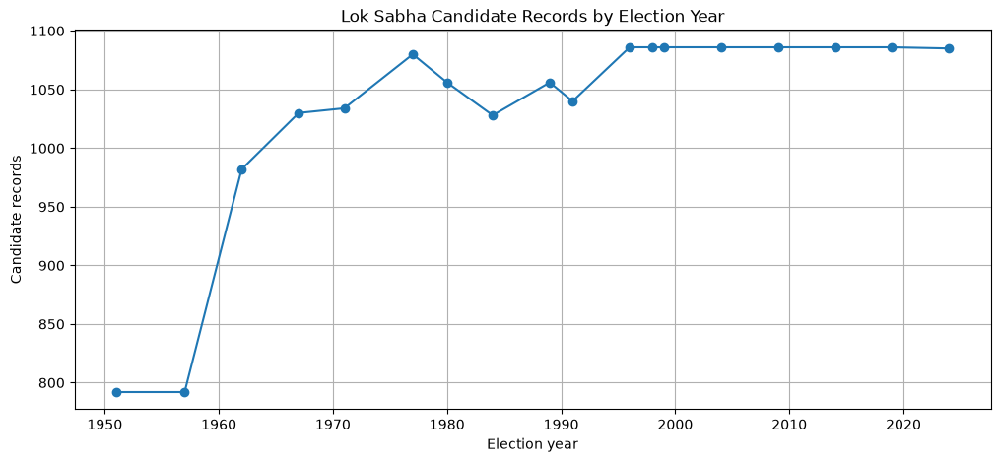

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(election_overview["YEAR"], election_overview["candidates"], marker="o")
plt.title("Lok Sabha Candidate Records by Election Year")
plt.xlabel("Election year")
plt.ylabel("Candidate records")
plt.grid(True)
plt.show()

In [7]:
keys = ["YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"]

winner_runner = df[df["RESULT POSITION"].isin(["Winner", "Runner"])]

margin_table = (
    winner_runner.pivot_table(
        index=keys,
        columns="RESULT POSITION",
        values="VOTES",
        aggfunc="first"
    )
    .reset_index()
)

if {"Winner", "Runner"}.issubset(margin_table.columns):
    margin_table["CALCULATED MARGIN"] = (
        margin_table["Winner"] - margin_table["Runner"]
    )

    display(margin_table.sort_values("CALCULATED MARGIN").head(10))

RESULT POSITION,YEAR,STATE UT,CONSTITUENCY NO,CONSTITUENCY NAME,Runner,Winner,CALCULATED MARGIN
5394,1998,BIHAR,26,Rajmahal (ST),198880.0,198889.0,9.0
3725,1989,ANDHRA PRADESH,6,ANAKAPALLI,299100.0,299109.0,9.0
4906,1996,GUJARAT,22,Baroda,131231.0,131248.0,17.0
2008,1971,Tamil Nadu,38,TIRUCHENDUR,202757.0,202783.0,26.0
7647,2014,Jammu and Kashmir,4,Ladakh,31075.0,31111.0,36.0
5615,1998,MIZORAM,1,Mizoram (ST),106511.0,106552.0,41.0
892,1962,Manipur,2,Outer Manipur,35579.0,35621.0,42.0
8830,2024,Maharashtra,27,Mumbai North West,452596.0,452644.0,48.0
472,1957,Madras,13,CUDDALORE,98546.0,98605.0,59.0
934,1962,Orrisa,17,Kendrapara,99325.0,99391.0,66.0


## 2. Election-wide overview and turnout



In [8]:
# Basic dataset overview
print("Total candidate records:", len(df))
print("Election years:", sorted(df["YEAR"].dropna().unique()))
print("Number of election years:", df["YEAR"].nunique())

display(df.head())

Total candidate records: 18577
Election years: [np.int64(1951), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1971), np.int64(1977), np.int64(1980), np.int64(1984), np.int64(1989), np.int64(1991), np.int64(1996), np.int64(1998), np.int64(1999), np.int64(2004), np.int64(2009), np.int64(2014), np.int64(2019), np.int64(2024)]
Number of election years: 18


,YEAR,STATE UT,CODE,NUMBER OF SEATS,CONSTITUENCY NO,CONSTITUENCY NAME,CANDIDATE,PARTY,TOTAL ELECTORS,TOTAL VOTED,VOTES,TURNOUT PERCENT,RESULT POSITION,MARGIN VOTES,MARGIN PERCENT
0,1951,Assam,S01,2,1,Cachar Lushal Hill,"LASKAR, NIBARAN CHANDRA",INDIAN NATIONAL CONGRESS,658171,627706,192847,47.69,Winner 1,10155,1.62
1,1951,Assam,S01,2,1,Cachar Lushal Hill,"DEB, SURESH CHANDRA",INDIAN NATIONAL CONGRESS,658171,627706,182692,47.69,Winner 2,10155,1.62
2,1951,Assam,S01,1,2,Autonomous Distri,BONILY KHONGMEN,INDIAN NATIONAL CONGRESS,360630,109663,59326,30.41,Winner,26339,24.02
3,1951,Assam,S01,1,2,Autonomous Distri,WILSON READE,KHASI-JAINTIA DURBAR,360630,109663,32987,30.41,Runner,26339,24.02
4,1951,Assam,S01,2,3,Goalpara Garo Hill,JONAB AMJAD ALI,SOCIALIST PARTY,719456,704435,182093,48.96,Winner 1,16949,2.41


In [9]:
election_overview = (
    df.groupby("YEAR")
      .agg(
          candidate_records=("CANDIDATE", "size"),
          constituencies=("CONSTITUENCY NO", "nunique"),
          parties=("PARTY", "nunique"),
          states_ut=("STATE UT", "nunique")
      )
      .reset_index()
      .sort_values("YEAR")
)

display(election_overview)

,YEAR,candidate_records,constituencies,parties,states_ut
0,1951,792,69,32,25
1,1957,792,68,14,17
2,1962,982,86,22,18
3,1967,1030,85,20,26
4,1971,1034,85,37,26
5,1977,1080,85,25,30
6,1980,1056,85,27,31
7,1984,1028,85,29,28
8,1989,1056,85,38,31
9,1991,1040,84,36,30


In [10]:
constituency_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

constituency_counts = (
    df.groupby("YEAR")[constituency_keys[1:]]
      .apply(lambda group: group.drop_duplicates().shape[0])
      .rename("unique_constituencies")
      .reset_index()
)

display(constituency_counts)

,YEAR,unique_constituencies
0,1951,396
1,1957,396
2,1962,491
3,1967,515
4,1971,517
5,1977,540
6,1980,528
7,1984,514
8,1989,528
9,1991,520


In [11]:
constituency_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

# Keep one record per constituency-election
constituency_data = (
    df.groupby(constituency_keys, dropna=False)
      .agg(
          total_electors=("TOTAL ELECTORS", "first"),
          total_voted=("TOTAL VOTED", "first")
      )
      .reset_index()
)

display(constituency_data.head())

,YEAR,STATE UT,CONSTITUENCY NO,CONSTITUENCY NAME,total_electors,total_voted
0,1951,Ajmer,1,Ajmer North,162327,97165
1,1951,Ajmer,2,Ajmer South,167157,81834
2,1951,Assam,1,Cachar Lushal Hill,658171,627706
3,1951,Assam,2,Autonomous Distri,360630,109663
4,1951,Assam,3,Goalpara Garo Hill,719456,704435


In [12]:
constituency_data["calculated_turnout"] = (
    constituency_data["total_voted"]
    / constituency_data["total_electors"]
    * 100
)

display(
    constituency_data[
        ["YEAR", "STATE UT", "CONSTITUENCY NAME",
         "total_electors", "total_voted", "calculated_turnout"]
    ].head()
)

,YEAR,STATE UT,CONSTITUENCY NAME,total_electors,total_voted,calculated_turnout
0,1951,Ajmer,Ajmer North,162327,97165,59.857571
1,1951,Ajmer,Ajmer South,167157,81834,48.956370
2,1951,Assam,Cachar Lushal Hill,658171,627706,95.371264
3,1951,Assam,Autonomous Distri,360630,109663,30.408729
4,1951,Assam,Goalpara Garo Hill,719456,704435,97.912173


In [13]:
turnout_by_year = (
    constituency_data.groupby("YEAR")
    .agg(
        total_electors=("total_electors", "sum"),
        total_voted=("total_voted", "sum")
    )
    .reset_index()
)

turnout_by_year["turnout_percent"] = (
    turnout_by_year["total_voted"]
    / turnout_by_year["total_electors"]
    * 100
)

display(turnout_by_year)

,YEAR,total_electors,total_voted,turnout_percent
0,1951,171746008,105950083,61.689983
1,1957,190918439,120513915,63.123246
2,1962,215040587,119904284,55.758908
3,1967,249003334,152724611,61.334364
4,1971,274174155,151536802,55.270272
5,1977,320928417,194263915,60.531852
6,1980,355685623,202752893,57.003398
7,1984,379284932,241246887,63.605713
8,1989,498123814,309050451,62.042898
9,1991,497394502,282071474,56.709809


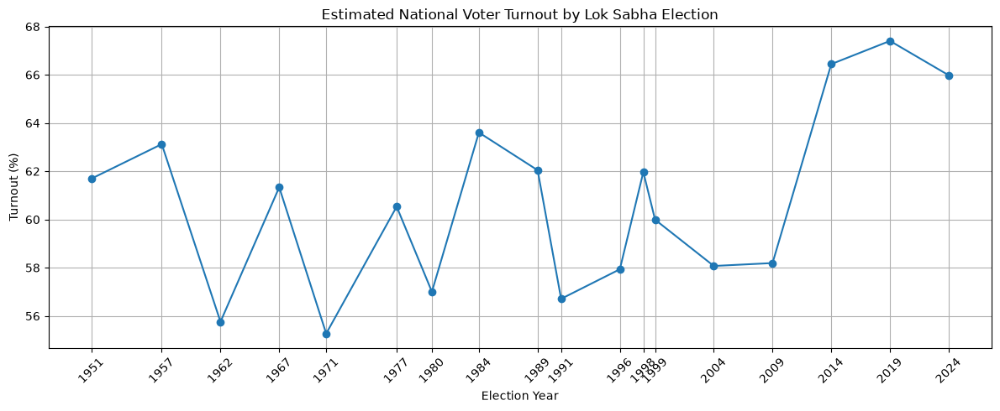

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(
    turnout_by_year["YEAR"],
    turnout_by_year["turnout_percent"],
    marker="o"
)

plt.title("Estimated National Voter Turnout by Lok Sabha Election")
plt.xlabel("Election Year")
plt.ylabel("Turnout (%)")
plt.xticks(turnout_by_year["YEAR"], rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## 3. Party performance and election leaders



In [15]:
# Select rows marked as winners
winners = df[
    df["RESULT POSITION"].astype(str).str.strip().isin(
        ["Winner", "Winner 1", "Winner 2"]
    )
].copy()

# Count winner records by party and year
party_seats = (
    winners.groupby(["YEAR", "PARTY"])
    .size()
    .reset_index(name="seats_won")
    .sort_values(["YEAR", "seats_won"], ascending=[True, False])
)

display(party_seats.head(20))

,YEAR,PARTY,seats_won
10,1951,INDIAN NATIONAL CONGRESS,359
9,1951,INDEPENDENT,37
7,1951,COMMUNIST PARTY OF INDIA,16
20,1951,SOCIALIST PARTY,12
12,1951,KISAN MAZDOOR PRAJA PARTY,9
17,1951,PEOPLES DEMOCRATIC FRONT,7
3,1951,ALL INDIA GANTANTRA PARISHAD,5
0,1951,AKHIL BHARATIYA HINDU MAHASABHA,4
19,1951,SHIROMANI AKALI DAL,4
21,1951,THE TAMIL NAD TOILERS PARTY,4


In [16]:
top_party_each_year = (
    party_seats.sort_values(
        ["YEAR", "seats_won"],
        ascending=[True, False]
    )
    .groupby("YEAR")
    .head(1)
    .reset_index(drop=True)
)

display(top_party_each_year)

,YEAR,PARTY,seats_won
0,1951,INDIAN NATIONAL CONGRESS,359
1,1957,INDIAN NATIONAL CONGRESS,364
2,1962,INDIAN NATIONAL CONGRESS,358
3,1967,INDIAN NATIONAL CONGRESS,279
4,1971,INDIAN NATIONAL CONGRESS,351
5,1977,BHARATIYA LOK DAL,295
6,1980,INDIAN NATIOANL CONGRESS (I),353
7,1984,INDIAN NATIONAL CONGRESS,404
8,1989,INDIAN NATIONAL CONGRESS,197
9,1991,INDIAN NATIONAL CONGRESS,232


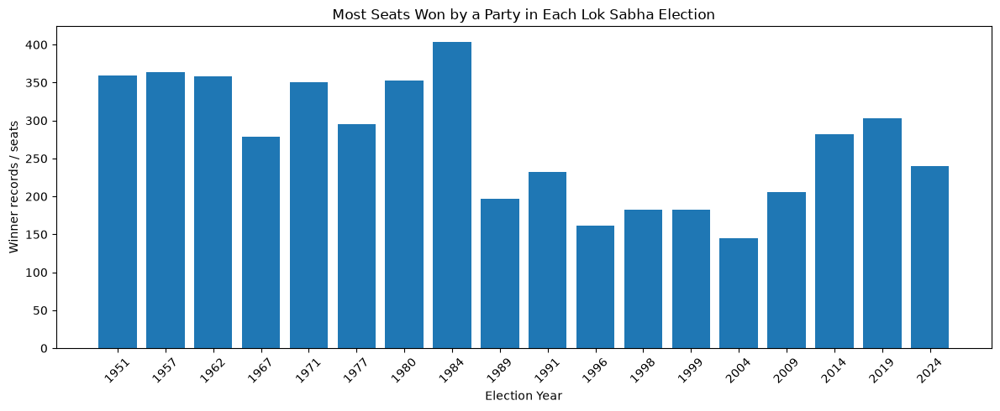

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.bar(
    top_party_each_year["YEAR"].astype(str),
    top_party_each_year["seats_won"]
)

plt.title("Most Seats Won by a Party in Each Lok Sabha Election")
plt.xlabel("Election Year")
plt.ylabel("Winner records / seats")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
display(
    df.loc[df["RESULT POSITION"].isin(["Winner", "Winner 1", "Winner 2"]),
           "PARTY"]
      .value_counts()
      .head(30)
)

PARTY
INDIAN NATIONAL CONGRESS                    3637
BHARATIYA JANTA PARTY                       1811
CUMMUNIST PARTY OF INDIA (MARXIST)           358
INDIAN NATIOANL CONGRESS (I)                 353
BHARATIYA LOK DAL                            295
JANATA DAL                                   253
INDEPENDENT                                  233
COMMUNIST PARTY OF INDIA                     211
DRAVIDA MUNETRA KAZHAGAM                     190
SOCIALIST PARTY                              181
TELUGU DESAM                                 148
ALL INDIA ANNA DRAVIDA MUNNETRA KAZHAGAM     129
All India Trinamool Congress                 114
SHIVA SENA                                   107
BAHUJAN SAMAJ PARTY                           85
Janata Dal (United)                           79
BIJU JANATA DAL                               76
SWATANTRA                                     70
ALL INDIA BHARTIYA JAN SANGH                  64
RASHTRIYA JANATA DAL                          60
SHIROMANI AKAL

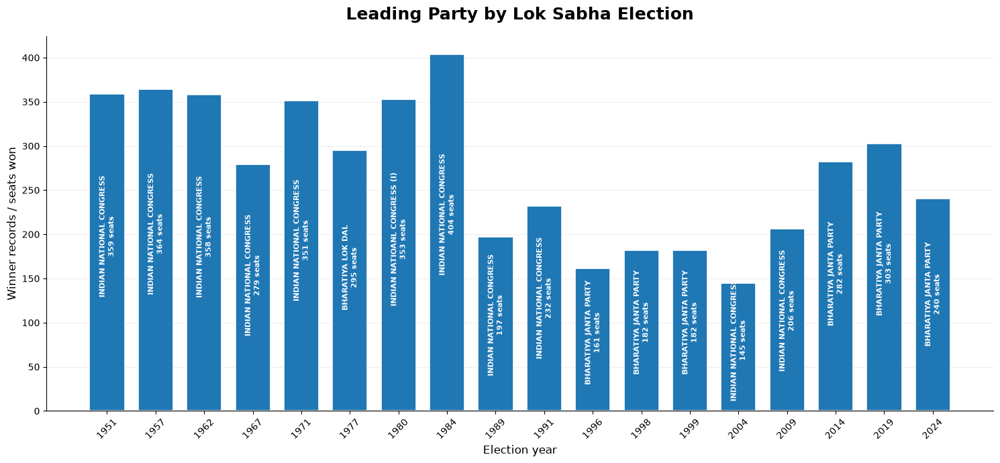

In [19]:
# Sort chronologically
plot_data = top_party_each_year.sort_values("YEAR").copy()

fig, ax = plt.subplots(figsize=(15, 7))

bars = ax.bar(
    plot_data["YEAR"].astype(str),
    plot_data["seats_won"],
    width=0.72,
    edgecolor="white",
    linewidth=1.2
)

# Add party name and seat count to each bar
for bar, (_, row) in zip(bars, plot_data.iterrows()):
    height = bar.get_height()
    party = str(row["PARTY"])
    seats = int(row["seats_won"])

    label = f"{party}\n{seats} seats"

    # Put labels inside taller bars; above shorter bars
    if height >= plot_data["seats_won"].max() * 0.25:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height * 0.55,
            label,
            ha="center",
            va="center",
            fontsize=8,
            fontweight="bold",
            color="white",
            rotation=90
        )
    else:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 8,
            label,
            ha="center",
            va="bottom",
            fontsize=8,
            fontweight="bold",
            rotation=45
        )

ax.set_title(
    "Leading Party by Lok Sabha Election",
    fontsize=18,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Election year", fontsize=12)
ax.set_ylabel("Winner records / seats won", fontsize=12)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

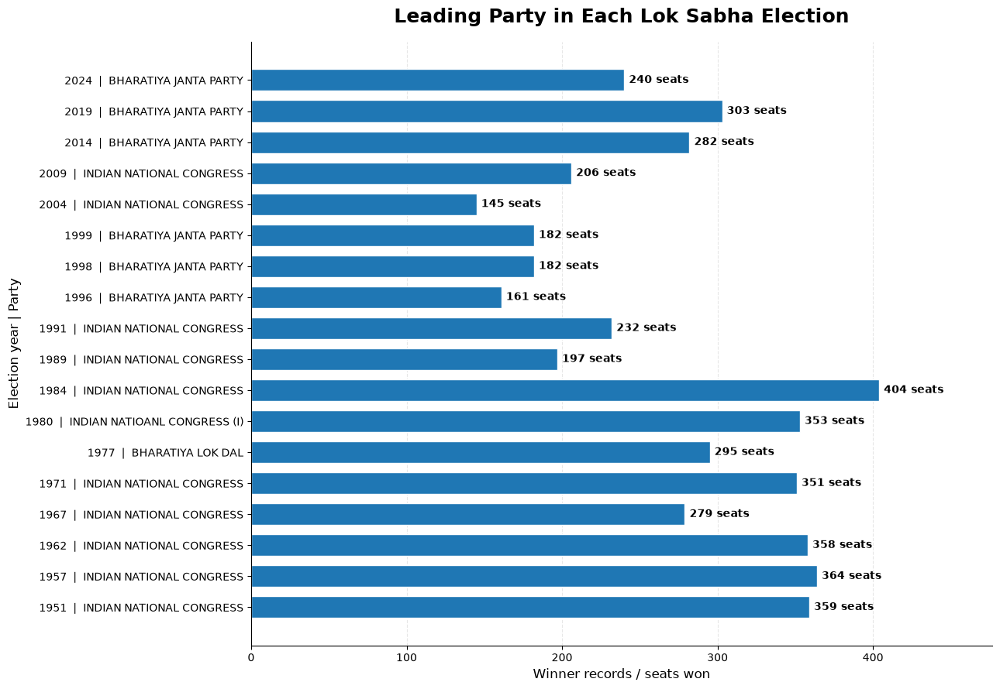

In [20]:
# Sort by election year
plot_data = top_party_each_year.sort_values("YEAR").copy()

# Create labels with year and party
labels = [
    f"{int(row.YEAR)}  |  {row.PARTY}"
    for _, row in plot_data.iterrows()
]

fig, ax = plt.subplots(figsize=(13, 9))

bars = ax.barh(
    labels,
    plot_data["seats_won"],
    height=0.7,
    edgecolor="white",
    linewidth=1
)

# Put seat count at the end of each bar
for bar, seats in zip(bars, plot_data["seats_won"]):
    ax.text(
        bar.get_width() + 3,
        bar.get_y() + bar.get_height() / 2,
        f"{int(seats)} seats",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Leading Party in Each Lok Sabha Election",
    fontsize=18,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Winner records / seats won", fontsize=12)
ax.set_ylabel("Election year | Party", fontsize=12)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Leave space for seat labels
ax.set_xlim(0, plot_data["seats_won"].max() * 1.18)

plt.tight_layout()
plt.show()

## 4. Constituency contests and winning margins



In [21]:
keys = ["YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"]

# Keep ordinary winner and runner-up rows for this comparison
wr = df[df["RESULT POSITION"].isin(["Winner", "Runner"])].copy()

# Get winner and runner-up vote totals for each constituency-election
margin_data = (
    wr.pivot_table(
        index=keys,
        columns="RESULT POSITION",
        values="VOTES",
        aggfunc="first"
    )
    .reset_index()
)

# Calculate margin only where both records exist
if {"Winner", "Runner"}.issubset(margin_data.columns):
    margin_data["margin_votes"] = margin_data["Winner"] - margin_data["Runner"]

    margin_data = margin_data.dropna(subset=["Winner", "Runner"])
    margin_data = margin_data.sort_values("margin_votes")

    display(
        margin_data[
            keys + ["Winner", "Runner", "margin_votes"]
        ].head(15)
    )
else:
    print("Could not find both 'Winner' and 'Runner' labels.")
    print("Available labels:", df["RESULT POSITION"].unique())

RESULT POSITION,YEAR,STATE UT,CONSTITUENCY NO,CONSTITUENCY NAME,Winner,Runner,margin_votes
5394,1998,BIHAR,26,Rajmahal (ST),198889.0,198880.0,9.0
3725,1989,ANDHRA PRADESH,6,ANAKAPALLI,299109.0,299100.0,9.0
4906,1996,GUJARAT,22,Baroda,131248.0,131231.0,17.0
2008,1971,Tamil Nadu,38,TIRUCHENDUR,202783.0,202757.0,26.0
7647,2014,Jammu and Kashmir,4,Ladakh,31111.0,31075.0,36.0
5615,1998,MIZORAM,1,Mizoram (ST),106552.0,106511.0,41.0
892,1962,Manipur,2,Outer Manipur,35621.0,35579.0,42.0
8830,2024,Maharashtra,27,Mumbai North West,452644.0,452596.0,48.0
472,1957,Madras,13,CUDDALORE,98605.0,98546.0,59.0
934,1962,Orrisa,17,Kendrapara,99391.0,99325.0,66.0


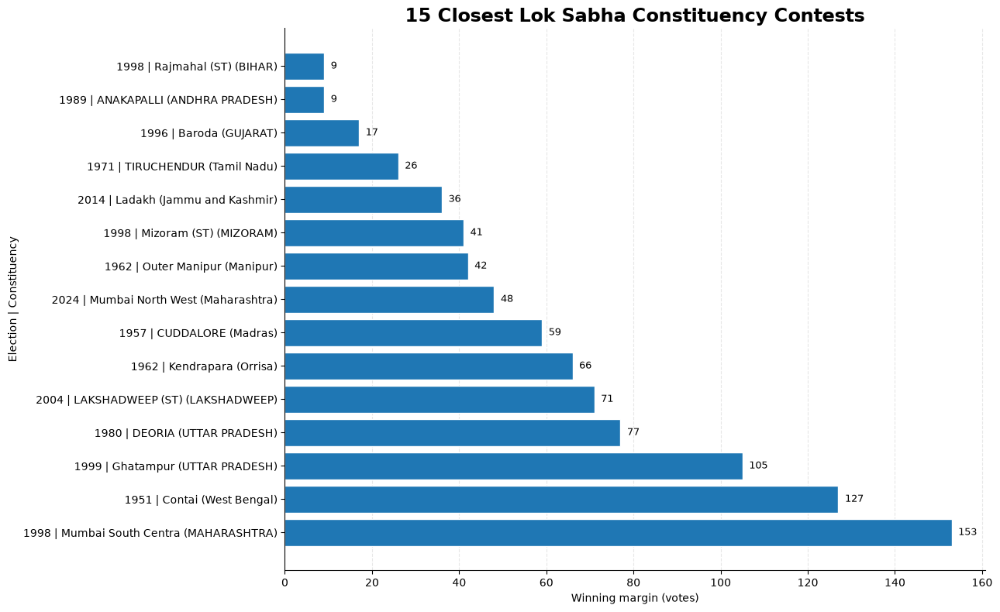

In [22]:
import matplotlib.pyplot as plt

closest = margin_data.head(15).copy()

# Make compact labels: year + constituency + state/UT
closest["label"] = (
    closest["YEAR"].astype(int).astype(str)
    + " | "
    + closest["CONSTITUENCY NAME"].astype(str)
    + " ("
    + closest["STATE UT"].astype(str)
    + ")"
)

fig, ax = plt.subplots(figsize=(13, 8))

bars = ax.barh(
    closest["label"],
    closest["margin_votes"],
    edgecolor="white"
)

# Smallest margin at the top
ax.invert_yaxis()

for bar, margin in zip(bars, closest["margin_votes"]):
    ax.text(
        bar.get_width() + max(1, closest["margin_votes"].max() * 0.01),
        bar.get_y() + bar.get_height() / 2,
        f"{int(margin):,}",
        va="center",
        fontsize=9
    )

ax.set_title("15 Closest Lok Sabha Constituency Contests", fontsize=17, weight="bold")
ax.set_xlabel("Winning margin (votes)")
ax.set_ylabel("Election | Constituency")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [23]:
# See which election years are available
sorted(df["YEAR"].dropna().unique())

[np.int64(1951),
 np.int64(1957),
 np.int64(1962),
 np.int64(1967),
 np.int64(1971),
 np.int64(1977),
 np.int64(1980),
 np.int64(1984),
 np.int64(1989),
 np.int64(1991),
 np.int64(1996),
 np.int64(1998),
 np.int64(1999),
 np.int64(2004),
 np.int64(2009),
 np.int64(2014),
 np.int64(2019),
 np.int64(2024)]

In [24]:
year_to_analyze = 2019

election_df = df[df["YEAR"] == year_to_analyze].copy()

In [25]:
party_votes = (
    election_df.groupby("PARTY", dropna=False)
    .agg(party_votes=("VOTES", "sum"))
    .reset_index()
)

total_votes = party_votes["party_votes"].sum()

party_votes["vote_share_pct"] = (
    party_votes["party_votes"] / total_votes * 100
)

In [26]:
winner_rows = election_df[
    election_df["RESULT POSITION"].isin(["Winner", "Winner 1", "Winner 2"])
]

party_seats = (
    winner_rows.groupby("PARTY", dropna=False)
    .size()
    .reset_index(name="seats_won")
)

total_winner_records = party_seats["seats_won"].sum()

party_seats["seat_share_pct"] = (
    party_seats["seats_won"] / total_winner_records * 100
)

In [27]:
party_comparison = party_votes.merge(
    party_seats,
    on="PARTY",
    how="left"
)

party_comparison["seats_won"] = (
    party_comparison["seats_won"].fillna(0).astype(int)
)

party_comparison["seat_share_pct"] = (
    party_comparison["seat_share_pct"].fillna(0)
)

party_comparison["seat_vote_gap_pp"] = (
    party_comparison["seat_share_pct"]
    - party_comparison["vote_share_pct"]
)

party_comparison = party_comparison.sort_values(
    "seats_won", ascending=False
)

display(party_comparison.head(15))

,PARTY,party_votes,vote_share_pct,seats_won,seat_share_pct,seat_vote_gap_pp
10,BHARATIYA JANTA PARTY,224018297,41.449275,303,55.801105,14.351830
21,INDIAN NATIONAL CONGRESS,108240443,20.027328,52,9.576427,-10.450901
17,DRAVIDA MUNETRA KAZHAGAM,14363332,2.657594,24,4.419890,1.762295
5,All India Trinamool Congress,24405992,4.515750,22,4.051565,-0.464185
59,Yuvajana Sramika Rythu Congress Party,15537006,2.874755,22,4.051565,1.176811
47,SHIVA SENA,12589064,2.329308,18,3.314917,0.985609
27,Janata Dal (United),8902719,1.647237,16,2.946593,1.299356
11,BIJU JANATA DAL,10174021,1.882461,12,2.209945,0.327483
9,BAHUJAN SAMAJ PARTY,16491711,3.051400,10,1.841621,-1.209780
54,Telangana Rashtra Samithi,7633609,1.412418,9,1.657459,0.245040


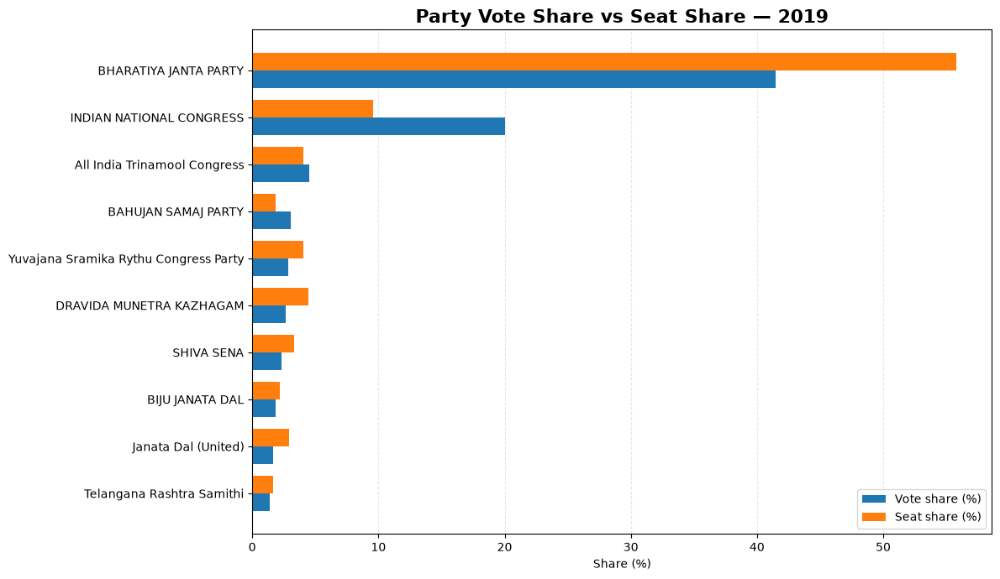

In [28]:
import matplotlib.pyplot as plt

top_parties = party_comparison.head(10).sort_values("vote_share_pct")

fig, ax = plt.subplots(figsize=(12, 7))

y = range(len(top_parties))
bar_height = 0.38

ax.barh(
    [i - bar_height / 2 for i in y],
    top_parties["vote_share_pct"],
    height=bar_height,
    label="Vote share (%)"
)

ax.barh(
    [i + bar_height / 2 for i in y],
    top_parties["seat_share_pct"],
    height=bar_height,
    label="Seat share (%)"
)

ax.set_yticks(list(y))
ax.set_yticklabels(top_parties["PARTY"])
ax.set_xlabel("Share (%)")
ax.set_title(f"Party Vote Share vs Seat Share — {year_to_analyze}", fontsize=16, weight="bold")
ax.legend()
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 5. Constituency-level visual analyses



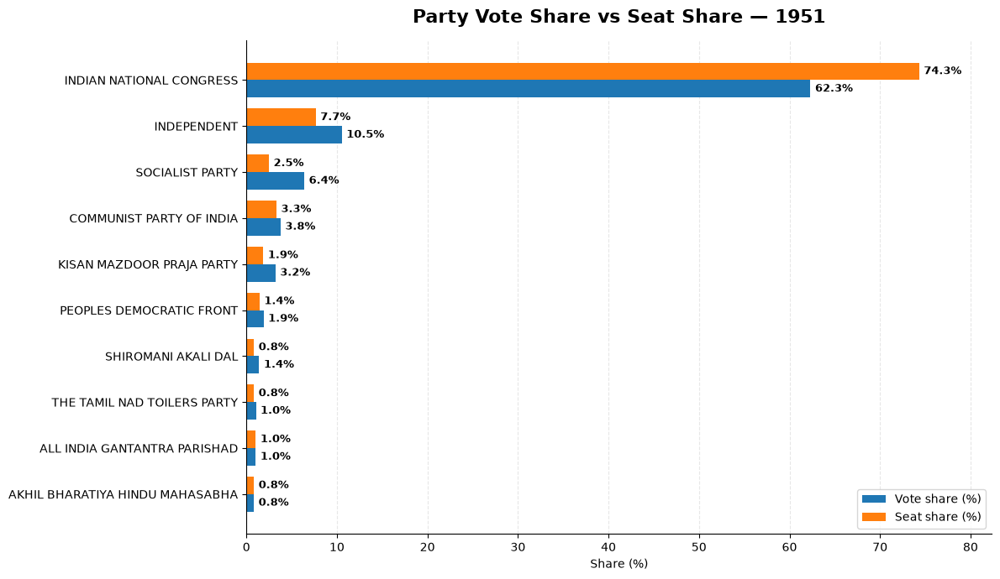

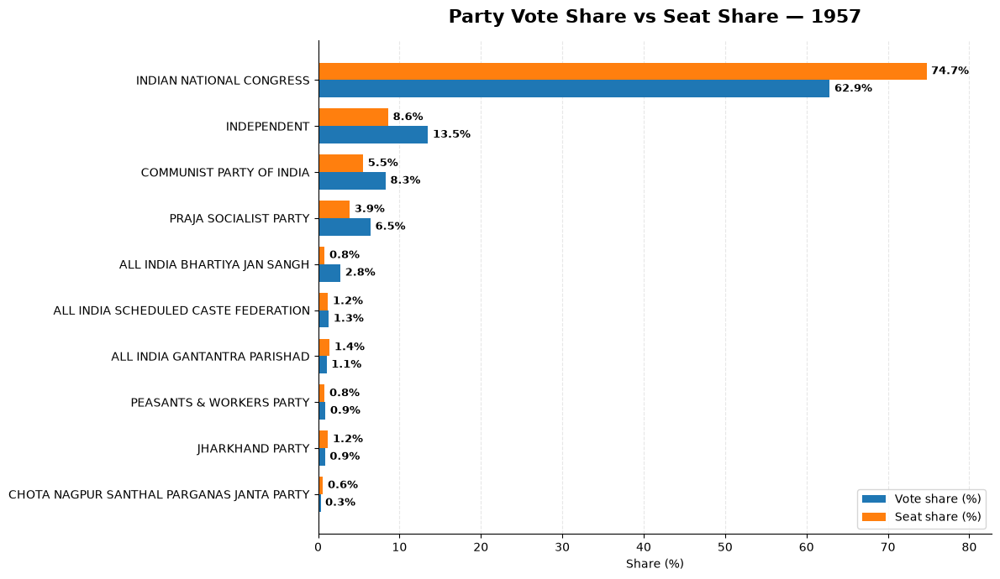

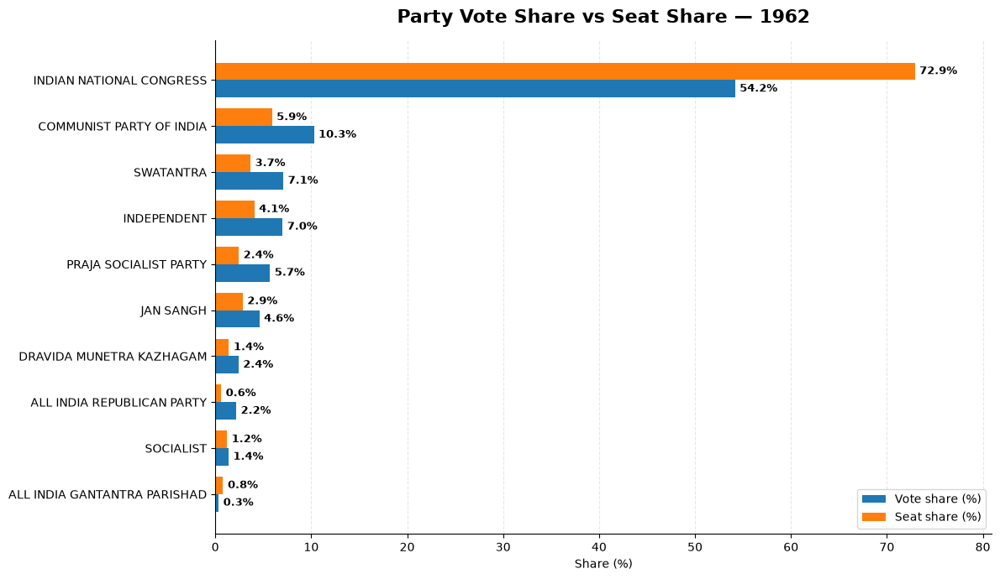

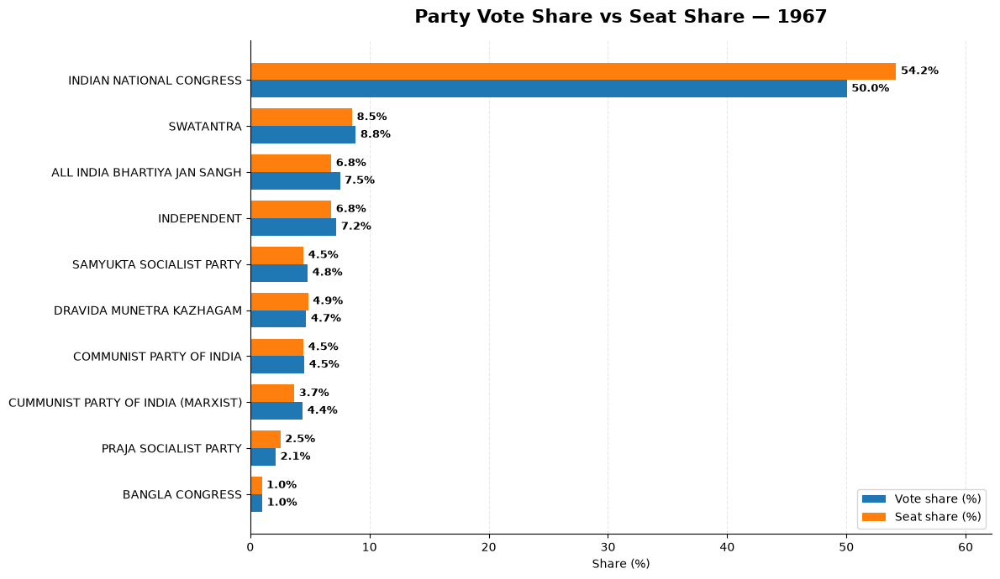

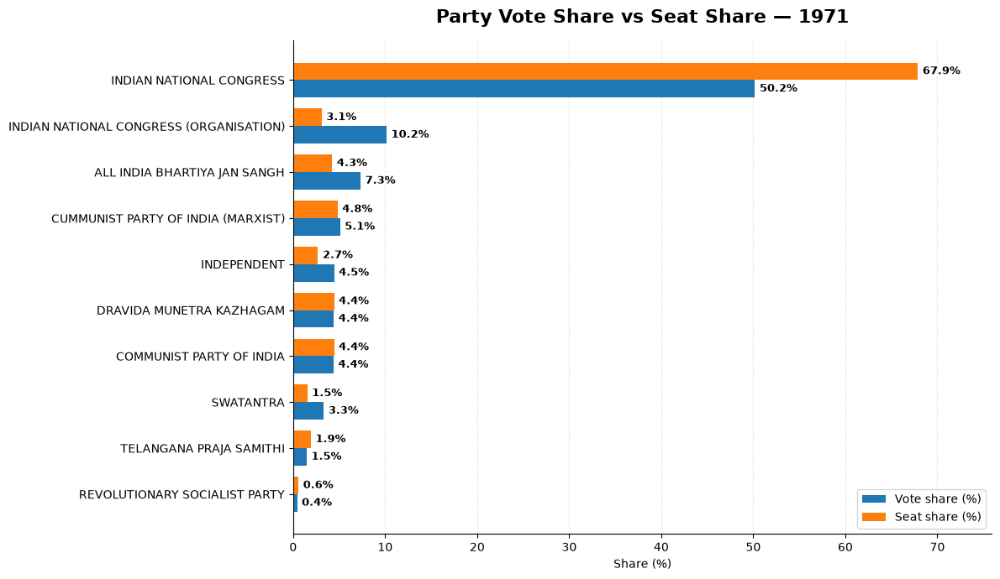

...

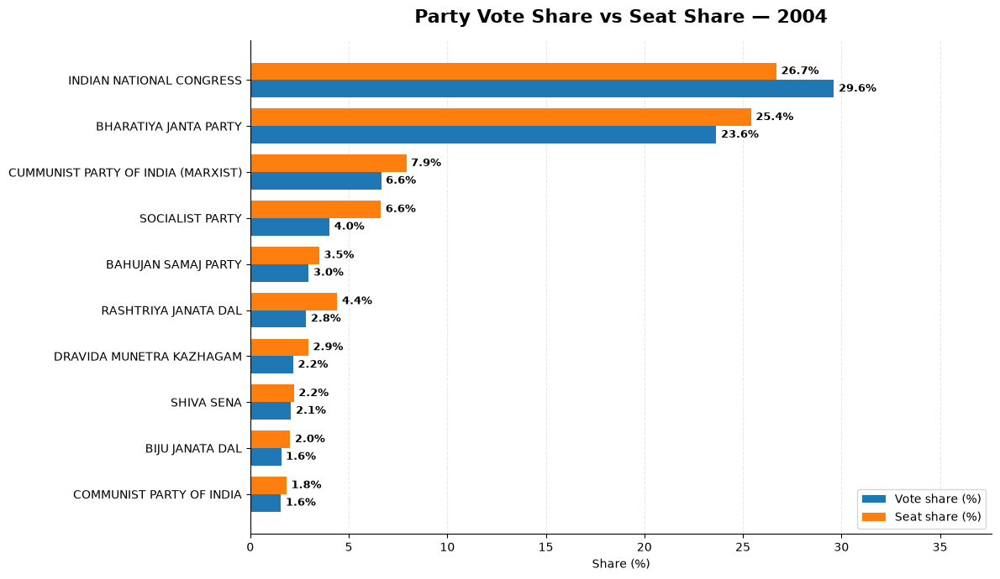

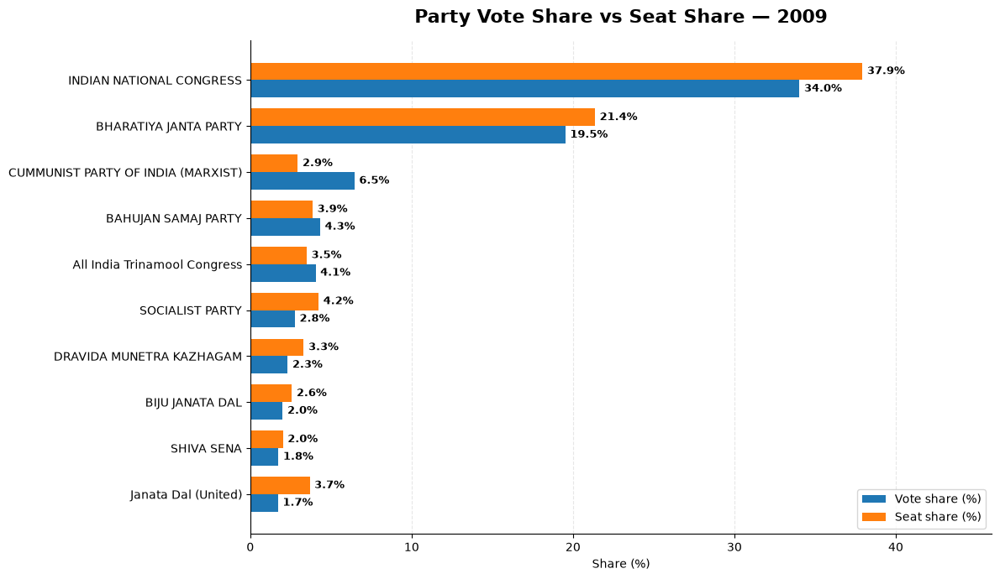

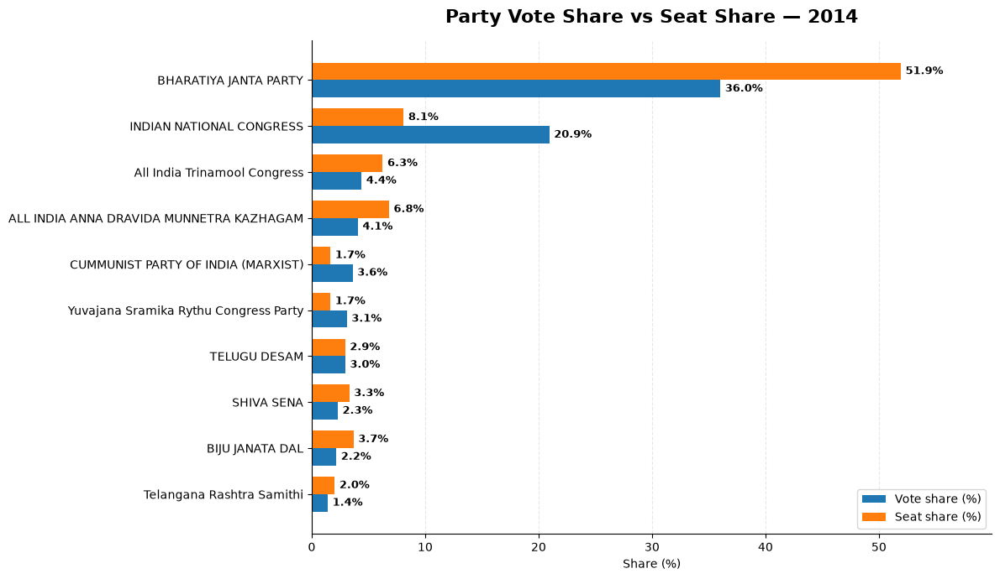

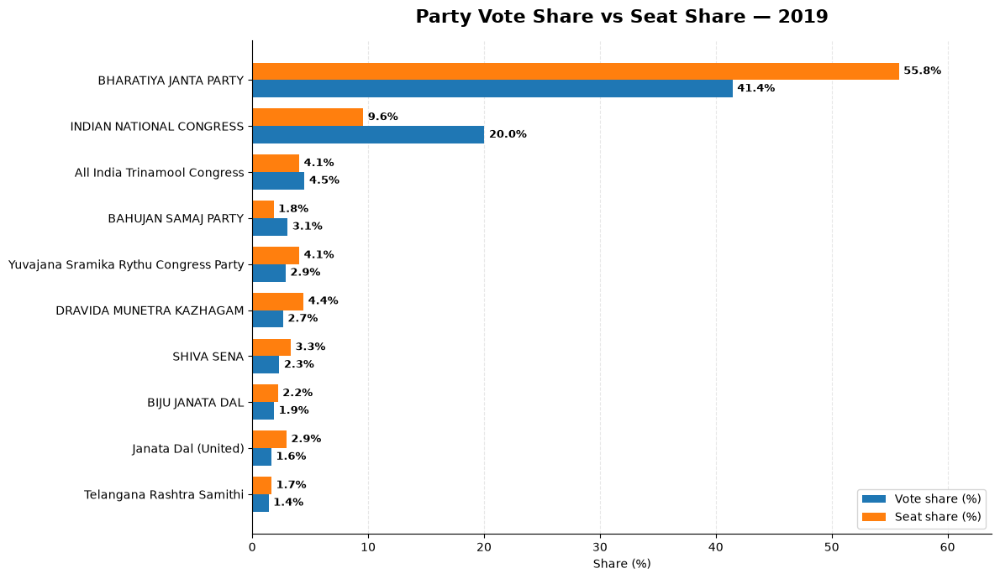

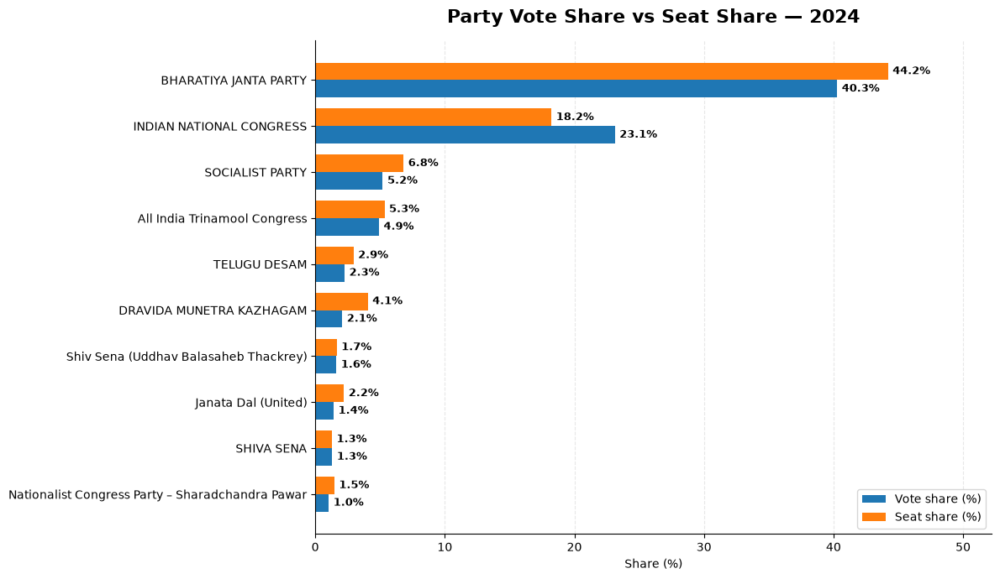

Charts saved in: C:\analysis\party_vote_vs_seat_charts


In [29]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Folder to save the charts
output_folder = Path("party_vote_vs_seat_charts")
output_folder.mkdir(parents=True, exist_ok=True)

# Winner labels used in your cleaned dataset
winner_labels = ["Winner", "Winner 1", "Winner 2"]

# Election years in the dataset
years = sorted(df["YEAR"].dropna().unique())

for year in years:
    election_df = df[df["YEAR"] == year].copy()

    # 1. Calculate each party's candidate-vote total and vote share
    votes_by_party = (
        election_df.groupby("PARTY", dropna=False)["VOTES"]
        .sum()
        .rename("party_votes")
        .reset_index()
    )

    total_votes = votes_by_party["party_votes"].sum()

    if total_votes <= 0:
        print(f"Skipping {year}: total candidate votes are zero or invalid.")
        continue

    votes_by_party["vote_share_pct"] = (
        votes_by_party["party_votes"] / total_votes * 100
    )

    # 2. Count winner records by party
    winner_rows = election_df[
        election_df["RESULT POSITION"].isin(winner_labels)
    ]

    seats_by_party = (
        winner_rows.groupby("PARTY", dropna=False)
        .size()
        .rename("seats_won")
        .reset_index()
    )

    total_winner_records = seats_by_party["seats_won"].sum()

    if total_winner_records == 0:
        print(f"Skipping {year}: no winner records found.")
        continue

    seats_by_party["seat_share_pct"] = (
        seats_by_party["seats_won"] / total_winner_records * 100
    )

    # 3. Combine vote share and seat share
    comparison = votes_by_party.merge(
        seats_by_party,
        on="PARTY",
        how="left"
    )

    comparison["seats_won"] = comparison["seats_won"].fillna(0)
    comparison["seat_share_pct"] = comparison["seat_share_pct"].fillna(0)

    # Top 10 parties by winner-record count
    top_parties = (
        comparison.sort_values("seats_won", ascending=False)
        .head(10)
        .sort_values("vote_share_pct")
        .copy()
    )

    # 4. Create horizontal grouped bars
    fig, ax = plt.subplots(figsize=(12, 7))

    y_positions = list(range(len(top_parties)))
    bar_height = 0.38

    vote_bars = ax.barh(
        [y - bar_height / 2 for y in y_positions],
        top_parties["vote_share_pct"],
        height=bar_height,
        label="Vote share (%)"
    )

    seat_bars = ax.barh(
        [y + bar_height / 2 for y in y_positions],
        top_parties["seat_share_pct"],
        height=bar_height,
        label="Seat share (%)"
    )

    # 5. Add percentage labels to both sets of bars
    for bars in [vote_bars, seat_bars]:
        for bar in bars:
            value = bar.get_width()

            ax.annotate(
                f"{value:.1f}%",
                xy=(value, bar.get_y() + bar.get_height() / 2),
                xytext=(4, 0),
                textcoords="offset points",
                ha="left",
                va="center",
                fontsize=9,
                fontweight="bold"
            )

    # Party names on the y-axis
    ax.set_yticks(y_positions)
    ax.set_yticklabels(top_parties["PARTY"])

    ax.set_xlabel("Share (%)")
    ax.set_title(
        f"Party Vote Share vs Seat Share — {int(year)}",
        fontsize=16,
        fontweight="bold",
        pad=15
    )

    # Space to the right for percentage labels
    largest_share = max(
        top_parties["vote_share_pct"].max(),
        top_parties["seat_share_pct"].max()
    )
    ax.set_xlim(0, largest_share + 8)

    ax.legend()
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    # Clean up chart appearance
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()

    # 6. Save exactly once, before showing and closing
    chart_path = output_folder / f"vote_vs_seat_share_{int(year)}.png"
    fig.savefig(chart_path, dpi=150, bbox_inches="tight")

    plt.show()
    plt.close(fig)

print(f"Charts saved in: {output_folder.resolve()}")

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

# Keep only Winner and Runner records
wr = df[df["RESULT POSITION"].isin(["Winner", "Runner"])].copy()

# One row per constituency-election, with winner and runner-up votes
contest_votes = (
    wr.pivot_table(
        index=["YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"],
        columns="RESULT POSITION",
        values="VOTES",
        aggfunc="first"
    )
    .reset_index()
)

# Keep contests where both vote totals are present
contest_votes = contest_votes.dropna(subset=["Winner", "Runner"])

# Winning margin in votes
contest_votes["WINNING MARGIN"] = contest_votes["Winner"] - contest_votes["Runner"]

display(contest_votes.head())

RESULT POSITION,YEAR,STATE UT,CONSTITUENCY NO,CONSTITUENCY NAME,Runner,Winner,WINNING MARGIN
0,1951,Ajmer,1,Ajmer North,28990.0,46679.0,17689.0
1,1951,Ajmer,2,Ajmer South,25128.0,43082.0,17954.0
2,1951,Assam,2,Autonomous Distri,32987.0,59326.0,26339.0
3,1951,Assam,4,Barpeta,63950.0,76293.0,12343.0
4,1951,Assam,5,Gauhati,72553.0,96122.0,23569.0


In [31]:
margin_by_year = (
    contest_votes.groupby("YEAR")
    .agg(
        constituencies=("WINNING MARGIN", "count"),
        average_margin=("WINNING MARGIN", "mean"),
        median_margin=("WINNING MARGIN", "median"),
        smallest_margin=("WINNING MARGIN", "min")
    )
    .reset_index()
    .sort_values("YEAR")
)

display(margin_by_year)

,YEAR,constituencies,average_margin,median_margin,smallest_margin
0,1951,309,36083.417476,30859.0,127.0
1,1957,305,35012.406557,28601.0,59.0
2,1962,491,34233.236253,27444.0,42.0
3,1967,515,40505.223301,32797.0,203.0
4,1971,517,68559.781431,61094.0,26.0
5,1977,540,95110.420370,81938.0,165.0
6,1980,528,68585.856061,60135.0,77.0
7,1984,514,88017.521401,79706.0,461.0
8,1989,528,88459.420455,71087.0,9.0
9,1991,520,75205.809615,53568.5,156.0


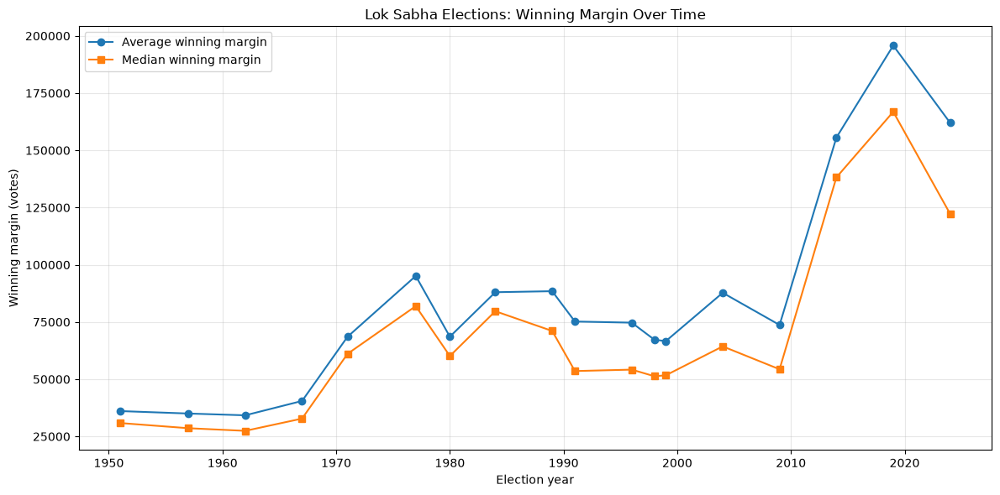

In [32]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    margin_by_year["YEAR"],
    margin_by_year["average_margin"],
    marker="o",
    label="Average winning margin"
)

ax.plot(
    margin_by_year["YEAR"],
    margin_by_year["median_margin"],
    marker="s",
    label="Median winning margin"
)

ax.set_title("Lok Sabha Elections: Winning Margin Over Time")
ax.set_xlabel("Election year")
ax.set_ylabel("Winning margin (votes)")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [33]:
constituency_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

constituency_data = (
    df.groupby(constituency_keys, dropna=False)
    .agg(
        total_electors=("TOTAL ELECTORS", "first"),
        total_voted=("TOTAL VOTED", "first")
    )
    .reset_index()
)

constituency_data["TURNOUT %"] = (
    constituency_data["total_voted"]
    / constituency_data["total_electors"]
    * 100
)

display(constituency_data.head())

,YEAR,STATE UT,CONSTITUENCY NO,CONSTITUENCY NAME,total_electors,total_voted,TURNOUT %
0,1951,Ajmer,1,Ajmer North,162327,97165,59.857571
1,1951,Ajmer,2,Ajmer South,167157,81834,48.956370
2,1951,Assam,1,Cachar Lushal Hill,658171,627706,95.371264
3,1951,Assam,2,Autonomous Distri,360630,109663,30.408729
4,1951,Assam,3,Goalpara Garo Hill,719456,704435,97.912173


In [34]:
state_turnout = (
    constituency_data.groupby(["YEAR", "STATE UT"], dropna=False)
    .agg(
        electors=("total_electors", "sum"),
        votes_cast=("total_voted", "sum")
    )
    .reset_index()
)

state_turnout["TURNOUT %"] = (
    state_turnout["votes_cast"]
    / state_turnout["electors"]
    * 100
)

display(state_turnout.head(20))

,YEAR,STATE UT,electors,votes_cast,TURNOUT %
0,1951,Ajmer,329484,178999,54.327069
1,1951,Assam,4141720,2647127,63.913712
2,1951,Bhopal,419970,169457,40.349787
3,1951,Bihar,18080181,9992451,55.267428
4,1951,Bombay,16789609,11528290,68.663243
5,1951,Coorg,94593,63813,67.460594
6,1951,Delhi,744668,655900,88.079520
7,1951,Himachal Pradesh,531018,223189,42.030402
8,1951,Hyderabad,8669397,4854862,55.999996
9,1951,Kutch,288400,119580,41.463245


In [35]:
latest_year = state_turnout["YEAR"].max()

latest_state_turnout = (
    state_turnout[state_turnout["YEAR"] == latest_year]
    .sort_values("TURNOUT %", ascending=False)
)

display(latest_state_turnout)

,YEAR,STATE UT,electors,votes_cast,TURNOUT %
516,2024,Lakshadweep,57953,49247,84.977482
528,2024,Sikkim,466643,388507,83.255722
502,2024,Assam,24572114,20118166,81.873973
531,2024,Tripura,2870896,2348827,81.815120
500,2024,Andhra Pradesh,41401887,33858957,81.781193
501,2024,Arunachal Pradesh,898442,728393,81.072902
534,2024,West Bengal,76124780,60554535,79.546417
525,2024,Puducherry,1024024,811432,79.239549
519,2024,Manipur,2051357,1605769,78.278379
507,2024,Goa,1179644,908178,76.987464


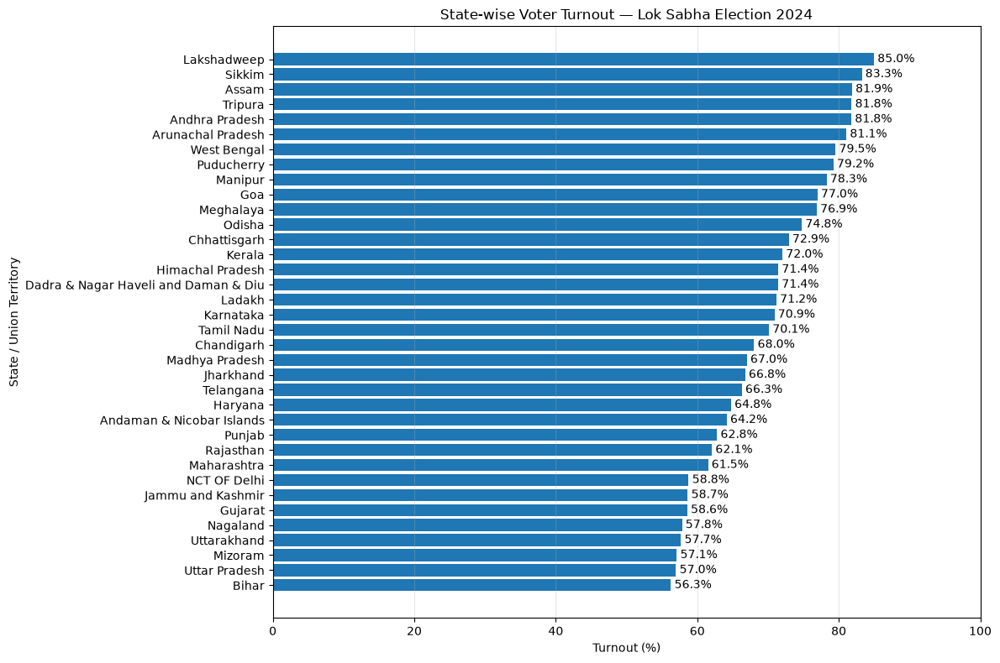

In [36]:
plot_data = latest_state_turnout.sort_values("TURNOUT %")

fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(plot_data["STATE UT"], plot_data["TURNOUT %"])

ax.set_title(f"State-wise Voter Turnout — Lok Sabha Election {latest_year}")
ax.set_xlabel("Turnout (%)")
ax.set_ylabel("State / Union Territory")
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.3)

for bar in ax.patches:
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Load your Excel workbook
file_path = "LOKSABHA 1951-2024.xlsx"  # Change path if needed

df = df.copy()

# 2. One row per constituency-election
# Candidate rows repeat constituency totals, so take one value per constituency.
constituency_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

constituency_data = (
    df.groupby(constituency_keys, dropna=False)
    .agg(
        total_electors=("TOTAL ELECTORS", "first"),
        total_voted=("TOTAL VOTED", "first")
    )
    .reset_index()
)

# 3. Calculate state-wise weighted turnout for each election
state_turnout = (
    constituency_data.groupby(["YEAR", "STATE UT"], dropna=False)
    .agg(
        electors=("total_electors", "sum"),
        votes_cast=("total_voted", "sum")
    )
    .reset_index()
)

state_turnout["TURNOUT %"] = (
    state_turnout["votes_cast"] / state_turnout["electors"] * 100
)

state_turnout.loc[
    state_turnout["electors"] <= 0,
    "TURNOUT %"
] = pd.NA

# 4. Create ONE folder for chart images
chart_folder = Path("outputs/state_turnout_charts")
chart_folder.mkdir(parents=True, exist_ok=True)

# 5. Create and save one chart per election year
years = sorted(state_turnout["YEAR"].dropna().unique())

for year in years:
    year_data = (
        state_turnout[state_turnout["YEAR"] == year]
        .dropna(subset=["STATE UT", "TURNOUT %"])
        .sort_values("TURNOUT %")
    )

    if year_data.empty:
        continue

    fig, ax = plt.subplots(
        figsize=(12, max(6, len(year_data) * 0.35))
    )

    bars = ax.barh(
        year_data["STATE UT"].astype(str),
        year_data["TURNOUT %"]
    )

    ax.set_title(
        f"State-wise Voter Turnout — Lok Sabha Election {int(year)}"
    )
    ax.set_xlabel("Turnout (%)")
    ax.set_ylabel("State / Union Territory")
    ax.set_xlim(0, 105)
    ax.grid(axis="x", alpha=0.3)

    # Percentage labels on bars
    for bar, turnout in zip(bars, year_data["TURNOUT %"]):
        ax.text(
            turnout + 0.5,
            bar.get_y() + bar.get_height() / 2,
            f"{turnout:.1f}%",
            va="center",
            fontsize=8
        )

    plt.tight_layout()

    # Save chart image only
    image_path = chart_folder / f"state_turnout_{int(year)}.png"
    fig.savefig(image_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

print(f"Saved {len(years)} chart images in: {chart_folder.resolve()}")

Saved 18 chart images in: C:\analysis\outputs\state_turnout_charts


In [38]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Count total candidate votes and winning seats by party, for each year
party_year = (
    df.groupby(["YEAR", "PARTY"], dropna=False)
    .agg(
        party_votes=("VOTES", "sum"),
        seats_won=("RESULT POSITION", lambda x: (x == "Winner").sum())
    )
    .reset_index()
)

# Total candidate votes and total seats recorded in each election
year_totals = (
    df.groupby("YEAR")
    .agg(
        total_candidate_votes=("VOTES", "sum"),
        total_winner_records=("RESULT POSITION", lambda x: (x == "Winner").sum())
    )
    .reset_index()
)

party_year = party_year.merge(year_totals, on="YEAR", how="left")

party_year["VOTE SHARE %"] = (
    party_year["party_votes"] / party_year["total_candidate_votes"] * 100
)

party_year["SEAT SHARE %"] = (
    party_year["seats_won"] / party_year["total_winner_records"] * 100
)

display(party_year.head(20))

,YEAR,PARTY,party_votes,seats_won,total_candidate_votes,total_winner_records,VOTE SHARE %,SEAT SHARE %
0,1951,AKHIL BHARATIYA HINDU MAHASABHA,556858,4,67617238,309,0.823544,1.294498
1,1951,AKHIL BHARATIYA RAM RAJYA PARISHAD,328124,3,67617238,309,0.485267,0.970874
2,1951,ALL INDIA BHARTIYA JAN SANGH,960006,2,67617238,309,1.419765,0.647249
3,1951,ALL INDIA GANTANTRA PARISHAD,698785,2,67617238,309,1.033442,0.647249
4,1951,ALL INDIA SCHEDULED CASTE FEDERATION,401844,0,67617238,309,0.594292,0.000000
5,1951,ALL MANIPUR NATIONAL UNION,18271,0,67617238,309,0.027021,0.000000
6,1951,CHOTA NAGPUR SANTHAL PARGANAS JANTA PARTY,116681,1,67617238,309,0.172561,0.323625
7,1951,COMMON WEAL PARTY,325398,2,67617238,309,0.481235,0.647249
8,1951,COMMUNIST PARTY OF INDIA,2547395,11,67617238,309,3.767375,3.559871
9,1951,FORWARD BLOC (MARXIST GROUP),234824,1,67617238,309,0.347284,0.323625


In [39]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ==================================================
# 1. LOAD EXCEL DATA
# ==================================================

file_path = "LOKSABHA 1951-2024.xlsx"

# Load the first worksheet.
# To inspect worksheet names, run:
# print(pd.ExcelFile(file_path).sheet_names)

df = df.copy()

# Clean column names
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())


# ==================================================
# 2. CLEAN IMPORTANT COLUMNS
# ==================================================

df["YEAR"] = pd.to_numeric(df["YEAR"], errors="coerce")
df["VOTES"] = pd.to_numeric(df["VOTES"], errors="coerce")

df["PARTY"] = df["PARTY"].astype("string").str.strip()

df["RESULT POSITION"] = (
    df["RESULT POSITION"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Standardize winner labels
df["RESULT POSITION"] = df["RESULT POSITION"].replace({
    "winner 1": "winner",
    "winner 2": "winner",
    "winner": "winner",
    "runner up": "runner",
    "runner-up": "runner",
    "runer-up": "runner"
})

# Keep rows with the fields required for this analysis
df = df.dropna(subset=["YEAR", "PARTY", "VOTES"]).copy()

print("\nResult-position labels:")
print(df["RESULT POSITION"].value_counts(dropna=False))


# ==================================================
# 3. CALCULATE PARTY VOTES BY ELECTION YEAR
# ==================================================

party_votes = (
    df.groupby(["YEAR", "PARTY"], as_index=False)["VOTES"]
    .sum()
    .rename(columns={"VOTES": "party_votes"})
)


# ==================================================
# 4. CALCULATE SEATS WON BY EACH PARTY
# ==================================================

winner_rows = df[df["RESULT POSITION"] == "winner"].copy()

party_seats = (
    winner_rows.groupby(["YEAR", "PARTY"], as_index=False)
    .size()
    .rename(columns={"size": "seats_won"})
)


# ==================================================
# 5. COMBINE PARTY VOTES AND SEATS
# ==================================================

party_year = party_votes.merge(
    party_seats,
    on=["YEAR", "PARTY"],
    how="left"
)

party_year["seats_won"] = (
    party_year["seats_won"]
    .fillna(0)
    .astype(int)
)


# ==================================================
# 6. CALCULATE VOTE SHARE
# ==================================================

# Total candidate votes recorded for each election year
yearly_total_votes = (
    party_year.groupby("YEAR")["party_votes"]
    .transform("sum")
)

party_year["vote_share"] = (
    party_year["party_votes"] / yearly_total_votes * 100
)


# ==================================================
# 7. CREATE OUTPUT FOLDERS
# ==================================================

output_folder = Path("outputs")

vote_share_folder = output_folder / "all_winning_parties_vote_share"
seats_folder = output_folder / "all_winning_parties_seats"

vote_share_folder.mkdir(parents=True, exist_ok=True)
seats_folder.mkdir(parents=True, exist_ok=True)


# ==================================================
# 8. CREATE CHARTS FOR EVERY ELECTION YEAR
# ==================================================

years = sorted(party_year["YEAR"].dropna().unique())

print(f"\nElection years found: {len(years)}")


for year in years:

    year_label = str(int(year))

    # Get all party summaries for this election year
    year_data = party_year[party_year["YEAR"] == year].copy()

    # Only include parties that won at least one seat
    winning_parties = year_data[
        year_data["seats_won"] > 0
    ].copy()

    if winning_parties.empty:
        print(f"{year_label}: No winning-party records found. Skipping.")
        continue


    # --------------------------------------------------
    # CHART A: VOTE SHARE OF ALL SEAT-WINNING PARTIES
    # --------------------------------------------------

    plot_votes = winning_parties.sort_values(
        "vote_share",
        ascending=True
    )

    fig_height = max(7, len(plot_votes) * 0.35)

    fig, ax = plt.subplots(figsize=(13, fig_height))

    bars = ax.barh(
        plot_votes["PARTY"].astype(str),
        plot_votes["vote_share"]
    )

    ax.set_title(
        f"Vote Share of All Parties Winning Seats — Lok Sabha {year_label}"
    )
    ax.set_xlabel("Vote share (%)")
    ax.set_ylabel("Party")
    ax.grid(axis="x", alpha=0.3)

    max_share = plot_votes["vote_share"].max()

    # Add vote-share labels
    for bar, share in zip(bars, plot_votes["vote_share"]):
        ax.text(
            bar.get_width() + max_share * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{share:.2f}%",
            va="center",
            fontsize=8
        )

    ax.set_xlim(0, max_share * 1.18 if max_share > 0 else 1)

    plt.tight_layout()

    fig.savefig(
        vote_share_folder / f"winning_parties_vote_share_{year_label}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)


    # --------------------------------------------------
    # CHART B: SEATS WON BY ALL SEAT-WINNING PARTIES
    # --------------------------------------------------

    plot_seats = winning_parties.sort_values(
        "seats_won",
        ascending=True
    )

    fig_height = max(7, len(plot_seats) * 0.35)

    fig, ax = plt.subplots(figsize=(13, fig_height))

    bars = ax.barh(
        plot_seats["PARTY"].astype(str),
        plot_seats["seats_won"]
    )

    ax.set_title(
        f"Seats Won by All Parties — Lok Sabha {year_label}"
    )
    ax.set_xlabel("Seats won")
    ax.set_ylabel("Party")
    ax.grid(axis="x", alpha=0.3)

    max_seats = plot_seats["seats_won"].max()

    # Add seat-count labels
    for bar, seats in zip(bars, plot_seats["seats_won"]):
        ax.text(
            bar.get_width() + max_seats * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{int(seats)}",
            va="center",
            fontsize=8
        )

    ax.set_xlim(0, max_seats * 1.15 if max_seats > 0 else 1)

    plt.tight_layout()

    fig.savefig(
        seats_folder / f"winning_parties_seats_{year_label}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)


    # --------------------------------------------------
    # PRINT YEARLY SUMMARY
    # --------------------------------------------------

    print(
        f"{year_label}: "
        f"{len(winning_parties)} seat-winning parties plotted "
        f"in both charts."
    )


# ==================================================
# 9. COMPLETION MESSAGE
# ==================================================

print("\nAll charts generated.")

print("Vote-share charts:", vote_share_folder.resolve())
print("Seats-won charts:", seats_folder.resolve())

Dataset shape: (18577, 15)
Columns: ['YEAR', 'STATE UT', 'CODE', 'NUMBER OF SEATS', 'CONSTITUENCY NO', 'CONSTITUENCY NAME', 'CANDIDATE', 'PARTY', 'TOTAL ELECTORS', 'TOTAL VOTED', 'VOTES', 'TURNOUT PERCENT', 'RESULT POSITION', 'MARGIN VOTES', 'MARGIN PERCENT']

Result-position labels:
RESULT POSITION
winner    9467
runner    9110
Name: count, dtype: Int64

Election years found: 18
1951: 23 seat-winning parties plotted in both charts.
1957: 13 seat-winning parties plotted in both charts.
1962: 21 seat-winning parties plotted in both charts.
1967: 19 seat-winning parties plotted in both charts.
1971: 25 seat-winning parties plotted in both charts.
1977: 19 seat-winning parties plotted in both charts.
1980: 18 seat-winning parties plotted in both charts.
1984: 18 seat-winning parties plotted in both charts.
1989: 25 seat-winning parties plotted in both charts.
1991: 25 seat-winning parties plotted in both charts.
1996: 29 seat-winning parties plotted in both charts.
1998: 40 seat-winning p

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ==================================================
# 1. LOAD DATA
# ==================================================

file_path = "LOKSABHA 1951-2024.xlsx"
df = df.copy()

df.columns = df.columns.str.strip()

df["YEAR"] = pd.to_numeric(df["YEAR"], errors="coerce")
df["VOTES"] = pd.to_numeric(df["VOTES"], errors="coerce")

df["PARTY"] = df["PARTY"].astype("string").str.strip()

df["RESULT POSITION"] = (
    df["RESULT POSITION"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Normalize winner labels
df["RESULT POSITION"] = df["RESULT POSITION"].replace({
    "winner 1": "winner",
    "winner 2": "winner"
})

df = df.dropna(subset=["YEAR", "PARTY", "VOTES"]).copy()


# ==================================================
# 2. PARTY VOTES AND SEATS BY YEAR
# ==================================================

# Total votes for each party in each election year
party_votes = (
    df.groupby(["YEAR", "PARTY"], as_index=False)["VOTES"]
    .sum()
    .rename(columns={"VOTES": "party_votes"})
)

# Count winning candidates as seats won
party_seats = (
    df[df["RESULT POSITION"] == "winner"]
    .groupby(["YEAR", "PARTY"], as_index=False)
    .size()
    .rename(columns={"size": "seats_won"})
)

# Combine vote totals and seat totals
party_year = party_votes.merge(
    party_seats,
    on=["YEAR", "PARTY"],
    how="left"
)

party_year["seats_won"] = (
    party_year["seats_won"].fillna(0).astype(int)
)


# ==================================================
# 3. CALCULATE VOTE SHARE AND SEAT SHARE
# ==================================================

# Total candidate votes recorded per election year
party_year["total_votes_year"] = (
    party_year.groupby("YEAR")["party_votes"].transform("sum")
)

# Total seats counted from winner rows per election year
party_year["total_seats_year"] = (
    party_year.groupby("YEAR")["seats_won"].transform("sum")
)

party_year["vote_share"] = (
    party_year["party_votes"]
    / party_year["total_votes_year"]
    * 100
)

party_year["seat_share"] = (
    party_year["seats_won"]
    / party_year["total_seats_year"]
    * 100
)

# Keep only parties that won at least one seat
winning_parties = party_year[
    party_year["seats_won"] > 0
].copy()


# ==================================================
# 4. CREATE OUTPUT FOLDER
# ==================================================

output_folder = Path("outputs/vote_share_vs_seat_share")
output_folder.mkdir(parents=True, exist_ok=True)


# ==================================================
# 5. CREATE ONE SCATTER PLOT PER ELECTION YEAR
# ==================================================

years = sorted(winning_parties["YEAR"].dropna().unique())

for year in years:

    year_label = str(int(year))

    year_data = winning_parties[
        winning_parties["YEAR"] == year
    ].copy()

    fig, ax = plt.subplots(figsize=(12, 9))

    # Each dot represents one party
    ax.scatter(
        year_data["vote_share"],
        year_data["seat_share"],
        s=60,
        alpha=0.75
    )

    # Label each party's dot
    for _, row in year_data.iterrows():
        ax.annotate(
            str(row["PARTY"]),
            (row["vote_share"], row["seat_share"]),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=7
        )

    # Reference line: equal vote share and seat share
    max_value = max(
        year_data["vote_share"].max(),
        year_data["seat_share"].max()
    )

    ax.plot(
        [0, max_value],
        [0, max_value],
        linestyle="--",
        linewidth=1
    )

    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

    ax.set_title(
        f"Party Vote Share vs Seat Share — Lok Sabha {year_label}"
    )
    ax.set_xlabel("Vote share (%)")
    ax.set_ylabel("Seat share (%)")

    ax.grid(alpha=0.25)

    plt.tight_layout()

    fig.savefig(
        output_folder / f"vote_share_vs_seat_share_{year_label}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

    print(f"{year_label}: plotted {len(year_data)} seat-winning parties")


print("\nCharts saved to:", output_folder.resolve())


# ==================================================
# 6. CALCULATE THE VOTE-SEAT SHARE GAP
# ==================================================

# Positive gap: seat share is higher than vote share.
# Negative gap: vote share is higher than seat share.
winning_parties["vote_seat_gap"] = (
    winning_parties["seat_share"] - winning_parties["vote_share"]
)

# Show the parties with the largest positive gaps in each year
for year in years:

    year_label = str(int(year))

    year_gaps = (
        winning_parties[winning_parties["YEAR"] == year]
        .sort_values("vote_seat_gap", ascending=False)
    )

    print(f"\n{year_label} — largest positive seat-share minus vote-share gaps")

    display(
        year_gaps[
            [
                "PARTY",
                "party_votes",
                "seats_won",
                "vote_share",
                "seat_share",
                "vote_seat_gap"
            ]
        ].head(10).round(2)
    )

1951: plotted 23 seat-winning parties
1957: plotted 13 seat-winning parties
1962: plotted 21 seat-winning parties
1967: plotted 19 seat-winning parties
1971: plotted 25 seat-winning parties
1977: plotted 19 seat-winning parties
1980: plotted 18 seat-winning parties
1984: plotted 18 seat-winning parties
1989: plotted 25 seat-winning parties
1991: plotted 25 seat-winning parties
1996: plotted 29 seat-winning parties
1998: plotted 40 seat-winning parties
1999: plotted 39 seat-winning parties
2004: plotted 39 seat-winning parties
2009: plotted 38 seat-winning parties
2014: plotted 36 seat-winning parties
2019: plotted 37 seat-winning parties
2024: plotted 42 seat-winning parties

Charts saved to: C:\analysis\outputs\vote_share_vs_seat_share

1951 — largest positive seat-share minus vote-share gaps


,PARTY,party_votes,seats_won,vote_share,seat_share,vote_seat_gap
11,INDIAN NATIONAL CONGRESS,42136264,359,62.32,74.33,12.01
19,LOK SEWAK SANGH,166306,2,0.25,0.41,0.17
7,COMMON WEAL PARTY,325398,3,0.48,0.62,0.14
1,AKHIL BHARATIYA RAM RAJYA PARISHAD,328124,3,0.49,0.62,0.14
20,MADRAS STATE MUSLIM LEAGUE PARTY,79470,1,0.12,0.21,0.09
24,REVOLUTIONARY SOCIALIST PARTY,377015,3,0.56,0.62,0.06
29,TRAVANCORE TAMIL NAD CONGRESS PARTY,115893,1,0.17,0.21,0.04
6,CHOTA NAGPUR SANTHAL PARGANAS JANTA PARTY,116681,1,0.17,0.21,0.03
0,AKHIL BHARATIYA HINDU MAHASABHA,556858,4,0.82,0.83,0.00
3,ALL INDIA GANTANTRA PARISHAD,698785,5,1.03,1.04,0.00



1957 — largest positive seat-share minus vote-share gaps


,PARTY,party_votes,seats_won,vote_share,seat_share,vote_seat_gap
41,INDIAN NATIONAL CONGRESS,52055518,364,62.87,74.74,11.88
35,ALL INDIA GANTANTRA PARISHAD,869725,7,1.05,1.44,0.39
42,JHARKHAND PARTY,707892,6,0.85,1.23,0.38
37,CHOTA NAGPUR SANTHAL PARGANAS JANTA PARTY,255144,3,0.31,0.62,0.31
39,FORWARD BLOC (MARXIST),364366,2,0.44,0.41,-0.03
36,ALL INDIA SCHEDULED CASTE FEDERATION,1093581,6,1.32,1.23,-0.09
43,PEASANTS & WORKERS PARTY,756715,4,0.91,0.82,-0.09
32,AKHIL BHARATIYA HINDU MAHASABHA,278686,1,0.34,0.21,-0.13
44,PEOPLES DEMOCRATIC FRONT,619751,2,0.75,0.41,-0.34
34,ALL INDIA BHARTIYA JAN SANGH,2278692,4,2.75,0.82,-1.93



1962 — largest positive seat-share minus vote-share gaps


,PARTY,party_votes,seats_won,vote_share,seat_share,vote_seat_gap
57,INDIAN NATIONAL CONGRESS,51107700,358,54.17,72.91,18.74
49,ALL INDIA GANTANTRA PARISHAD,326936,4,0.35,0.81,0.47
59,JP,339563,3,0.36,0.61,0.25
48,AKHIL BHARATIYA RAM RAJYA PARISHAD,252359,2,0.27,0.41,0.14
60,LOK SEWAK SANGH,273412,2,0.29,0.41,0.12
55,HLC,91850,1,0.10,0.20,0.11
54,HARYANA LOK SAMITI,118667,1,0.13,0.20,0.08
61,MADRAS STATE MUSLIM LEAGUE PARTY,314878,2,0.33,0.41,0.07
62,NUTAN MAHA GUJARAT JANTA PARISHA,134323,1,0.14,0.20,0.06
65,REVOLUTIONARY SOCIALIST PARTY,451717,2,0.48,0.41,-0.07


... (26 outputs left out)


2019 — largest positive seat-share minus vote-share gaps


,PARTY,party_votes,seats_won,vote_share,seat_share,vote_seat_gap
593,BHARATIYA JANTA PARTY,224018297,303,41.45,55.80,14.35
600,DRAVIDA MUNETRA KAZHAGAM,14363332,24,2.66,4.42,1.76
610,Janata Dal (United),8902719,16,1.65,2.95,1.30
642,Yuvajana Sramika Rythu Congress Party,15537006,22,2.87,4.05,1.18
630,SHIVA SENA,12589064,18,2.33,3.31,0.99
615,Lok Jan Shakti Party,3206979,6,0.59,1.10,0.51
606,JAMMU & KASHMIR NATIONAL CONFERENCE,280356,3,0.05,0.55,0.50
594,BIJU JANATA DAL,10174021,12,1.88,2.21,0.33
605,Indian Union Muslim League,1581640,3,0.29,0.55,0.26
637,Telangana Rashtra Samithi,7633609,9,1.41,1.66,0.25



2024 — largest positive seat-share minus vote-share gaps


,PARTY,party_votes,seats_won,vote_share,seat_share,vote_seat_gap
655,BHARATIYA JANTA PARTY,227571870,240,40.28,44.20,3.92
664,DRAVIDA MUNETRA KAZHAGAM,11754710,22,2.08,4.05,1.97
695,SOCIALIST PARTY,29432528,37,5.21,6.81,1.60
675,Janata Dal (United),8039663,12,1.42,2.21,0.79
699,TELUGU DESAM,12775270,16,2.26,2.95,0.69
667,INDEPENDENT,4106750,7,0.73,1.29,0.56
685,Nationalist Congress Party – Sharadchandra Pawar,5892011,8,1.04,1.47,0.43
678,Lok Janshakti Party(Ram Vilas),2810250,5,0.50,0.92,0.42
649,All India Trinamool Congress,27789017,29,4.92,5.34,0.42
669,Indian Union Muslim League,1716186,3,0.30,0.55,0.25


In [41]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------

top_n = 15  # Set to None to include all seat-winning parties

output_folder = Path("outputs/vote_seat_dumbbell_charts")
output_folder.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# GENERATE AND SAVE A CHART FOR EACH ELECTION YEAR
# --------------------------------------------------

years = sorted(winning_parties["YEAR"].dropna().unique())

for year in years:

    year_label = str(int(year))

    # Select parties for this election year
    chart_data = winning_parties[
        (winning_parties["YEAR"] == year) &
        (winning_parties["seats_won"] > 0)
    ].copy()

    if chart_data.empty:
        print(f"{year_label}: no seat-winning party data; skipped.")
        continue

    # Keep top N parties by seats, or all if top_n=None
    if top_n is not None:
        chart_data = chart_data.nlargest(top_n, "seats_won")

    # Sort ascending so the largest party appears at the top
    chart_data = chart_data.sort_values(
        "seats_won",
        ascending=True
    ).reset_index(drop=True)

    # Chart size adjusts to the number of parties
    fig_height = max(6, len(chart_data) * 0.4)

    fig, ax = plt.subplots(figsize=(12, fig_height))

    y_positions = range(len(chart_data))

    # Draw a connecting line between vote share and seat share
    for y, (_, row) in zip(y_positions, chart_data.iterrows()):
        ax.plot(
            [row["vote_share"], row["seat_share"]],
            [y, y],
            linewidth=1.5,
            alpha=0.7
        )

    # Vote-share markers
    ax.scatter(
        chart_data["vote_share"],
        list(y_positions),
        label="Vote share",
        marker="o",
        s=55
    )

    # Seat-share markers
    ax.scatter(
        chart_data["seat_share"],
        list(y_positions),
        label="Seat share",
        marker="D",
        s=55
    )

    ax.set_yticks(list(y_positions))
    ax.set_yticklabels(chart_data["PARTY"].astype(str))

    ax.set_xlabel("Share (%)")
    ax.set_title(
        f"Vote Share vs Seat Share — Lok Sabha {year_label}"
        + (
            f" (Top {top_n} seat-winning parties)"
            if top_n is not None
            else " (All seat-winning parties)"
        )
    )

    ax.grid(axis="x", alpha=0.25)
    ax.legend()
    ax.set_axisbelow(True)

    plt.tight_layout()

    # Save image
    output_path = output_folder / f"vote_vs_seat_share_{year_label}.png"

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

    print(f"Saved: {output_path}")


# --------------------------------------------------
# COMPLETION
# --------------------------------------------------

print(f"\nFinished. Charts saved in: {output_folder.resolve()}")
print(f"Election years processed: {len(years)}")

Saved: outputs\vote_seat_dumbbell_charts\vote_vs_seat_share_1951.png
Saved: outputs\vote_seat_dumbbell_charts\vote_vs_seat_share_1957.png
Saved: outputs\vote_seat_dumbbell_charts\vote_vs_seat_share_1962.png
Saved: outputs\vote_seat_dumbbell_charts\vote_vs_seat_share_1967.png
Saved: outputs\vote_seat_dumbbell_charts\vote_vs_seat_share_1971.png
Saved: outputs\vote_seat_dumbbell_charts\vote_vs_seat_share_1977.png
Saved: outputs\vote_seat_dumbbell_charts\vote_vs_seat_share_1980.png
Saved: outputs\vote_seat_dumbbell_charts\vote_vs_seat_share_1984.png
Saved: outputs\vote_seat_dumbbell_charts\vote_vs_seat_share_1989.png
Saved: outputs\vote_seat_dumbbell_charts\vote_vs_seat_share_1991.png
Saved: outputs\vote_seat_dumbbell_charts\vote_vs_seat_share_1996.png
Saved: outputs\vote_seat_dumbbell_charts\vote_vs_seat_share_1998.png
Saved: outputs\vote_seat_dumbbell_charts\vote_vs_seat_share_1999.png
Saved: outputs\vote_seat_dumbbell_charts\vote_vs_seat_share_2004.png
Saved: outputs\vote_seat_dumbbell_

,YEAR,electors,votes_cast,constituencies,turnout_percent
0,1951,171746008,105950083,396,61.69
1,1957,190918439,120513915,396,63.12
2,1962,215040587,119904284,491,55.76
3,1967,249003334,152724611,515,61.33
4,1971,274174155,151536802,517,55.27
5,1977,320928417,194263915,540,60.53
6,1980,355685623,202752893,528,57.00
7,1984,379284932,241246887,514,63.61
8,1989,498123814,309050451,528,62.04
9,1991,497394502,282071474,520,56.71


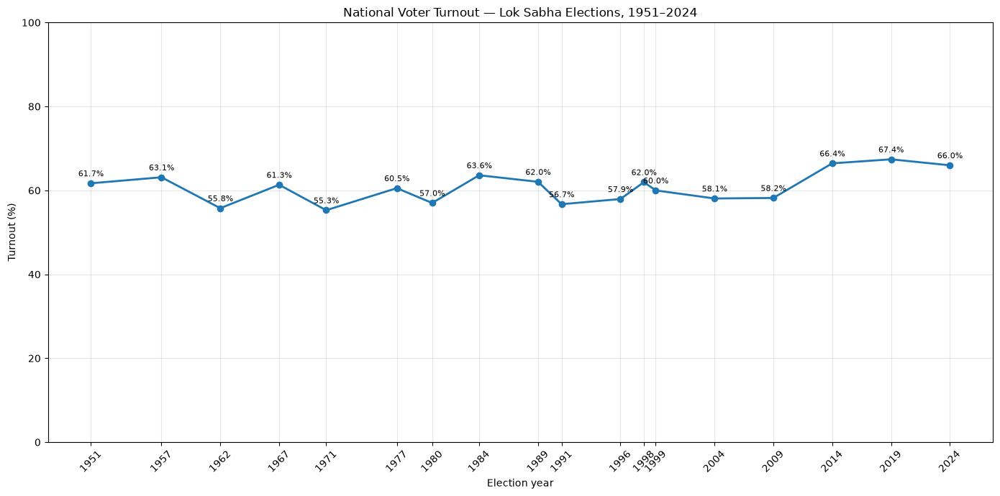

Chart saved to: C:\analysis\outputs\election_wide_trends\national_voter_turnout_1951_2024.png


In [42]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ==================================================
# 1. LOAD THE WORKBOOK
# ==================================================

file_path = "LOKSABHA 1951-2024.xlsx"
df = df.copy()

df.columns = df.columns.str.strip()

# Convert required columns to numeric
for col in ["YEAR", "CONSTITUENCY NO", "TOTAL ELECTORS", "TOTAL VOTED"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")


# ==================================================
# 2. CREATE ONE RECORD PER CONSTITUENCY
# ==================================================

# Use year, state/UT, and constituency identifiers to distinguish
# constituencies across election years.
constituency_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

# Keep one constituency-level record, since elector and total-voted
# figures may be repeated on each candidate row.
constituency_data = (
    df.dropna(subset=constituency_keys)
      .groupby(constituency_keys, as_index=False)
      .agg(
          total_electors=("TOTAL ELECTORS", "first"),
          total_voted=("TOTAL VOTED", "first")
      )
)


# ==================================================
# 3. CALCULATE NATIONAL TURNOUT FOR EACH YEAR
# ==================================================

national_turnout = (
    constituency_data.groupby("YEAR", as_index=False)
    .agg(
        electors=("total_electors", "sum"),
        votes_cast=("total_voted", "sum"),
        constituencies=("CONSTITUENCY NO", "count")
    )
)

national_turnout["turnout_percent"] = (
    national_turnout["votes_cast"]
    / national_turnout["electors"]
    * 100
)

national_turnout = national_turnout.sort_values("YEAR")

display(national_turnout.round(2))


# ==================================================
# 4. PLOT TURNOUT TREND
# ==================================================

fig, ax = plt.subplots(figsize=(14, 7))

ax.plot(
    national_turnout["YEAR"],
    national_turnout["turnout_percent"],
    marker="o",
    linewidth=2
)

ax.set_title("National Voter Turnout — Lok Sabha Elections, 1951–2024")
ax.set_xlabel("Election year")
ax.set_ylabel("Turnout (%)")

ax.set_ylim(0, 100)
ax.grid(alpha=0.3)

# Label the turnout value at each election point
for _, row in national_turnout.iterrows():
    ax.annotate(
        f'{row["turnout_percent"]:.1f}%',
        (row["YEAR"], row["turnout_percent"]),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

plt.xticks(national_turnout["YEAR"], rotation=45)
plt.tight_layout()


# ==================================================
# 5. SAVE CHART
# ==================================================

output_folder = Path("outputs/election_wide_trends")
output_folder.mkdir(parents=True, exist_ok=True)

chart_path = output_folder / "national_voter_turnout_1951_2024.png"

fig.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Chart saved to:", chart_path.resolve())

,YEAR,total_electors,total_votes_cast,constituency_count,electors_millions,votes_cast_millions
0,1951,171746008,105950083,396,171.75,105.95
1,1957,190918439,120513915,396,190.92,120.51
2,1962,215040587,119904284,491,215.04,119.90
3,1967,249003334,152724611,515,249.00,152.72
4,1971,274174155,151536802,517,274.17,151.54
5,1977,320928417,194263915,540,320.93,194.26
6,1980,355685623,202752893,528,355.69,202.75
7,1984,379284932,241246887,514,379.28,241.25
8,1989,498123814,309050451,528,498.12,309.05
9,1991,497394502,282071474,520,497.39,282.07


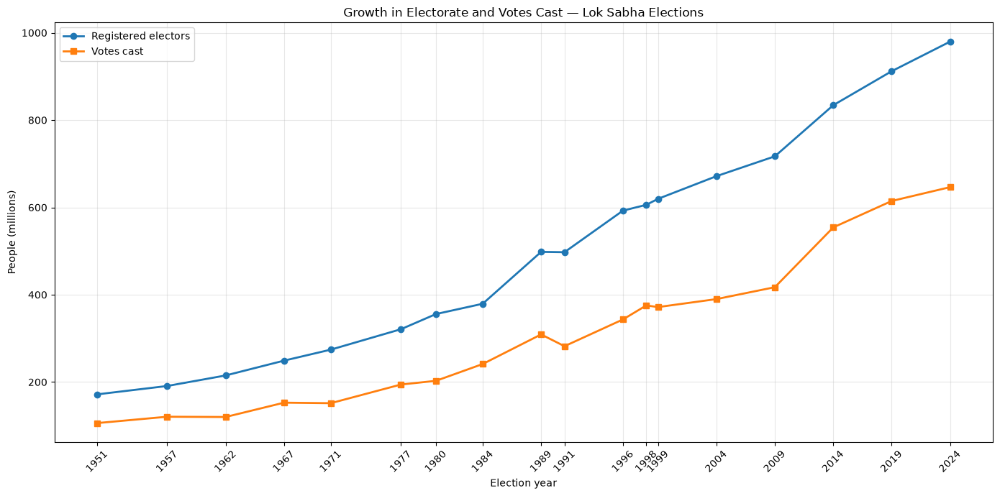

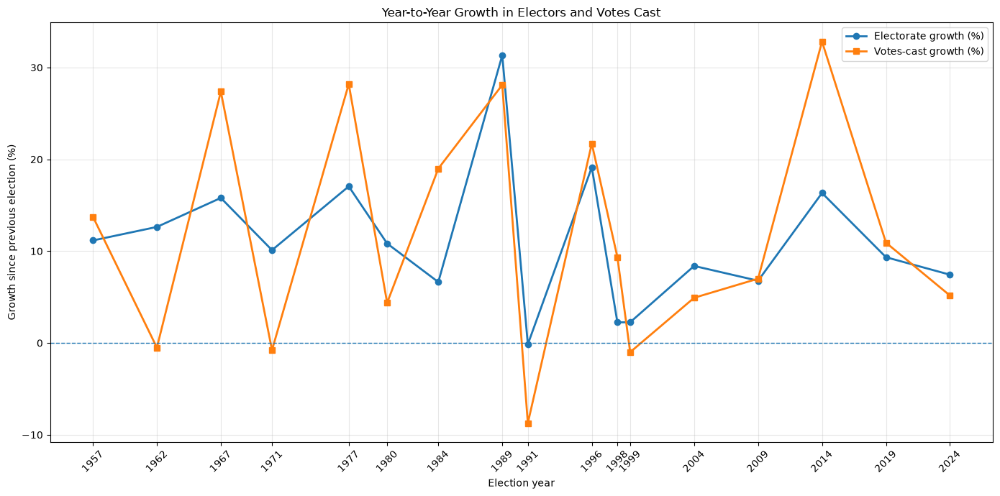

Chart A saved to: C:\analysis\outputs\election_wide_trends\electorate_and_votes_cast.png
Chart B saved to: C:\analysis\outputs\election_wide_trends\electorate_and_votes_cast_growth.png


In [43]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ==================================================
# 1. LOAD WORKBOOK
# ==================================================

file_path = "LOKSABHA 1951-2024.xlsx"
df = df.copy()

df.columns = df.columns.str.strip()

# Convert relevant columns to numeric
for col in ["YEAR", "CONSTITUENCY NO", "TOTAL ELECTORS", "TOTAL VOTED"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")


# ==================================================
# 2. GET ONE RECORD PER CONSTITUENCY
# ==================================================

constituency_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

constituency_data = (
    df.dropna(subset=constituency_keys)
      .groupby(constituency_keys, as_index=False)
      .agg(
          total_electors=("TOTAL ELECTORS", "first"),
          total_voted=("TOTAL VOTED", "first")
      )
)


# ==================================================
# 3. SUM NATIONAL ELECTORATE AND VOTES CAST
# ==================================================

election_totals = (
    constituency_data.groupby("YEAR", as_index=False)
    .agg(
        total_electors=("total_electors", "sum"),
        total_votes_cast=("total_voted", "sum"),
        constituency_count=("CONSTITUENCY NO", "count")
    )
    .sort_values("YEAR")
)

# Express counts in millions for easier chart reading
election_totals["electors_millions"] = (
    election_totals["total_electors"] / 1_000_000
)

election_totals["votes_cast_millions"] = (
    election_totals["total_votes_cast"] / 1_000_000
)

display(election_totals.round(2))


# ==================================================
# 4. CHART A: ELECTORATE AND VOTES CAST OVER TIME
# ==================================================

fig, ax = plt.subplots(figsize=(14, 7))

ax.plot(
    election_totals["YEAR"],
    election_totals["electors_millions"],
    marker="o",
    linewidth=2,
    label="Registered electors"
)

ax.plot(
    election_totals["YEAR"],
    election_totals["votes_cast_millions"],
    marker="s",
    linewidth=2,
    label="Votes cast"
)

ax.set_title("Growth in Electorate and Votes Cast — Lok Sabha Elections")
ax.set_xlabel("Election year")
ax.set_ylabel("People (millions)")
ax.grid(alpha=0.3)
ax.legend()

plt.xticks(election_totals["YEAR"], rotation=45)
plt.tight_layout()


# ==================================================
# 5. SAVE CHART A
# ==================================================

output_folder = Path("outputs/election_wide_trends")
output_folder.mkdir(parents=True, exist_ok=True)

chart_a_path = output_folder / "electorate_and_votes_cast.png"

fig.savefig(chart_a_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# ==================================================
# 6. CALCULATE YEAR-TO-YEAR GROWTH
# ==================================================

election_totals["electorate_growth_percent"] = (
    election_totals["total_electors"].pct_change() * 100
)

election_totals["votes_cast_growth_percent"] = (
    election_totals["total_votes_cast"].pct_change() * 100
)


# ==================================================
# 7. CHART B: YEAR-TO-YEAR GROWTH RATE
# ==================================================

# The first election has no previous election for comparison,
# so its growth rate is undefined and will not be plotted.
growth_data = election_totals.dropna(
    subset=[
        "electorate_growth_percent",
        "votes_cast_growth_percent"
    ]
)

fig, ax = plt.subplots(figsize=(14, 7))

ax.plot(
    growth_data["YEAR"],
    growth_data["electorate_growth_percent"],
    marker="o",
    linewidth=2,
    label="Electorate growth (%)"
)

ax.plot(
    growth_data["YEAR"],
    growth_data["votes_cast_growth_percent"],
    marker="s",
    linewidth=2,
    label="Votes-cast growth (%)"
)

ax.axhline(0, linewidth=1, linestyle="--")

ax.set_title("Year-to-Year Growth in Electors and Votes Cast")
ax.set_xlabel("Election year")
ax.set_ylabel("Growth since previous election (%)")
ax.grid(alpha=0.3)
ax.legend()

plt.xticks(growth_data["YEAR"], rotation=45)
plt.tight_layout()


# ==================================================
# 8. SAVE CHART B
# ==================================================

chart_b_path = output_folder / "electorate_and_votes_cast_growth.png"

fig.savefig(chart_b_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# ==================================================
# 9. PRINT OUTPUT LOCATIONS
# ==================================================

print("Chart A saved to:", chart_a_path.resolve())
print("Chart B saved to:", chart_b_path.resolve())

,YEAR,distinct_parties
0,1951,32
1,1957,14
2,1962,22
3,1967,20
4,1971,37
5,1977,25
6,1980,27
7,1984,29
8,1989,38
9,1991,36


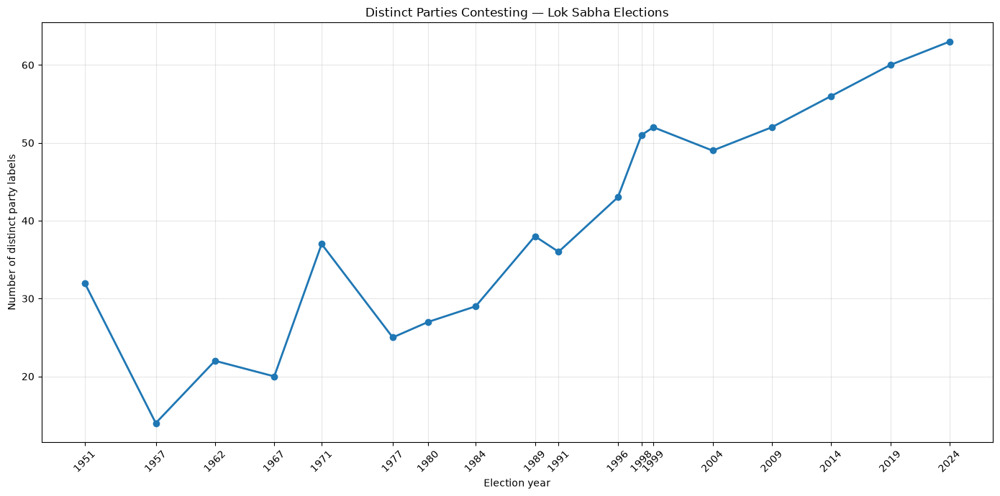

Chart saved to: C:\analysis\outputs\election_wide_trends\distinct_parties_contesting_over_time.png


In [44]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ==================================================
# 1. LOAD WORKBOOK
# ==================================================

file_path = "LOKSABHA 1951-2024.xlsx"
df = df.copy()

df.columns = df.columns.str.strip()

df["YEAR"] = pd.to_numeric(df["YEAR"], errors="coerce")
df["PARTY"] = df["PARTY"].astype("string").str.strip()

# Remove rows without election year or party label
party_data = df.dropna(subset=["YEAR", "PARTY"]).copy()

# Exclude blank party labels
party_data = party_data[party_data["PARTY"] != ""]


# ==================================================
# 2. COUNT DISTINCT PARTIES PER ELECTION YEAR
# ==================================================

yearly_party_count = (
    party_data.groupby("YEAR")["PARTY"]
    .nunique()
    .reset_index(name="distinct_parties")
    .sort_values("YEAR")
)

display(yearly_party_count)


# ==================================================
# 3. CREATE OUTPUT FOLDER
# ==================================================

output_folder = Path("outputs/election_wide_trends")
output_folder.mkdir(parents=True, exist_ok=True)


# ==================================================
# 4. PLOT DISTINCT PARTY COUNT OVER TIME
# ==================================================

fig, ax = plt.subplots(figsize=(14, 7))

ax.plot(
    yearly_party_count["YEAR"],
    yearly_party_count["distinct_parties"],
    marker="o",
    linewidth=2
)

ax.set_title("Distinct Parties Contesting — Lok Sabha Elections")
ax.set_xlabel("Election year")
ax.set_ylabel("Number of distinct party labels")
ax.grid(alpha=0.3)

plt.xticks(yearly_party_count["YEAR"], rotation=45)
plt.tight_layout()


# ==================================================
# 5. SAVE CHART
# ==================================================

chart_path = output_folder / "distinct_parties_contesting_over_time.png"

fig.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Chart saved to:", chart_path.resolve())

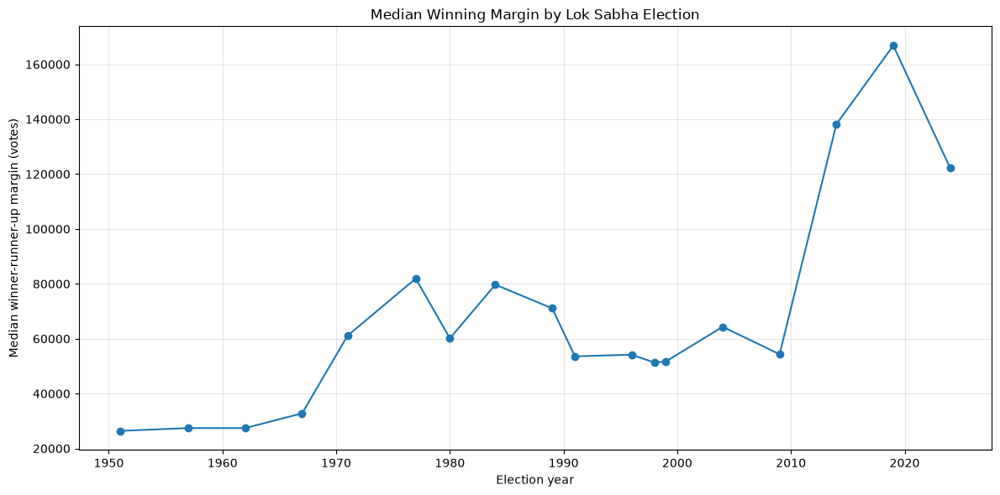

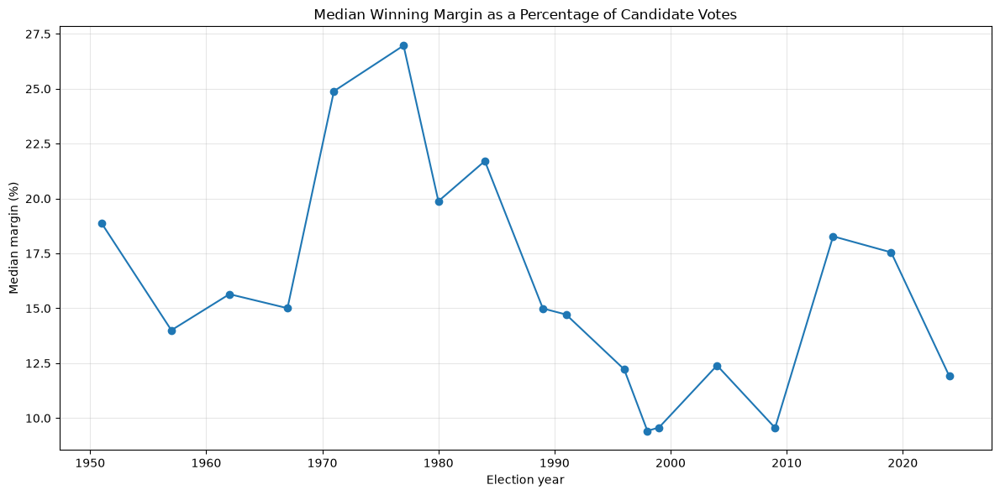

,YEAR,CONTESTS,MEAN_MARGIN_VOTES,MEDIAN_MARGIN_VOTES,MEAN_MARGIN_PERCENT,MEDIAN_MARGIN_PERCENT
0,1951,396,34383.969697,26432.0,23.772519,18.869197
1,1957,396,34441.838384,27438.0,19.557388,14.001391
2,1962,491,34233.236253,27444.0,19.082833,15.645264
3,1967,515,40505.223301,32797.0,18.240453,15.006881
4,1971,517,68559.781431,61094.0,28.434581,24.890518
5,1977,540,95110.420370,81938.0,28.589539,26.968465
6,1980,528,68585.856061,60135.0,22.798110,19.878928
7,1984,514,88017.521401,79706.0,23.750600,21.707689
8,1989,528,88459.420455,71087.0,18.135453,14.993696
9,1991,520,75205.809615,53568.5,17.579078,14.716807


In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load workbook
file_path = "LOKSABHA 1951-2024.xlsx"
df = df.copy()

# Columns identifying one constituency in one election
constituency_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

# Prepare numeric candidate votes
data = df.copy()
data["VOTES"] = pd.to_numeric(data["VOTES"], errors="coerce")
data["YEAR"] = pd.to_numeric(data["YEAR"], errors="coerce")

data = data.dropna(subset=constituency_keys + ["VOTES"])

# Calculate winner-runner-up margin for each constituency
def calculate_margin(group):
    votes = group["VOTES"].sort_values(ascending=False).to_numpy()

    # Need at least two candidates to calculate a margin
    if len(votes) < 2:
        return pd.Series({
            "WINNER VOTES": votes[0] if len(votes) else np.nan,
            "RUNNER UP VOTES": np.nan,
            "MARGIN VOTES": np.nan,
            "MARGIN PERCENT": np.nan
        })

    winner_votes = votes[0]
    runner_up_votes = votes[1]
    margin_votes = winner_votes - runner_up_votes

    # Denominator: sum of votes recorded for candidates in this constituency
    total_candidate_votes = votes.sum()
    margin_percent = (
        margin_votes / total_candidate_votes * 100
        if total_candidate_votes > 0 else np.nan
    )

    return pd.Series({
        "WINNER VOTES": winner_votes,
        "RUNNER UP VOTES": runner_up_votes,
        "MARGIN VOTES": margin_votes,
        "MARGIN PERCENT": margin_percent
    })

constituency_margins = (
    data.groupby(constituency_keys, dropna=False)
        .apply(calculate_margin)
        .reset_index()
)

# Summarize margins by election year
yearly_margin = (
    constituency_margins.groupby("YEAR")
    .agg(
        CONTESTS=("MARGIN VOTES", "count"),
        MEAN_MARGIN_VOTES=("MARGIN VOTES", "mean"),
        MEDIAN_MARGIN_VOTES=("MARGIN VOTES", "median"),
        MEAN_MARGIN_PERCENT=("MARGIN PERCENT", "mean"),
        MEDIAN_MARGIN_PERCENT=("MARGIN PERCENT", "median")
    )
    .reset_index()
    .sort_values("YEAR")
)

# Output folder
output_dir = Path("outputs/election_wide_trends")
output_dir.mkdir(parents=True, exist_ok=True)

# Chart 1: median margin in votes
plt.figure(figsize=(12, 6))
plt.plot(
    yearly_margin["YEAR"],
    yearly_margin["MEDIAN_MARGIN_VOTES"],
    marker="o"
)
plt.title("Median Winning Margin by Lok Sabha Election")
plt.xlabel("Election year")
plt.ylabel("Median winner-runner-up margin (votes)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(output_dir / "median_winning_margin_votes.png", dpi=300)
plt.show()

# Chart 2: median margin percentage
plt.figure(figsize=(12, 6))
plt.plot(
    yearly_margin["YEAR"],
    yearly_margin["MEDIAN_MARGIN_PERCENT"],
    marker="o"
)
plt.title("Median Winning Margin as a Percentage of Candidate Votes")
plt.xlabel("Election year")
plt.ylabel("Median margin (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(output_dir / "median_winning_margin_percent.png", dpi=300)
plt.show()

# View the yearly summary
display(yearly_margin)

# Save summary table
# CSV export removed (chart/on-screen output only).


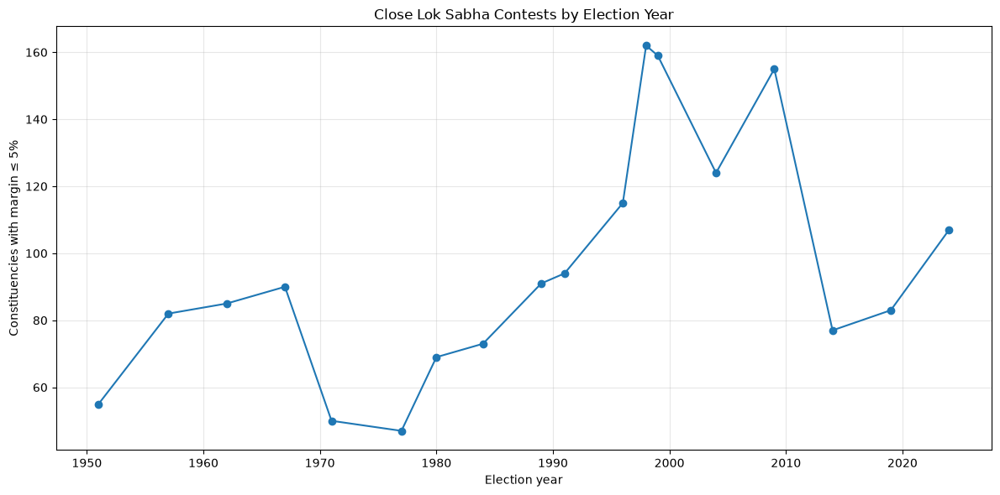

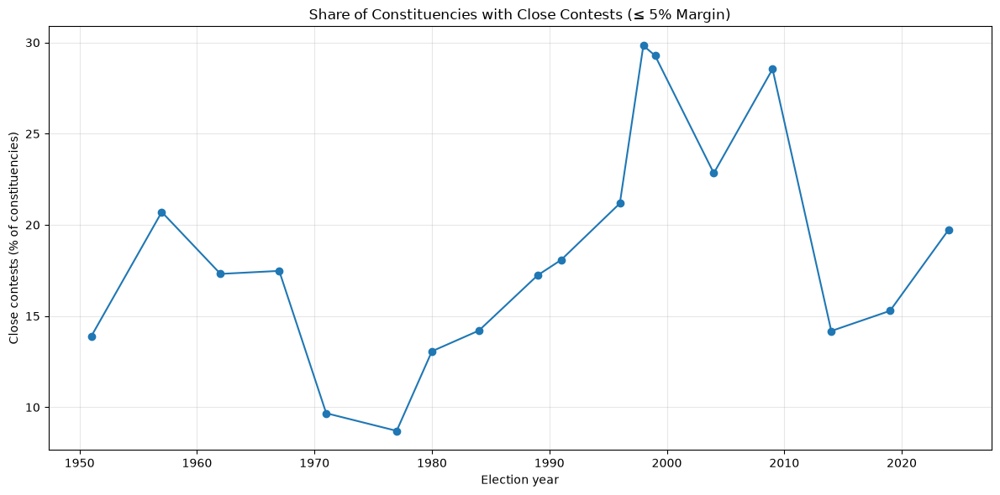

,YEAR,TOTAL_CONTESTS,CLOSE_1_PERCENT,CLOSE_2_PERCENT,CLOSE_5_PERCENT,CLOSE_1_SHARE,CLOSE_2_SHARE,CLOSE_5_SHARE
0,1951,396,10,20,55,2.525253,5.050505,13.888889
1,1957,396,14,33,82,3.535354,8.333333,20.707071
2,1962,491,15,32,85,3.054990,6.517312,17.311609
3,1967,515,26,38,90,5.048544,7.378641,17.475728
4,1971,517,13,23,50,2.514507,4.448743,9.671180
5,1977,540,7,21,47,1.296296,3.888889,8.703704
6,1980,528,10,29,69,1.893939,5.492424,13.068182
7,1984,514,23,36,73,4.474708,7.003891,14.202335
8,1989,528,15,28,91,2.840909,5.303030,17.234848
9,1991,520,17,35,94,3.269231,6.730769,18.076923


In [46]:
# Thresholds for defining close contests
thresholds = [1, 2, 5]

# Count close contests by election year
close_contests = (
    constituency_margins.groupby("YEAR")
    .agg(
        TOTAL_CONTESTS=("MARGIN PERCENT", "count"),
        CLOSE_1_PERCENT=("MARGIN PERCENT", lambda s: (s <= 1).sum()),
        CLOSE_2_PERCENT=("MARGIN PERCENT", lambda s: (s <= 2).sum()),
        CLOSE_5_PERCENT=("MARGIN PERCENT", lambda s: (s <= 5).sum())
    )
    .reset_index()
    .sort_values("YEAR")
)

# Convert close-contest counts to percentages
for threshold in thresholds:
    count_col = f"CLOSE_{threshold}_PERCENT"
    share_col = f"CLOSE_{threshold}_SHARE"

    close_contests[share_col] = (
        close_contests[count_col]
        / close_contests["TOTAL_CONTESTS"].replace(0, np.nan)
        * 100
    )

# Plot count of close contests (margin <= 5%)
plt.figure(figsize=(12, 6))
plt.plot(
    close_contests["YEAR"],
    close_contests["CLOSE_5_PERCENT"],
    marker="o"
)
plt.title("Close Lok Sabha Contests by Election Year")
plt.xlabel("Election year")
plt.ylabel("Constituencies with margin ≤ 5%")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(output_dir / "close_contests_count_by_year.png", dpi=300)
plt.show()

# Plot share of close contests (margin <= 5%)
plt.figure(figsize=(12, 6))
plt.plot(
    close_contests["YEAR"],
    close_contests["CLOSE_5_SHARE"],
    marker="o"
)
plt.title("Share of Constituencies with Close Contests (≤ 5% Margin)")
plt.xlabel("Election year")
plt.ylabel("Close contests (% of constituencies)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(output_dir / "close_contests_share_by_year.png", dpi=300)
plt.show()

# Compare 1%, 2%, and 5% thresholds
display(close_contests)

# Save summary table
# CSV export removed (chart/on-screen output only).


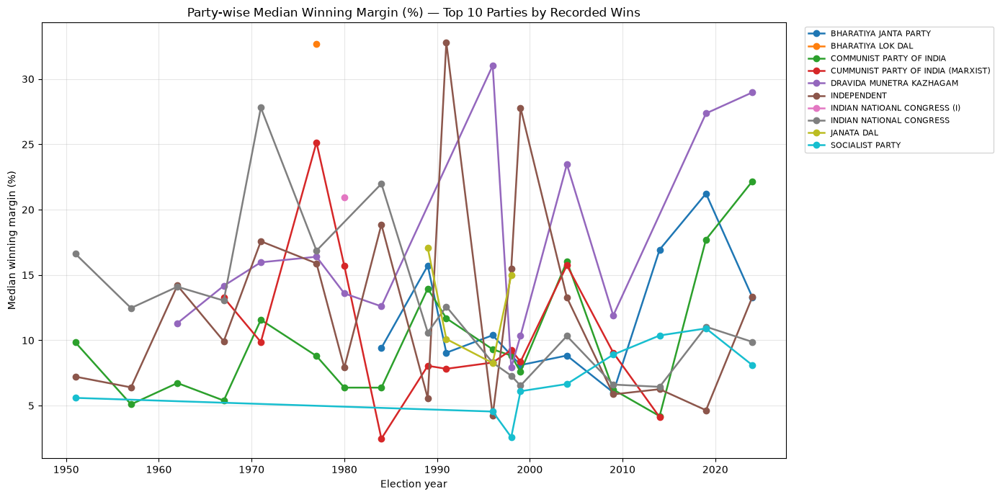

In [47]:
# Analysis 8 supporting chart: party-wise median winning margin percentage
# This cell is self-contained and does not depend on an undefined variable.

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

required = [
    "YEAR", "PARTY", "RESULT POSITION", "MARGIN PERCENT",
    "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Missing required columns: {missing}")

margin_data = df[required].copy()
margin_data["YEAR"] = pd.to_numeric(margin_data["YEAR"], errors="coerce")
margin_data["MARGIN PERCENT"] = pd.to_numeric(
    margin_data["MARGIN PERCENT"], errors="coerce"
)
margin_data["RESULT POSITION"] = (
    margin_data["RESULT POSITION"].astype("string").str.strip().str.lower()
)
margin_data["PARTY"] = margin_data["PARTY"].astype("string").str.strip()

winner_mask = margin_data["RESULT POSITION"].str.fullmatch(
    r"winner(?:\\s+\\d+)?", na=False
)
winner_margin_data = margin_data.loc[
    winner_mask
    & margin_data["YEAR"].notna()
    & margin_data["PARTY"].notna()
    & margin_data["PARTY"].ne("")
    & margin_data["MARGIN PERCENT"].notna()
].copy()

# One margin observation per winning constituency-party-election.
constituency_keys = [
    "YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"
]
winner_margin_data = winner_margin_data.drop_duplicates(
    subset=constituency_keys + ["PARTY"]
)

party_margin_summary = (
    winner_margin_data.groupby(["YEAR", "PARTY"], as_index=False)
    .agg(
        SEATS_WON=("MARGIN PERCENT", "size"),
        MEDIAN_MARGIN_PERCENT=("MARGIN PERCENT", "median")
    )
)

if party_margin_summary.empty:
    print("No valid winner margin records were found.")
else:
    top_10_parties = (
        party_margin_summary.groupby("PARTY")["SEATS_WON"]
        .sum()
        .nlargest(10)
        .index
    )
    plot_data = party_margin_summary[
        party_margin_summary["PARTY"].isin(top_10_parties)
    ].copy()

    fig, ax = plt.subplots(figsize=(14, 7))
    for party, group in plot_data.groupby("PARTY"):
        group = group.sort_values("YEAR")
        ax.plot(
            group["YEAR"],
            group["MEDIAN_MARGIN_PERCENT"],
            marker="o",
            linewidth=1.8,
            label=party
        )

    ax.set_title(
        "Party-wise Median Winning Margin (%) — Top 10 Parties by Recorded Wins"
    )
    ax.set_xlabel("Election year")
    ax.set_ylabel("Median winning margin (%)")
    ax.grid(True, alpha=0.3)
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    fig.tight_layout()

    output_dir = Path("outputs/party_winning_margin")
    output_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        output_dir / "08_5_top_10_party_winning_margin_percent.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


,YEAR,PARTY,SEATS_WON,SEAT_SHARE_PERCENT
10,1951,INDIAN NATIONAL CONGRESS,359,74.327122
9,1951,INDEPENDENT,37,7.660455
7,1951,COMMUNIST PARTY OF INDIA,16,3.312629
20,1951,SOCIALIST PARTY,12,2.484472
12,1951,KISAN MAZDOOR PRAJA PARTY,9,1.863354
...,...,...,...,...
500,2024,TELUGU DESAM,16,2.946593
485,2024,Janata Dal (United),12,2.209945
498,2024,Shiv Sena (Uddhav Balasaheb Thackrey),9,1.657459
490,2024,Nationalist Congress Party – Sharadchandra Pawar,8,1.473297


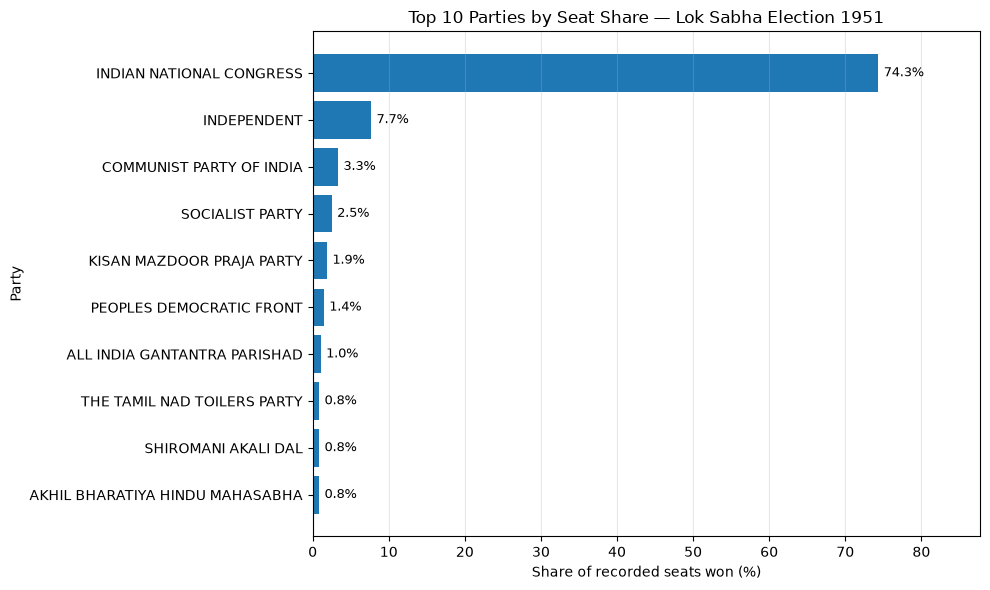

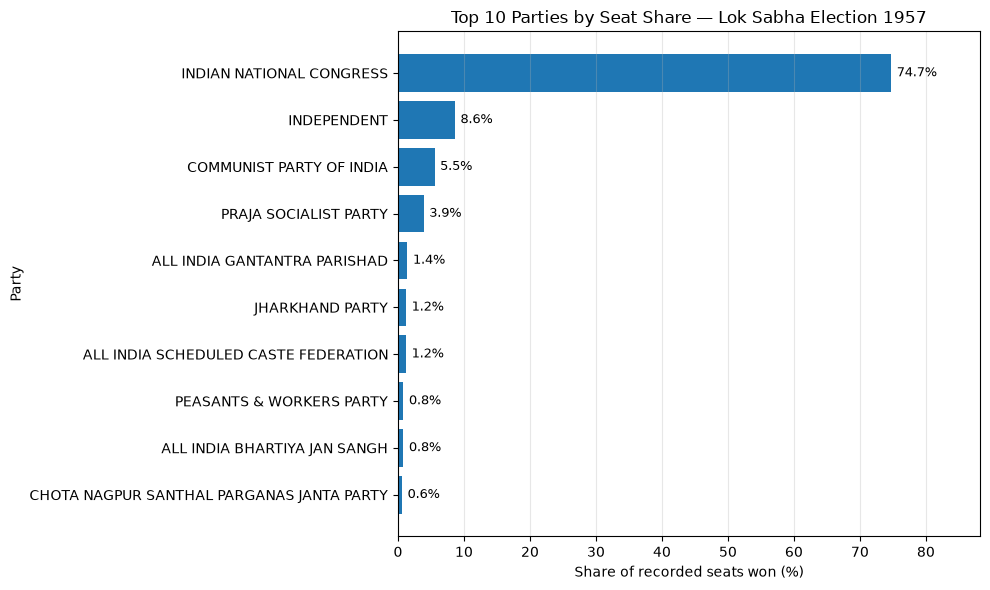

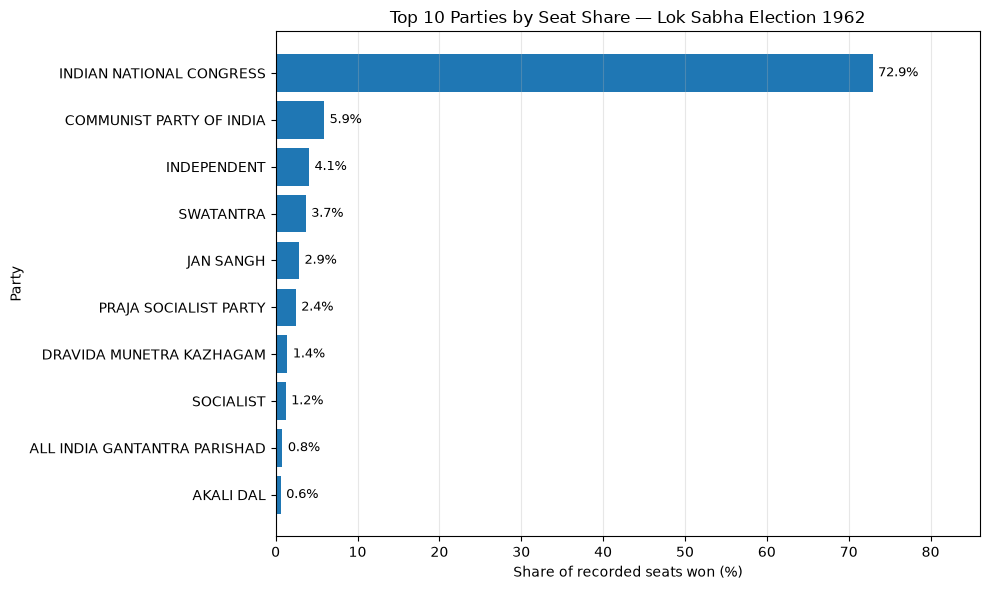

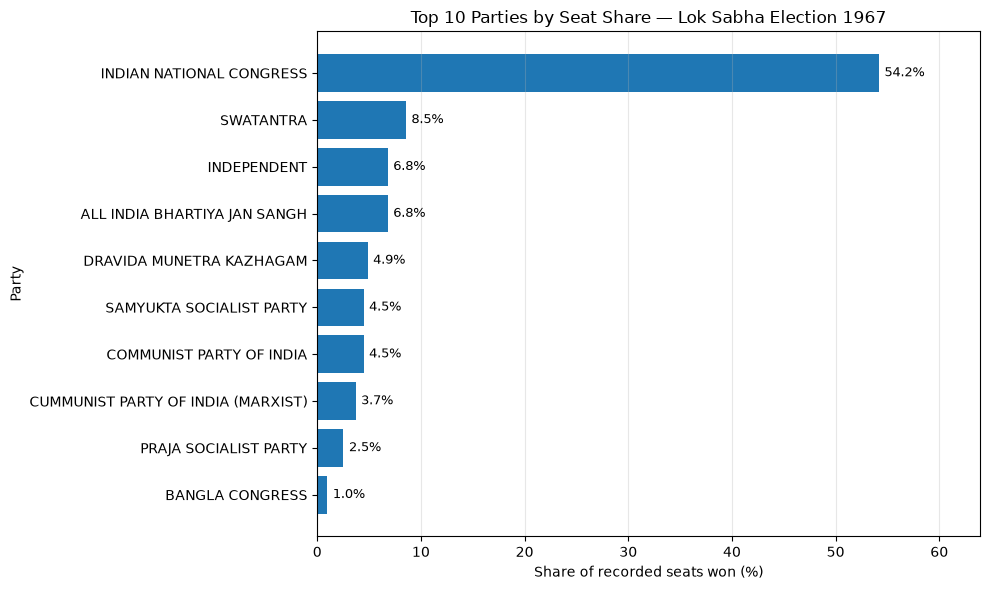

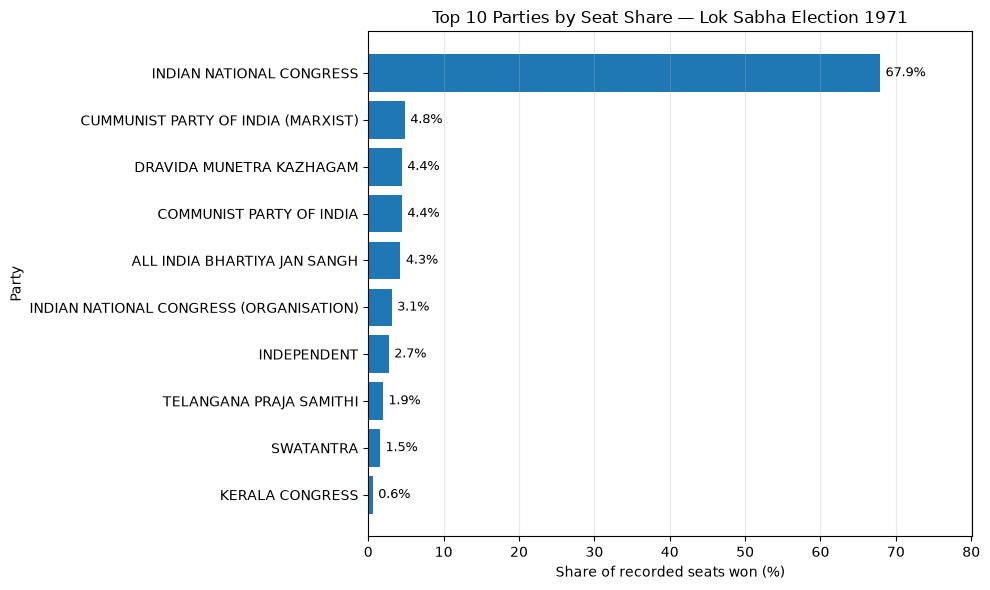

...

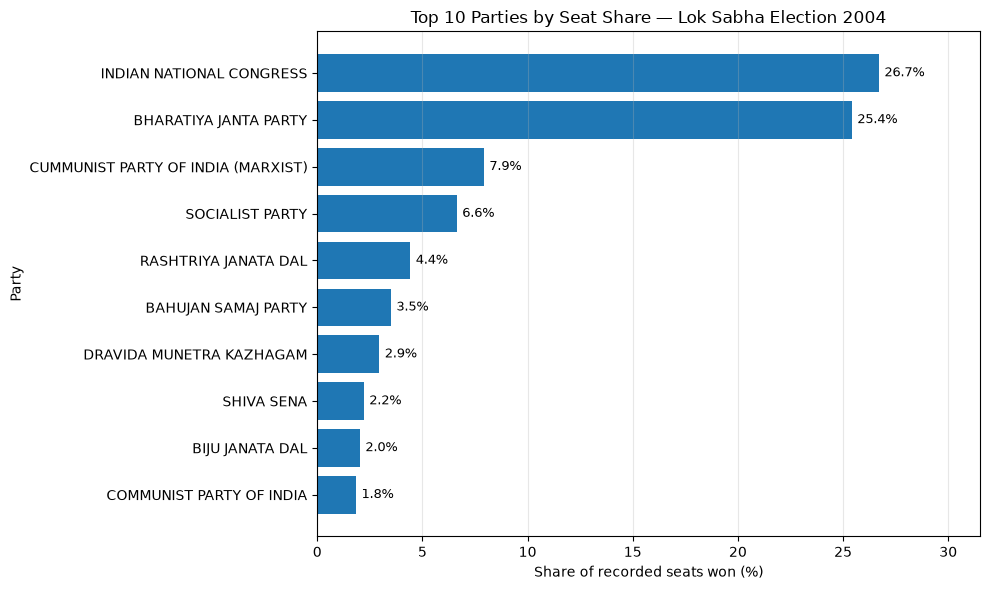

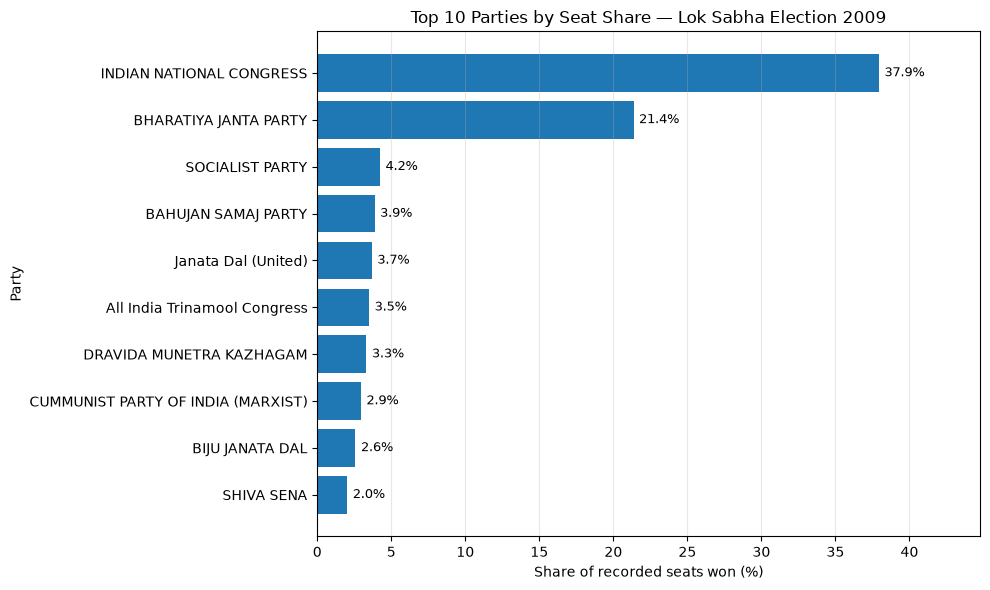

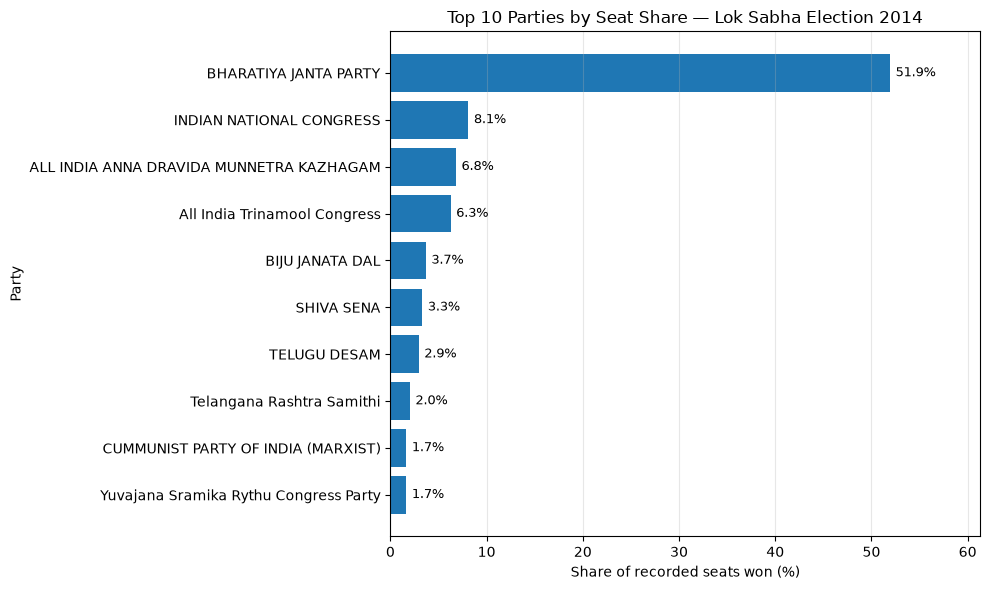

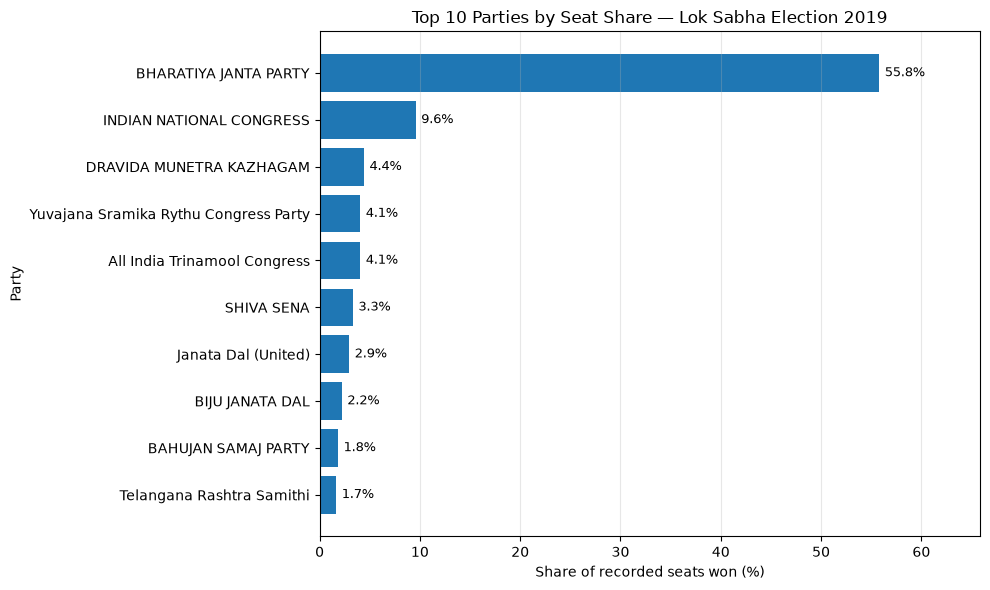

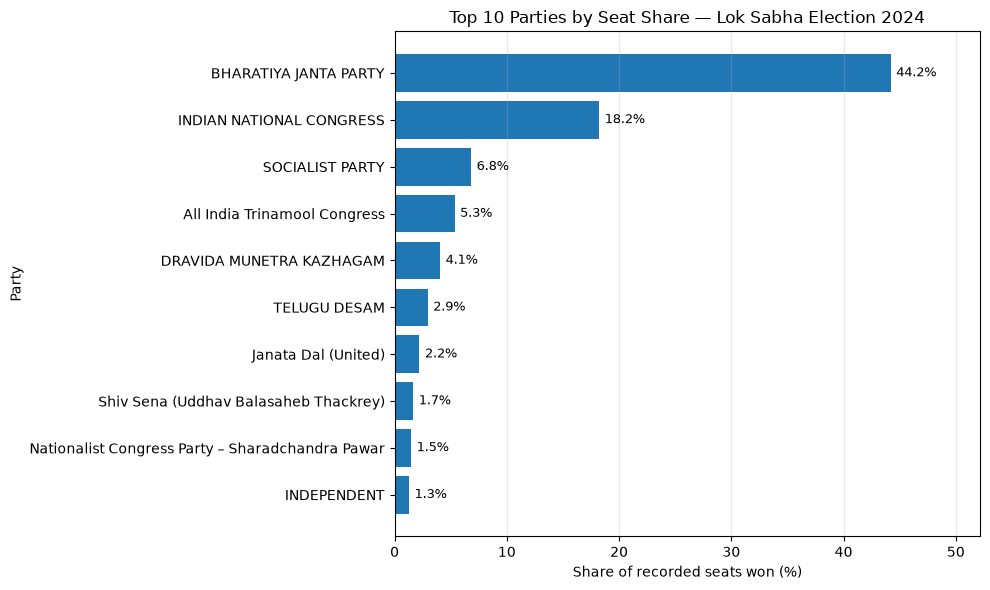

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Output folder
output_dir = Path("outputs/party_performance")
output_dir.mkdir(parents=True, exist_ok=True)

# Normalize result labels
result_labels = (
    df["RESULT POSITION"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Include Winner, Winner 1, Winner 2, etc.
winner_mask = result_labels.str.match(r"^winner(\s+\d+)?$", na=False)

winners = df.loc[winner_mask, ["YEAR", "PARTY"]].copy()
winners["YEAR"] = pd.to_numeric(winners["YEAR"], errors="coerce")
winners["PARTY"] = winners["PARTY"].astype("string").str.strip()

# Remove missing/blank party names
winners = winners.dropna(subset=["YEAR", "PARTY"])
winners = winners[winners["PARTY"].ne("")]

# Seats won by party in each election
party_seats = (
    winners.groupby(["YEAR", "PARTY"])
    .size()
    .reset_index(name="SEATS_WON")
)

# Total winner records per election (denominator for seat share)
seats_per_election = (
    party_seats.groupby("YEAR")["SEATS_WON"]
    .sum()
    .reset_index(name="TOTAL_SEATS_RECORDED")
)

party_seats = party_seats.merge(seats_per_election, on="YEAR", how="left")

party_seats["SEAT_SHARE_PERCENT"] = (
    party_seats["SEATS_WON"]
    / party_seats["TOTAL_SEATS_RECORDED"]
    * 100
)

# For each election, keep the top 10 parties by seats
top10_each_election = (
    party_seats.sort_values(
        ["YEAR", "SEATS_WON", "PARTY"],
        ascending=[True, False, True]
    )
    .groupby("YEAR")
    .head(10)
    .copy()
)

# Display top 10 parties and their seat shares for each election
display(
    top10_each_election[
        ["YEAR", "PARTY", "SEATS_WON", "SEAT_SHARE_PERCENT"]
    ].sort_values(["YEAR", "SEATS_WON"], ascending=[True, False])
)

# Plot top 10 parties for each election, with percentage labels
years = sorted(top10_each_election["YEAR"].dropna().unique())

for year in years:
    election_top10 = (
        top10_each_election[top10_each_election["YEAR"] == year]
        .sort_values("SEAT_SHARE_PERCENT", ascending=True)
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    bars = ax.barh(
        election_top10["PARTY"],
        election_top10["SEAT_SHARE_PERCENT"]
    )

    # Add percentage values at the end of each bar
    ax.bar_label(
        bars,
        labels=[f"{value:.1f}%" for value in election_top10["SEAT_SHARE_PERCENT"]],
        padding=4,
        fontsize=9
    )

    ax.set_title(f"Top 10 Parties by Seat Share — Lok Sabha Election {int(year)}")
    ax.set_xlabel("Share of recorded seats won (%)")
    ax.set_ylabel("Party")
    ax.grid(axis="x", alpha=0.3)

    # Give labels some room beyond the longest bar
    max_share = election_top10["SEAT_SHARE_PERCENT"].max()
    ax.set_xlim(0, max_share * 1.18 if max_share > 0 else 1)

    plt.tight_layout()

    plt.savefig(
        output_dir / f"party_dominance_top10_{int(year)}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

YEAR,1951,1957,1962,1967,1971,1977,1980,1984,1989,1991,1996,1998,1999,2004,2009,2014,2019,2024
PARTY,,,,,,,,,,,,,,,,,,
BHARATIYA JANTA PARTY,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.0,3.0,2.0,1.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0
BHARATIYA LOK DAL,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
COMMUNIST PARTY OF INDIA,3.0,3.0,2.0,6.0,3.0,7.0,7.0,6.0,5.0,5.0,10.0,9.0,18.0,10.0,16.0,27.0,19.0,19.0
CUMMUNIST PARTY OF INDIA (MARXIST),NaN,NaN,NaN,8.0,2.0,3.0,3.0,3.0,4.0,4.0,4.0,3.0,3.0,3.0,8.0,9.0,NaN,NaN
DRAVIDA MUNETRA KAZHAGAM,NaN,NaN,7.0,5.0,3.0,12.0,5.0,12.0,NaN,NaN,6.0,13.0,9.0,7.0,7.0,NaN,3.0,5.0
INDEPENDENT,2.0,2.0,3.0,3.0,7.0,5.0,8.0,7.0,5.0,15.0,12.0,13.0,15.0,15.0,11.0,17.0,14.0,10.0
INDIAN NATIOANL CONGRESS (I),NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
INDIAN NATIONAL CONGRESS,1.0,1.0,1.0,1.0,1.0,2.0,NaN,1.0,1.0,1.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0
JANATA DAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,3.0,3.0,13.0,NaN,NaN,NaN,NaN,NaN,NaN


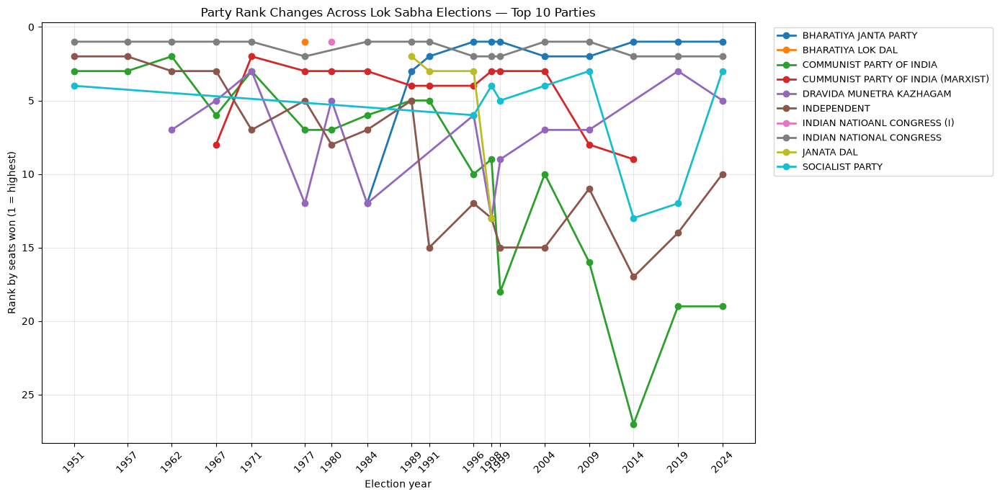

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Output folder
output_dir = Path("outputs/party_performance")
output_dir.mkdir(parents=True, exist_ok=True)

# Normalize winner labels
result_labels = (
    df["RESULT POSITION"]
    .astype("string")
    .str.strip()
    .str.lower()
)

winner_mask = result_labels.str.match(r"^winner(\s+\d+)?$", na=False)

winners = df.loc[winner_mask, ["YEAR", "PARTY"]].copy()
winners["YEAR"] = pd.to_numeric(winners["YEAR"], errors="coerce")
winners["PARTY"] = winners["PARTY"].astype("string").str.strip()

# Remove missing or blank party names
winners = winners.dropna(subset=["YEAR", "PARTY"])
winners = winners[winners["PARTY"].ne("")]

# Count seats won by each party in each election
party_seats = (
    winners.groupby(["YEAR", "PARTY"])
    .size()
    .reset_index(name="SEATS_WON")
)

# Rank parties within each election (1 = most seats)
party_seats["SEAT_RANK"] = (
    party_seats.groupby("YEAR")["SEATS_WON"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Pick the 10 parties with the most total seats across the dataset
top10_parties = (
    party_seats.groupby("PARTY")["SEATS_WON"]
    .sum()
    .nlargest(10)
    .index
)

rank_data = party_seats[
    party_seats["PARTY"].isin(top10_parties)
].copy()

# Show the rank table
rank_table = rank_data.pivot(
    index="PARTY",
    columns="YEAR",
    values="SEAT_RANK"
).sort_index()

display(rank_table)

# Plot rank changes over time
fig, ax = plt.subplots(figsize=(14, 7))

for party, group in rank_data.groupby("PARTY"):
    group = group.sort_values("YEAR")

    ax.plot(
        group["YEAR"],
        group["SEAT_RANK"],
        marker="o",
        linewidth=2,
        label=party
    )

ax.set_title("Party Rank Changes Across Lok Sabha Elections — Top 10 Parties")
ax.set_xlabel("Election year")
ax.set_ylabel("Rank by seats won (1 = highest)")
ax.invert_yaxis()  # Rank 1 at the top
ax.set_xticks(sorted(rank_data["YEAR"].unique()))
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

plt.tight_layout()
plt.savefig(
    output_dir / "party_rank_changes_top10.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

,YEAR,PARTY,SEATS_WON,VOTE_SHARE_PERCENT,SEAT_SHARE_PERCENT,SEAT_VOTE_GAP
8,1951,COMMUNIST PARTY OF INDIA,16,3.767375,3.312629,-0.454746
17,1951,KISAN MAZDOOR PRAJA PARTY,9,3.198295,1.863354,-1.334941
22,1951,PEOPLES DEMOCRATIC FRONT,7,1.893652,1.449275,-0.444376
3,1951,ALL INDIA GANTANTRA PARISHAD,5,1.033442,1.035197,0.001755
0,1951,AKHIL BHARATIYA HINDU MAHASABHA,4,0.823544,0.828157,0.004613
...,...,...,...,...,...,...
693,2024,SHIROMANI AKALI DAL,1,0.066651,0.184162,0.117511
697,2024,Sikkim Krantikari Morcha,1,0.029098,0.184162,0.155064
700,2024,"United People’s Party, Liberal",1,0.086552,0.184162,0.097610
703,2024,Voice of the People Party,1,0.101081,0.184162,0.083081


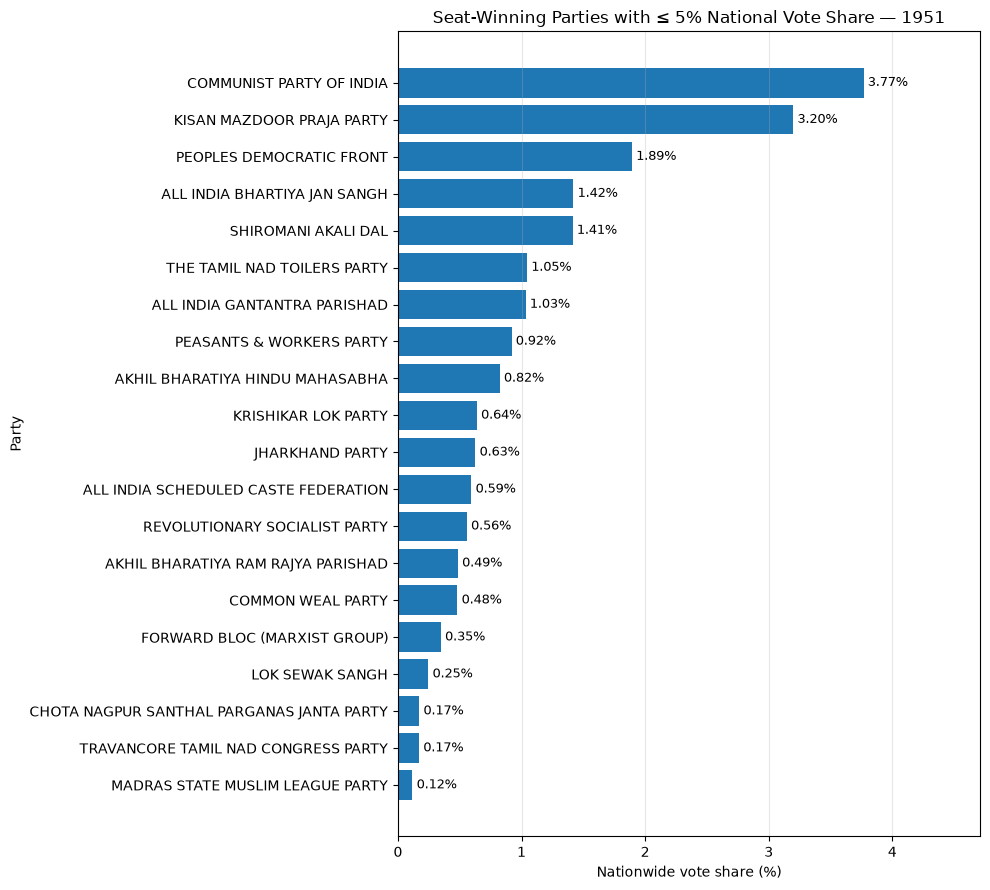

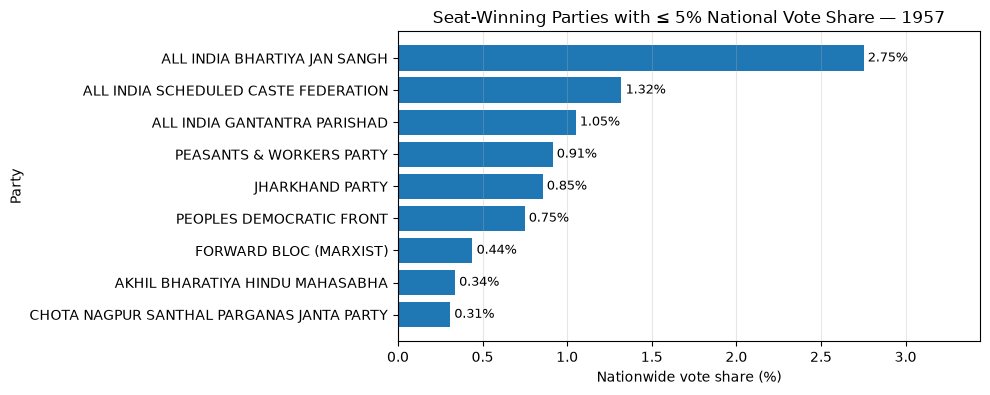

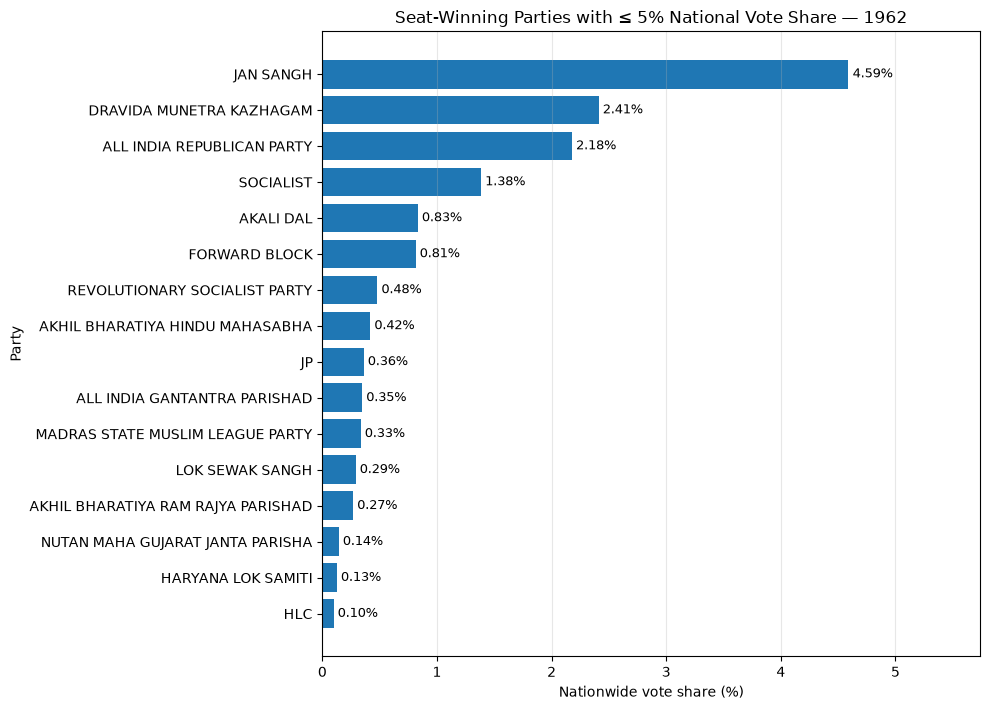

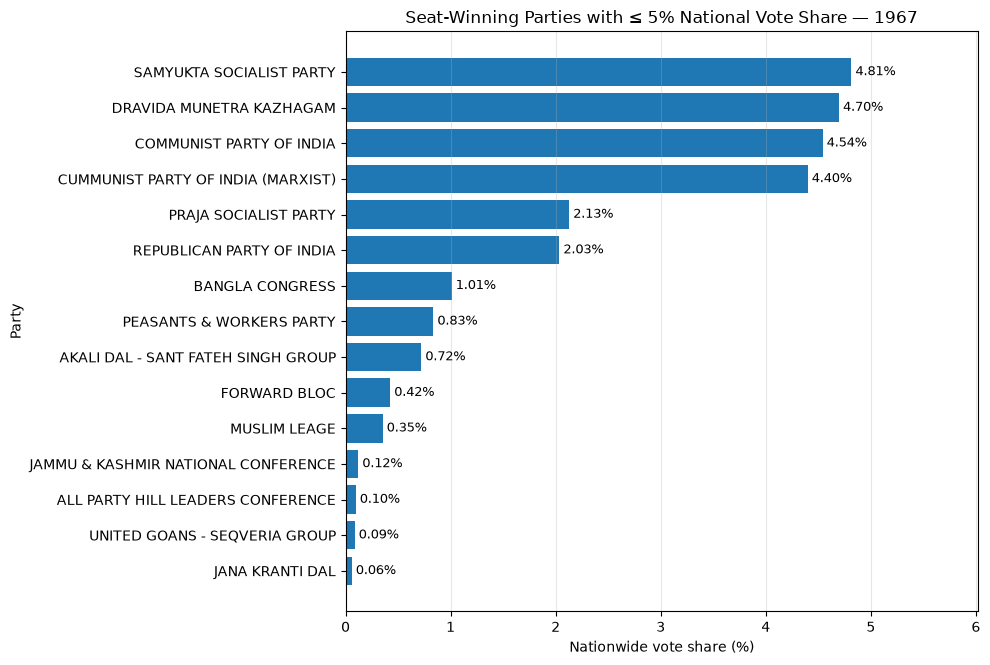

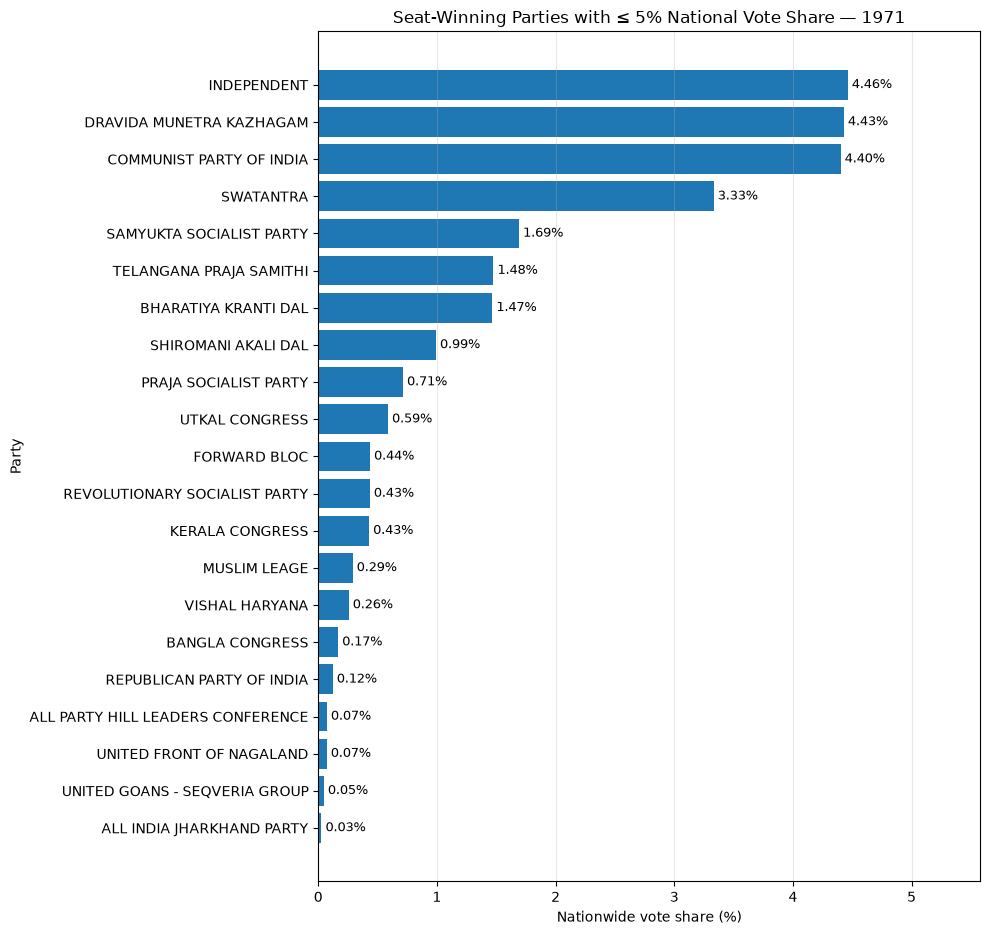

...

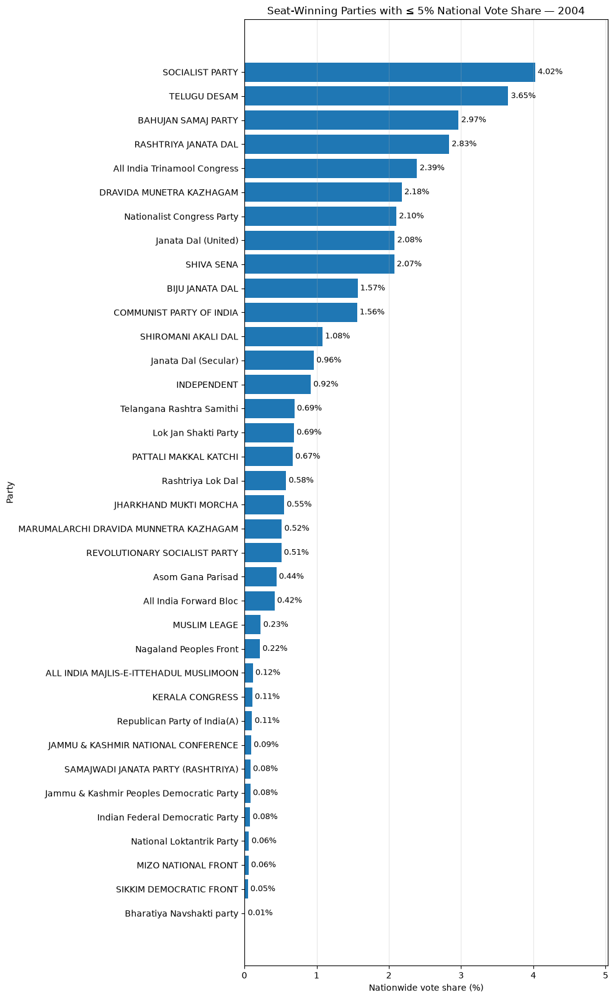

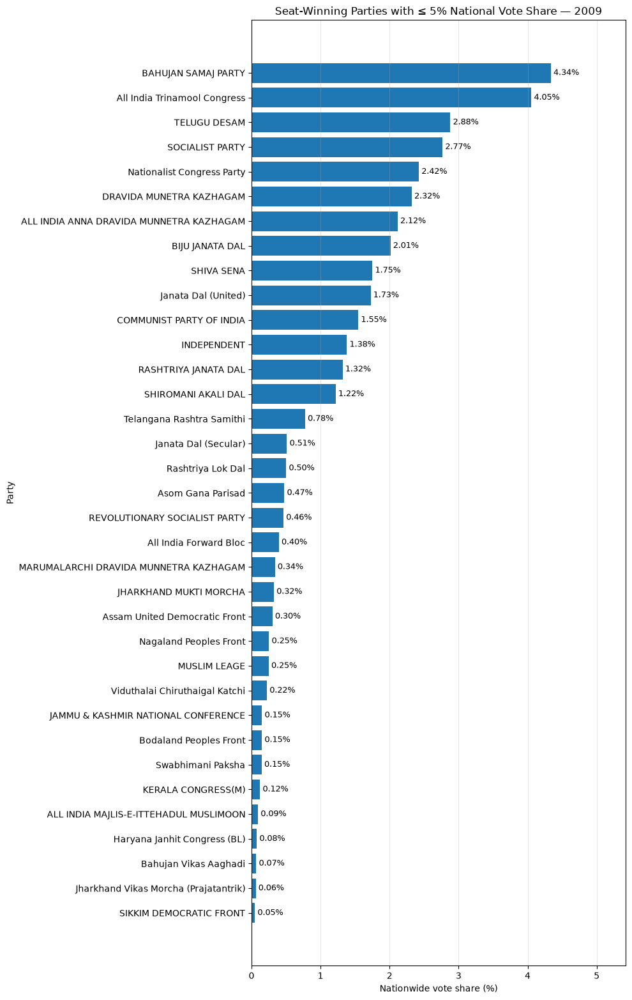

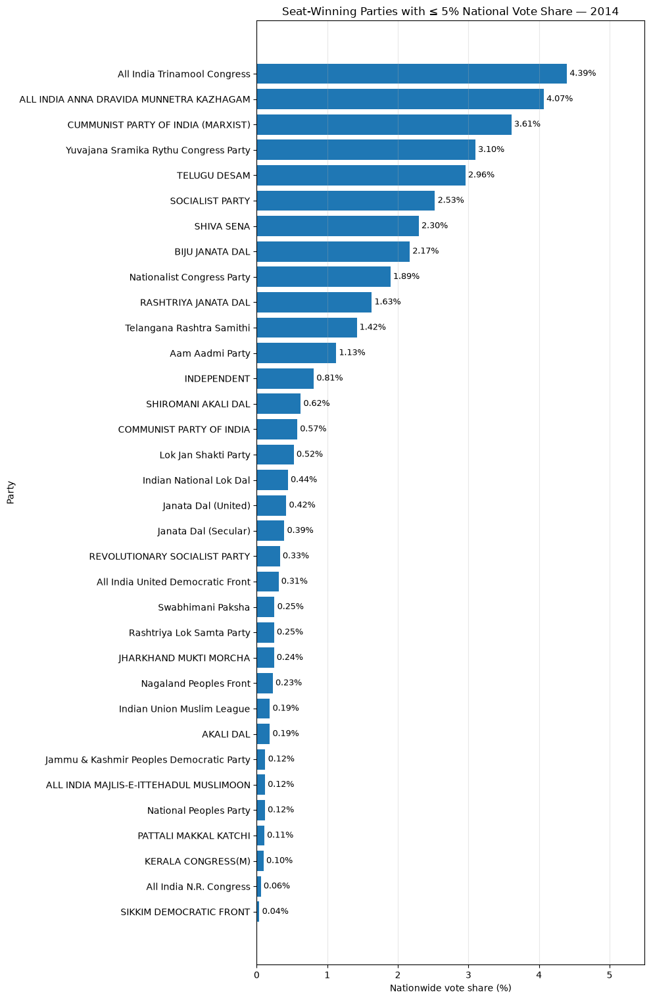

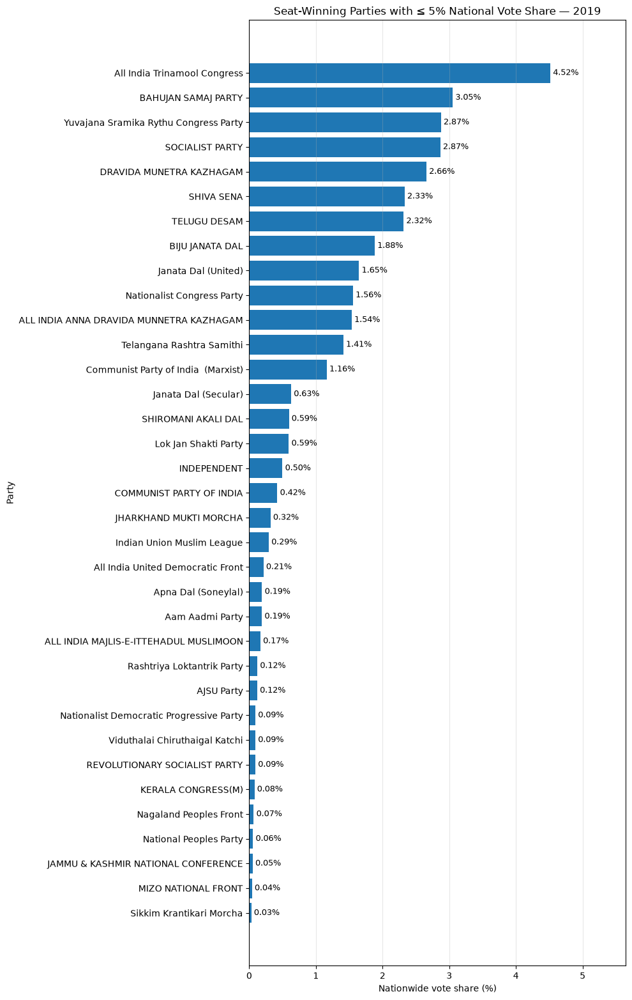

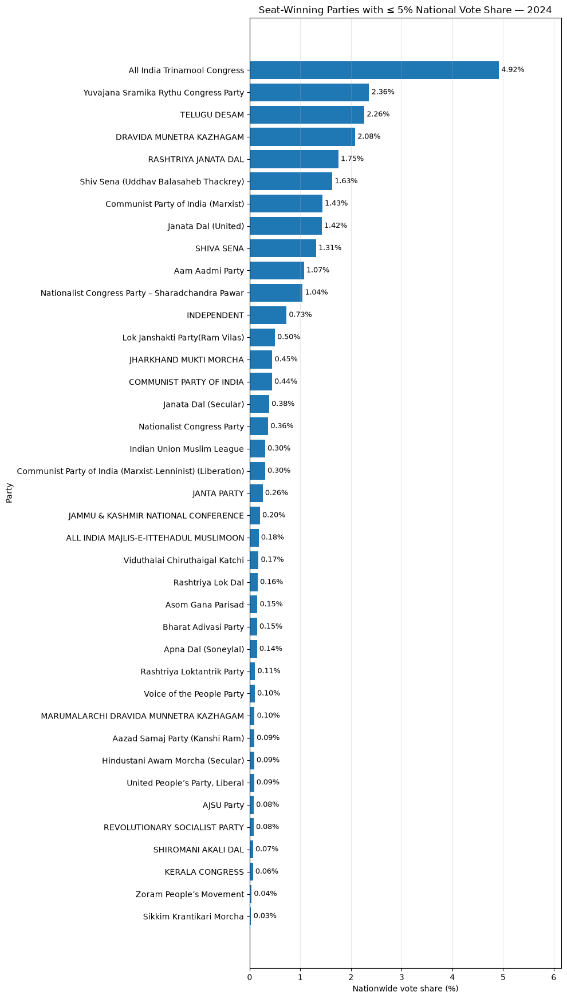

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Output folder
output_dir = Path("outputs/party_performance")
output_dir.mkdir(parents=True, exist_ok=True)

# Prepare data
party_data = df.copy()

party_data["YEAR"] = pd.to_numeric(party_data["YEAR"], errors="coerce")
party_data["VOTES"] = pd.to_numeric(party_data["VOTES"], errors="coerce")
party_data["PARTY"] = party_data["PARTY"].astype("string").str.strip()

# Clean party labels
party_data = party_data.dropna(subset=["YEAR", "PARTY", "VOTES"])
party_data = party_data[party_data["PARTY"].ne("")]

# Nationwide candidate votes by party and election
party_votes = (
    party_data.groupby(["YEAR", "PARTY"])["VOTES"]
    .sum()
    .reset_index(name="PARTY_VOTES")
)

# Total recorded candidate votes per election
national_votes = (
    party_votes.groupby("YEAR")["PARTY_VOTES"]
    .sum()
    .reset_index(name="TOTAL_CANDIDATE_VOTES")
)

party_votes = party_votes.merge(national_votes, on="YEAR", how="left")

party_votes["VOTE_SHARE_PERCENT"] = (
    party_votes["PARTY_VOTES"]
    / party_votes["TOTAL_CANDIDATE_VOTES"]
    * 100
)

# Count winner records as seats won (including Winner 1 / Winner 2)
result_labels = (
    df["RESULT POSITION"]
    .astype("string")
    .str.strip()
    .str.lower()
)

winner_mask = result_labels.str.match(r"^winner(\s+\d+)?$", na=False)

winner_records = df.loc[winner_mask, ["YEAR", "PARTY"]].copy()
winner_records["YEAR"] = pd.to_numeric(winner_records["YEAR"], errors="coerce")
winner_records["PARTY"] = winner_records["PARTY"].astype("string").str.strip()

winner_records = winner_records.dropna(subset=["YEAR", "PARTY"])
winner_records = winner_records[winner_records["PARTY"].ne("")]

party_seats = (
    winner_records.groupby(["YEAR", "PARTY"])
    .size()
    .reset_index(name="SEATS_WON")
)

# Combine party vote share and seats won
party_performance = party_votes.merge(
    party_seats,
    on=["YEAR", "PARTY"],
    how="left"
)

party_performance["SEATS_WON"] = (
    party_performance["SEATS_WON"].fillna(0).astype(int)
)

# Total recorded seats per election, based on winner records
total_seats = (
    party_seats.groupby("YEAR")["SEATS_WON"]
    .sum()
    .reset_index(name="TOTAL_SEATS_RECORDED")
)

party_performance = party_performance.merge(total_seats, on="YEAR", how="left")

party_performance["SEAT_SHARE_PERCENT"] = (
    party_performance["SEATS_WON"]
    / party_performance["TOTAL_SEATS_RECORDED"]
    * 100
)

party_performance["SEAT_VOTE_GAP"] = (
    party_performance["SEAT_SHARE_PERCENT"]
    - party_performance["VOTE_SHARE_PERCENT"]
)

# Filter parties that won seats with low national vote share
vote_share_threshold = 5

low_vote_share_winners = party_performance[
    (party_performance["SEATS_WON"] > 0)
    & (party_performance["VOTE_SHARE_PERCENT"] <= vote_share_threshold)
].copy()

# Sort by election, then seats won (largest first)
low_vote_share_winners = low_vote_share_winners.sort_values(
    ["YEAR", "SEATS_WON"],
    ascending=[True, False]
)

# Display results in notebook (no CSV export)
display(
    low_vote_share_winners[
        [
            "YEAR",
            "PARTY",
            "SEATS_WON",
            "VOTE_SHARE_PERCENT",
            "SEAT_SHARE_PERCENT",
            "SEAT_VOTE_GAP"
        ]
    ]
)

# Plot: low-vote-share parties that won seats, election by election
for year in sorted(low_vote_share_winners["YEAR"].unique()):
    election_data = low_vote_share_winners[
        low_vote_share_winners["YEAR"] == year
    ].sort_values("VOTE_SHARE_PERCENT", ascending=True)

    if election_data.empty:
        continue

    fig, ax = plt.subplots(figsize=(10, max(4, 0.45 * len(election_data))))

    bars = ax.barh(
        election_data["PARTY"],
        election_data["VOTE_SHARE_PERCENT"]
    )

    ax.bar_label(
        bars,
        labels=[
            f"{value:.2f}%"
            for value in election_data["VOTE_SHARE_PERCENT"]
        ],
        padding=3,
        fontsize=9
    )

    ax.set_title(
        f"Seat-Winning Parties with ≤ {vote_share_threshold}% National Vote Share — {int(year)}"
    )
    ax.set_xlabel("Nationwide vote share (%)")
    ax.set_ylabel("Party")
    ax.grid(axis="x", alpha=0.3)

    max_share = election_data["VOTE_SHARE_PERCENT"].max()
    ax.set_xlim(0, max_share * 1.25 if max_share > 0 else 1)

    plt.tight_layout()
    plt.savefig(
        output_dir / f"low_vote_share_seat_winners_{int(year)}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

,AVERAGE_SEAT_SHARE_PERCENT,STD_DEV_SEAT_SHARE_PERCENT,MIN_SEAT_SHARE_PERCENT,MAX_SEAT_SHARE_PERCENT,RANGE_PERCENT_POINTS
PARTY,,,,,
COMMUNIST PARTY OF INDIA,2.283532,1.781076,0.184162,5.906314,5.722152
DRAVIDA MUNETRA KAZHAGAM,1.983177,1.808384,0.000000,4.854369,4.854369
SOCIALIST PARTY,1.867103,2.422208,0.000000,6.813996,6.813996
INDEPENDENT,2.538611,2.547153,0.192308,8.624230,8.431922
CUMMUNIST PARTY OF INDIA (MARXIST),3.736346,2.814163,0.000000,7.918969,7.918969
JANATA DAL,2.656311,6.876618,0.000000,27.083333,27.083333
BHARATIYA LOK DAL,3.034979,12.876327,0.000000,54.629630,54.629630
INDIAN NATIOANL CONGRESS (I),3.714226,15.758125,0.000000,66.856061,66.856061
BHARATIYA JANTA PARTY,18.608915,19.630788,0.000000,55.801105,55.801105


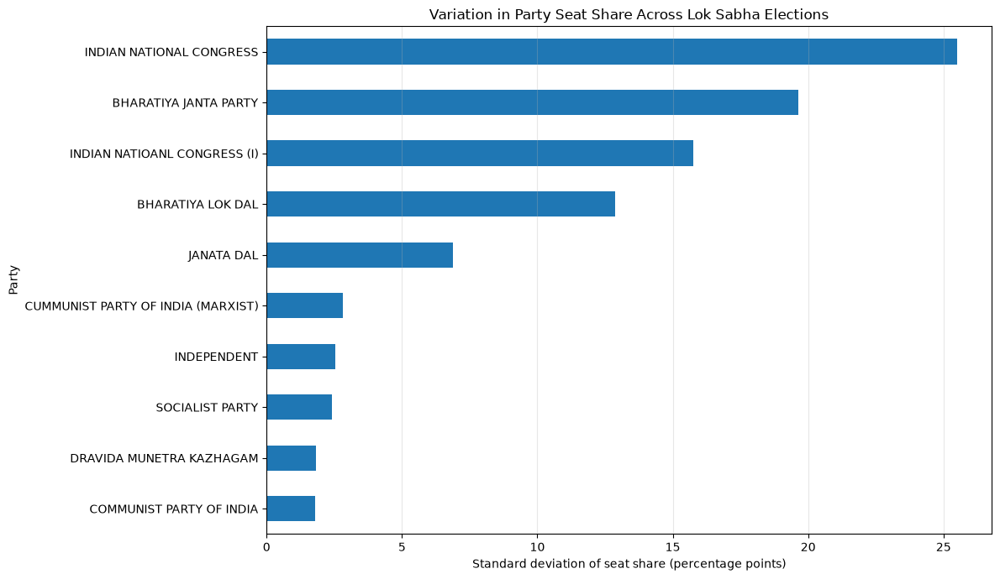

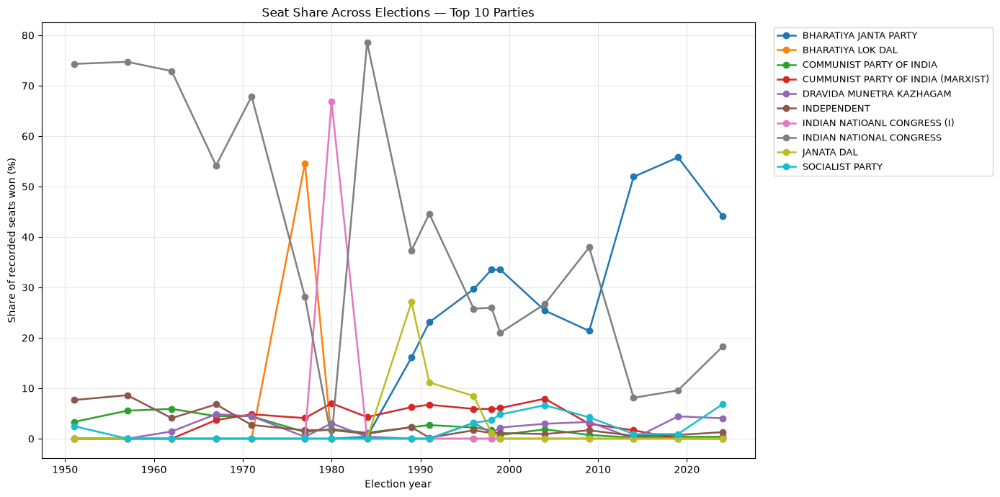

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Output folder
output_dir = Path("outputs/party_performance")
output_dir.mkdir(parents=True, exist_ok=True)

# Normalize winner labels
result_labels = (
    df["RESULT POSITION"]
    .astype("string")
    .str.strip()
    .str.lower()
)

winner_mask = result_labels.str.match(r"^winner(\s+\d+)?$", na=False)

winners = df.loc[winner_mask, ["YEAR", "PARTY"]].copy()
winners["YEAR"] = pd.to_numeric(winners["YEAR"], errors="coerce")
winners["PARTY"] = winners["PARTY"].astype("string").str.strip()

# Exclude blank party names
winners = winners.dropna(subset=["YEAR", "PARTY"])
winners = winners[winners["PARTY"].ne("")]

# Seats won by party in each election
party_seats = (
    winners.groupby(["YEAR", "PARTY"])
    .size()
    .reset_index(name="SEATS_WON")
)

# Total seats recorded for each election
total_seats = (
    party_seats.groupby("YEAR")["SEATS_WON"]
    .sum()
    .reset_index(name="TOTAL_SEATS_RECORDED")
)

party_seats = party_seats.merge(total_seats, on="YEAR", how="left")

# Party's percentage of recorded seats
party_seats["SEAT_SHARE_PERCENT"] = (
    party_seats["SEATS_WON"]
    / party_seats["TOTAL_SEATS_RECORDED"]
    * 100
)

# Select 10 parties with the most seats across the workbook
top10_parties = (
    party_seats.groupby("PARTY")["SEATS_WON"]
    .sum()
    .nlargest(10)
    .index
)

# Build a complete party-by-election grid.
# If a selected party won no seats in an election, record 0.
all_years = sorted(party_seats["YEAR"].dropna().unique())

consistency = (
    party_seats[party_seats["PARTY"].isin(top10_parties)]
    .pivot(index="PARTY", columns="YEAR", values="SEAT_SHARE_PERCENT")
    .reindex(columns=all_years)
    .fillna(0)
)

# Consistency summary across elections
consistency_summary = pd.DataFrame({
    "AVERAGE_SEAT_SHARE_PERCENT": consistency.mean(axis=1),
    "STD_DEV_SEAT_SHARE_PERCENT": consistency.std(axis=1),
    "MIN_SEAT_SHARE_PERCENT": consistency.min(axis=1),
    "MAX_SEAT_SHARE_PERCENT": consistency.max(axis=1)
})

consistency_summary["RANGE_PERCENT_POINTS"] = (
    consistency_summary["MAX_SEAT_SHARE_PERCENT"]
    - consistency_summary["MIN_SEAT_SHARE_PERCENT"]
)

# Lower standard deviation = less fluctuation across elections
consistency_summary = consistency_summary.sort_values(
    "STD_DEV_SEAT_SHARE_PERCENT"
)

display(consistency_summary)

# Plot seat-share fluctuation for these parties
fig, ax = plt.subplots(figsize=(12, 7))

consistency_summary["STD_DEV_SEAT_SHARE_PERCENT"].sort_values().plot(
    kind="barh",
    ax=ax
)

ax.set_title("Variation in Party Seat Share Across Lok Sabha Elections")
ax.set_xlabel("Standard deviation of seat share (percentage points)")
ax.set_ylabel("Party")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    output_dir / "party_seat_share_consistency_top10.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Plot seat-share history for the top 10 parties
fig, ax = plt.subplots(figsize=(14, 7))

for party in consistency.index:
    ax.plot(
        consistency.columns,
        consistency.loc[party],
        marker="o",
        linewidth=1.8,
        label=party
    )

ax.set_title("Seat Share Across Elections — Top 10 Parties")
ax.set_xlabel("Election year")
ax.set_ylabel("Share of recorded seats won (%)")
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)

plt.tight_layout()
plt.savefig(
    output_dir / "party_seat_share_history_top10.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Top 20 most competitive constituencies:


,STATE UT,CONSTITUENCY NO,CONSTITUENCY NAME,ELECTIONS_ANALYZED,CLOSE_CONTESTS,AVG_MARGIN_PERCENT,MIN_MARGIN_PERCENT,CLOSE_CONTEST_SHARE
923,Chhattisgarh,11,KANKER,4,4,1.91,0.16,100.00
916,Chhattisgarh,4,KORBA,4,4,2.60,0.49,100.00
1345,KERALA,7,PALGHAT,6,4,5.25,0.18,66.67
1337,KERALA,3,BADAGARA,6,4,5.55,1.12,66.67
1333,KERALA,1,KASARAGOD,6,4,5.88,0.22,66.67
3719,WEST BENGAL,5,RAIGANJ,6,4,6.03,0.33,66.67
2849,TAMIL NADU,30,NAGAPATTINAM (SC),6,4,8.00,0.38,66.67
1351,KERALA,9,Trichur,3,3,1.58,0.24,100.00
1659,MAHARASHTRA,24,Bhandara,3,3,1.69,0.66,100.00
1309,KARNATAKA,17,Mangalore,3,3,1.74,1.02,100.00


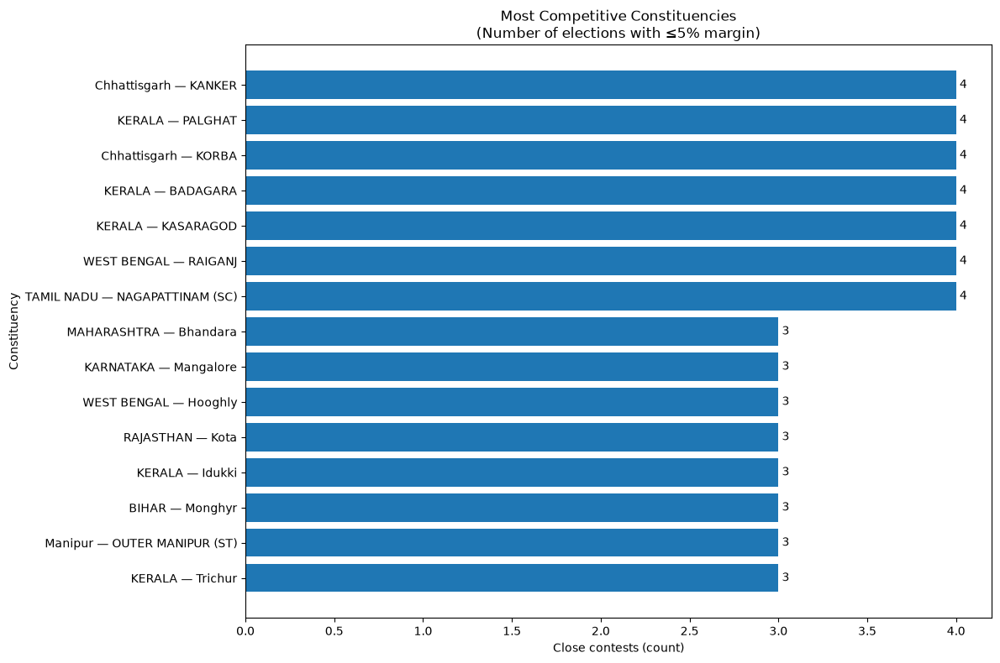

Chart saved to: outputs\constituency_analysis\13_most_competitive_constituencies.png


In [52]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Output folder for charts
output_dir = Path("outputs/constituency_analysis")
output_dir.mkdir(parents=True, exist_ok=True)

# Work on a copy
data = df.copy()

# Ensure numeric votes
data["VOTES"] = pd.to_numeric(data["VOTES"], errors="coerce")

# Identify constituency-election groups
group_cols = ["YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"]

# Sum candidate votes and rank candidates within each election/constituency
data["CONSTITUENCY_VOTE_TOTAL"] = data.groupby(group_cols)["VOTES"].transform("sum")

ranked = data.sort_values(
    group_cols + ["VOTES"],
    ascending=[True, True, True, True, False]
).copy()

ranked["VOTE_RANK"] = ranked.groupby(group_cols)["VOTES"].rank(
    method="first",
    ascending=False
)

# Winner and runner-up vote totals for each constituency-election
summary = (
    ranked[ranked["VOTE_RANK"].isin([1, 2])]
    .pivot_table(
        index=group_cols,
        columns="VOTE_RANK",
        values="VOTES",
        aggfunc="first"
    )
    .rename(columns={1: "WINNER_VOTES", 2: "RUNNER_UP_VOTES"})
    .reset_index()
)

summary = summary.merge(
    data[group_cols + ["CONSTITUENCY_VOTE_TOTAL"]].drop_duplicates(),
    on=group_cols,
    how="left"
)

summary["MARGIN_VOTES"] = (
    summary["WINNER_VOTES"] - summary["RUNNER_UP_VOTES"]
)

summary["MARGIN_PERCENT"] = (
    summary["MARGIN_VOTES"] / summary["CONSTITUENCY_VOTE_TOTAL"] * 100
)

# Define a close contest as a margin <= 5% of all candidate votes
summary["CLOSE_CONTEST"] = summary["MARGIN_PERCENT"] <= 5

# Aggregate across elections for each constituency
competitive = (
    summary.groupby(["STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"])
    .agg(
        ELECTIONS_ANALYZED=("YEAR", "nunique"),
        CLOSE_CONTESTS=("CLOSE_CONTEST", "sum"),
        AVG_MARGIN_PERCENT=("MARGIN_PERCENT", "mean"),
        MIN_MARGIN_PERCENT=("MARGIN_PERCENT", "min")
    )
    .reset_index()
)

competitive["CLOSE_CONTEST_SHARE"] = (
    competitive["CLOSE_CONTESTS"] / competitive["ELECTIONS_ANALYZED"] * 100
)

# Prioritize constituencies with many close contests;
# use close-contest share as a tie-breaker
competitive = competitive.sort_values(
    ["CLOSE_CONTESTS", "CLOSE_CONTEST_SHARE", "AVG_MARGIN_PERCENT"],
    ascending=[False, False, True]
)

print("Top 20 most competitive constituencies:")
display(competitive.head(20).round(2))

# Plot top 15
top15 = competitive.head(15).sort_values("CLOSE_CONTESTS")

fig, ax = plt.subplots(figsize=(12, 8))
labels = (
    top15["STATE UT"].astype(str) + " — " +
    top15["CONSTITUENCY NAME"].astype(str)
)

bars = ax.barh(labels, top15["CLOSE_CONTESTS"])
ax.bar_label(bars, fmt="%.0f", padding=3)

ax.set_title("Most Competitive Constituencies\n(Number of elections with ≤5% margin)")
ax.set_xlabel("Close contests (count)")
ax.set_ylabel("Constituency")
plt.tight_layout()

chart_path = output_dir / "13_most_competitive_constituencies.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {chart_path}")

Top 20 largest landslide victories by margin percentage:


,YEAR,STATE UT,CONSTITUENCY NO,CONSTITUENCY NAME,CANDIDATE_1,PARTY_1,VOTES_1,CANDIDATE_2,PARTY_2,VOTES_2,MARGIN_VOTES,MARGIN_PERCENT
468,1957,Bihar,32,SASARAM,RAMSUBHAG SINGH,INDIAN NATIONAL CONGRESS,177130.0,JAGJIWAN RAM (SC),INDIAN NATIONAL CONGRESS,0.0,177130.0,100.00
640,1957,Mysore,18,KOLAR,K. CHENGALARAYA REDDY,INDIAN NATIONAL CONGRESS,209542.0,DODDATHIMMIAH (SC),INDIAN NATIONAL CONGRESS,0.0,209542.0,100.00
103,1951,Hyderabad,3,Mahboobnagar,JANARDHAN REDDY,INDIAN NATIONAL CONGRESS,173926.0,P. RAMASWAMY,INDIAN NATIONAL CONGRESS,0.0,173926.0,100.00
366,1951,Vindhya Pradesh,1,Shahdol Sidhi,BHAGWAN DUTTA SHASTRI,SOCIALIST PARTY,62033.0,RANDAMAN SINGH,KISAN MAZDOOR PRAJA PARTY,0.0,62033.0,100.00
451,1957,Bihar,15,DARBHANGA,SHREE NARAYAN DASS,INDIAN NATIONAL CONGRESS,157710.0,RAMESHWAR SAHU (SC),INDIAN NATIONAL CONGRESS,0.0,157710.0,100.00
34,1951,Bihar,21,Muzaffarpur Cum,RAJESHWAR PATEL,INDIAN NATIONAL CONGRESS,152490.0,RAMESHWAR SAHU,INDIAN NATIONAL CONGRESS,0.0,152490.0,100.00
411,1957,Andhra Pradesh,17,CHITTOOR,M. ANANTHASAYANAM AYYANGAR,INDIAN NATIONAL CONGRESS,154817.0,M.V. GANGADHARASIVA (SC),INDIAN NATIONAL CONGRESS,0.0,154817.0,100.00
159,1951,Madras,5,Visahkapatnam,LANKA SUNDARAM,INDEPENDENT,140718.0,GAM MALLUDORA,INDEPENDENT,0.0,140718.0,100.00
428,1957,Assam,1,CACHAR,TEWARI DWARIKA NATH,INDIAN NATIONAL CONGRESS,219704.0,"LASKAR, NIBARAN CHANDRA (SC)",INDIAN NATIONAL CONGRESS,0.0,219704.0,100.00
60,1951,Bombay,3,Pancchmahals Cu,GANDHI MANEKLAL MAGANLAL,INDIAN NATIONAL CONGRESS,201891.0,PARMAR RUPAJEE BHAVJI,INDIAN NATIONAL CONGRESS,0.0,201891.0,100.00


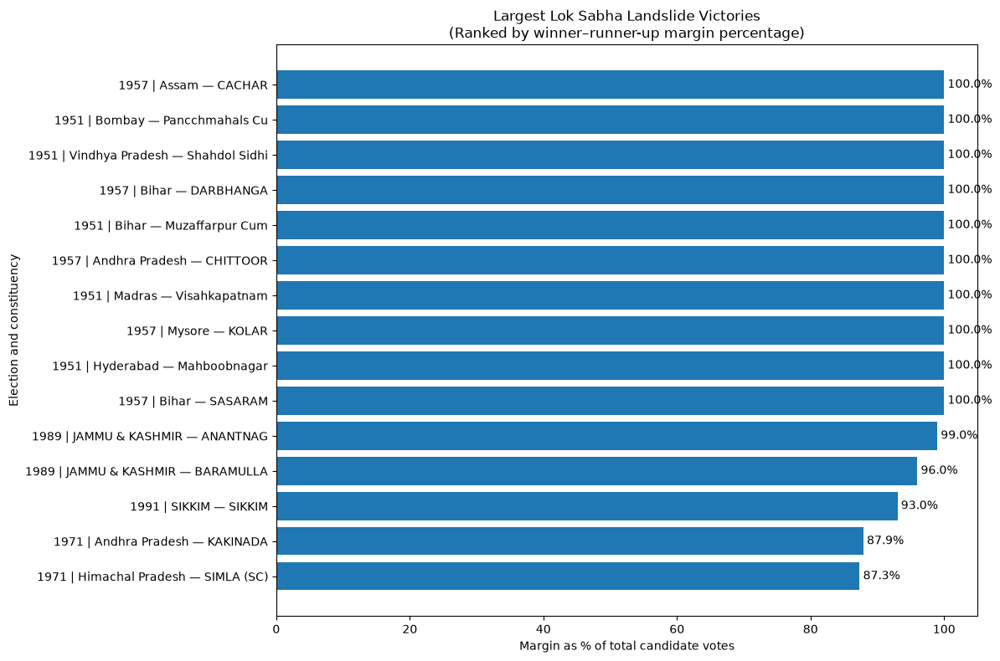

Chart saved to: outputs\constituency_analysis\14_largest_landslide_victories.png


In [53]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("outputs/constituency_analysis")
output_dir.mkdir(parents=True, exist_ok=True)

data = df.copy()
data["VOTES"] = pd.to_numeric(data["VOTES"], errors="coerce")

group_cols = ["YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"]

# Exclude rows without usable vote counts
data = data.dropna(subset=["VOTES"])

# Total candidate votes in each constituency-election
data["CONSTITUENCY_VOTE_TOTAL"] = data.groupby(group_cols)["VOTES"].transform("sum")

# Rank candidates by votes within each constituency-election
ranked = data.sort_values(
    group_cols + ["VOTES"],
    ascending=[True, True, True, True, False]
).copy()

ranked["VOTE_RANK"] = ranked.groupby(group_cols)["VOTES"].rank(
    method="first",
    ascending=False
)

# Get the top two candidates in each constituency-election
top_two = ranked[ranked["VOTE_RANK"].isin([1, 2])]

results = (
    top_two.pivot_table(
        index=group_cols,
        columns="VOTE_RANK",
        values=["CANDIDATE", "PARTY", "VOTES"],
        aggfunc="first"
    )
)

# Flatten the pivoted column names
results.columns = [f"{field}_{int(rank)}" for field, rank in results.columns]
results = results.reset_index()

# Add the constituency's total candidate votes
totals = data[group_cols + ["CONSTITUENCY_VOTE_TOTAL"]].drop_duplicates()
results = results.merge(totals, on=group_cols, how="left")

# Calculate winner-runner-up margins
results["MARGIN_VOTES"] = results["VOTES_1"] - results["VOTES_2"]
results["MARGIN_PERCENT"] = (
    results["MARGIN_VOTES"] / results["CONSTITUENCY_VOTE_TOTAL"] * 100
)

# Rank the biggest landslides by margin percentage
landslides = results.sort_values(
    "MARGIN_PERCENT",
    ascending=False
)

display_columns = [
    "YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME",
    "CANDIDATE_1", "PARTY_1", "VOTES_1",
    "CANDIDATE_2", "PARTY_2", "VOTES_2",
    "MARGIN_VOTES", "MARGIN_PERCENT"
]

print("Top 20 largest landslide victories by margin percentage:")
display(landslides[display_columns].head(20).round(2))

# Plot top 15
top15 = landslides.head(15).sort_values("MARGIN_PERCENT")

labels = (
    top15["YEAR"].astype(str) + " | " +
    top15["STATE UT"].astype(str) + " — " +
    top15["CONSTITUENCY NAME"].astype(str)
)

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(labels, top15["MARGIN_PERCENT"])
ax.bar_label(bars, fmt="%.1f%%", padding=3)

ax.set_title("Largest Lok Sabha Landslide Victories\n(Ranked by winner–runner-up margin percentage)")
ax.set_xlabel("Margin as % of total candidate votes")
ax.set_ylabel("Election and constituency")

plt.tight_layout()

chart_path = output_dir / "14_largest_landslide_victories.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {chart_path}")

Constituencies with the most recorded election years:


,STATE UT,CONSTITUENCY NO,CONSTITUENCY NAME,ELECTIONS_RECORDED,FIRST_YEAR,LAST_YEAR,MEAN_TURNOUT,MIN_TURNOUT,MAX_TURNOUT
1462,LAKSHADWEEP,1,LAKSHADWEEP (ST),6,1977,2004,84.55,80.37,88.78
3729,WEST BENGAL,29,PANSKURA,6,1977,2004,82.04,71.78,85.70
3731,WEST BENGAL,30,TAMLUK,6,1977,2004,81.26,69.84,87.35
3727,WEST BENGAL,28,ARAMBAGH,6,1977,2004,80.82,68.66,85.96
3667,WEST BENGAL,1,COOCH BEHAR (SC),6,1977,2004,79.51,63.78,86.38
3686,WEST BENGAL,9,MURSHIDABAD,6,1977,2004,79.25,61.96,84.86
1320,KERALA,2,CANNANORE,6,1977,2004,79.16,70.52,83.14
3690,WEST BENGAL,11,KRISHNAGAR,6,1977,2004,78.96,61.96,83.74
3697,WEST BENGAL,14,BASIRHAT,6,1977,2004,78.94,60.17,86.31
3702,WEST BENGAL,16,MATHURAPUR (SC),6,1977,2004,78.74,66.04,84.51


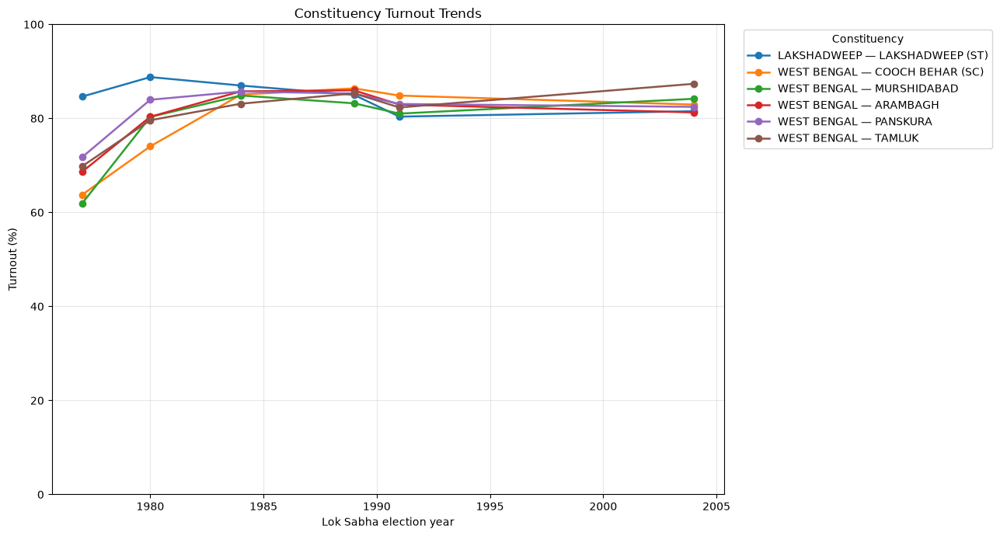

Chart saved to: outputs\constituency_analysis\15_constituency_turnout_trends.png


In [54]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("outputs/constituency_analysis")
output_dir.mkdir(parents=True, exist_ok=True)

data = df.copy()

# Convert turnout inputs to numeric
for col in ["TOTAL ELECTORS", "TOTAL VOTED"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Keep one row per constituency-election for turnout analysis
group_cols = ["YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"]

turnout = (
    data.groupby(group_cols, as_index=False)
    .agg(
        TOTAL_ELECTORS=("TOTAL ELECTORS", "first"),
        TOTAL_VOTED=("TOTAL VOTED", "first")
    )
)

# Calculate turnout percentage
turnout["TURNOUT_PERCENT"] = (
    turnout["TOTAL_VOTED"] / turnout["TOTAL_ELECTORS"] * 100
)

# Remove impossible or unavailable turnout values
turnout = turnout[
    turnout["TOTAL_ELECTORS"].gt(0) &
    turnout["TOTAL_VOTED"].ge(0) &
    turnout["TURNOUT_PERCENT"].between(0, 100)
].copy()

# Constituencies with the most recorded election years
history = (
    turnout.groupby(["STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"])
    .agg(
        ELECTIONS_RECORDED=("YEAR", "nunique"),
        FIRST_YEAR=("YEAR", "min"),
        LAST_YEAR=("YEAR", "max"),
        MEAN_TURNOUT=("TURNOUT_PERCENT", "mean"),
        MIN_TURNOUT=("TURNOUT_PERCENT", "min"),
        MAX_TURNOUT=("TURNOUT_PERCENT", "max")
    )
    .reset_index()
    .sort_values(
        ["ELECTIONS_RECORDED", "MEAN_TURNOUT"],
        ascending=[False, False]
    )
)

print("Constituencies with the most recorded election years:")
display(history.head(30).round(2))

# Choose up to 6 constituencies from the top of the history table.
# You can replace these with constituencies of your own interest.
selected = history.head(6)[
    ["STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"]
]

plot_data = turnout.merge(
    selected,
    on=["STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"],
    how="inner"
)

fig, ax = plt.subplots(figsize=(13, 7))

for (state, constituency_no, constituency_name), group in plot_data.groupby(
    ["STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"]
):
    group = group.sort_values("YEAR")
    label = f"{state} — {constituency_name}"
    ax.plot(
        group["YEAR"],
        group["TURNOUT_PERCENT"],
        marker="o",
        linewidth=1.8,
        label=label
    )

ax.set_title("Constituency Turnout Trends")
ax.set_xlabel("Lok Sabha election year")
ax.set_ylabel("Turnout (%)")
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)
ax.legend(title="Constituency", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()

chart_path = output_dir / "15_constituency_turnout_trends.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {chart_path}")

Winner history for all constituencies:


,YEAR,STATE UT,CONSTITUENCY NO,CONSTITUENCY NAME,CANDIDATE,PARTY,VOTES
4596,1971,A And N Islands,1,A AND N ISLANDS,K .R. GANESH,INDIAN NATIONAL CONGRESS,27373
10950,1996,ANDAMAN & NICOB,1,Andaman & Nicobar I,MANORANJAN BHAKTA,INDIAN NATIONAL CONGRESS,74642
12036,1998,ANDAMAN & NICOB,1,Andaman & Nicobar I,MANORANJAN BHAKTA,INDIAN NATIONAL CONGRESS,52365
13122,1999,ANDAMAN & NICOB,1,Andaman & Nicobar I,BISHNU PADA RAY,BHARATIYA JANTA PARTY,76891
14208,2004,ANDAMAN & NICOBAR ISLAND,1,ANDAMAN & NICOBAR ISLAND,MANORANJAN BHAKTA,INDIAN NATIONAL CONGRESS,85794
5686,1977,ANDAMAN & NICOBAR ISLANDS,1,ANDAMAN & NICOBAR ISLANDS,MANORANJAN BHAKTA,INDIAN NATIONAL CONGRESS,35400
6742,1980,ANDAMAN & NICOBAR ISLANDS,1,ANDAMAN & NICOBAR ISLANDS,MANORANJAN BHAKTA,INDIAN NATIOANL CONGRESS (I),42046
7770,1984,ANDAMAN & NICOBAR ISLANDS,1,ANDAMAN & NICOBAR ISLANDS,MANORANJAN BHAKTA,INDIAN NATIONAL CONGRESS,47019
8824,1989,ANDAMAN & NICOBAR ISLANDS,1,ANDAMAN & NICOBAR ISLANDS,MANORANJAN BHAKTA,INDIAN NATIONAL CONGRESS,53383
9864,1991,ANDAMAN & NICOBAR ISLANDS,1,ANDAMAN & NICOBAR ISLANDS,MANORANJAN BHAKTA,INDIAN NATIONAL CONGRESS,54075


,STATE UT,CONSTITUENCY NO,CONSTITUENCY NAME
0,A And N Islands,1,A AND N ISLANDS
1,ANDAMAN & NICOB,1,Andaman & Nicobar I
2,ANDAMAN & NICOBAR ISLAND,1,ANDAMAN & NICOBAR ISLAND
3,ANDAMAN & NICOBAR ISLANDS,1,ANDAMAN & NICOBAR ISLANDS
4,ANDHRA PRADESH,35,ADILABAD
5,ANDHRA PRADESH,9,AMALAPURAM (SC)
6,ANDHRA PRADESH,6,ANAKAPALLI
7,ANDHRA PRADESH,25,ANANTAPUR
8,ANDHRA PRADESH,35,Adilabad
9,ANDHRA PRADESH,9,Amalapuram


Winner history: Chennai North, Tamil Nadu


,YEAR,CANDIDATE,PARTY,VOTES
0,2009,Elangovan T.K.S,DRAVIDA MUNETRA KAZHAGAM,281055
1,2014,Venkatesh Babu .T.G,ALL INDIA ANNA DRAVIDA MUNNETRA KAZHAGAM,406704
2,2019,Dr. KALANIDHI VEERASWAMY,DRAVIDA MUNETRA KAZHAGAM,590986


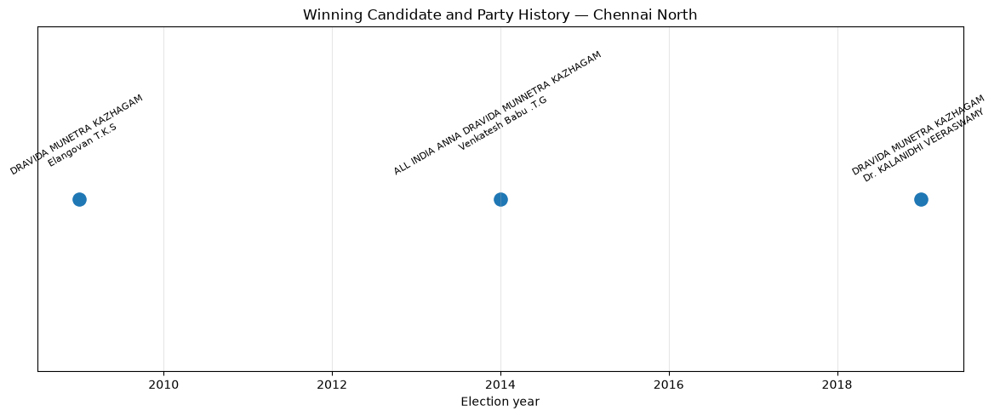

Chart saved to: outputs\constituency_analysis\16_constituency_winner_history.png


In [55]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("outputs/constituency_analysis")
output_dir.mkdir(parents=True, exist_ok=True)

data = df.copy()
data["VOTES"] = pd.to_numeric(data["VOTES"], errors="coerce")

group_cols = ["YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"]

# Rank candidates by votes within each constituency-election
ranked = data.dropna(subset=["VOTES"]).sort_values(
    group_cols + ["VOTES"],
    ascending=[True, True, True, True, False]
).copy()

ranked["VOTE_RANK"] = ranked.groupby(group_cols)["VOTES"].rank(
    method="first",
    ascending=False
)

# Candidate with the highest vote total is treated as the winner
winners = ranked[ranked["VOTE_RANK"] == 1].copy()

winner_history = winners[
    group_cols + ["CANDIDATE", "PARTY", "VOTES"]
].sort_values(["STATE UT", "CONSTITUENCY NO", "YEAR"])

print("Winner history for all constituencies:")
display(winner_history.head(30))

# List constituencies so you can choose one
constituencies = (
    winner_history[["STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"]]
    .drop_duplicates()
    .sort_values(["STATE UT", "CONSTITUENCY NAME"])
    .reset_index(drop=True)
)

display(constituencies.head(50))

# ---- Select a constituency here ----
# Replace these values with the state and constituency name you want.
selected_state = "Tamil Nadu"
selected_constituency = "Chennai North"

seat_history = winner_history[
    (winner_history["STATE UT"] == selected_state) &
    (winner_history["CONSTITUENCY NAME"] == selected_constituency)
].sort_values("YEAR")

if seat_history.empty:
    print("No matching constituency found. Check the displayed constituency list and spelling.")
else:
    print(f"Winner history: {selected_constituency}, {selected_state}")
    display(
        seat_history[
            ["YEAR", "CANDIDATE", "PARTY", "VOTES"]
        ].reset_index(drop=True)
    )

    # Plot winning party labels across years
    fig, ax = plt.subplots(figsize=(12, 5))

    party_labels = seat_history["PARTY"].fillna("Unknown").astype(str)
    ax.scatter(
        seat_history["YEAR"],
        [1] * len(seat_history),
        s=120
    )

    for _, row in seat_history.iterrows():
        label = f"{row['PARTY']}\n{row['CANDIDATE']}"
        ax.annotate(
            label,
            (row["YEAR"], 1),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            rotation=30
        )

    ax.set_title(f"Winning Candidate and Party History — {selected_constituency}")
    ax.set_xlabel("Election year")
    ax.set_yticks([])
    ax.grid(axis="x", alpha=0.3)

    plt.tight_layout()

    chart_path = output_dir / "16_constituency_winner_history.png"
    plt.savefig(chart_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Chart saved to: {chart_path}")

Candidates who won the same constituency in 2 or more distinct election years:


,STATE UT,CONSTITUENCY NO,CONSTITUENCY NAME,CANDIDATE,YEARS_WON,FIRST_WIN,LAST_WIN,ELECTION_YEARS
4,ANDAMAN & NICOBAR ISLANDS,1,ANDAMAN & NICOBAR ISLANDS,MANORANJAN BHAKTA,5,1977,1991,"[1977, 1980, 1984, 1989, 1991]"
3890,MAHARASHTRA,38,PANDHARPUR (SC),THORAT SANDIPAN BHAGWAN,5,1977,1991,"[1977, 1980, 1984, 1989, 1991]"
5083,ORISSA,13,NOWRANGPUR (ST),KHAGAPATI PRADHANI,5,1977,1991,"[1977, 1980, 1984, 1989, 1991]"
165,ANDHRA PRADESH,20,TIRUPATHI (SC),CHINTA MOHAN,4,1984,2004,"[1984, 1989, 1991, 2004]"
908,BIHAR,8,HAJIPUR (SC),RAM VILAS PASWAN,4,1977,2004,"[1977, 1980, 1989, 2004]"
2114,GUJARAT,25,MANDVI (ST),GAMIT CHHITUBHAI DEVJIBHAI,4,1977,1991,"[1977, 1980, 1984, 1991]"
3502,MADHYA PRADESH,27,CHHINDWARA,KAMAL NATH,4,1980,1991,"[1980, 1984, 1989, 1991]"
5017,ORISSA,4,JAJPUR (SC),ANADI CHARAN DAS,4,1980,1991,"[1980, 1984, 1989, 1991]"
6092,TAMIL NADU,15,RASIPURAM (SC),DEVARAJAN B.,4,1977,1991,"[1977, 1980, 1984, 1991]"
6708,UTTAR PRADESH,18,MISRIKH (SC),RAM LAL RAHI,4,1977,1991,"[1977, 1980, 1989, 1991]"


Parties that won the same constituency in 2 or more distinct election years:


,STATE UT,CONSTITUENCY NO,CONSTITUENCY NAME,PARTY,YEARS_WON,FIRST_WIN,LAST_WIN,ELECTION_YEARS
2264,KERALA,6,PONNANI,MUSLIM LEAGE,6,1977,2004,"[1977, 1980, 1984, 1989, 1991, 2004]"
6227,WEST BENGAL,2,ALIPURDUARS (ST),REVOLUTIONARY SOCIALIST PARTY,6,1977,2004,"[1977, 1980, 1984, 1989, 1991, 2004]"
6243,WEST BENGAL,6,BALURGHAT (SC),REVOLUTIONARY SOCIALIST PARTY,6,1977,2004,"[1977, 1980, 1984, 1989, 1991, 2004]"
6380,WEST BENGAL,42,BIRBHUM (SC),CUMMUNIST PARTY OF INDIA (MARXIST),6,1977,2004,"[1977, 1980, 1984, 1989, 1991, 2004]"
6378,WEST BENGAL,41,BOLPUR,CUMMUNIST PARTY OF INDIA (MARXIST),6,1977,2004,"[1977, 1980, 1984, 1989, 1991, 2004]"
6285,WEST BENGAL,17,DIAMOND HARBOUR,CUMMUNIST PARTY OF INDIA (MARXIST),6,1977,2004,"[1977, 1980, 1984, 1989, 1991, 2004]"
6365,WEST BENGAL,37,DURGAPUR (SC),CUMMUNIST PARTY OF INDIA (MARXIST),6,1977,2004,"[1977, 1980, 1984, 1989, 1991, 2004]"
6353,WEST BENGAL,33,JHARGRAM (ST),CUMMUNIST PARTY OF INDIA (MARXIST),6,1977,2004,"[1977, 1980, 1984, 1989, 1991, 2004]"
6262,WEST BENGAL,11,KRISHNAGAR,CUMMUNIST PARTY OF INDIA (MARXIST),6,1977,2004,"[1977, 1980, 1984, 1989, 1991, 2004]"
6265,WEST BENGAL,12,NABADWIP (SC),CUMMUNIST PARTY OF INDIA (MARXIST),6,1977,2004,"[1977, 1980, 1984, 1989, 1991, 2004]"


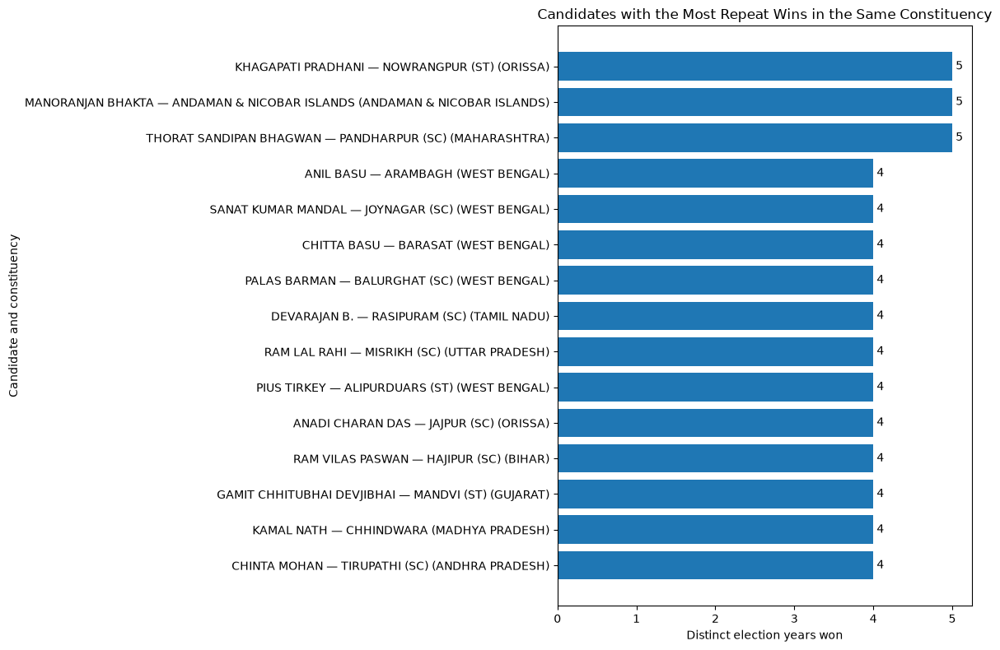

Candidate chart saved to: outputs\constituency_analysis\17a_repeated_candidate_winners.png


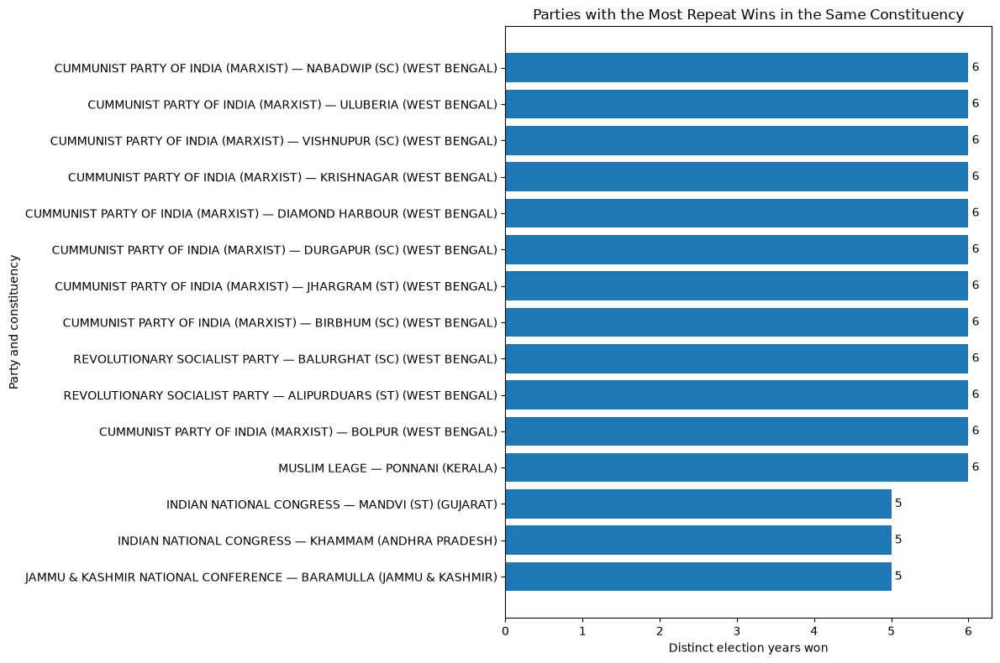

Party chart saved to: outputs\constituency_analysis\17b_repeated_party_winners.png


In [56]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("outputs/constituency_analysis")
output_dir.mkdir(parents=True, exist_ok=True)

data = df.copy()

# Normalize winner labels while preserving multi-winner labels
result_labels = (
    data["RESULT POSITION"]
    .astype("string")
    .str.strip()
    .str.lower()
)

is_winner = result_labels.str.match(
    r"^winner(?:\s+\d+)?$",
    na=False
)

winners = data.loc[is_winner].copy()

# Count distinct election years won by each candidate in the same constituency
seat_cols = ["STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"]

candidate_wins = (
    winners.groupby(seat_cols + ["CANDIDATE"], dropna=False)
    .agg(
        YEARS_WON=("YEAR", "nunique"),
        FIRST_WIN=("YEAR", "min"),
        LAST_WIN=("YEAR", "max"),
        ELECTION_YEARS=("YEAR", lambda x: sorted(x.dropna().unique()))
    )
    .reset_index()
)

repeated_candidates = (
    candidate_wins[candidate_wins["YEARS_WON"] >= 2]
    .sort_values(
        ["YEARS_WON", "STATE UT", "CONSTITUENCY NAME"],
        ascending=[False, True, True]
    )
)

print("Candidates who won the same constituency in 2 or more distinct election years:")
display(repeated_candidates.head(50))


# Count distinct election years won by each party in the same constituency
party_wins = (
    winners.dropna(subset=["PARTY"])
    .groupby(seat_cols + ["PARTY"])
    .agg(
        YEARS_WON=("YEAR", "nunique"),
        FIRST_WIN=("YEAR", "min"),
        LAST_WIN=("YEAR", "max"),
        ELECTION_YEARS=("YEAR", lambda x: sorted(x.dropna().unique()))
    )
    .reset_index()
)

repeated_parties = (
    party_wins[party_wins["YEARS_WON"] >= 2]
    .sort_values(
        ["YEARS_WON", "STATE UT", "CONSTITUENCY NAME"],
        ascending=[False, True, True]
    )
)

print("Parties that won the same constituency in 2 or more distinct election years:")
display(repeated_parties.head(50))


# ---- Chart: candidates with the most repeat wins ----
top_candidates = repeated_candidates.head(15).copy()

if not top_candidates.empty:
    top_candidates["LABEL"] = (
        top_candidates["CANDIDATE"].astype(str)
        + " — "
        + top_candidates["CONSTITUENCY NAME"].astype(str)
        + " ("
        + top_candidates["STATE UT"].astype(str)
        + ")"
    )

    top_candidates = top_candidates.sort_values("YEARS_WON")

    fig, ax = plt.subplots(figsize=(12, 8))
    bars = ax.barh(top_candidates["LABEL"], top_candidates["YEARS_WON"])
    ax.bar_label(bars, fmt="%.0f", padding=3)

    ax.set_title("Candidates with the Most Repeat Wins in the Same Constituency")
    ax.set_xlabel("Distinct election years won")
    ax.set_ylabel("Candidate and constituency")

    plt.tight_layout()
    candidate_chart = output_dir / "17a_repeated_candidate_winners.png"
    plt.savefig(candidate_chart, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Candidate chart saved to: {candidate_chart}")
else:
    print("No candidate has 2 or more recorded winning election years in the same constituency.")


# ---- Chart: parties with the most repeat wins in the same constituency ----
top_parties = repeated_parties.head(15).copy()

if not top_parties.empty:
    top_parties["LABEL"] = (
        top_parties["PARTY"].astype(str)
        + " — "
        + top_parties["CONSTITUENCY NAME"].astype(str)
        + " ("
        + top_parties["STATE UT"].astype(str)
        + ")"
    )

    top_parties = top_parties.sort_values("YEARS_WON")

    fig, ax = plt.subplots(figsize=(12, 8))
    bars = ax.barh(top_parties["LABEL"], top_parties["YEARS_WON"])
    ax.bar_label(bars, fmt="%.0f", padding=3)

    ax.set_title("Parties with the Most Repeat Wins in the Same Constituency")
    ax.set_xlabel("Distinct election years won")
    ax.set_ylabel("Party and constituency")

    plt.tight_layout()
    party_chart = output_dir / "17b_repeated_party_winners.png"
    plt.savefig(party_chart, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Party chart saved to: {party_chart}")
else:
    print("No party has 2 or more recorded winning election years in the same constituency.")

20 closest winner–runner-up comparisons:


,YEAR,STATE UT,CONSTITUENCY NAME,CANDIDATE_WINNER,PARTY_WINNER,VOTES_WINNER,CANDIDATE_RUNNER_UP,PARTY_RUNNER_UP,VOTES_RUNNER_UP,MARGIN_VOTES
0,1989,ANDHRA PRADESH,ANAKAPALLI,KONATHALA RAMAKRISHNA,INDIAN NATIONAL CONGRESS,299109,APPALANARASIMHAM,TELUGU DESAM,299100,9
1,1998,BIHAR,Rajmahal (ST),SOM MARANDI,BHARATIYA JANTA PARTY,198889,THOMAS HANSDA,INDIAN NATIONAL CONGRESS,198880,9
2,1996,GUJARAT,Baroda,GAEKWAD SATYAJITSINH DILIPSINH,INDIAN NATIONAL CONGRESS,131248,JITENDRA RATILAL SUKHADIA (JITUBHAI),BHARATIYA JANTA PARTY,131231,17
3,1971,Tamil Nadu,TIRUCHENDUR,M. S. SIVASAMY,DRAVIDA MUNETRA KAZHAGAM,202783,M. MATHIAS,SWATANTRA,202757,26
4,2014,Jammu and Kashmir,Ladakh,Thupstan Chhewang,BHARATIYA JANTA PARTY,31111,Ghulam Raza,INDEPENDENT,31075,36
5,1998,MIZORAM,Mizoram (ST),DR. H. LALLUNGMUANA,INDEPENDENT,106552,J. LALSANGZUALA,INDIAN NATIONAL CONGRESS,106511,41
6,1962,Manipur,Outer Manipur,RISHANG,SOCIALIST,35621,SIBO LARHO,INDIAN NATIONAL CONGRESS,35579,42
7,1957,Andhra Pradesh,GOLUGONDA,MISSULA SURYANARAYANA MURTHY,INDIAN NATIONAL CONGRESS,84780,KANKIPATI VEERANNA PADAL (ST),INDIAN NATIONAL CONGRESS,84738,42
8,2024,Maharashtra,Mumbai North West,RAVINDRA DATTARAM WAIKAR,SHIVA SENA,452644,AMOL GAJANAN KIRTIKAR,Shiv Sena (Uddhav Balasaheb Thackrey),452596,48
9,1957,Madras,CUDDALORE,T. D. MUTHUKUMARASAMY NAIDU,INDEPENDENT,98605,S. RADHAKRISHNAN,INDIAN NATIONAL CONGRESS,98546,59


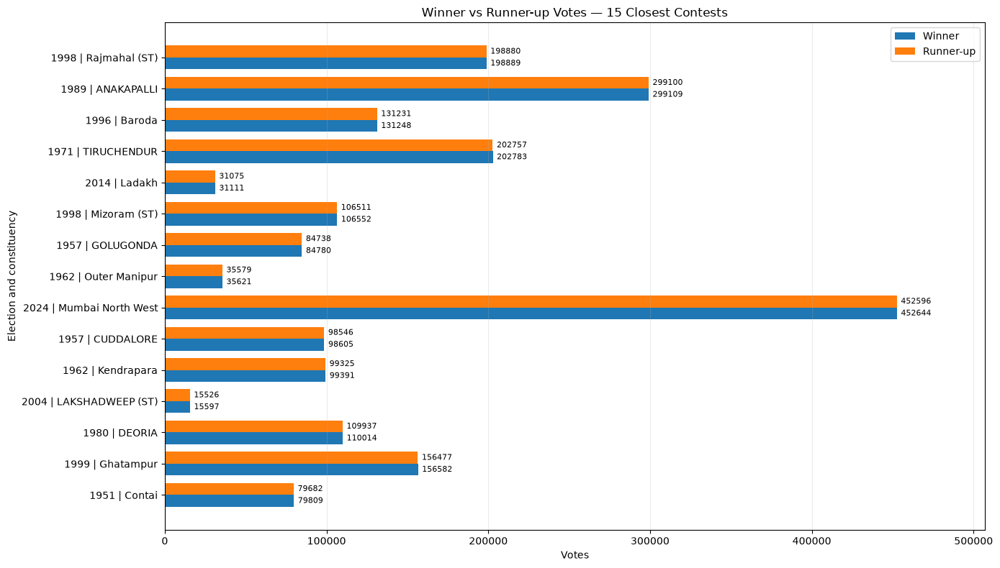

Chart saved to: outputs\constituency_analysis\18_winner_runner_up_vote_comparison.png


In [57]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("outputs/constituency_analysis")
output_dir.mkdir(parents=True, exist_ok=True)

data = df.copy()
data["VOTES"] = pd.to_numeric(data["VOTES"], errors="coerce")
data = data.dropna(subset=["VOTES"])

group_cols = ["YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"]

# Sort candidates by vote total within each constituency-election
ranked = data.sort_values(
    group_cols + ["VOTES"],
    ascending=[True, True, True, True, False],
    kind="mergesort"
).copy()

# Assign first and second place
ranked["VOTE_RANK"] = ranked.groupby(group_cols).cumcount() + 1

top_two = ranked[ranked["VOTE_RANK"].isin([1, 2])]

# Put winner and runner-up details on one row per constituency-election
comparison = (
    top_two.pivot(
        index=group_cols,
        columns="VOTE_RANK",
        values=["CANDIDATE", "PARTY", "VOTES"]
    )
)

comparison.columns = [
    f"{field}_{'WINNER' if rank == 1 else 'RUNNER_UP'}"
    for field, rank in comparison.columns
]
comparison = comparison.reset_index()

comparison["MARGIN_VOTES"] = (
    comparison["VOTES_WINNER"] - comparison["VOTES_RUNNER_UP"]
)

# Closest contests first
comparison = comparison.sort_values("MARGIN_VOTES")

columns_to_show = [
    "YEAR", "STATE UT", "CONSTITUENCY NAME",
    "CANDIDATE_WINNER", "PARTY_WINNER", "VOTES_WINNER",
    "CANDIDATE_RUNNER_UP", "PARTY_RUNNER_UP", "VOTES_RUNNER_UP",
    "MARGIN_VOTES"
]

print("20 closest winner–runner-up comparisons:")
display(comparison[columns_to_show].head(20).reset_index(drop=True))

# Plot the 15 closest contests
plot_data = comparison.head(15).copy()
plot_data = plot_data.sort_values("MARGIN_VOTES", ascending=False)

plot_data["LABEL"] = (
    plot_data["YEAR"].astype(str) + " | " +
    plot_data["CONSTITUENCY NAME"].astype(str)
)

fig, ax = plt.subplots(figsize=(14, 8))

positions = range(len(plot_data))
bar_height = 0.38

winner_bars = ax.barh(
    [p - bar_height / 2 for p in positions],
    plot_data["VOTES_WINNER"],
    height=bar_height,
    label="Winner"
)

runner_bars = ax.barh(
    [p + bar_height / 2 for p in positions],
    plot_data["VOTES_RUNNER_UP"],
    height=bar_height,
    label="Runner-up"
)

# Add the actual vote numbers at the ends of the bars
ax.bar_label(winner_bars, fmt="%.0f", padding=4, fontsize=8)
ax.bar_label(runner_bars, fmt="%.0f", padding=4, fontsize=8)

ax.set_yticks(list(positions))
ax.set_yticklabels(plot_data["LABEL"])
ax.set_title("Winner vs Runner-up Votes — 15 Closest Contests")
ax.set_xlabel("Votes")
ax.set_ylabel("Election and constituency")
ax.legend()
ax.grid(axis="x", alpha=0.25)

# Leave room on the right for the numeric labels
max_votes = plot_data[["VOTES_WINNER", "VOTES_RUNNER_UP"]].max().max()
ax.set_xlim(0, max_votes * 1.12)

plt.tight_layout()

chart_path = output_dir / "18_winner_runner_up_vote_comparison.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {chart_path}")

Top 20 contests by margin in votes:


,YEAR,STATE UT,CONSTITUENCY NAME,MARGIN_VOTES,MARGIN_PERCENT
0,2024,Assam,Dhubri,1012476.0,52.42
1,2024,Madhya Pradesh,INDORE,1008077.0,69.74
2,2024,Madhya Pradesh,VIDISHA,821408.0,58.19
3,2024,Gujarat,Navsari,773551.0,60.03
4,2024,Gujarat,Gandhinagar,744716.0,58.31
5,2024,West Bengal,Diamond harbour,710930.0,51.31
6,2019,Gujarat,Navsari,689668.0,54.92
7,2019,Haryana,Karnal,656142.0,56.22
8,2019,Haryana,Faridabad,638239.0,53.71
9,2019,Rajasthan,Bhilwara,612000.0,48.41


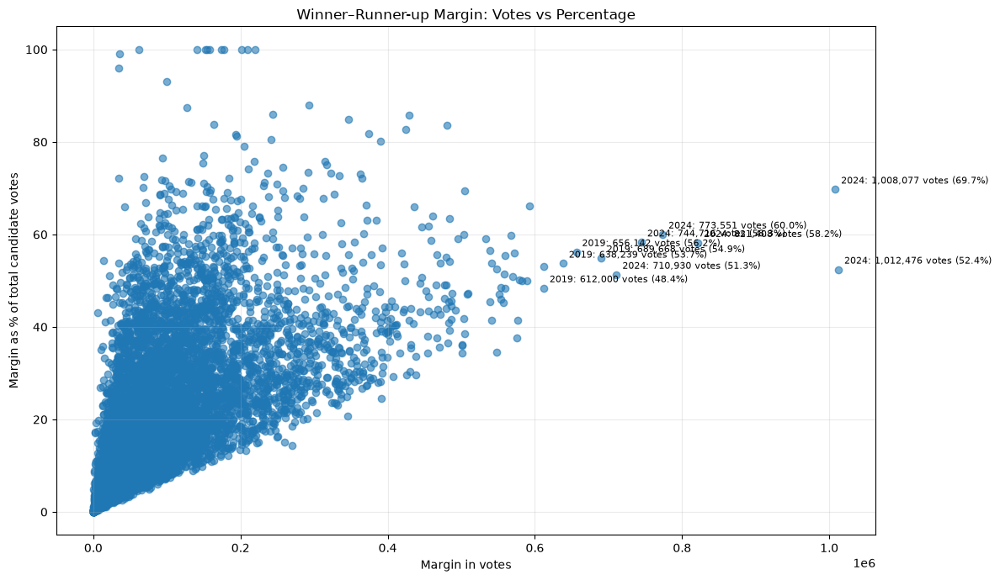

Chart saved to: outputs\constituency_analysis\19_margin_percentage_vs_margin_votes.png


In [58]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("outputs/constituency_analysis")
output_dir.mkdir(parents=True, exist_ok=True)

data = df.copy()
data["VOTES"] = pd.to_numeric(data["VOTES"], errors="coerce")
data = data.dropna(subset=["VOTES"])

group_cols = ["YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"]

# Total votes received by all candidates in each constituency-election
data["CONSTITUENCY_VOTE_TOTAL"] = data.groupby(group_cols)["VOTES"].transform("sum")

# Rank candidates by votes within each constituency-election
ranked = data.sort_values(
    group_cols + ["VOTES"],
    ascending=[True, True, True, True, False],
    kind="mergesort"
).copy()

ranked["VOTE_RANK"] = ranked.groupby(group_cols).cumcount() + 1

# Keep winner and runner-up
top_two = ranked[ranked["VOTE_RANK"].isin([1, 2])]

comparison = (
    top_two.pivot(
        index=group_cols,
        columns="VOTE_RANK",
        values="VOTES"
    )
    .rename(columns={1: "WINNER_VOTES", 2: "RUNNER_UP_VOTES"})
    .reset_index()
)

# Add total candidate votes for the denominator
totals = data[group_cols + ["CONSTITUENCY_VOTE_TOTAL"]].drop_duplicates()

comparison = comparison.merge(
    totals,
    on=group_cols,
    how="left"
)

# Calculate both margin measures
comparison["MARGIN_VOTES"] = (
    comparison["WINNER_VOTES"] - comparison["RUNNER_UP_VOTES"]
)

comparison["MARGIN_PERCENT"] = (
    comparison["MARGIN_VOTES"]
    / comparison["CONSTITUENCY_VOTE_TOTAL"]
    * 100
)

comparison = comparison.dropna(subset=["MARGIN_VOTES", "MARGIN_PERCENT"])

# Show the largest margins in raw votes
print("Top 20 contests by margin in votes:")
display(
    comparison.sort_values("MARGIN_VOTES", ascending=False)
    [[
        "YEAR", "STATE UT", "CONSTITUENCY NAME",
        "MARGIN_VOTES", "MARGIN_PERCENT"
    ]]
    .head(20)
    .round(2)
    .reset_index(drop=True)
)

# Scatter plot: each point is one constituency-election
fig, ax = plt.subplots(figsize=(12, 7))

ax.scatter(
    comparison["MARGIN_VOTES"],
    comparison["MARGIN_PERCENT"],
    alpha=0.6
)

# Label the 10 largest margins in raw votes
label_points = comparison.nlargest(10, "MARGIN_VOTES")

for _, row in label_points.iterrows():
    label = (
        f"{int(row['YEAR'])}: "
        f"{row['MARGIN_VOTES']:,.0f} votes "
        f"({row['MARGIN_PERCENT']:.1f}%)"
    )

    ax.annotate(
        label,
        (row["MARGIN_VOTES"], row["MARGIN_PERCENT"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title("Winner–Runner-up Margin: Votes vs Percentage")
ax.set_xlabel("Margin in votes")
ax.set_ylabel("Margin as % of total candidate votes")
ax.grid(True, alpha=0.25)

plt.tight_layout()

chart_path = output_dir / "19_margin_percentage_vs_margin_votes.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {chart_path}")

## 6. State and regional analyses



State-wise turnout summary:


,STATE UT,ELECTIONS_RECORDED,AVERAGE_TURNOUT,LOWEST_TURNOUT,HIGHEST_TURNOUT
4,ANDHRA PRADESH,9,65.37,56.93,70.43
14,Assam,9,66.06,50.69,81.87
15,BIHAR,9,59.50,51.87,64.60
19,CHANDIGARH,9,59.48,48.35,68.93
48,Himachal Pradesh,9,54.51,35.55,72.35
...,...,...,...,...,...
81,NATIONAL CAPITAL TERRITOR,1,47.09,47.09,47.09
104,Travancore Cochin,1,82.90,82.90,82.90
98,Saurashtra,1,49.41,49.41,49.41
107,UTTARANCHAL,1,48.07,48.07,48.07


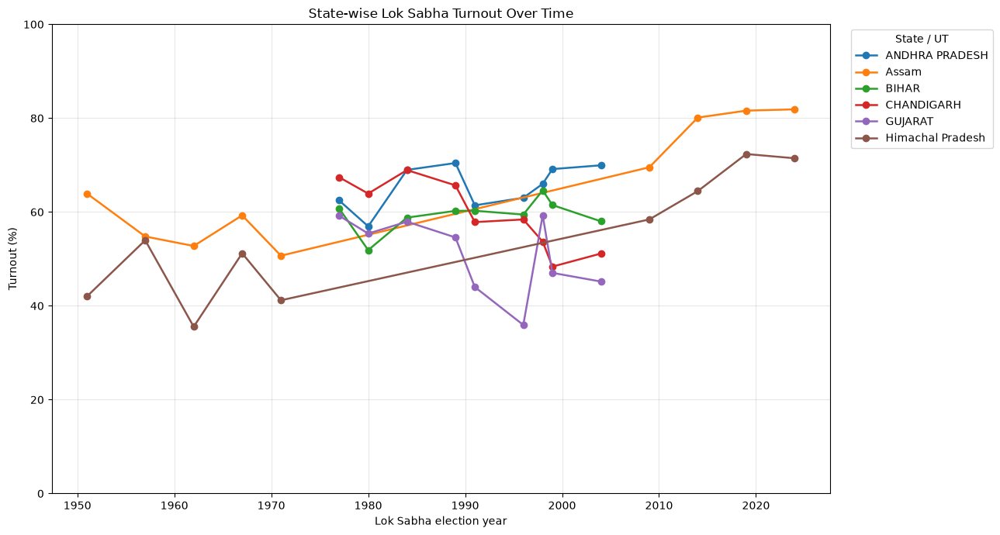

Chart saved to: outputs\state_regional_analysis\20_state_wise_turnout_over_time.png


In [59]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Folder for saved charts
output_dir = Path("outputs/state_regional_analysis")
output_dir.mkdir(parents=True, exist_ok=True)

data = df.copy()

# Convert required columns to numeric
for col in ["TOTAL ELECTORS", "TOTAL VOTED"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# One row per constituency per election.
# Elector and voted totals may be repeated across candidate rows.
constituency_cols = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

constituency_totals = (
    data.groupby(constituency_cols, as_index=False)
    .agg(
        TOTAL_ELECTORS=("TOTAL ELECTORS", "first"),
        TOTAL_VOTED=("TOTAL VOTED", "first")
    )
)

# Aggregate constituency totals to state/UT totals for each election
state_turnout = (
    constituency_totals.groupby(["YEAR", "STATE UT"], as_index=False)
    .agg(
        STATE_ELECTORS=("TOTAL_ELECTORS", "sum"),
        STATE_VOTES_CAST=("TOTAL_VOTED", "sum"),
        CONSTITUENCIES=("CONSTITUENCY NAME", "nunique")
    )
)

# Calculate turnout percentage
state_turnout["TURNOUT_PERCENT"] = (
    state_turnout["STATE_VOTES_CAST"]
    / state_turnout["STATE_ELECTORS"]
    * 100
)

# Keep valid turnout values
state_turnout = state_turnout[
    state_turnout["STATE_ELECTORS"].gt(0)
    & state_turnout["TURNOUT_PERCENT"].between(0, 100)
].copy()

# State/UT summary
state_summary = (
    state_turnout.groupby("STATE UT")
    .agg(
        ELECTIONS_RECORDED=("YEAR", "nunique"),
        AVERAGE_TURNOUT=("TURNOUT_PERCENT", "mean"),
        LOWEST_TURNOUT=("TURNOUT_PERCENT", "min"),
        HIGHEST_TURNOUT=("TURNOUT_PERCENT", "max")
    )
    .reset_index()
    .sort_values("ELECTIONS_RECORDED", ascending=False)
)

print("State-wise turnout summary:")
display(state_summary.round(2))

# Select up to 6 states/UTs with the most recorded election years
selected_states = state_summary.head(6)["STATE UT"].tolist()

# To choose states manually instead, replace the line above, for example:
# selected_states = ["Tamil Nadu", "Kerala", "Karnataka", "Andhra Pradesh"]

plot_data = state_turnout[
    state_turnout["STATE UT"].isin(selected_states)
].copy()

# Plot turnout trends
fig, ax = plt.subplots(figsize=(13, 7))

for state, group in plot_data.groupby("STATE UT"):
    group = group.sort_values("YEAR")

    ax.plot(
        group["YEAR"],
        group["TURNOUT_PERCENT"],
        marker="o",
        linewidth=1.8,
        label=state
    )

ax.set_title("State-wise Lok Sabha Turnout Over Time")
ax.set_xlabel("Lok Sabha election year")
ax.set_ylabel("Turnout (%)")
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)
ax.legend(title="State / UT", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()

# Save chart
chart_path = output_dir / "20_state_wise_turnout_over_time.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {chart_path}")

Generating heatmaps for 18 election years.

Party seats by state/UT — 1951


PARTY,AKHIL BHARATIYA HINDU MAHASABHA,AKHIL BHARATIYA RAM RAJYA PARISHAD,ALL INDIA BHARTIYA JAN SANGH,ALL INDIA GANTANTRA PARISHAD,ALL INDIA SCHEDULED CASTE FEDERATION,CHOTA NAGPUR SANTHAL PARGANAS JANTA PARTY,COMMON WEAL PARTY,COMMUNIST PARTY OF INDIA,FORWARD BLOC (MARXIST GROUP),INDEPENDENT,...,KRISHIKAR LOK PARTY,LOK SEWAK SANGH,MADRAS STATE MUSLIM LEAGUE PARTY,PEASANTS & WORKERS PARTY,PEOPLES DEMOCRATIC FRONT,REVOLUTIONARY SOCIALIST PARTY,SHIROMANI AKALI DAL,SOCIALIST PARTY,THE TAMIL NAD TOILERS PARTY,TRAVANCORE TAMIL NAD CONGRESS PARTY
STATE UT,,,,,,,,,,,,,,,,,,,,,
Ajmer,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Assam,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
Bhopal,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Bihar,0,0,0,0,0,1,0,0,0,1,...,0,2,0,0,0,0,0,3,0,0
Bombay,0,0,0,0,1,0,0,0,0,3,...,0,0,0,1,0,0,0,0,0,0
Coorg,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Delhi,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Himachal Pradesh,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Hyderabad,0,0,0,0,1,0,0,0,0,1,...,0,0,0,1,7,0,0,1,0,0


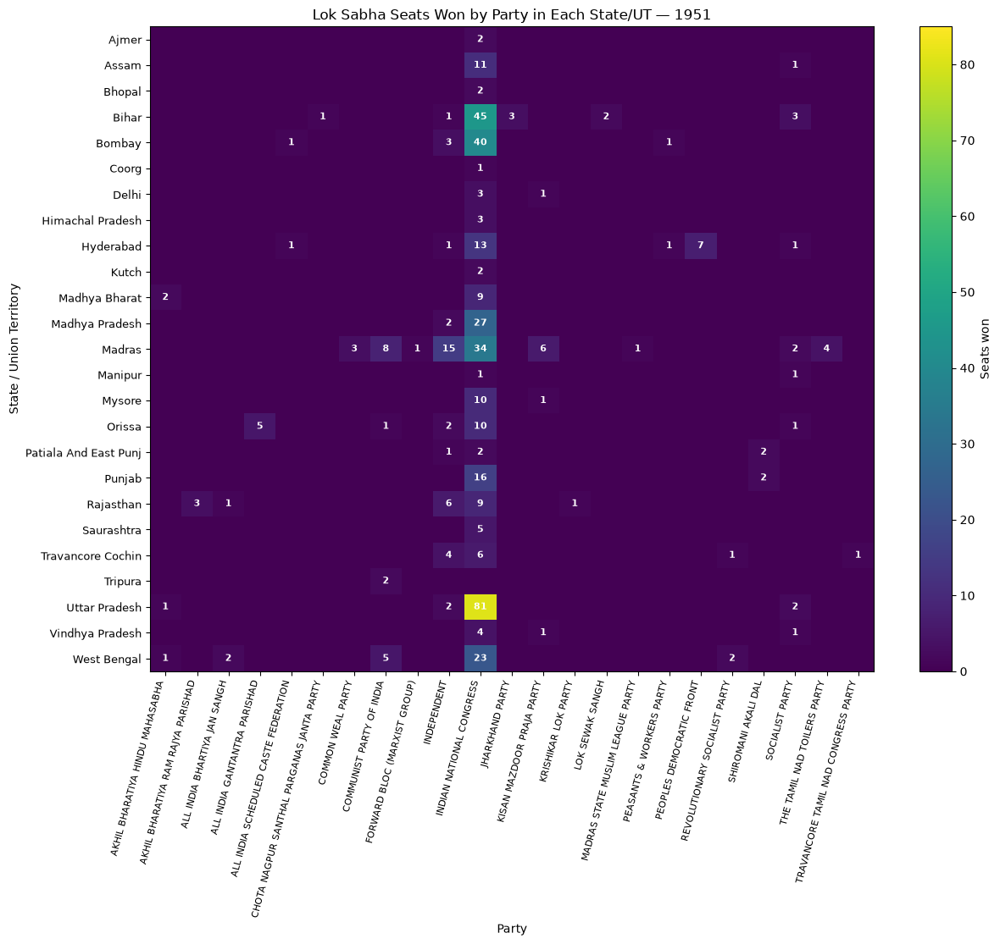

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_1951.png

Party seats by state/UT — 1957


PARTY,AKHIL BHARATIYA HINDU MAHASABHA,ALL INDIA BHARTIYA JAN SANGH,ALL INDIA GANTANTRA PARISHAD,ALL INDIA SCHEDULED CASTE FEDERATION,CHOTA NAGPUR SANTHAL PARGANAS JANTA PARTY,COMMUNIST PARTY OF INDIA,FORWARD BLOC (MARXIST),INDEPENDENT,INDIAN NATIONAL CONGRESS,JHARKHAND PARTY,PEASANTS & WORKERS PARTY,PEOPLES DEMOCRATIC FRONT,PRAJA SOCIALIST PARTY
STATE UT,,,,,,,,,,,,,
Andhra Pradesh,0,0,0,0,0,2,0,2,34,0,0,2,0
Assam,0,0,0,0,0,0,0,1,8,0,0,0,2
Bihar,0,0,0,0,3,0,0,1,41,6,0,0,2
Bombay,0,2,0,5,0,4,0,8,38,0,4,0,5
Delhi,0,0,0,0,0,0,0,0,5,0,0,0,0
Himachal Pradesh,0,0,0,0,0,0,0,0,4,0,0,0,0
Kerala,0,0,0,0,0,9,0,2,6,0,0,0,1
Madhya Pradesh,1,0,0,0,0,0,0,0,34,0,0,0,0
Madras,0,0,0,0,0,2,0,8,30,0,0,0,0


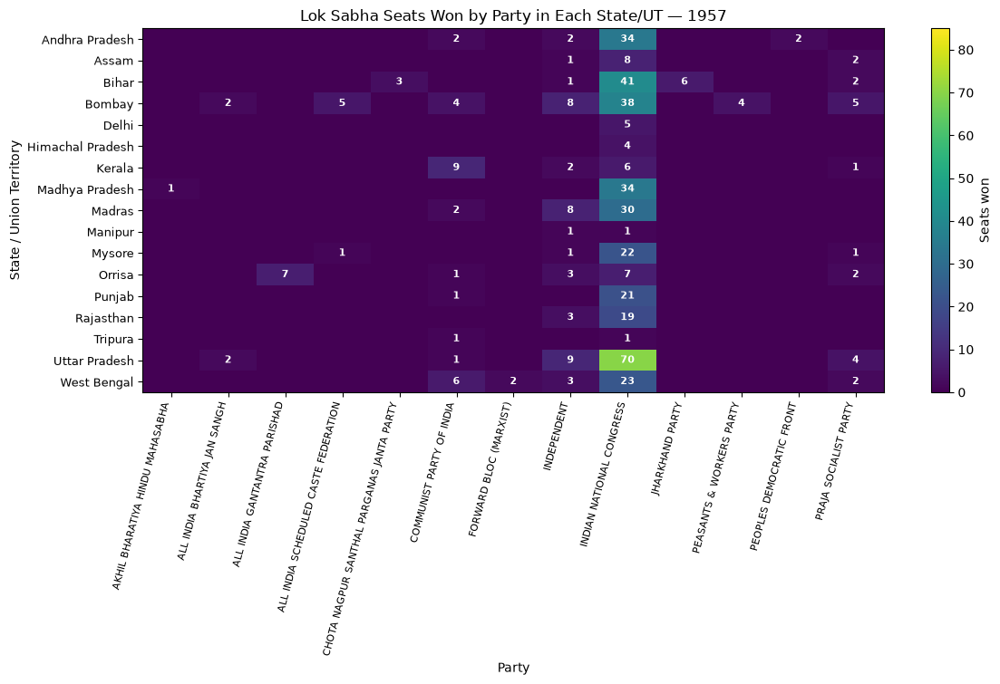

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_1957.png

Party seats by state/UT — 1962


PARTY,AKALI DAL,AKHIL BHARATIYA HINDU MAHASABHA,AKHIL BHARATIYA RAM RAJYA PARISHAD,ALL INDIA GANTANTRA PARISHAD,ALL INDIA REPUBLICAN PARTY,COMMUNIST PARTY OF INDIA,DRAVIDA MUNETRA KAZHAGAM,FORWARD BLOCK,HARYANA LOK SAMITI,HLC,...,INDIAN NATIONAL CONGRESS,JAN SANGH,JP,LOK SEWAK SANGH,MADRAS STATE MUSLIM LEAGUE PARTY,NUTAN MAHA GUJARAT JANTA PARISHA,PRAJA SOCIALIST PARTY,REVOLUTIONARY SOCIALIST PARTY,SOCIALIST,SWATANTRA
STATE UT,,,,,,,,,,,,,,,,,,,,,
Andhra Pradesh,0,0,0,0,0,7,0,0,0,0,...,34,0,0,0,0,0,0,0,0,1
Assam,0,0,0,0,0,0,0,0,0,1,...,9,0,0,0,0,0,2,0,0,0
Bihar,0,0,0,0,0,1,0,0,0,0,...,39,0,3,0,0,0,2,0,1,7
Delhi,0,0,0,0,0,0,0,0,0,0,...,5,0,0,0,0,0,0,0,0,0
Gujrat,0,0,0,0,0,0,0,0,0,0,...,16,0,0,0,0,1,1,0,0,4
Himachal Pradesh,0,0,0,0,0,0,0,0,0,0,...,4,0,0,0,0,0,0,0,0,0
Kerla,0,0,0,0,0,6,0,0,0,0,...,6,0,0,0,2,0,0,1,0,0
Madhya Pradesh,0,0,1,0,0,0,0,0,0,0,...,24,3,0,0,0,0,3,0,1,0
Madras,0,0,0,0,0,2,7,1,0,0,...,30,0,0,0,0,0,0,0,0,0


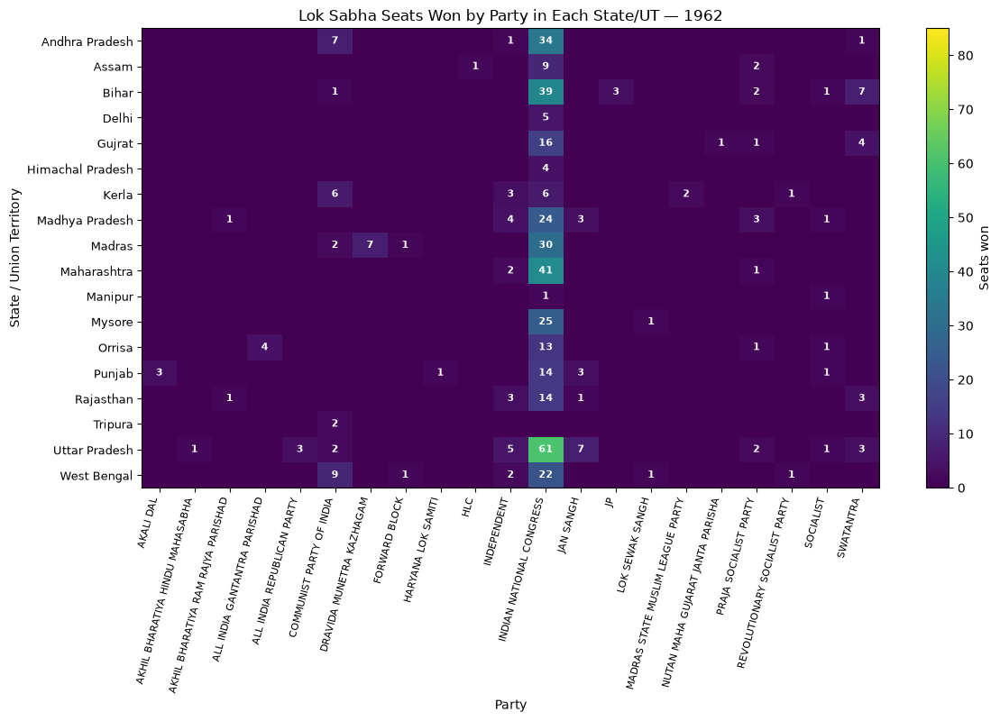

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_1962.png

Party seats by state/UT — 1967


PARTY,AKALI DAL - SANT FATEH SINGH GROUP,ALL INDIA BHARTIYA JAN SANGH,ALL PARTY HILL LEADERS CONFERENCE,BANGLA CONGRESS,COMMUNIST PARTY OF INDIA,CUMMUNIST PARTY OF INDIA (MARXIST),DRAVIDA MUNETRA KAZHAGAM,FORWARD BLOC,INDEPENDENT,INDIAN NATIONAL CONGRESS,JAMMU & KASHMIR NATIONAL CONFERENCE,JANA KRANTI DAL,MUSLIM LEAGE,PEASANTS & WORKERS PARTY,PRAJA SOCIALIST PARTY,REPUBLICAN PARTY OF INDIA,SAMYUKTA SOCIALIST PARTY,SWATANTRA,UNITED GOANS - SEQVERIA GROUP
STATE UT,,,,,,,,,,,,,,,,,,,
Andaman And Nicobar Islands,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
Andhra Pradesh,0,0,0,0,1,0,0,0,2,34,0,0,0,0,0,0,0,3,0
Assam,0,0,1,0,1,0,0,0,0,9,0,0,0,0,2,0,0,0,0
Bihar,0,1,0,0,5,0,0,0,4,34,0,1,0,0,1,0,7,0,0
Chandigarh,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Dadra And Nagar Haveli,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
Delhi,0,6,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
"Goa, Daman And Diu",0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1
Gujarat,0,0,0,0,0,0,0,0,1,11,0,0,0,0,0,0,0,12,0


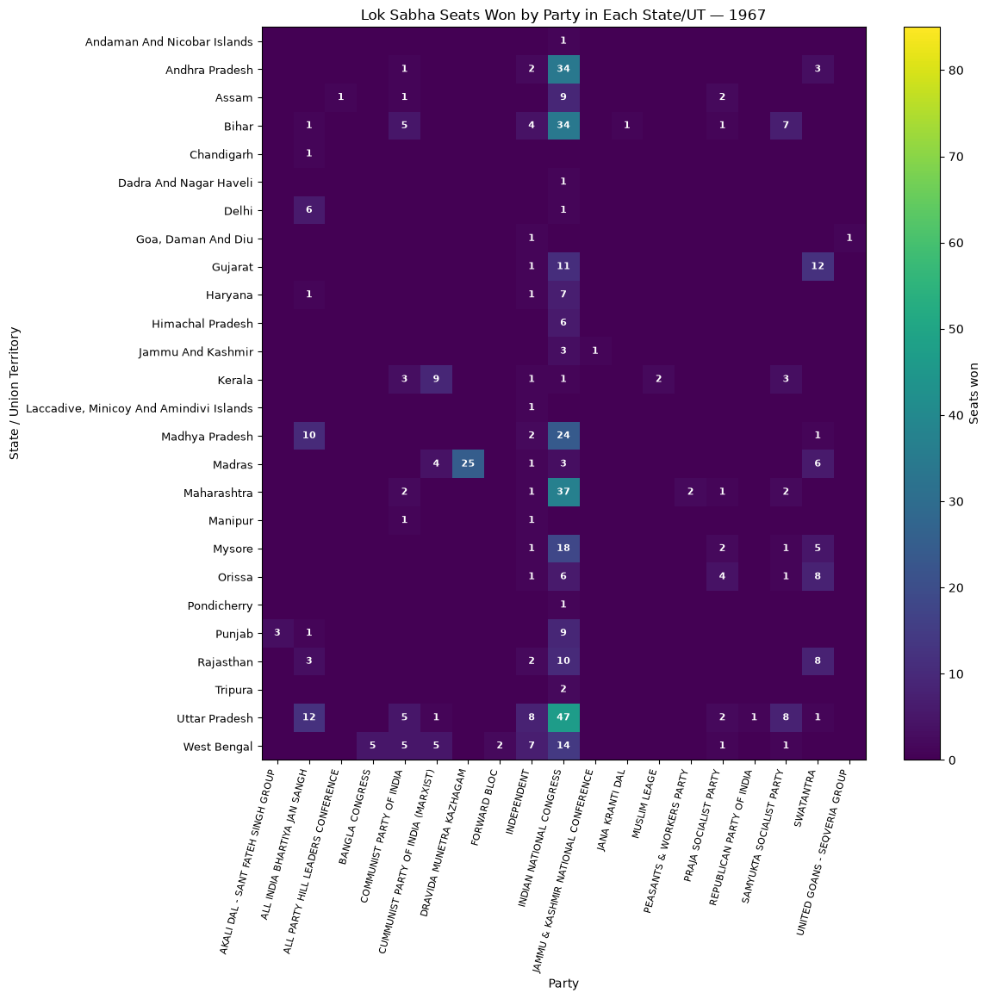

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_1967.png

Party seats by state/UT — 1971


PARTY,ALL INDIA BHARTIYA JAN SANGH,ALL INDIA JHARKHAND PARTY,ALL PARTY HILL LEADERS CONFERENCE,BANGLA CONGRESS,BHARATIYA KRANTI DAL,COMMUNIST PARTY OF INDIA,CUMMUNIST PARTY OF INDIA (MARXIST),DRAVIDA MUNETRA KAZHAGAM,FORWARD BLOC,INDEPENDENT,...,REPUBLICAN PARTY OF INDIA,REVOLUTIONARY SOCIALIST PARTY,SAMYUKTA SOCIALIST PARTY,SHIROMANI AKALI DAL,SWATANTRA,TELANGANA PRAJA SAMITHI,UNITED FRONT OF NAGALAND,UNITED GOANS - SEQVERIA GROUP,UTKAL CONGRESS,VISHAL HARYANA
STATE UT,,,,,,,,,,,,,,,,,,,,,
A And N Islands,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Andhra Pradesh,0,0,0,0,0,1,1,0,0,1,...,0,0,0,0,0,10,0,0,0,0
Assam,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Bihar,2,1,0,0,0,5,0,0,0,1,...,0,0,2,0,0,0,0,0,0,0
Chandigarh,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
D And N Haveli,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Delhi,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"Goa, Daman And Diu",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
Gujarat,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,2,0,0,0,0,0


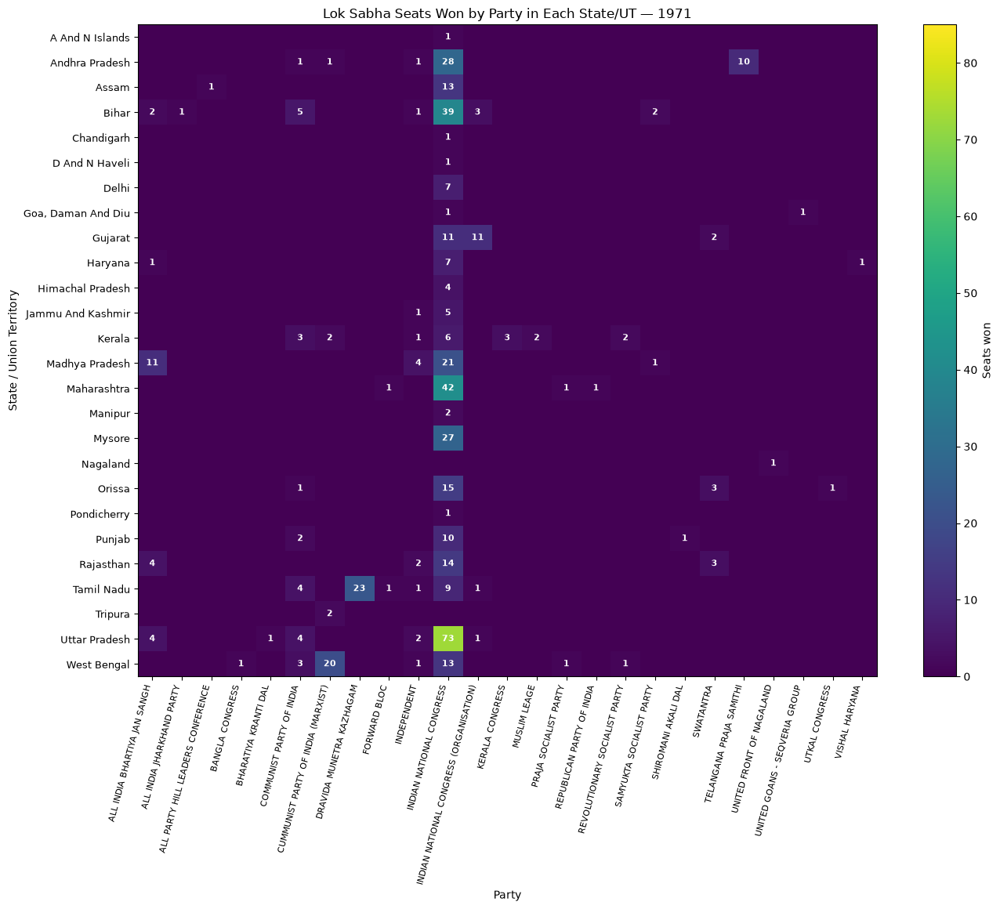

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_1971.png

Party seats by state/UT — 1977


PARTY,ALL INDIA ANNA DRAVIDA MUNNETRA KAZHAGAM,ALL INDIA JHARKHAND PARTY,BHARATIYA LOK DAL,COMMUNIST PARTY OF INDIA,CUMMUNIST PARTY OF INDIA (MARXIST),DRAVIDA MUNETRA KAZHAGAM,FORWARD BLOC,INDEPENDENT,INDIAN NATIONAL CONGRESS,INDIAN NATIONAL CONGRESS (ORGANISATION),JAMMU & KASHMIR NATIONAL CONFERENCE,KERALA CONGRESS,MAHARASHTRAWADI GOMANTAK,MUSLIM LEAGE,PEASANTS & WORKERS PARTY,REPUBLICAN PARTY OF INDIA (KHOBRAGADE),REVOLUTIONARY SOCIALIST PARTY,SHIROMANI AKALI DAL,UNITED DEMOCRATIC FRONT
STATE UT,,,,,,,,,,,,,,,,,,,
ANDAMAN & NICOBAR ISLANDS,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
ANDHRA PRADESH,0,0,1,0,0,0,0,0,41,0,0,0,0,0,0,0,0,0,0
ARUNACHAL PRADESH,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
ASSAM,0,0,3,0,0,0,0,1,10,0,0,0,0,0,0,0,0,0,0
BIHAR,0,1,52,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
CHANDIGARH,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
DADRA & NAGAR HAVELI,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
GOA DAMAN & DIU,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0
GUJARAT,0,0,16,0,0,0,0,0,10,0,0,0,0,0,0,0,0,0,0


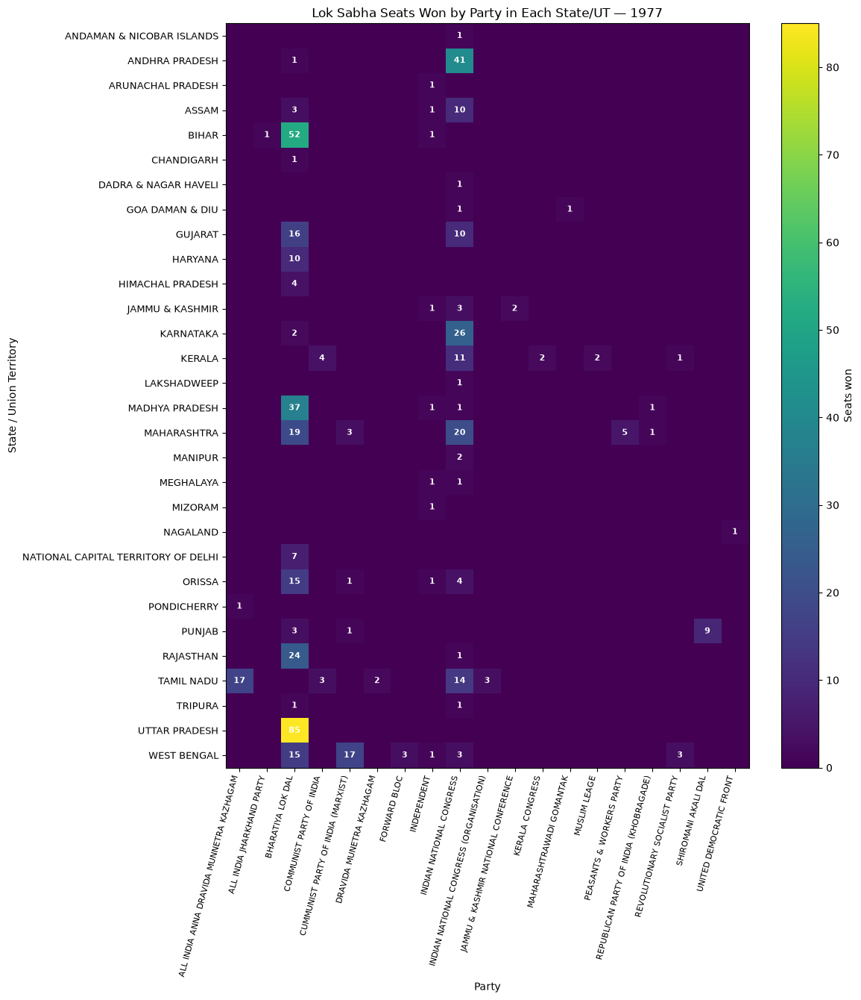

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_1977.png

Party seats by state/UT — 1980


PARTY,ALL INDIA ANNA DRAVIDA MUNNETRA KAZHAGAM,COMMUNIST PARTY OF INDIA,CUMMUNIST PARTY OF INDIA (MARXIST),DRAVIDA MUNETRA KAZHAGAM,FORWARD BLOC,INDEPENDENT,INDIAN NATIOANL CONGRESS (I),INDIAN NATIONAL CONGRESS (U),JAMMU & KASHMIR NATIONAL CONFERENCE,JANA KRANTI DAL,JANTA PARTY,JANTA PARTY (SECULAR),KERALA CONGRESS,MAHARASHTRAWADI GOMANTAK,MUSLIM LEAGE,REVOLUTIONARY SOCIALIST PARTY,SHIROMANI AKALI DAL,SIKKIM JANATA PARISHAD
STATE UT,,,,,,,,,,,,,,,,,,
ANDAMAN & NICOBAR ISLANDS,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
ANDHRA PRADESH,0,0,0,0,0,0,41,1,0,0,0,0,0,0,0,0,0,0
ARUNACHAL PRADESH,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0
ASSAM,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0
BIHAR,0,4,0,0,0,2,30,4,0,1,8,5,0,0,0,0,0,0
CHANDIGARH,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
DADRA & NAGAR HAVELI,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
"GOA, DAMAN & DIU",0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0
GUJARAT,0,0,0,0,0,0,25,0,0,0,1,0,0,0,0,0,0,0


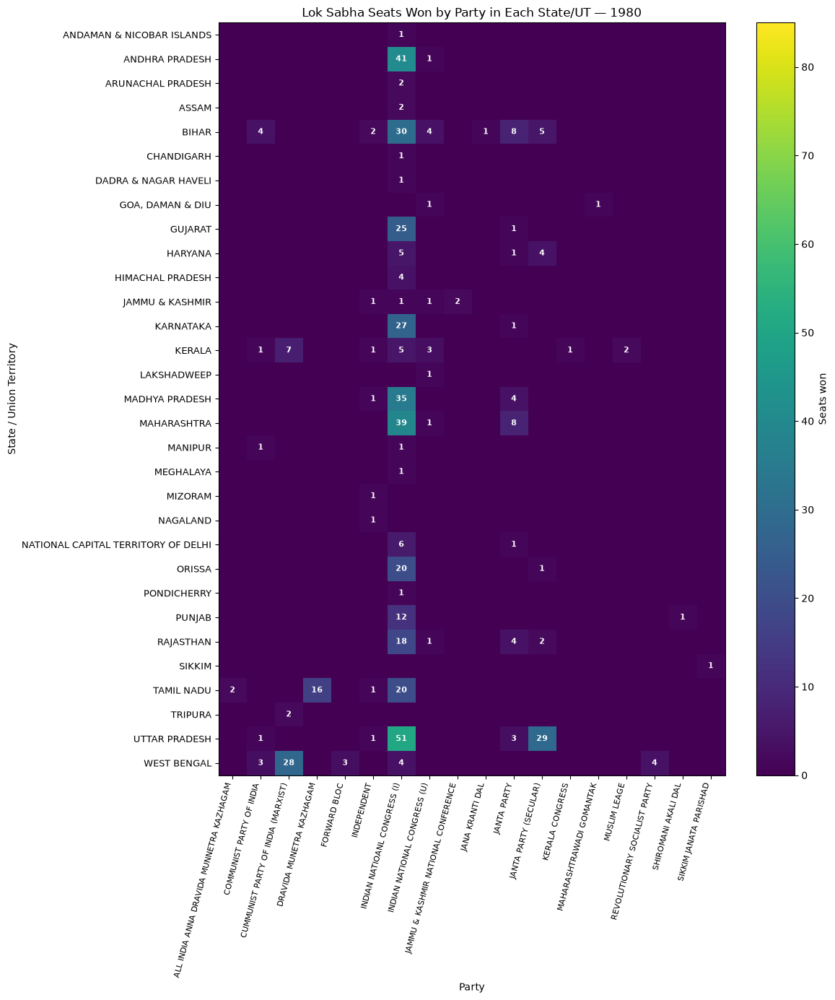

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_1980.png

Party seats by state/UT — 1984


PARTY,ALL INDIA ANNA DRAVIDA MUNNETRA KAZHAGAM,BHARATIYA JANTA PARTY,COMMUNIST PARTY OF INDIA,CUMMUNIST PARTY OF INDIA (MARXIST),DRAVIDA MUNETRA KAZHAGAM,FORWARD BLOC,INDEPENDENT,INDIAN CONGRESS (J),INDIAN CONGRESS (SOCIALIST),INDIAN NATIONAL CONGRESS,JAMMU & KASHMIR NATIONAL CONFERENCE,JANTA PARTY,KERALA CONGRESS (J),LOK DAL,MUSLIM LEAGE,PEASANTS & WORKERS PARTY,REVOLUTIONARY SOCIALIST PARTY,TELUGU DESAM
STATE UT,,,,,,,,,,,,,,,,,,
ANDAMAN & NICOBAR ISLANDS,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
ANDHRA PRADESH,0,1,1,1,0,0,1,0,1,6,0,1,0,0,0,0,0,30
ARUNACHAL PRADESH,0,0,0,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0
BIHAR,0,0,2,0,0,0,1,1,0,48,0,1,0,1,0,0,0,0
CHANDIGARH,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
DADRA & NAGAR HAVELI,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
Delhi,0,0,0,0,0,0,0,0,0,7,0,0,0,0,0,0,0,0
GOA DAMAN & DIU,0,0,0,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0
GUJARAT,0,1,0,0,0,0,0,0,0,24,0,1,0,0,0,0,0,0


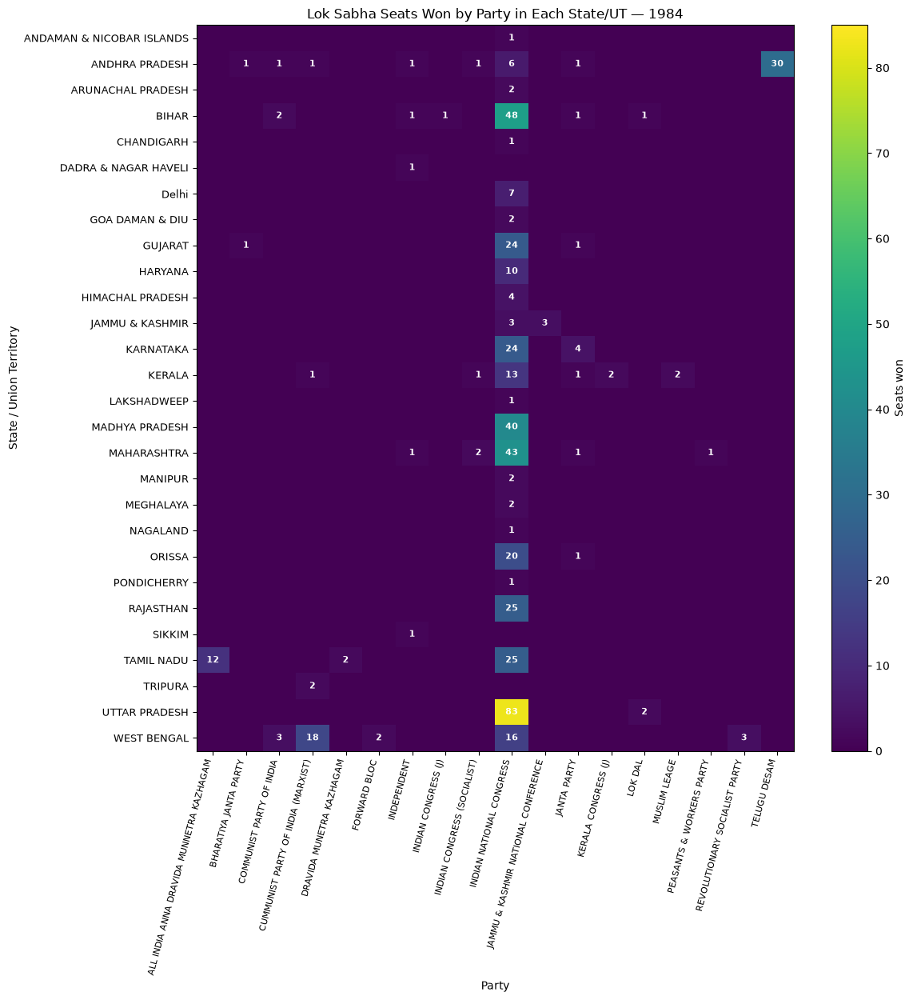

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_1984.png

Party seats by state/UT — 1989


PARTY,AKHIL BHARATIYA HINDU MAHASABHA,ALL INDIA ANNA DRAVIDA MUNNETRA KAZHAGAM,ALLINDIA MAJLIS-E ITHEHAD-UL-MULIMEEN,BAHUJAN SAMAJ PARTY,BHARATIYA JANTA PARTY,COMMUNIST PARTY OF INDIA,CUMMUNIST PARTY OF INDIA (MARXIST),FORWARD BLOC,GORKHA NATIONAL LIBERATION FRONT,INDEPENDENT,...,JHARKHAND MUKTI MORCHA,KERALA CONGRESS(M),MAHARASHTRAWADI GOMANTAK,MARXIST (CO-ORDINATION),MUSLIM LEAGE,REVOLUTIONARY SOCIALIST PARTY,SAMYUKTA SOCIALIST PARTY,SHIROMANI AKALI DAL (SIMRANJIT SINGH MANN),SHIVA SENA,TELUGU DESAM
STATE UT,,,,,,,,,,,,,,,,,,,,,
ANDAMAN & NICOBAR ISLANDS,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ANDHRA PRADESH,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2
ARUNACHAL PRADESH,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
BIHAR,0,0,0,0,8,4,1,0,0,0,...,3,0,0,1,0,0,0,0,0,0
CHANDIGARH,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DADRA & NAGAR HAVELI,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
DAMAN & DIU,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
GOA,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
GUJARAT,0,0,0,0,12,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


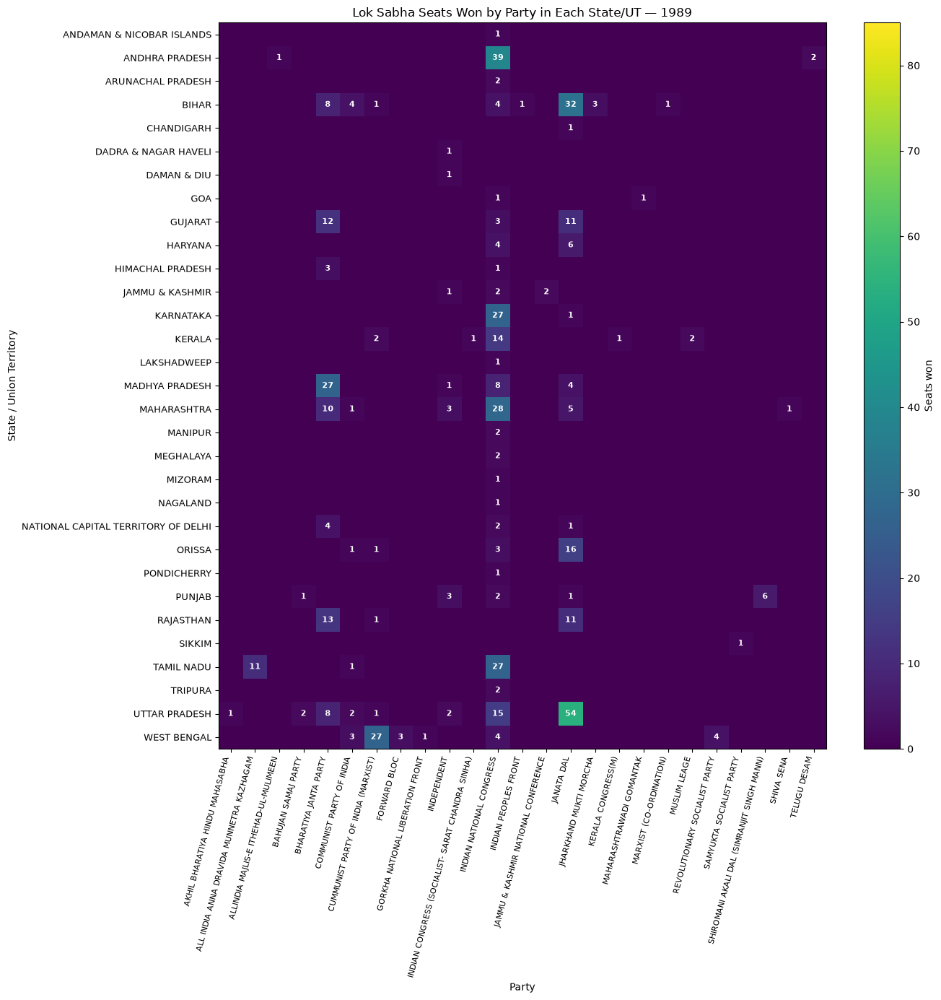

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_1989.png

Party seats by state/UT — 1991


PARTY,ALL INDIA ANNA DRAVIDA MUNNETRA KAZHAGAM,ALLINDIA MAJLIS-E ITHEHAD-UL-MULIMEEN,Asom Gana Parisad,Autonomous State Demand Committee,BAHUJAN SAMAJ PARTY,BHARATIYA JANTA PARTY,COMMUNIST PARTY OF INDIA,CUMMUNIST PARTY OF INDIA (MARXIST),FORWARD BLOC,Haryana Vikas Party,...,Janata Dal (Gujrat),Janata Party,KERALA CONGRESS(M),MANIPUR PEOPLES PARTY,MUSLIM LEAGE,NAGALAND PEOPLES COUNCIL,REVOLUTIONARY SOCIALIST PARTY,SAMYUKTA SOCIALIST PARTY,SHIVA SENA,TELUGU DESAM
STATE UT,,,,,,,,,,,,,,,,,,,,,
ANDAMAN & NICOBAR ISLANDS,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ANDHRA PRADESH,0,1,0,0,0,1,1,1,0,0,...,0,0,0,0,0,0,0,0,0,13
ARUNACHAL PRADESH,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ASSAM,0,0,1,1,0,2,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
BIHAR,0,0,0,0,0,5,8,1,0,0,...,0,0,0,0,0,0,0,0,0,0
CHANDIGARH,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DADRA & NAGAR HAVELI,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DAMAN & DIU,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GOA,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


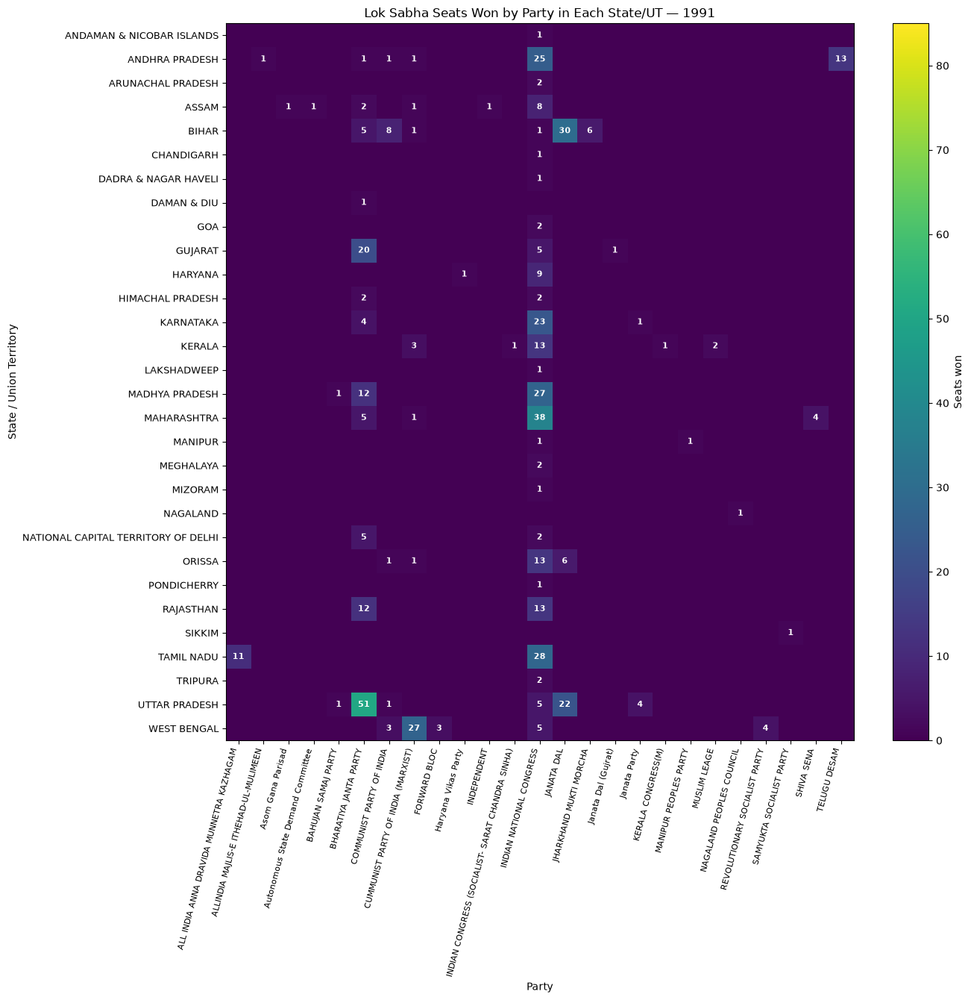

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_1991.png

Party seats by state/UT — 1996


PARTY,ALL INDIA INDIRA CONGRESS (TIWARI),ALL INDIA MAJLIS-E-ITTEHADUL MUSLIMOON,AUTONOMOUS STATE DEMAND COMMITTEE,Asom Gana Parisad,BAHUJAN SAMAJ PARTY,BHARATIYA JANTA PARTY,COMMUNIST PARTY OF INDIA,CUMMUNIST PARTY OF INDIA (MARXIST),DRAVIDA MUNETRA KAZHAGAM,FORWARD BLOC,...,MUSLIM LEAGE,REVOLUTIONARY SOCIALIST PARTY,SAMATA PARTY,SHIROMANI AKALI DAL,SHIVA SENA,SIKKIM DEMOCRATIC FRONT,SOCIALIST PARTY,TAMIL MAANILA CONGRESS (MOOPANAR),TELUGU DESAM,UNITED GOANS DEMOCRATIC PARTY
STATE UT,,,,,,,,,,,,,,,,,,,,,
ANDAMAN & NICOB,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ANDHRA PRADESH,0,1,0,0,0,0,2,1,0,0,...,0,0,0,0,0,0,0,0,16,0
ARUNACHAL PRADE,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ASSAM,0,0,1,5,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
BIHAR,0,0,0,0,0,18,3,0,0,0,...,0,0,6,0,0,0,1,0,0,0
CHANDIGARH,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DADRA & NAGAR H,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DAMAN & DIU,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GOA,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


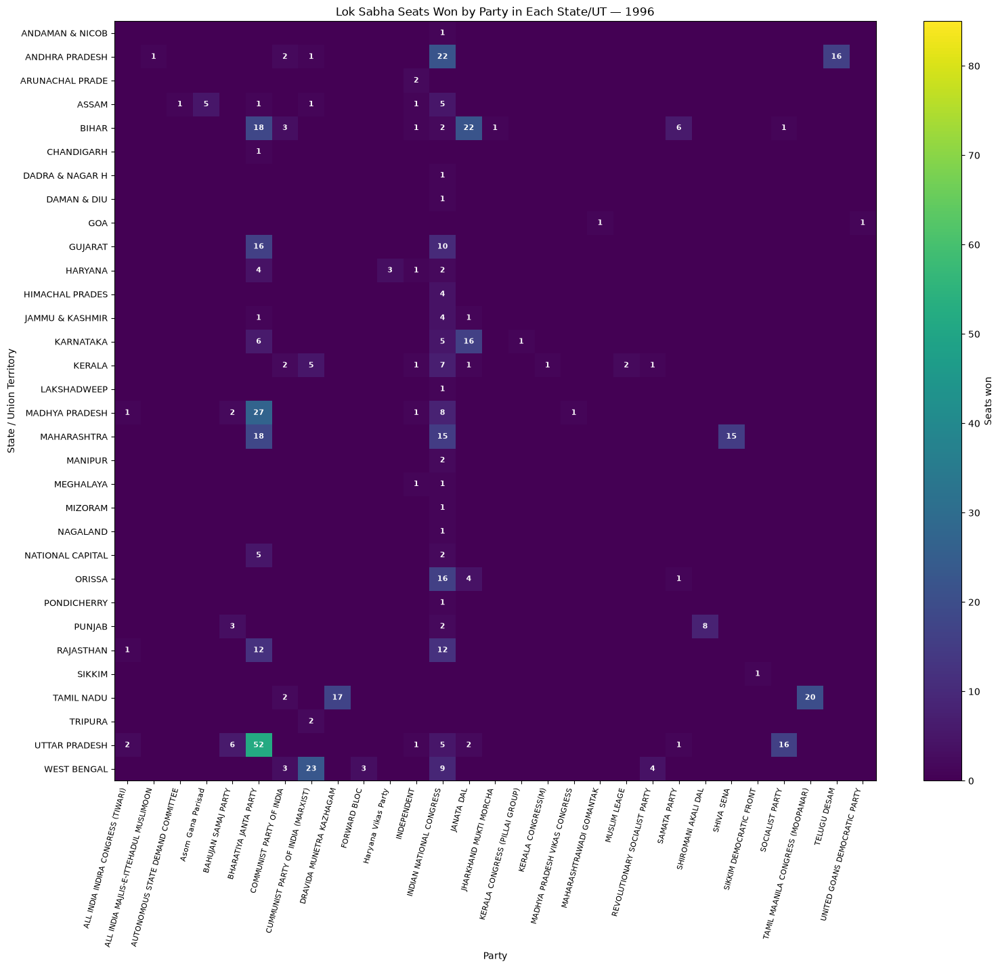

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_1996.png

Party seats by state/UT — 1998


PARTY,ALL INDIA ANNA DRAVIDA MUNNETRA KAZHAGAM,ALL INDIA INDIRA CONGRESS (SECULAR),ALL INDIA MAJLIS-E-ITTEHADUL MUSLIMOON,ALL INDIA RASHTRIYA JANATA PARTY,ARUNACHAL CONGRESS,AUTONOMOUS STATE DEMAND COMMITTEE,BAHUJAN SAMAJ PARTY,BHARATIYA JANTA PARTY,BIJU JANATA DAL,COMMUNIST PARTY OF INDIA,...,SAMAJWADI JANATA PARTY (RASHTRIYA),SAMATA PARTY,SHIROMANI AKALI DAL,SHIVA SENA,SIKKIM DEMOCRATIC FRONT,SOCIALIST PARTY,TAMIL MAANILA CONGRESS (MOOPANAR),TELUGU DESAM,"UNITED MINORITIES FRONT, ASSAM",WEST BENGAL TRINAMOOL CONGRESS
STATE UT,,,,,,,,,,,,,,,,,,,,,
ANDAMAN & NICOB,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ANDHRA PRADESH,0,0,1,0,0,0,0,4,0,2,...,0,0,0,0,0,0,0,12,0,0
ARUNACHAL PRADE,0,0,0,0,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ASSAM,0,0,0,0,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,1,0
BIHAR,0,0,0,1,0,0,0,20,0,0,...,0,10,0,0,0,0,0,0,0,0
CHANDIGARH,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
DADRA & NAGAR H,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
DAMAN & DIU,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
GOA,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


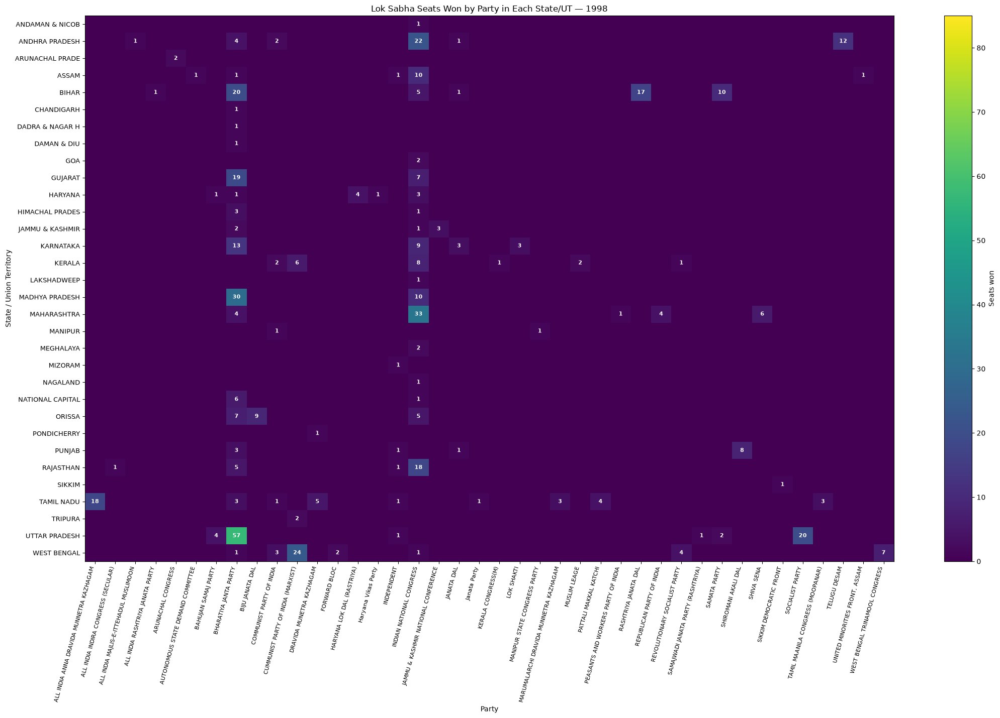

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_1998.png

Party seats by state/UT — 1999


PARTY,ALL INDIA ANNA DRAVIDA MUNNETRA KAZHAGAM,ALL INDIA MAJLIS-E-ITTEHADUL MUSLIMOON,Akhil Bhartiya Lok Tantrik Congress,All India Trinamool Congress,BAHUJAN SAMAJ PARTY,BHARATIYA JANTA PARTY,BHARIPA BAHUJAN MAHASANGH,BIJU JANATA DAL,COMMUNIST PARTY OF INDIA,CUMMUNIST PARTY OF INDIA (MARXIST),...,RASHTRIYA JANATA DAL,REVOLUTIONARY SOCIALIST PARTY,Rashtriya Lok Dal,SAMAJWADI JANATA PARTY (RASHTRIYA),SHIROMANI AKALI DAL,SHIROMANI AKALI DAL (SIMRANJIT SINGH MANN),SHIVA SENA,SIKKIM DEMOCRATIC FRONT,SOCIALIST PARTY,TELUGU DESAM
STATE UT,,,,,,,,,,,,,,,,,,,,,
ANDAMAN & NICOB,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ANDHRA PRADESH,0,1,0,0,0,7,0,0,0,0,...,0,0,0,0,0,0,0,0,0,29
ARUNACHAL PRADE,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ASSAM,0,0,0,0,0,2,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
BIHAR,0,0,0,0,0,23,0,0,0,1,...,7,0,0,0,0,0,0,0,0,0
CHANDIGARH,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DADRA & NAGAR H,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DAMAN & DIU,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
GOA,0,0,0,0,0,2,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


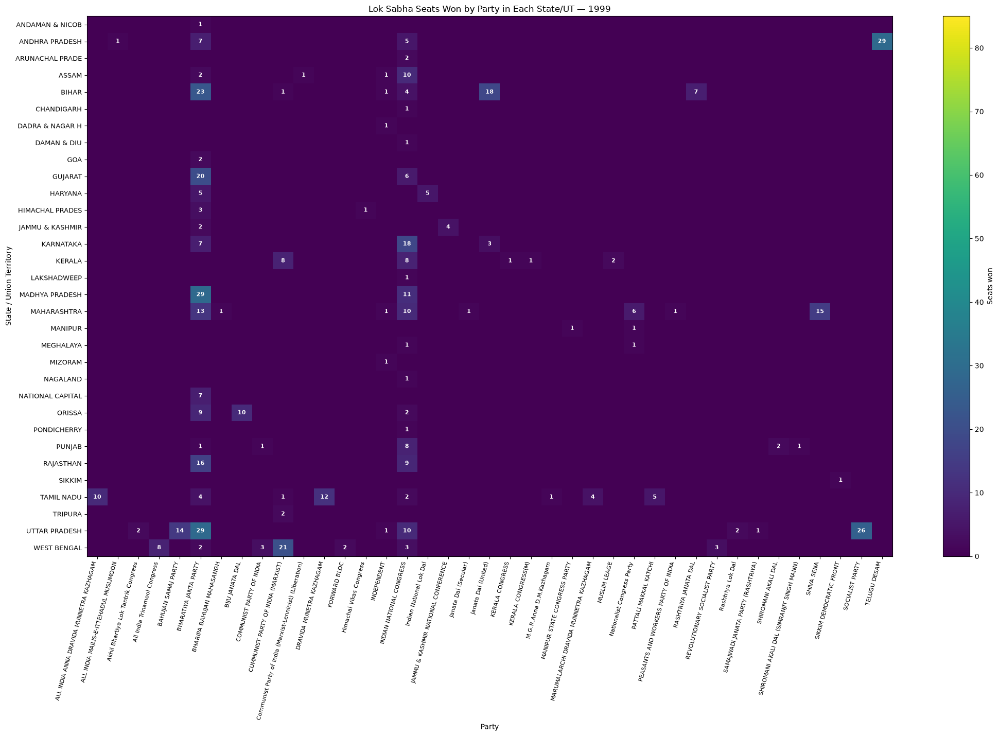

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_1999.png

Party seats by state/UT — 2004


PARTY,ALL INDIA MAJLIS-E-ITTEHADUL MUSLIMOON,All India Forward Bloc,All India Trinamool Congress,Asom Gana Parisad,BAHUJAN SAMAJ PARTY,BHARATIYA JANTA PARTY,BIJU JANATA DAL,Bharatiya Navshakti party,COMMUNIST PARTY OF INDIA,CUMMUNIST PARTY OF INDIA (MARXIST),...,REVOLUTIONARY SOCIALIST PARTY,Rashtriya Lok Dal,Republican Party of India(A),SAMAJWADI JANATA PARTY (RASHTRIYA),SHIROMANI AKALI DAL,SHIVA SENA,SIKKIM DEMOCRATIC FRONT,SOCIALIST PARTY,TELUGU DESAM,Telangana Rashtra Samithi
STATE UT,,,,,,,,,,,,,,,,,,,,,
ANDAMAN & NICOBAR ISLAND,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ANDHRA PRADESH,1,0,0,0,0,0,0,0,1,1,...,0,0,0,0,0,0,0,0,5,5
ARUNACHAL PRADESH,0,0,0,0,0,2,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ASSAM,0,0,0,2,0,2,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
BIHAR,0,0,0,0,0,5,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CHANDIGARH,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CHHATTISGARH,0,0,0,0,0,10,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DADRA & NAGAR HAVELI,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
DAMAN & DIU,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


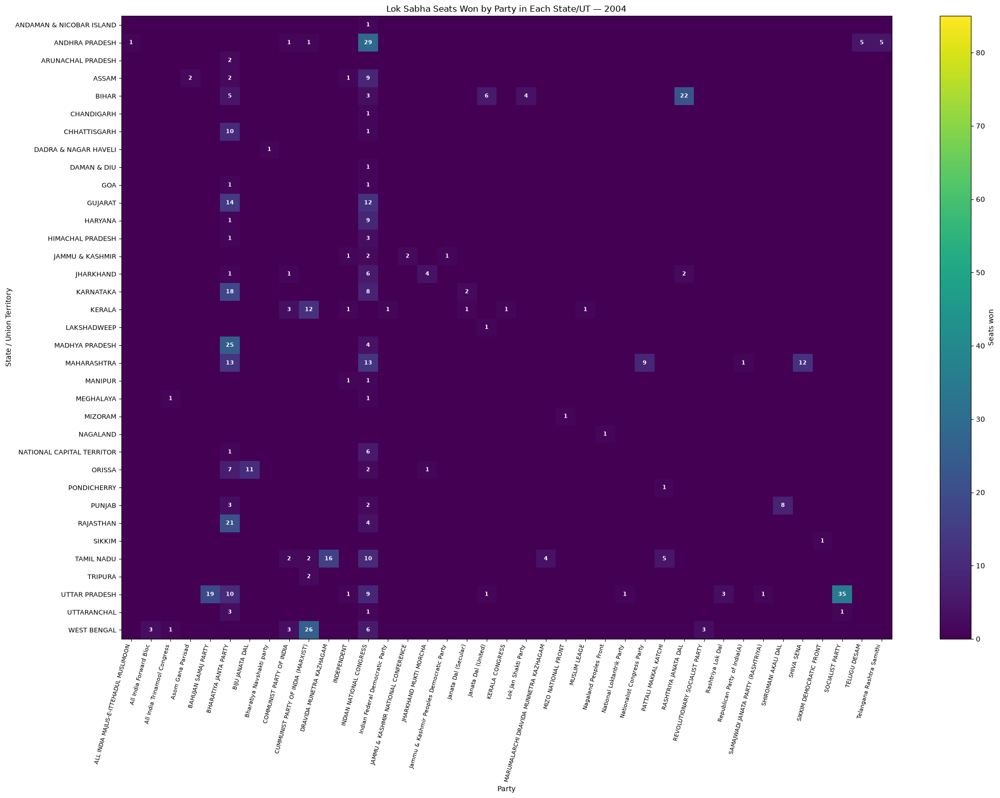

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_2004.png

Party seats by state/UT — 2009


PARTY,ALL INDIA ANNA DRAVIDA MUNNETRA KAZHAGAM,ALL INDIA MAJLIS-E-ITTEHADUL MUSLIMOON,All India Forward Bloc,All India Trinamool Congress,Asom Gana Parisad,Assam United Democratic Front,BAHUJAN SAMAJ PARTY,BHARATIYA JANTA PARTY,BIJU JANATA DAL,Bahujan Vikas Aaghadi,...,REVOLUTIONARY SOCIALIST PARTY,Rashtriya Lok Dal,SHIROMANI AKALI DAL,SHIVA SENA,SIKKIM DEMOCRATIC FRONT,SOCIALIST PARTY,Swabhimani Paksha,TELUGU DESAM,Telangana Rashtra Samithi,Viduthalai Chiruthaigal Katchi
STATE UT,,,,,,,,,,,,,,,,,,,,,
Andaman and Nicobar Islands,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
Andhra Pradesh,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,6,2,0
Arunachal Pradesh,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Assam,0,0,0,0,1,1,0,4,0,0,...,0,0,0,0,0,0,0,0,0,0
Bihar,0,0,0,0,0,0,0,12,0,0,...,0,0,0,0,0,0,0,0,0,0
Chandigarh,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Chhattisgarh,0,0,0,0,0,0,0,10,0,0,...,0,0,0,0,0,0,0,0,0,0
Dadra and Nagar Haveli,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
Daman and Diu,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


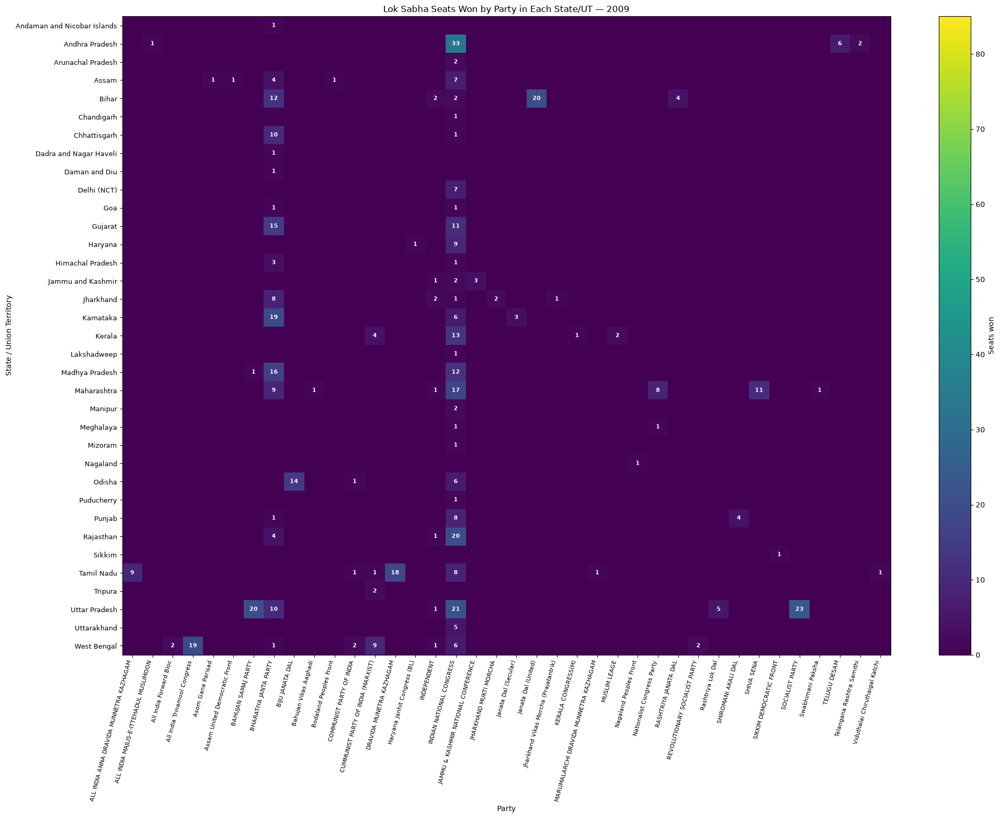

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_2009.png

Party seats by state/UT — 2014


PARTY,AKALI DAL,ALL INDIA ANNA DRAVIDA MUNNETRA KAZHAGAM,ALL INDIA MAJLIS-E-ITTEHADUL MUSLIMOON,Aam Aadmi Party,All India N.R. Congress,All India Trinamool Congress,All India United Democratic Front,BHARATIYA JANTA PARTY,BIJU JANATA DAL,COMMUNIST PARTY OF INDIA,...,REVOLUTIONARY SOCIALIST PARTY,Rashtriya Lok Samta Party,SHIROMANI AKALI DAL,SHIVA SENA,SIKKIM DEMOCRATIC FRONT,SOCIALIST PARTY,Swabhimani Paksha,TELUGU DESAM,Telangana Rashtra Samithi,Yuvajana Sramika Rythu Congress Party
STATE UT,,,,,,,,,,,,,,,,,,,,,
Andaman and Nicobar Islands,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
Andhra Pradesh,0,0,1,0,0,0,0,3,0,0,...,0,0,0,0,0,0,0,16,11,9
Arunachal Pradesh,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
Assam,0,0,0,0,0,0,3,7,0,0,...,0,0,0,0,0,0,0,0,0,0
Bihar,0,0,0,0,0,0,0,22,0,0,...,0,3,0,0,0,0,0,0,0,0
Chandigarh,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
Chhattisgarh,0,0,0,0,0,0,0,10,0,0,...,0,0,0,0,0,0,0,0,0,0
Dadra and Nagar Haveli,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
Daman and Diu,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


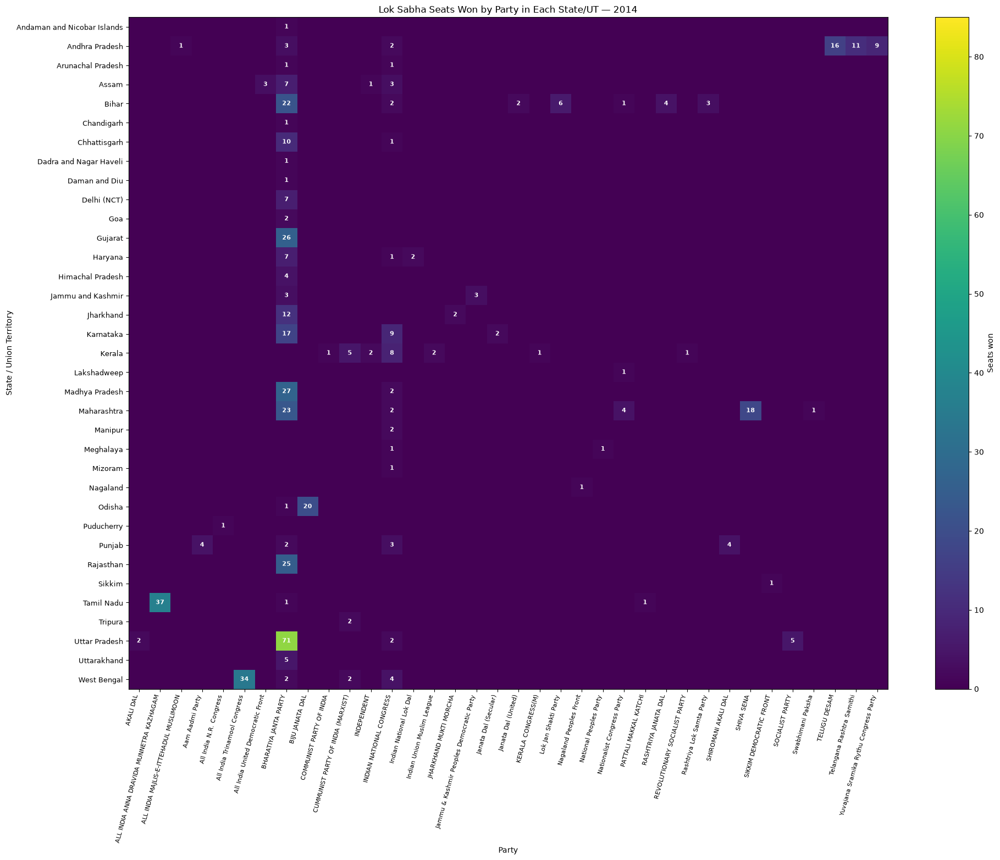

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_2014.png

Party seats by state/UT — 2019


PARTY,AJSU Party,ALL INDIA ANNA DRAVIDA MUNNETRA KAZHAGAM,ALL INDIA MAJLIS-E-ITTEHADUL MUSLIMOON,Aam Aadmi Party,All India Trinamool Congress,All India United Democratic Front,Apna Dal (Soneylal),BAHUJAN SAMAJ PARTY,BHARATIYA JANTA PARTY,BIJU JANATA DAL,...,REVOLUTIONARY SOCIALIST PARTY,Rashtriya Loktantrik Party,SHIROMANI AKALI DAL,SHIVA SENA,SOCIALIST PARTY,Sikkim Krantikari Morcha,TELUGU DESAM,Telangana Rashtra Samithi,Viduthalai Chiruthaigal Katchi,Yuvajana Sramika Rythu Congress Party
STATE UT,,,,,,,,,,,,,,,,,,,,,
Andaman & Nicobar Islands,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Andhra Pradesh,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,3,0,0,22
Arunachal Pradesh,0,0,0,0,0,0,0,0,2,0,...,0,0,0,0,0,0,0,0,0,0
Assam,0,0,0,0,0,1,0,0,9,0,...,0,0,0,0,0,0,0,0,0,0
Bihar,0,0,0,0,0,0,0,0,17,0,...,0,0,0,0,0,0,0,0,0,0
Chandigarh,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
Chhattisgarh,0,0,0,0,0,0,0,0,9,0,...,0,0,0,0,0,0,0,0,0,0
Dadra & Nagar Haveli,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Daman & Diu,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0


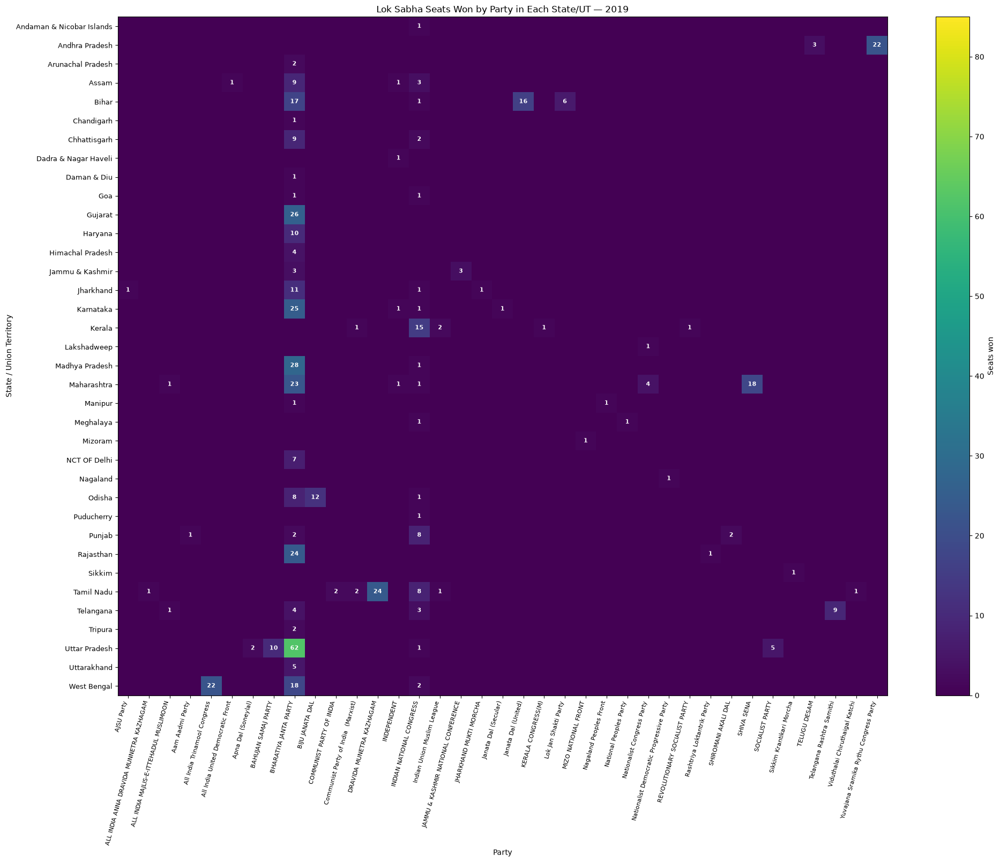

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_2019.png

Party seats by state/UT — 2024


PARTY,AJSU Party,ALL INDIA MAJLIS-E-ITTEHADUL MUSLIMOON,Aam Aadmi Party,Aazad Samaj Party (Kanshi Ram),All India Trinamool Congress,Apna Dal (Soneylal),Asom Gana Parisad,BHARATIYA JANTA PARTY,Bharat Adivasi Party,COMMUNIST PARTY OF INDIA,...,SHIVA SENA,SOCIALIST PARTY,Shiv Sena (Uddhav Balasaheb Thackrey),Sikkim Krantikari Morcha,TELUGU DESAM,"United People’s Party, Liberal",Viduthalai Chiruthaigal Katchi,Voice of the People Party,Yuvajana Sramika Rythu Congress Party,Zoram People’s Movement
STATE UT,,,,,,,,,,,,,,,,,,,,,
Andaman & Nicobar Islands,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
Andhra Pradesh,0,0,0,0,0,0,0,3,0,0,...,0,0,0,0,16,0,0,0,4,0
Arunachal Pradesh,0,0,0,0,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
Assam,0,0,0,0,0,0,1,9,0,0,...,0,0,0,0,0,1,0,0,0,0
Bihar,0,0,0,0,0,0,0,12,0,0,...,0,0,0,0,0,0,0,0,0,0
Chandigarh,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Chhattisgarh,0,0,0,0,0,0,0,10,0,0,...,0,0,0,0,0,0,0,0,0,0
Dadra & Nagar Haveli and Daman & Diu,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
Goa,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


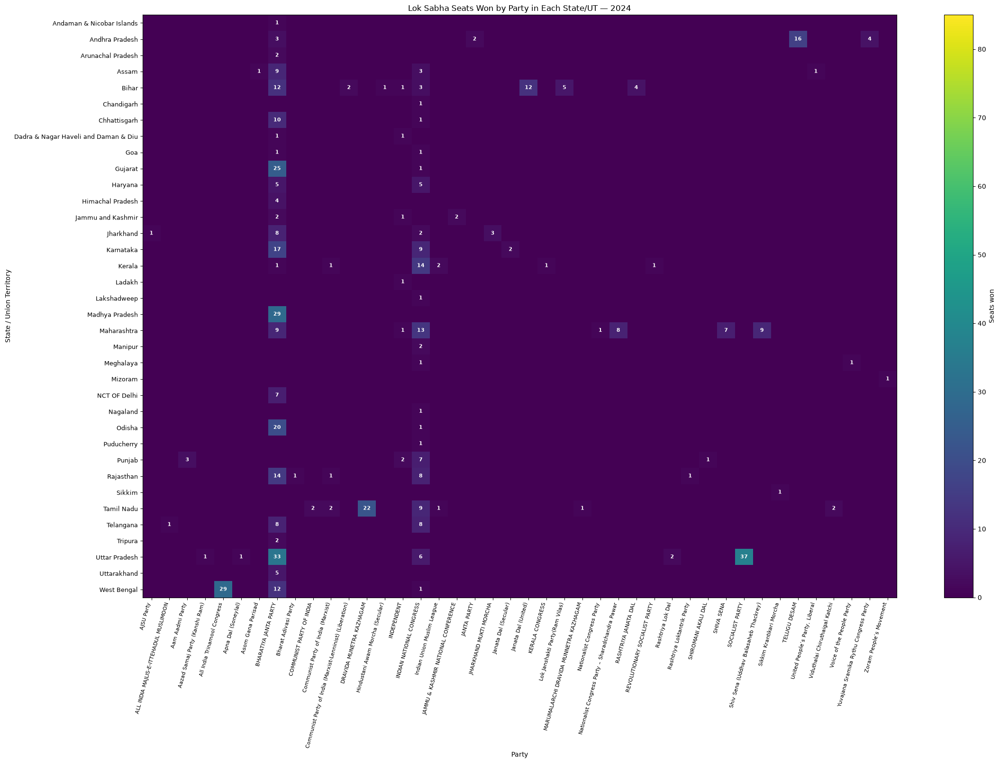

Saved heatmap: outputs\state_regional_analysis\state_party_seat_heatmaps\state_party_seat_heatmap_2024.png


In [60]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("outputs/state_regional_analysis/state_party_seat_heatmaps")
output_dir.mkdir(parents=True, exist_ok=True)

data = df.copy()

# Identify winner rows, including Winner 1 / Winner 2
result_labels = (
    data["RESULT POSITION"]
    .astype("string")
    .str.strip()
    .str.lower()
)

is_winner = result_labels.str.match(
    r"^winner(?:\s+\d+)?$",
    na=False
)

winners = data.loc[is_winner].dropna(
    subset=["YEAR", "STATE UT", "PARTY"]
).copy()

# Count party seats by state/UT for each election year
seat_counts = (
    winners.groupby(["YEAR", "STATE UT", "PARTY"])
    .size()
    .reset_index(name="SEATS_WON")
)

years = sorted(seat_counts["YEAR"].dropna().unique())

print(f"Generating heatmaps for {len(years)} election years.")

# Use a consistent color scale across all election years
max_seats = int(seat_counts["SEATS_WON"].max())

for year in years:
    year_data = seat_counts[seat_counts["YEAR"] == year]

    # Rows = states/UTs; columns = parties; values = seats won
    heatmap_data = year_data.pivot_table(
        index="STATE UT",
        columns="PARTY",
        values="SEATS_WON",
        aggfunc="sum",
        fill_value=0
    )

    # Sort state names alphabetically
    heatmap_data = heatmap_data.sort_index()

    print(f"\nParty seats by state/UT — {int(year)}")
    display(heatmap_data)

    # Draw heatmap
    fig_width = max(12, heatmap_data.shape[1] * 0.55)
    fig_height = max(7, heatmap_data.shape[0] * 0.45)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    image = ax.imshow(
        heatmap_data.values,
        aspect="auto",
        interpolation="nearest",
        vmin=0,
        vmax=max_seats
    )

    # Label axes
    ax.set_xticks(range(len(heatmap_data.columns)))
    ax.set_xticklabels(
        heatmap_data.columns,
        rotation=75,
        ha="right",
        fontsize=8
    )

    ax.set_yticks(range(len(heatmap_data.index)))
    ax.set_yticklabels(heatmap_data.index, fontsize=9)

    ax.set_title(
        f"Lok Sabha Seats Won by Party in Each State/UT — {int(year)}"
    )
    ax.set_xlabel("Party")
    ax.set_ylabel("State / Union Territory")

    # Write seat counts inside cells; omit zeroes to reduce clutter
    for row_idx in range(heatmap_data.shape[0]):
        for col_idx in range(heatmap_data.shape[1]):
            seats = heatmap_data.iloc[row_idx, col_idx]

            if seats > 0:
                ax.text(
                    col_idx,
                    row_idx,
                    int(seats),
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white",
                     fontweight="bold"
                )

    colorbar = fig.colorbar(image, ax=ax)
    colorbar.set_label("Seats won")

    plt.tight_layout()

    chart_path = output_dir / f"state_party_seat_heatmap_{int(year)}.png"
    plt.savefig(chart_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved heatmap: {chart_path}")

In [61]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# ANALYSIS 22: STATE-WISE VOTE SHARE BY PARTY
# Chart: Small-multiple horizontal bar charts
# Each panel: one state/UT, top 5 parties
# One PNG per election year
# ============================================================

# 1. Output folder
output_dir = (
    "outputs/state_regional_analysis/"
    "state_party_vote_share_small_multiples"
)
os.makedirs(output_dir, exist_ok=True)

# 2. Prepare data
data = df.copy()

data["VOTES"] = pd.to_numeric(data["VOTES"], errors="coerce")
data["YEAR"] = pd.to_numeric(data["YEAR"], errors="coerce")

# Remove records without usable election/state/vote information
data = data.dropna(subset=["YEAR", "STATE UT", "VOTES"])

# 3. Total candidate votes per state/UT and election
state_totals = (
    data.groupby(["YEAR", "STATE UT"])["VOTES"]
    .sum()
    .reset_index(name="STATE_TOTAL_VOTES")
)

# 4. Aggregate votes by party, state/UT, and election
party_votes = (
    data.dropna(subset=["PARTY"])
    .groupby(["YEAR", "STATE UT", "PARTY"])["VOTES"]
    .sum()
    .reset_index(name="PARTY_VOTES")
)

# 5. Calculate party vote share
party_votes = party_votes.merge(
    state_totals,
    on=["YEAR", "STATE UT"],
    how="left"
)

party_votes["VOTE_SHARE_PERCENT"] = (
    party_votes["PARTY_VOTES"]
    / party_votes["STATE_TOTAL_VOTES"]
    * 100
)

# 6. Generate a chart for every election year
for year in sorted(party_votes["YEAR"].unique()):

    year_data = party_votes[party_votes["YEAR"] == year].copy()

    # Sort states by total votes, largest first
    state_order = (
        state_totals[state_totals["YEAR"] == year]
        .sort_values("STATE_TOTAL_VOTES", ascending=False)
        ["STATE UT"]
        .tolist()
    )

    # Layout: 4 state/UT panels per row
    n_states = len(state_order)
    ncols = 4
    nrows = math.ceil(n_states / ncols)

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(20, nrows * 3.4),
        sharex=True
    )

    # Make axes iterable whether there's one row or multiple
    axes = np.array(axes).reshape(-1)

    for i, state in enumerate(state_order):

        ax = axes[i]

        state_data = (
            year_data[year_data["STATE UT"] == state]
            .sort_values("VOTE_SHARE_PERCENT", ascending=False)
            .head(5)
            .sort_values("VOTE_SHARE_PERCENT", ascending=True)
        )

        parties = state_data["PARTY"].astype(str).tolist()
        shares = state_data["VOTE_SHARE_PERCENT"].tolist()

        # Horizontal bars
        bars = ax.barh(
            parties,
            shares,
            height=0.68
        )

        # Add vote-share labels to bars
        for bar, share in zip(bars, shares):

            # Place labels inside very long bars; outside otherwise
            if share >= 90:
                label_x = share - 1
                label_color = "white"
                horizontal_alignment = "right"
            else:
                label_x = share + 1
                label_color = "black"
                horizontal_alignment = "left"

            ax.text(
                label_x,
                bar.get_y() + bar.get_height() / 2,
                f"{share:.1f}%",
                va="center",
                ha=horizontal_alignment,
                color=label_color,
                fontsize=8,
                fontweight="bold"
            )

        # Panel formatting
        ax.set_title(str(state), fontsize=11, fontweight="bold")
        ax.set_xlim(0, 100)
        ax.set_xticks([0, 25, 50, 75, 100])
        ax.tick_params(axis="y", labelsize=8)
        ax.tick_params(axis="x", labelsize=8)
        ax.grid(axis="x", linestyle="--", alpha=0.35)
        ax.set_axisbelow(True)

    # Hide unused panels in the final row
    for j in range(n_states, len(axes)):
        axes[j].set_visible(False)

    # Overall chart title
    fig.suptitle(
        f"State-wise Party Vote Share — Lok Sabha {int(year)}\n"
        "Top 5 parties in each state/UT",
        fontsize=16,
        fontweight="bold",
        y=1.01
    )

    # Shared axis labels
    fig.supxlabel("Vote share (%) — common scale from 0% to 100%")
    fig.supylabel("Party")

    plt.tight_layout(rect=[0.02, 0.02, 1, 0.97])

    # Save one PNG per election year
    file_path = os.path.join(
        output_dir,
        f"state_party_vote_share_{int(year)}.png"
    )

    plt.savefig(
        file_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

print("Charts saved to:", output_dir)
print("Election years processed:", len(party_votes["YEAR"].unique()))

Charts saved to: outputs/state_regional_analysis/state_party_vote_share_small_multiples
Election years processed: 18


In [62]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# ANALYSIS 23
# PARTY SEAT SHARE BY HISTORICAL STATE/UT, WITHIN EACH ELECTION
#
# - Uses state/UT names exactly as recorded in each election
# - Does NOT map old states to modern states
# - One PNG per election year
# - One panel per historical state/UT
# - Top 5 parties in each panel
# ============================================================

# 1. Output folder
output_dir = (
    "outputs/state_regional_analysis/"
    "historical_state_party_seat_share"
)
os.makedirs(output_dir, exist_ok=True)

# 2. Prepare data
data = df.copy()

data["YEAR"] = pd.to_numeric(data["YEAR"], errors="coerce")

data["RESULT POSITION"] = (
    data["RESULT POSITION"]
    .astype("string")
    .str.strip()
)

data = data.dropna(subset=["YEAR", "STATE UT", "PARTY"])

# 3. Identify winner records
winner_mask = (
    data["RESULT POSITION"]
    .str.fullmatch(r"winner(?:\s+\d+)?", case=False, na=False)
)

winners = data.loc[winner_mask].copy()

if winners.empty:
    print("Result labels in your data:")
    print(df["RESULT POSITION"].value_counts(dropna=False))
    raise ValueError("No winner records found. Check the result labels.")

# 4. Count seats won by each party in each historical state/UT and year
party_seats = (
    winners.groupby(["YEAR", "STATE UT", "PARTY"])
    .size()
    .reset_index(name="SEATS_WON")
)

# 5. Calculate total recorded seats in each historical state/UT and year
state_totals = (
    party_seats.groupby(["YEAR", "STATE UT"])["SEATS_WON"]
    .sum()
    .reset_index(name="TOTAL_RECORDED_SEATS")
)

# 6. Calculate party seat share
party_seats = party_seats.merge(
    state_totals,
    on=["YEAR", "STATE UT"],
    how="left"
)

party_seats["SEAT_SHARE_PERCENT"] = (
    party_seats["SEATS_WON"]
    / party_seats["TOTAL_RECORDED_SEATS"]
    * 100
)

# 7. Generate one chart per election year
for year in sorted(party_seats["YEAR"].unique()):

    election_data = party_seats[
        party_seats["YEAR"] == year
    ].copy()

    historical_states = sorted(
        election_data["STATE UT"].unique()
    )

    n_states = len(historical_states)
    ncols = 4
    nrows = math.ceil(n_states / ncols)

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(20, max(5, nrows * 3.2)),
        sharex=True
    )

    axes = np.array(axes).reshape(-1)

    for i, historical_state in enumerate(historical_states):

        ax = axes[i]

        state_data = (
            election_data[
                election_data["STATE UT"] == historical_state
            ]
            .sort_values("SEATS_WON", ascending=False)
            .head(5)
            .sort_values("SEAT_SHARE_PERCENT", ascending=True)
        )

        parties = state_data["PARTY"].astype(str).tolist()
        shares = state_data["SEAT_SHARE_PERCENT"].tolist()

        bars = ax.barh(parties, shares)

        # Percentage labels on bars
        for bar, share in zip(bars, shares):
            ax.text(
                share + 1,
                bar.get_y() + bar.get_height() / 2,
                f"{share:.1f}%",
                va="center",
                ha="left",
                fontsize=8,
                fontweight="bold"
            )

        ax.set_title(
            str(historical_state),
            fontsize=10,
            fontweight="bold"
        )

        ax.set_xlim(0, 110)
        ax.set_xticks([0, 25, 50, 75, 100])
        ax.tick_params(axis="y", labelsize=8)
        ax.tick_params(axis="x", labelsize=8)
        ax.grid(axis="x", linestyle="--", alpha=0.3)
        ax.set_axisbelow(True)

    # Hide empty panels
    for j in range(n_states, len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(
        f"Party Seat Share by Historical State/UT — Lok Sabha {int(year)}\n"
        "Top 5 parties per state/UT; state names follow the workbook",
        fontsize=15,
        fontweight="bold"
    )

    fig.supxlabel("Share of recorded winning seats (%)")
    fig.supylabel("Party")

    plt.tight_layout(rect=[0.02, 0.02, 1, 0.94])

    file_path = os.path.join(
        output_dir,
        f"historical_state_party_seat_share_{int(year)}.png"
    )

    plt.savefig(
        file_path,
        dpi=250,
        bbox_inches="tight"
    )

    plt.close(fig)

print("Charts saved to:", output_dir)
print("Election years processed:", party_seats["YEAR"].nunique())

Charts saved to: outputs/state_regional_analysis/historical_state_party_seat_share
Election years processed: 18


In [63]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# Analysis 24: Historical state/UT-wise voter turnout
# by election — use Excel TURNOUT PERCENT as-is
# --------------------------------------------------

output_dir = "outputs/state_regional_analysis/historical_state_turnout_by_election"
os.makedirs(output_dir, exist_ok=True)

# Work on a copy
turnout_df = df.copy()

# Ensure required columns are numeric
turnout_df["YEAR"] = pd.to_numeric(turnout_df["YEAR"], errors="coerce")
turnout_df["TURNOUT PERCENT"] = pd.to_numeric(
    turnout_df["TURNOUT PERCENT"], errors="coerce"
)

# Keep rows with valid year, state/UT, and recorded turnout
turnout_df = turnout_df.dropna(
    subset=["YEAR", "STATE UT", "TURNOUT PERCENT"]
)

# Average the recorded constituency turnout percentages
# within each historical state/UT and election.
state_turnout = (
    turnout_df
    .groupby(["YEAR", "STATE UT"], as_index=False)
    .agg(
        AVG_RECORDED_TURNOUT=("TURNOUT PERCENT", "mean"),
        CONSTITUENCIES=("CONSTITUENCY NO", "nunique")
    )
)

# Create one chart per election
for year in sorted(state_turnout["YEAR"].unique()):

    election_data = (
        state_turnout[state_turnout["YEAR"] == year]
        .sort_values("AVG_RECORDED_TURNOUT", ascending=True)
    )

    if election_data.empty:
        continue

    fig_height = max(6, len(election_data) * 0.35)

    fig, ax = plt.subplots(figsize=(12, fig_height))

    bars = ax.barh(
        election_data["STATE UT"],
        election_data["AVG_RECORDED_TURNOUT"]
    )

    # Add percentage labels to bars
    for bar, value in zip(bars, election_data["AVG_RECORDED_TURNOUT"]):
        ax.text(
            value + 0.5,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.1f}%",
            va="center",
            fontsize=8
        )

    ax.set_title(
        f"Historical State/UT-wise Average Recorded Voter Turnout — {int(year)}",
        fontsize=14,
        pad=12
    )
    ax.set_xlabel("Average constituency turnout recorded in Excel (%)")
    ax.set_ylabel("Historical State/UT")

    # Keep a little space for percentage labels
    ax.set_xlim(0, max(100, election_data["AVG_RECORDED_TURNOUT"].max() + 8))

    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

    plt.tight_layout()

    filename = f"state_ut_turnout_{int(year)}.png"
    filepath = os.path.join(output_dir, filename)

    plt.savefig(filepath, dpi=300, bbox_inches="tight")
    plt.close(fig)

print(f"Analysis 24 charts saved in: {output_dir}")

Analysis 24 charts saved in: outputs/state_regional_analysis/historical_state_turnout_by_election


In [64]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------
# Supplementary state/regional analysis: Regional variation in margins
# --------------------------------------------

output_dir = "outputs/state_regional_analysis/23_regional_winning_margins"
os.makedirs(output_dir, exist_ok=True)

work = df.copy()

work["YEAR"] = pd.to_numeric(work["YEAR"], errors="coerce")
work["MARGIN PERCENT"] = pd.to_numeric(
    work["MARGIN PERCENT"], errors="coerce"
)

# Identify winner records, including historical multiple-winner labels
winner_mask = (
    work["RESULT POSITION"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.match(r"^winner(?:\s+\d+)?$")
)

winners = work.loc[winner_mask].dropna(
    subset=["YEAR", "STATE UT", "MARGIN PERCENT"]
).copy()

# One margin observation per winning constituency
constituency_keys = [
    "YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"
]

winner_margins = (
    winners.groupby(constituency_keys, as_index=False)
    .agg(WINNING_MARGIN_PERCENT=("MARGIN PERCENT", "first"))
)

# State/UT-level average margin for each election
regional_margins = (
    winner_margins.groupby(["YEAR", "STATE UT"], as_index=False)
    .agg(
        AVG_WINNING_MARGIN_PERCENT=("WINNING_MARGIN_PERCENT", "mean"),
        CONSTITUENCIES=("WINNING_MARGIN_PERCENT", "count")
    )
)

for year in sorted(regional_margins["YEAR"].dropna().unique()):
    plot_data = (
        regional_margins[regional_margins["YEAR"] == year]
        .sort_values("AVG_WINNING_MARGIN_PERCENT")
    )

    if plot_data.empty:
        continue

    fig, ax = plt.subplots(
        figsize=(12, max(6, len(plot_data) * 0.35))
    )

    bars = ax.barh(
        plot_data["STATE UT"],
        plot_data["AVG_WINNING_MARGIN_PERCENT"]
    )

    for bar, value in zip(
        bars, plot_data["AVG_WINNING_MARGIN_PERCENT"]
    ):
        ax.text(
            value + 0.1,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.1f}%",
            va="center",
            fontsize=8
        )

    ax.set_title(
        f"Average Constituency Winning Margin by Historical State/UT — {int(year)}"
    )
    ax.set_xlabel("Average winning margin (%)")
    ax.set_ylabel("Historical State/UT")
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)
    ax.set_xlim(left=0)

    plt.tight_layout()
    plt.savefig(
        os.path.join(output_dir, f"regional_margin_{int(year)}.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.close(fig)

print(f"Analysis 23 charts saved in: {output_dir}")

Analysis 23 charts saved in: outputs/state_regional_analysis/23_regional_winning_margins


In [65]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------
# Supplementary state/regional analysis: State-level party concentration
# --------------------------------------------

output_dir = "outputs/state_regional_analysis/24_party_concentration"
os.makedirs(output_dir, exist_ok=True)

work = df.copy()

work["YEAR"] = pd.to_numeric(work["YEAR"], errors="coerce")

winner_mask = (
    work["RESULT POSITION"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.match(r"^winner(?:\s+\d+)?$")
)

winners = work.loc[winner_mask].dropna(
    subset=["YEAR", "STATE UT"]
).copy()

# Avoid counting a constituency more than once
constituency_keys = [
    "YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"
]

seat_winners = (
    winners.groupby(constituency_keys, as_index=False)
    .agg(PARTY=("PARTY", "first"))
)

seat_winners["PARTY"] = (
    seat_winners["PARTY"]
    .fillna("Independent/Unspecified")
    .astype(str)
    .str.strip()
)

# Seats won by each party in each state/UT-election
party_seats = (
    seat_winners.groupby(["YEAR", "STATE UT", "PARTY"])
    .size()
    .reset_index(name="SEATS_WON")
)

party_seats["STATE_TOTAL_SEATS"] = (
    party_seats.groupby(["YEAR", "STATE UT"])["SEATS_WON"]
    .transform("sum")
)

party_seats["SEAT_SHARE"] = (
    party_seats["SEATS_WON"] / party_seats["STATE_TOTAL_SEATS"]
)

# HHI: sum of squared party seat shares
concentration = (
    party_seats.assign(SQUARED_SHARE=party_seats["SEAT_SHARE"] ** 2)
    .groupby(["YEAR", "STATE UT"], as_index=False)
    .agg(HHI=("SQUARED_SHARE", "sum"))
)

for year in sorted(concentration["YEAR"].dropna().unique()):
    plot_data = (
        concentration[concentration["YEAR"] == year]
        .sort_values("HHI")
    )

    if plot_data.empty:
        continue

    fig, ax = plt.subplots(
        figsize=(12, max(6, len(plot_data) * 0.35))
    )

    bars = ax.barh(plot_data["STATE UT"], plot_data["HHI"])

    for bar, value in zip(bars, plot_data["HHI"]):
        ax.text(
            value + 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.2f}",
            va="center",
            fontsize=8
        )

    ax.set_title(
        f"Party Seat Concentration (HHI) by Historical State/UT — {int(year)}"
    )
    ax.set_xlabel("HHI (higher = seats more concentrated in fewer parties)")
    ax.set_ylabel("Historical State/UT")
    ax.set_xlim(0, 1.08)
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.savefig(
        os.path.join(output_dir, f"party_concentration_{int(year)}.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.close(fig)

print(f"Analysis 24 charts saved in: {output_dir}")

Analysis 24 charts saved in: outputs/state_regional_analysis/24_party_concentration


In [66]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------
# Supplementary state/regional analysis: Changes in state-level dominance
# --------------------------------------------

output_dir = "outputs/state_regional_analysis/25_state_political_dominance"
os.makedirs(output_dir, exist_ok=True)

work = df.copy()

work["YEAR"] = pd.to_numeric(work["YEAR"], errors="coerce")

winner_mask = (
    work["RESULT POSITION"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.match(r"^winner(?:\s+\d+)?$")
)

winners = work.loc[winner_mask].dropna(
    subset=["YEAR", "STATE UT"]
).copy()

constituency_keys = [
    "YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"
]

seat_winners = (
    winners.groupby(constituency_keys, as_index=False)
    .agg(PARTY=("PARTY", "first"))
)

seat_winners["PARTY"] = (
    seat_winners["PARTY"]
    .fillna("Independent/Unspecified")
    .astype(str)
    .str.strip()
)

party_seats = (
    seat_winners.groupby(["YEAR", "STATE UT", "PARTY"])
    .size()
    .reset_index(name="SEATS_WON")
)

party_seats["TOTAL_STATE_SEATS"] = (
    party_seats.groupby(["YEAR", "STATE UT"])["SEATS_WON"]
    .transform("sum")
)

party_seats["SEAT_SHARE_PERCENT"] = (
    party_seats["SEATS_WON"] / party_seats["TOTAL_STATE_SEATS"] * 100
)

# Dominant party = party with the highest seat count in that state-election.
# If tied, the code retains one of the tied parties after sorting alphabetically.
dominant = (
    party_seats.sort_values(
        ["YEAR", "STATE UT", "SEATS_WON", "PARTY"],
        ascending=[True, True, False, True]
    )
    .drop_duplicates(["YEAR", "STATE UT"])
    .copy()
)

# Save the dominant-party summary table for inspection in the notebook
dominant_summary = dominant[
    ["YEAR", "STATE UT", "PARTY", "SEATS_WON",
     "TOTAL_STATE_SEATS", "SEAT_SHARE_PERCENT"]
].sort_values(["STATE UT", "YEAR"])

display(dominant_summary.head(20))

# Plot dominant-party seat share over time, one chart per state/UT label
for state_name in sorted(dominant["STATE UT"].dropna().unique()):
    state_data = (
        dominant[dominant["STATE UT"] == state_name]
        .sort_values("YEAR")
    )

    if state_data.empty:
        continue

    fig, ax = plt.subplots(figsize=(11, 5))

    ax.plot(
        state_data["YEAR"],
        state_data["SEAT_SHARE_PERCENT"],
        marker="o",
        linewidth=2
    )

    # Annotate the dominant party for each election
    for _, row in state_data.iterrows():
        ax.annotate(
            str(row["PARTY"]),
            (row["YEAR"], row["SEAT_SHARE_PERCENT"]),
            xytext=(4, 5),
            textcoords="offset points",
            fontsize=8
        )

    ax.set_title(
        f"Leading Party's Seat Share Across Elections — {state_name}"
    )
    ax.set_xlabel("Election year")
    ax.set_ylabel("Leading party's share of state/UT seats (%)")
    ax.set_ylim(0, 105)
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)

    plt.tight_layout()

    safe_state_name = (
        str(state_name)
        .replace("/", "_")
        .replace("\\", "_")
        .replace(" ", "_")
    )

    plt.savefig(
        os.path.join(output_dir, f"dominance_{safe_state_name}.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.close(fig)

print(f"Analysis 25 charts saved in: {output_dir}")

,YEAR,STATE UT,PARTY,SEATS_WON,TOTAL_STATE_SEATS,SEAT_SHARE_PERCENT
287,1971,A And N Islands,INDIAN NATIONAL CONGRESS,1,1,100.000000
730,1996,ANDAMAN & NICOB,INDIAN NATIONAL CONGRESS,1,1,100.000000
823,1998,ANDAMAN & NICOB,INDIAN NATIONAL CONGRESS,1,1,100.000000
919,1999,ANDAMAN & NICOB,BHARATIYA JANTA PARTY,1,1,100.000000
1009,2004,ANDAMAN & NICOBAR ISLAND,INDIAN NATIONAL CONGRESS,1,1,100.000000
366,1977,ANDAMAN & NICOBAR ISLANDS,INDIAN NATIONAL CONGRESS,1,1,100.000000
434,1980,ANDAMAN & NICOBAR ISLANDS,INDIAN NATIOANL CONGRESS (I),1,1,100.000000
508,1984,ANDAMAN & NICOBAR ISLANDS,INDIAN NATIONAL CONGRESS,1,1,100.000000
569,1989,ANDAMAN & NICOBAR ISLANDS,INDIAN NATIONAL CONGRESS,1,1,100.000000
654,1991,ANDAMAN & NICOBAR ISLANDS,INDIAN NATIONAL CONGRESS,1,1,100.000000


Analysis 25 charts saved in: outputs/state_regional_analysis/25_state_political_dominance


## 7. Candidate and competition analyses



,YEAR,STATE UT,CONSTITUENCY NAME,CANDIDATE,PARTY,VOTES,RESULT POSITION
0,2024,Assam,Dhubri,RAKIBUL HUSSAIN,INDIAN NATIONAL CONGRESS,1471885,winner
1,2024,Madhya Pradesh,INDORE,SHANKAR LALWANI,BHARATIYA JANTA PARTY,1226751,winner
2,2024,Madhya Pradesh,VIDISHA,SHIVRAJ SINGH CHOUHAN,BHARATIYA JANTA PARTY,1116460,winner
3,2024,Karnataka,Bangalore Rural,DR C N MANJUNATH,BHARATIYA JANTA PARTY,1079002,winner
4,2019,Madhya Pradesh,INDORE,SHANKAR LALWANI,BHARATIYA JANTA PARTY,1068569,winner
5,2024,Chhattisgarh,RAIPUR,BRIJMOHAN AGRAWAL,BHARATIYA JANTA PARTY,1050351,winner
6,2024,West Bengal,Diamond harbour,ABHISHEK BANERJEE,All India Trinamool Congress,1048230,winner
7,2024,Gujarat,Navsari,C R PATIL,BHARATIYA JANTA PARTY,1031065,winner
8,2024,Gujarat,Gandhinagar,AMIT SHAH,BHARATIYA JANTA PARTY,1010972,winner
9,2019,Assam,Gauhati,QUEEN OJA,BHARATIYA JANTA PARTY,1008936,winner


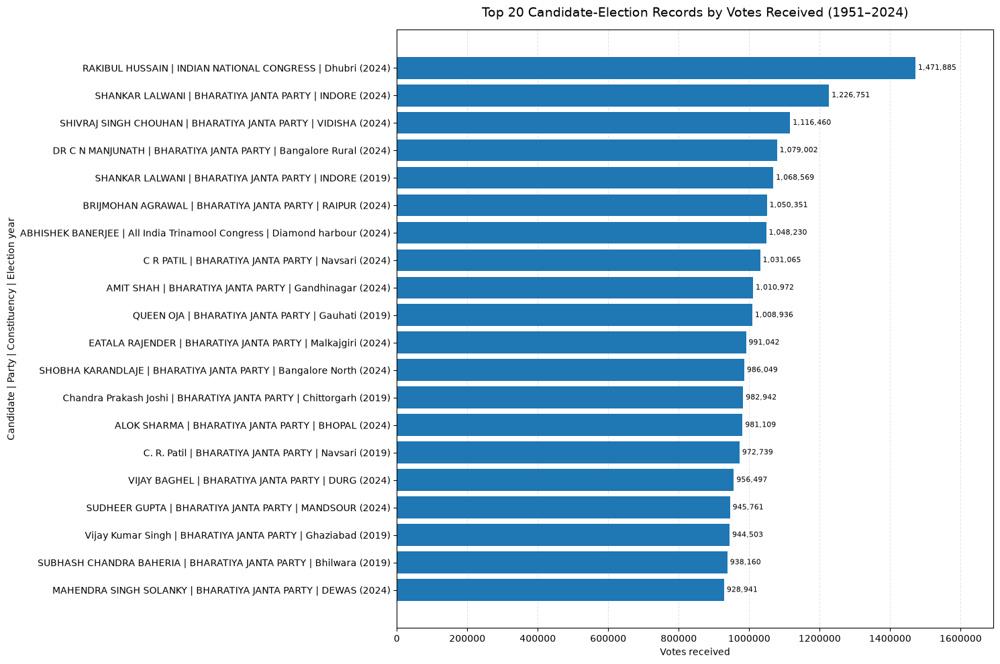

Chart saved to: outputs/candidate_electoral_competition/26_candidates_most_votes\top_20_candidates_by_votes.png


In [67]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------
# Analysis 26: Candidates receiving the most votes
# --------------------------------------------

output_dir = "outputs/candidate_electoral_competition/26_candidates_most_votes"
os.makedirs(output_dir, exist_ok=True)

# Work on a copy; leave the original df unchanged
work = df.copy()

# Convert required columns to appropriate types
work["YEAR"] = pd.to_numeric(work["YEAR"], errors="coerce")
work["VOTES"] = pd.to_numeric(work["VOTES"], errors="coerce")

# Keep records with valid candidate names, years, and votes
work = work.dropna(
    subset=["CANDIDATE", "YEAR", "VOTES"]
).copy()

work["CANDIDATE"] = work["CANDIDATE"].astype(str).str.strip()
work["PARTY"] = work["PARTY"].fillna("Unknown").astype(str).str.strip()
work["STATE UT"] = work["STATE UT"].fillna("Unknown").astype(str).str.strip()
work["CONSTITUENCY NAME"] = (
    work["CONSTITUENCY NAME"].fillna("Unknown").astype(str).str.strip()
)

# Rank individual candidate-election records by votes
top_candidates = (
    work.sort_values("VOTES", ascending=False)
    .head(20)
    .copy()
)

# Create descriptive labels for the chart
top_candidates["LABEL"] = (
    top_candidates["CANDIDATE"]
    + " | "
    + top_candidates["PARTY"]
    + " | "
    + top_candidates["CONSTITUENCY NAME"]
    + " ("
    + top_candidates["YEAR"].astype(int).astype(str)
    + ")"
)

# Save the ranked table for review in the notebook
display(
    top_candidates[
        [
            "YEAR",
            "STATE UT",
            "CONSTITUENCY NAME",
            "CANDIDATE",
            "PARTY",
            "VOTES",
            "RESULT POSITION"
        ]
    ].reset_index(drop=True)
)

# Plot horizontal bars in ascending order so the highest is at the top
plot_data = top_candidates.sort_values("VOTES", ascending=True)

fig, ax = plt.subplots(figsize=(15, 10))

bars = ax.barh(
    plot_data["LABEL"],
    plot_data["VOTES"]
)

# Add vote-count labels
for bar, votes in zip(bars, plot_data["VOTES"]):
    ax.text(
        bar.get_width() + max(plot_data["VOTES"].max() * 0.005, 1),
        bar.get_y() + bar.get_height() / 2,
        f"{votes:,.0f}",
        va="center",
        fontsize=8
    )

ax.set_title(
    "Top 20 Candidate-Election Records by Votes Received (1951–2024)",
    fontsize=14,
    pad=14
)
ax.set_xlabel("Votes received")
ax.set_ylabel("Candidate | Party | Constituency | Election year")

ax.ticklabel_format(style="plain", axis="x")
ax.set_xlim(0, plot_data["VOTES"].max() * 1.15)
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

plt.tight_layout()

chart_path = os.path.join(output_dir, "top_20_candidates_by_votes.png")
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Chart saved to: {chart_path}")

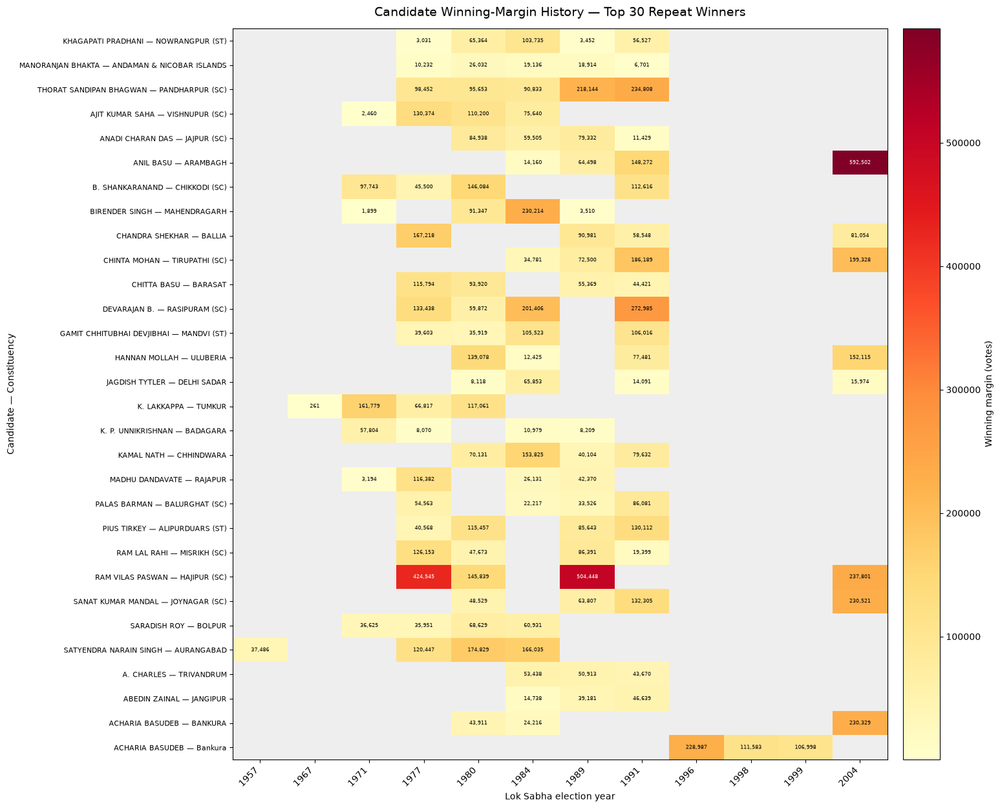

Heatmap saved to: outputs/candidate_electoral_competition/27_candidate_margin_history\candidate_winning_margin_history_heatmap.png
Candidates displayed: 30
Election years covered: 12


In [68]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# Analysis 27: Candidate winning-margin history
# Single heatmap for repeat winners
# --------------------------------------------------

output_dir = "outputs/candidate_electoral_competition/27_candidate_margin_history"
os.makedirs(output_dir, exist_ok=True)

work = df.copy()

# Convert required columns to numeric
work["YEAR"] = pd.to_numeric(work["YEAR"], errors="coerce")
work["MARGIN VOTES"] = pd.to_numeric(
    work["MARGIN VOTES"], errors="coerce"
)

# Identify winner records, including Winner 1 and Winner 2
winner_mask = (
    work["RESULT POSITION"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.match(r"^winner(?:\s+\d+)?$")
)

winners = work.loc[winner_mask].dropna(
    subset=[
        "YEAR",
        "CANDIDATE",
        "CONSTITUENCY NAME",
        "MARGIN VOTES"
    ]
).copy()

# Clean text columns
for col in ["CANDIDATE", "CONSTITUENCY NAME", "PARTY"]:
    winners[col] = winners[col].fillna("Unknown").astype(str).str.strip()

# One record per constituency per election
candidate_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

winners = (
    winners.sort_values("YEAR")
    .drop_duplicates(candidate_keys)
    .copy()
)

# Candidate + constituency combination
winners["CANDIDATE_CONSTITUENCY"] = (
    winners["CANDIDATE"] + " — " + winners["CONSTITUENCY NAME"]
)

# Count recorded wins for each candidate/constituency combination
win_counts = (
    winners.groupby("CANDIDATE_CONSTITUENCY")
    .size()
    .rename("ELECTIONS_WON")
)

# Keep candidates with at least two recorded wins
repeat_names = win_counts[win_counts >= 2]

if repeat_names.empty:
    print("No repeat winners found with valid winning margins.")
else:
    repeat_winners = winners[
        winners["CANDIDATE_CONSTITUENCY"].isin(repeat_names.index)
    ].copy()

    # Select top 30 by number of recorded wins.
    # Ties are resolved by candidate/constituency label.
    top_candidates = (
        repeat_names.rename_axis("CANDIDATE_CONSTITUENCY")
        .reset_index()
        .sort_values(
            ["ELECTIONS_WON", "CANDIDATE_CONSTITUENCY"],
            ascending=[False, True]
        )
        .head(30)["CANDIDATE_CONSTITUENCY"]
        .tolist()
    )

    selected = repeat_winners[
        repeat_winners["CANDIDATE_CONSTITUENCY"].isin(top_candidates)
    ].copy()

    # Construct matrix: rows = candidates, columns = election years
    heatmap_data = selected.pivot_table(
        index="CANDIDATE_CONSTITUENCY",
        columns="YEAR",
        values="MARGIN VOTES",
        aggfunc="first"
    )

    # Preserve candidate ranking in the chart
    heatmap_data = heatmap_data.reindex(top_candidates)

    # Sort election years chronologically
    heatmap_data = heatmap_data.reindex(
        sorted(heatmap_data.columns),
        axis=1
    )

    # Dynamic height for readability
    fig_height = max(8, len(heatmap_data) * 0.42)

    fig, ax = plt.subplots(figsize=(16, fig_height))

    values = heatmap_data.to_numpy(dtype=float)
    masked_values = np.ma.masked_invalid(values)

    image = ax.imshow(
        masked_values,
        aspect="auto",
        interpolation="nearest",
        cmap="YlOrRd"
    )

    # Axis labels
    ax.set_xticks(np.arange(len(heatmap_data.columns)))
    ax.set_xticklabels(
        [str(int(year)) for year in heatmap_data.columns],
        rotation=45,
        ha="right"
    )

    ax.set_yticks(np.arange(len(heatmap_data.index)))
    ax.set_yticklabels(heatmap_data.index, fontsize=8)

    ax.set_title(
        "Candidate Winning-Margin History — Top 30 Repeat Winners",
        fontsize=14,
        pad=14
    )
    ax.set_xlabel("Lok Sabha election year")
    ax.set_ylabel("Candidate — Constituency")

    # Add margin values inside cells where data exists
    max_value = np.nanmax(values) if np.isfinite(values).any() else 0

    for row in range(values.shape[0]):
        for col in range(values.shape[1]):
            value = values[row, col]

            if np.isfinite(value):
                text_color = "white" if value > max_value * 0.55 else "black"

                ax.text(
                    col,
                    row,
                    f"{value:,.0f}",
                    ha="center",
                    va="center",
                    fontsize=6,
                    color=text_color
                )

    # Color scale
    colorbar = fig.colorbar(image, ax=ax, pad=0.02)
    colorbar.set_label("Winning margin (votes)")

    # Make missing values visually distinct
    ax.set_facecolor("#eeeeee")

    plt.tight_layout()

    chart_path = os.path.join(
        output_dir,
        "candidate_winning_margin_history_heatmap.png"
    )

    plt.savefig(chart_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Heatmap saved to: {chart_path}")
    print(f"Candidates displayed: {len(heatmap_data)}")
    print(f"Election years covered: {len(heatmap_data.columns)}")

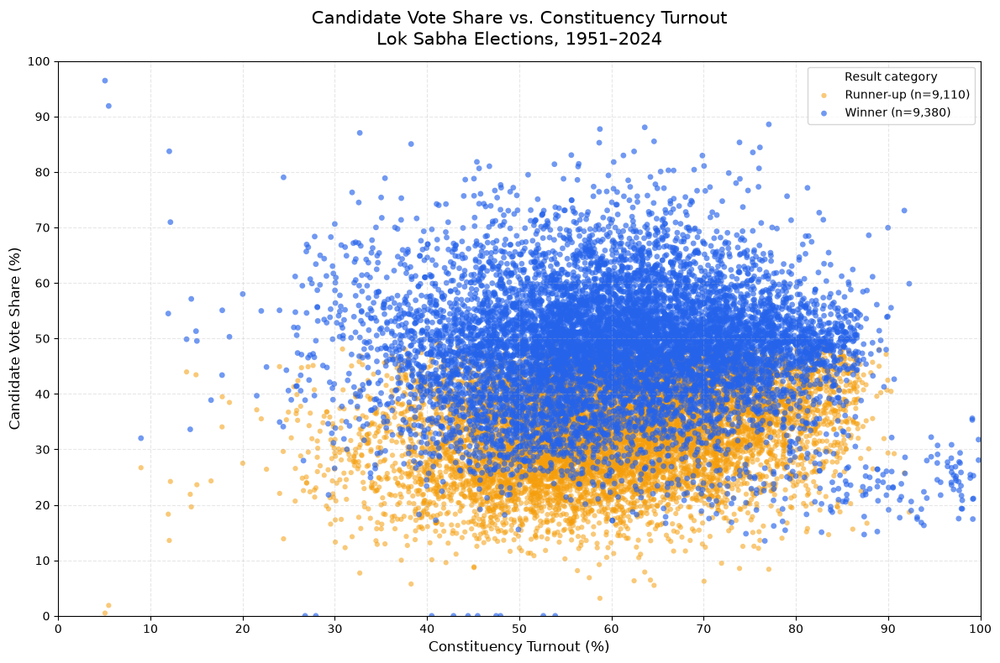

Analysis 28 completed.
Valid candidate records plotted: 18,490
Election years covered: 18
Year range: 1951–2024
Chart saved to: outputs/candidate_electoral_competition/28_candidate_vote_share_vs_turnout\candidate_vote_share_vs_constituency_turnout.png

Records plotted by result category:
RESULT CATEGORY
Winner       9380
Runner-up    9110


In [69]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# ANALYSIS 28: Candidate Vote Share vs. Constituency Turnout
# ============================================================

OUTPUT_DIR = (
    "outputs/candidate_electoral_competition/"
    "28_candidate_vote_share_vs_turnout"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_FILE = os.path.join(
    OUTPUT_DIR,
    "candidate_vote_share_vs_constituency_turnout.png"
)

# Work on a copy; preserve the original cleaned dataframe
work = df.copy()

# Convert relevant columns to numeric
numeric_columns = [
    "YEAR",
    "VOTES",
    "TOTAL VOTED",
    "TOTAL ELECTORS",
    "CALCULATED TURNOUT"
]

for col in numeric_columns:
    if col in work.columns:
        work[col] = pd.to_numeric(work[col], errors="coerce")

# Normalize result labels for classification
result = (
    work["RESULT POSITION"]
    .astype("string")
    .str.strip()
    .str.lower()
)

winner_mask = result.str.match(r"^winner(?:\s+\d+)?$", na=False)
runner_mask = result.eq("runner")

work["RESULT CATEGORY"] = "Other candidates"
work.loc[runner_mask, "RESULT CATEGORY"] = "Runner-up"
work.loc[winner_mask, "RESULT CATEGORY"] = "Winner"

# Calculate candidate vote share
work["CANDIDATE VOTE SHARE"] = np.where(
    work["TOTAL VOTED"] > 0,
    work["VOTES"] / work["TOTAL VOTED"] * 100,
    np.nan
)

# Use calculated turnout if available; otherwise calculate it
if "CALCULATED TURNOUT" in work.columns:
    work["CONSTITUENCY TURNOUT"] = work["CALCULATED TURNOUT"]

    fallback_mask = (
        work["CONSTITUENCY TURNOUT"].isna()
        & (work["TOTAL ELECTORS"] > 0)
        & work["TOTAL VOTED"].notna()
    )

    work.loc[fallback_mask, "CONSTITUENCY TURNOUT"] = (
        work.loc[fallback_mask, "TOTAL VOTED"]
        / work.loc[fallback_mask, "TOTAL ELECTORS"]
        * 100
    )
else:
    work["CONSTITUENCY TURNOUT"] = np.where(
        work["TOTAL ELECTORS"] > 0,
        work["TOTAL VOTED"] / work["TOTAL ELECTORS"] * 100,
        np.nan
    )

# Keep valid percentages only
plot_data = work[
    work["CANDIDATE VOTE SHARE"].between(0, 100)
    & work["CONSTITUENCY TURNOUT"].between(0, 100)
].copy()

if plot_data.empty:
    raise ValueError(
        "No valid records available for this analysis. "
        "Check VOTES, TOTAL VOTED, TOTAL ELECTORS, and turnout columns."
    )

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 8))

category_settings = [
    ("Other candidates", "#9CA3AF", 12, 0.25),
    ("Runner-up", "#F59E0B", 20, 0.55),
    ("Winner", "#2563EB", 24, 0.65)
]

for category, color, size, alpha in category_settings:
    subset = plot_data[plot_data["RESULT CATEGORY"] == category]

    if not subset.empty:
        ax.scatter(
            subset["CONSTITUENCY TURNOUT"],
            subset["CANDIDATE VOTE SHARE"],
            label=f"{category} (n={len(subset):,})",
            color=color,
            s=size,
            alpha=alpha,
            edgecolors="none",
            rasterized=True
        )

ax.set_title(
    "Candidate Vote Share vs. Constituency Turnout\n"
    "Lok Sabha Elections, 1951–2024",
    fontsize=15,
    pad=14
)
ax.set_xlabel("Constituency Turnout (%)", fontsize=12)
ax.set_ylabel("Candidate Vote Share (%)", fontsize=12)

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_xticks(range(0, 101, 10))
ax.set_yticks(range(0, 101, 10))

ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(title="Result category", loc="upper right", frameon=True)

fig.tight_layout()
fig.savefig(OUTPUT_FILE, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
print("Analysis 28 completed.")
print(f"Valid candidate records plotted: {len(plot_data):,}")
print(f"Election years covered: {plot_data['YEAR'].nunique()}")
print(f"Year range: {plot_data['YEAR'].min():.0f}–{plot_data['YEAR'].max():.0f}")
print(f"Chart saved to: {OUTPUT_FILE}")

print("\nRecords plotted by result category:")
print(plot_data["RESULT CATEGORY"].value_counts().to_string())


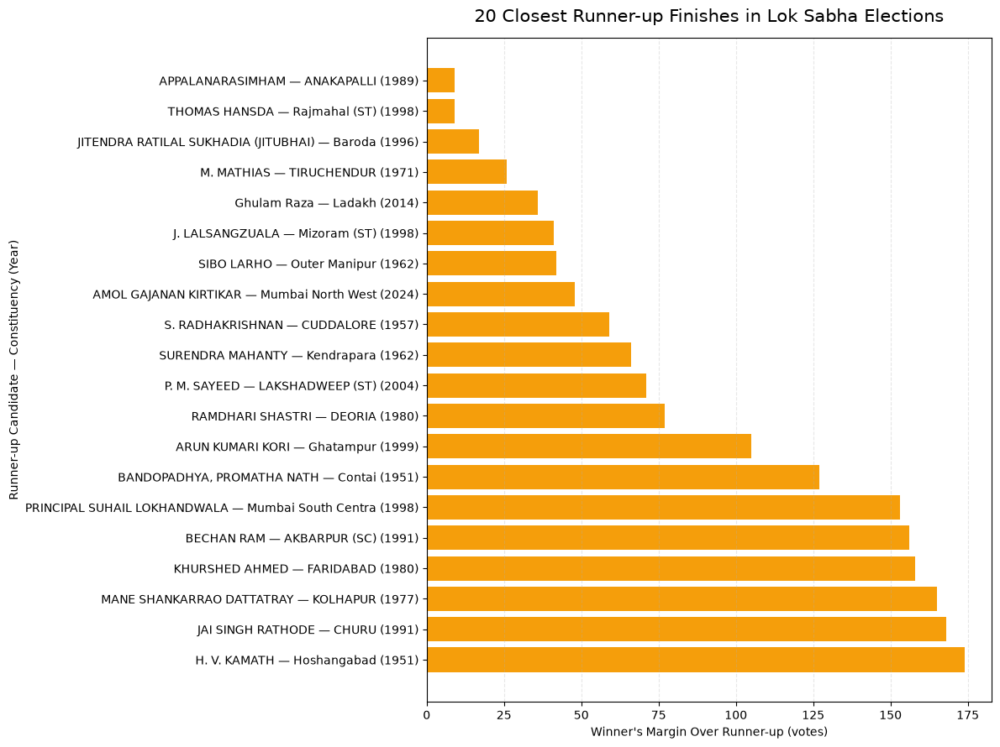

Chart 1 saved: outputs/candidate_electoral_competition/29_runner_up_patterns\29_1_closest_runner_up_finishes.png


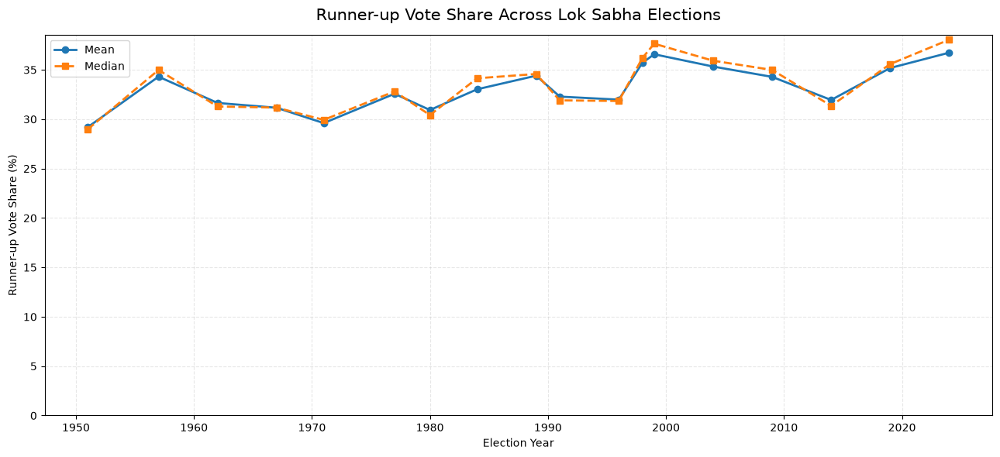

Chart 2 saved: outputs/candidate_electoral_competition/29_runner_up_patterns\29_2_runner_up_vote_share_over_time.png


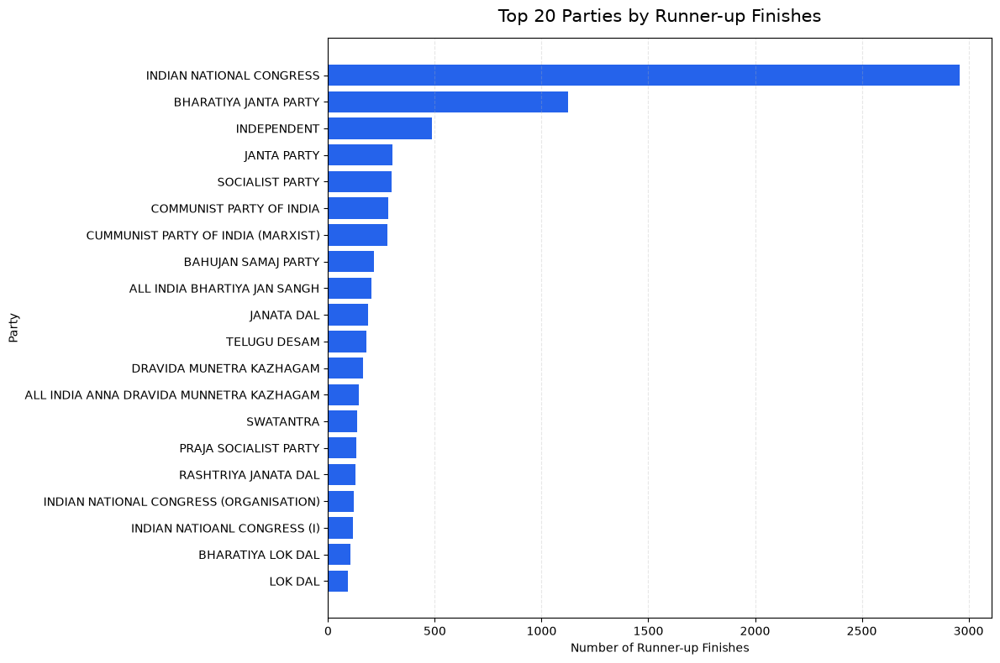

Chart 3 saved: outputs/candidate_electoral_competition/29_runner_up_patterns\29_3_parties_with_most_runner_up_finishes.png

Analysis 29 completed.
Runner-up records analyzed: 9,110
Election years covered: 18
Year range: 1951–2024

Top 10 parties by runner-up finishes:
PARTY
INDIAN NATIONAL CONGRESS              2960
BHARATIYA JANTA PARTY                 1124
INDEPENDENT                            488
JANTA PARTY                            300
SOCIALIST PARTY                        298
COMMUNIST PARTY OF INDIA               282
CUMMUNIST PARTY OF INDIA (MARXIST)     278
BAHUJAN SAMAJ PARTY                    216
ALL INDIA BHARTIYA JAN SANGH           204
JANATA DAL                             187


In [70]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# ANALYSIS 29: RUNNER-UP PATTERNS
# ============================================================

OUTPUT_DIR = (
    "outputs/candidate_electoral_competition/"
    "29_runner_up_patterns"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Work on a copy
work = df.copy()

# Convert relevant columns to numeric
numeric_columns = [
    "YEAR",
    "VOTES",
    "MARGIN VOTES",
    "MARGIN PERCENT",
    "TOTAL VOTED"
]

for col in numeric_columns:
    if col in work.columns:
        work[col] = pd.to_numeric(work[col], errors="coerce")

# Normalize result labels
result = (
    work["RESULT POSITION"]
    .astype("string")
    .str.strip()
    .str.lower()
)

work["IS_RUNNER_UP"] = result.eq("runner")

runners = work[
    work["IS_RUNNER_UP"]
    & work["YEAR"].notna()
    & work["CANDIDATE"].notna()
    & work["PARTY"].notna()
].copy()

if runners.empty:
    raise ValueError(
        "No runner-up records found. Check RESULT POSITION "
        "and confirm runner-up labels are standardized to 'runner'."
    )

# Avoid counting duplicated runner-up records within a constituency-election
constituency_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

dedupe_keys = constituency_keys + ["CANDIDATE", "PARTY"]
runners = runners.drop_duplicates(subset=dedupe_keys)

# ============================================================
# CHART 1: CLOSEST RUNNER-UP FINISHES
# ============================================================

# Margin is the winner's lead over the runner-up.
# Smaller margins mean closer contests.
if "MARGIN VOTES" in runners.columns:
    closest = runners.dropna(subset=["MARGIN VOTES"]).copy()
    closest = closest[closest["MARGIN VOTES"] >= 0]

    closest = closest.nsmallest(20, "MARGIN VOTES")

    if not closest.empty:
        closest["LABEL"] = (
            closest["CANDIDATE"].astype(str)
            + " — "
            + closest["CONSTITUENCY NAME"].astype(str)
            + " ("
            + closest["YEAR"].astype(int).astype(str)
            + ")"
        )

        fig, ax = plt.subplots(figsize=(12, 9))

        ax.barh(
            closest["LABEL"][::-1],
            closest["MARGIN VOTES"][::-1],
            color="#F59E0B"
        )

        ax.set_title(
            "20 Closest Runner-up Finishes in Lok Sabha Elections",
            fontsize=15,
            pad=14
        )
        ax.set_xlabel("Winner's Margin Over Runner-up (votes)")
        ax.set_ylabel("Runner-up Candidate — Constituency (Year)")
        ax.grid(axis="x", linestyle="--", alpha=0.3)

        fig.tight_layout()
        path = os.path.join(
            OUTPUT_DIR,
            "29_1_closest_runner_up_finishes.png"
        )
        fig.savefig(path, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        print(f"Chart 1 saved: {path}")
    else:
        print("Chart 1 skipped: no valid non-negative margins found.")

# ============================================================
# CHART 2: AVERAGE RUNNER-UP VOTE SHARE BY ELECTION
# ============================================================

if "TOTAL VOTED" in runners.columns:
    runners["RUNNER_UP_VOTE_SHARE"] = np.where(
        runners["TOTAL VOTED"] > 0,
        runners["VOTES"] / runners["TOTAL VOTED"] * 100,
        np.nan
    )

    valid_share = runners[
        runners["RUNNER_UP_VOTE_SHARE"].between(0, 100)
    ].copy()

    yearly_share = (
        valid_share.groupby("YEAR")
        .agg(
            AVG_RUNNER_UP_SHARE=("RUNNER_UP_VOTE_SHARE", "mean"),
            MEDIAN_RUNNER_UP_SHARE=("RUNNER_UP_VOTE_SHARE", "median"),
            RUNNER_UP_RECORDS=("RUNNER_UP_VOTE_SHARE", "count")
        )
        .reset_index()
        .sort_values("YEAR")
    )

    if not yearly_share.empty:
        fig, ax = plt.subplots(figsize=(13, 6))

        ax.plot(
            yearly_share["YEAR"],
            yearly_share["AVG_RUNNER_UP_SHARE"],
            marker="o",
            linewidth=2,
            label="Mean"
        )

        ax.plot(
            yearly_share["YEAR"],
            yearly_share["MEDIAN_RUNNER_UP_SHARE"],
            marker="s",
            linewidth=2,
            linestyle="--",
            label="Median"
        )

        ax.set_title(
            "Runner-up Vote Share Across Lok Sabha Elections",
            fontsize=15,
            pad=14
        )
        ax.set_xlabel("Election Year")
        ax.set_ylabel("Runner-up Vote Share (%)")
        ax.set_ylim(bottom=0)
        ax.grid(True, linestyle="--", alpha=0.3)
        ax.legend()

        fig.tight_layout()
        path = os.path.join(
            OUTPUT_DIR,
            "29_2_runner_up_vote_share_over_time.png"
        )
        fig.savefig(path, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        print(f"Chart 2 saved: {path}")
    else:
        print("Chart 2 skipped: no valid runner-up vote shares found.")

# ============================================================
# CHART 3: PARTIES WITH THE MOST RUNNER-UP FINISHES
# ============================================================

party_runner_counts = (
    runners.groupby("PARTY")
    .size()
    .sort_values(ascending=False)
)

top_parties = party_runner_counts.head(20).sort_values()

if not top_parties.empty:
    fig, ax = plt.subplots(figsize=(12, 8))

    ax.barh(
        top_parties.index.astype(str),
        top_parties.values,
        color="#2563EB"
    )

    ax.set_title(
        "Top 20 Parties by Runner-up Finishes",
        fontsize=15,
        pad=14
    )
    ax.set_xlabel("Number of Runner-up Finishes")
    ax.set_ylabel("Party")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

    fig.tight_layout()
    path = os.path.join(
        OUTPUT_DIR,
        "29_3_parties_with_most_runner_up_finishes.png"
    )
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Chart 3 saved: {path}")

# ============================================================
# SUMMARY
# ============================================================

print("\nAnalysis 29 completed.")
print(f"Runner-up records analyzed: {len(runners):,}")
print(f"Election years covered: {runners['YEAR'].nunique()}")
print(
    f"Year range: {runners['YEAR'].min():.0f}–"
    f"{runners['YEAR'].max():.0f}"
)

print("\nTop 10 parties by runner-up finishes:")
print(party_runner_counts.head(10).to_string())


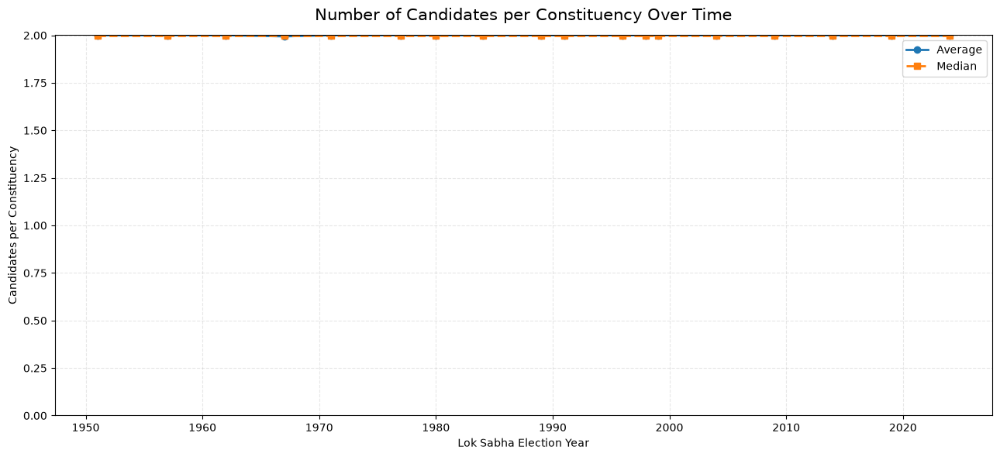

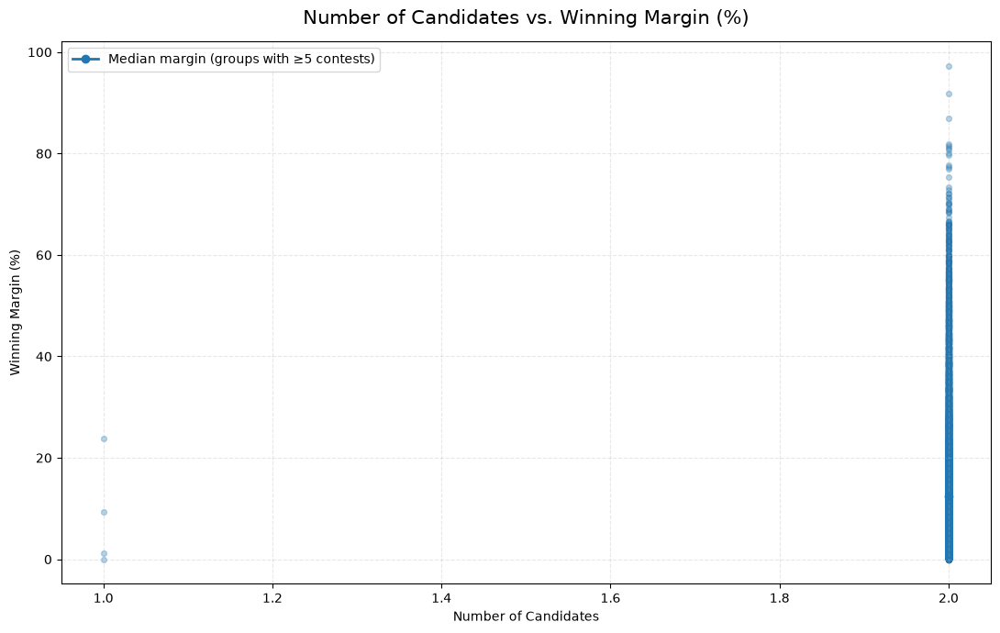

Chart 2 saved: outputs/candidate_electoral_competition/30_multi_candidate_contests\30_2_candidate_count_vs_winning_margin.png


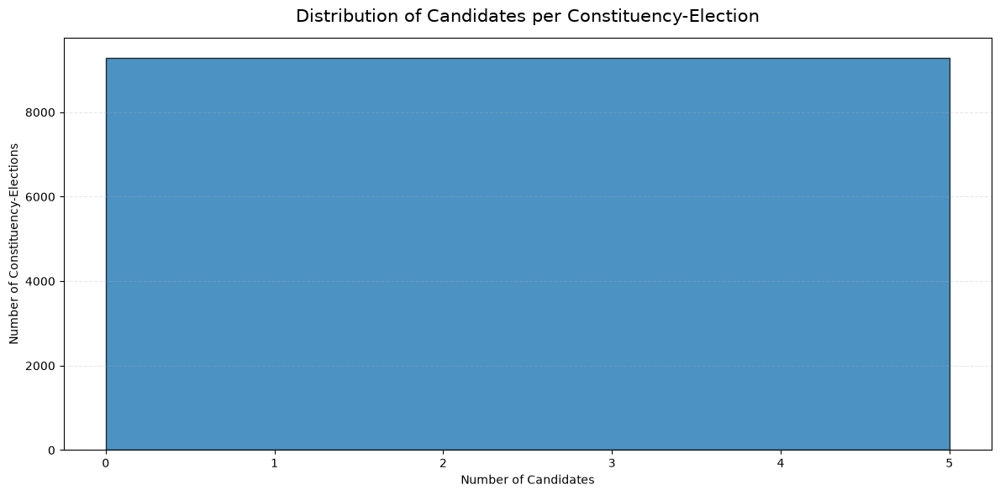


Analysis 30 completed.
Constituency-election records: 9,289
Election years covered: 18
Year range: 1951–2024
Average candidates per constituency: 2.00
Median candidates per constituency: 2
Minimum candidates in a constituency-election: 1
Maximum candidates in a constituency-election: 2

Charts saved:
outputs/candidate_electoral_competition/30_multi_candidate_contests\30_1_candidates_per_constituency_over_time.png
outputs/candidate_electoral_competition/30_multi_candidate_contests\30_2_candidate_count_vs_winning_margin.png
outputs/candidate_electoral_competition/30_multi_candidate_contests\30_3_candidate_count_distribution.png


In [71]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# ANALYSIS 30: MULTI-CANDIDATE CONTESTS
# ============================================================

OUTPUT_DIR = (
    "outputs/candidate_electoral_competition/"
    "30_multi_candidate_contests"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

work = df.copy()

# Convert numeric columns
for col in [
    "YEAR",
    "VOTES",
    "MARGIN VOTES",
    "MARGIN PERCENT",
    "TOTAL VOTED",
    "TOTAL ELECTORS"
]:
    if col in work.columns:
        work[col] = pd.to_numeric(work[col], errors="coerce")

# One record per candidate in each constituency-election.
# Historical constituency names and boundaries can change over time.
constituency_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

required = constituency_keys + ["CANDIDATE"]
missing = [col for col in required if col not in work.columns]

if missing:
    raise KeyError(f"Missing required columns: {missing}")

candidate_records = work.dropna(
    subset=constituency_keys + ["CANDIDATE"]
).drop_duplicates(
    subset=constituency_keys + ["CANDIDATE"]
)

# Count candidates per constituency-election
candidate_counts = (
    candidate_records.groupby(constituency_keys)
    .agg(
        CANDIDATE_COUNT=("CANDIDATE", "nunique")
    )
    .reset_index()
)

# Attach one constituency-level margin record.
# Winner labels include Winner, Winner 1, Winner 2, etc.
result = (
    work["RESULT POSITION"]
    .astype("string")
    .str.strip()
    .str.lower()
)

winner_rows = work[
    result.str.match(r"^winner(?:\s+\d+)?$", na=False)
].copy()

# Use one margin per constituency-election.
# This avoids counting the same contest margin multiple times.
margin_cols = constituency_keys + [
    col for col in ["MARGIN VOTES", "MARGIN PERCENT"]
    if col in winner_rows.columns
]

winner_margins = winner_rows[margin_cols].copy()

for col in ["MARGIN VOTES", "MARGIN PERCENT"]:
    if col in winner_margins.columns:
        winner_margins[col] = pd.to_numeric(
            winner_margins[col], errors="coerce"
        )

winner_margins = winner_margins.drop_duplicates(
    subset=constituency_keys
)

contest_data = candidate_counts.merge(
    winner_margins,
    on=constituency_keys,
    how="left"
)

contest_data["YEAR"] = pd.to_numeric(
    contest_data["YEAR"], errors="coerce"
)

if contest_data.empty:
    raise ValueError("No constituency-election records were found.")

# ============================================================
# CHART 1: AVERAGE CANDIDATES PER CONSTITUENCY OVER TIME
# ============================================================

yearly_candidates = (
    contest_data.groupby("YEAR")
    .agg(
        AVERAGE_CANDIDATES=("CANDIDATE_COUNT", "mean"),
        MEDIAN_CANDIDATES=("CANDIDATE_COUNT", "median"),
        CONSTITUENCIES=("CANDIDATE_COUNT", "size")
    )
    .reset_index()
    .sort_values("YEAR")
)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    yearly_candidates["YEAR"],
    yearly_candidates["AVERAGE_CANDIDATES"],
    marker="o",
    linewidth=2,
    label="Average"
)

ax.plot(
    yearly_candidates["YEAR"],
    yearly_candidates["MEDIAN_CANDIDATES"],
    marker="s",
    linewidth=2,
    linestyle="--",
    label="Median"
)

ax.set_title(
    "Number of Candidates per Constituency Over Time",
    fontsize=15,
    pad=14
)
ax.set_xlabel("Lok Sabha Election Year")
ax.set_ylabel("Candidates per Constituency")
ax.set_ylim(bottom=0)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend()

fig.tight_layout()
path1 = os.path.join(
    OUTPUT_DIR,
    "30_1_candidates_per_constituency_over_time.png"
)
fig.savefig(path1, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ============================================================
# CHART 2: NUMBER OF CANDIDATES VS WINNING MARGIN
# ============================================================

margin_column = (
    "MARGIN PERCENT"
    if "MARGIN PERCENT" in contest_data.columns
    else "MARGIN VOTES"
)

margin_data = contest_data.dropna(
    subset=["CANDIDATE_COUNT", margin_column]
).copy()

margin_data = margin_data[
    margin_data[margin_column] >= 0
]

if not margin_data.empty:
    fig, ax = plt.subplots(figsize=(11, 7))

    ax.scatter(
        margin_data["CANDIDATE_COUNT"],
        margin_data[margin_column],
        alpha=0.3,
        s=18,
        rasterized=True
    )

    # Median margin by candidate-count group
    grouped = (
        margin_data.groupby("CANDIDATE_COUNT")[margin_column]
        .median()
        .reset_index()
        .sort_values("CANDIDATE_COUNT")
    )

    # Display grouped median only where a count has enough contests
    group_sizes = margin_data.groupby("CANDIDATE_COUNT").size()
    grouped = grouped[
        grouped["CANDIDATE_COUNT"].map(group_sizes) >= 5
    ]

    if not grouped.empty:
        ax.plot(
            grouped["CANDIDATE_COUNT"],
            grouped[margin_column],
            marker="o",
            linewidth=2,
            label="Median margin (groups with ≥5 contests)"
        )
        ax.legend()

    title_margin = (
        "Winning Margin (%)"
        if margin_column == "MARGIN PERCENT"
        else "Winning Margin (votes)"
    )

    ax.set_title(
        f"Number of Candidates vs. {title_margin}",
        fontsize=15,
        pad=14
    )
    ax.set_xlabel("Number of Candidates")
    ax.set_ylabel(title_margin)
    ax.grid(True, linestyle="--", alpha=0.3)

    fig.tight_layout()
    path2 = os.path.join(
        OUTPUT_DIR,
        "30_2_candidate_count_vs_winning_margin.png"
    )
    fig.savefig(path2, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Chart 2 saved: {path2}")
else:
    print(
        "Chart 2 skipped: no valid winning-margin data found. "
        "Check MARGIN PERCENT and MARGIN VOTES."
    )

# ============================================================
# CHART 3: DISTRIBUTION OF CANDIDATE COUNTS
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

max_candidates = int(candidate_counts["CANDIDATE_COUNT"].max())

# Use bins of 5 candidates to make the distribution easier to read
bin_width = 5
bins = np.arange(
    0,
    max_candidates + bin_width + 1,
    bin_width
)

ax.hist(
    candidate_counts["CANDIDATE_COUNT"],
    bins=bins,
    edgecolor="black",
    alpha=0.8
)

ax.set_title(
    "Distribution of Candidates per Constituency-Election",
    fontsize=15,
    pad=14
)
ax.set_xlabel("Number of Candidates")
ax.set_ylabel("Number of Constituency-Elections")
ax.grid(axis="y", linestyle="--", alpha=0.3)

fig.tight_layout()
path3 = os.path.join(
    OUTPUT_DIR,
    "30_3_candidate_count_distribution.png"
)
fig.savefig(path3, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ============================================================
# SUMMARY
# ============================================================

print("\nAnalysis 30 completed.")
print(f"Constituency-election records: {len(candidate_counts):,}")
print(f"Election years covered: {candidate_counts['YEAR'].nunique()}")
print(
    f"Year range: {candidate_counts['YEAR'].min():.0f}–"
    f"{candidate_counts['YEAR'].max():.0f}"
)
print(
    f"Average candidates per constituency: "
    f"{candidate_counts['CANDIDATE_COUNT'].mean():.2f}"
)
print(
    f"Median candidates per constituency: "
    f"{candidate_counts['CANDIDATE_COUNT'].median():.0f}"
)
print(
    f"Minimum candidates in a constituency-election: "
    f"{candidate_counts['CANDIDATE_COUNT'].min()}"
)
print(
    f"Maximum candidates in a constituency-election: "
    f"{candidate_counts['CANDIDATE_COUNT'].max()}"
)

print("\nCharts saved:")
print(path1)
if "path2" in globals() and not margin_data.empty:
    print(path2)
print(path3)


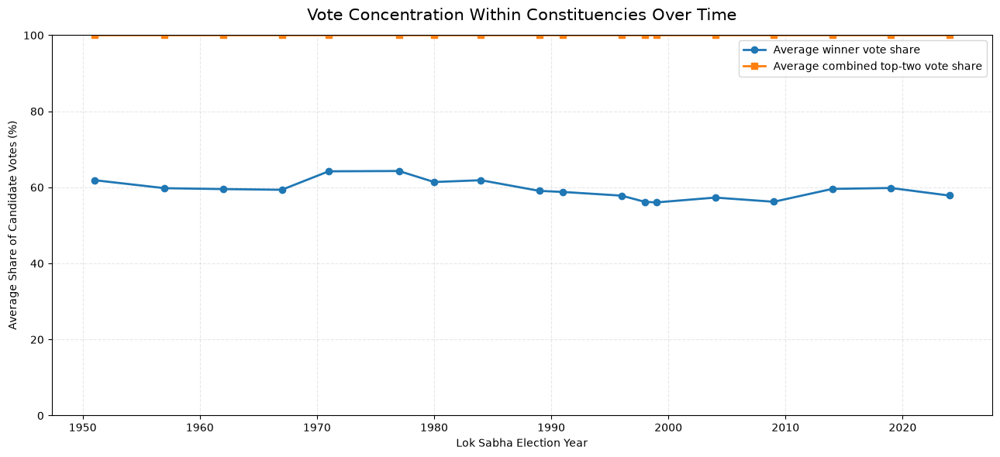

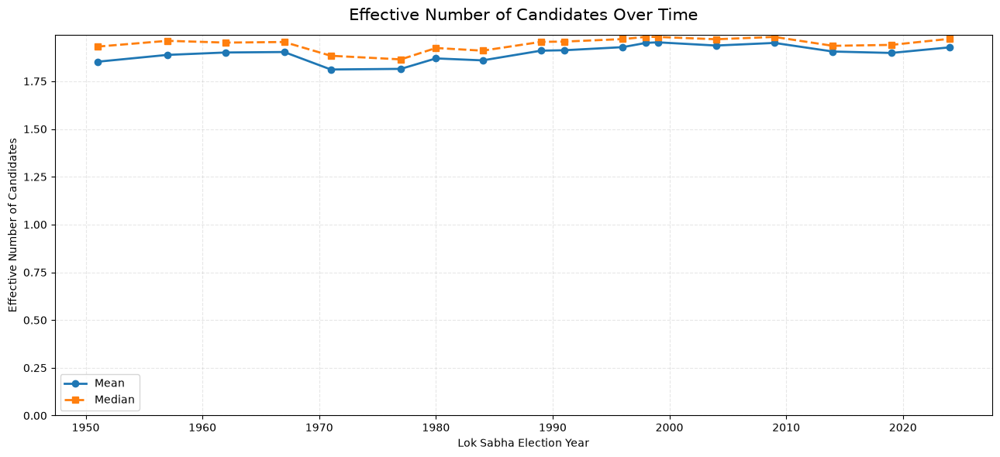

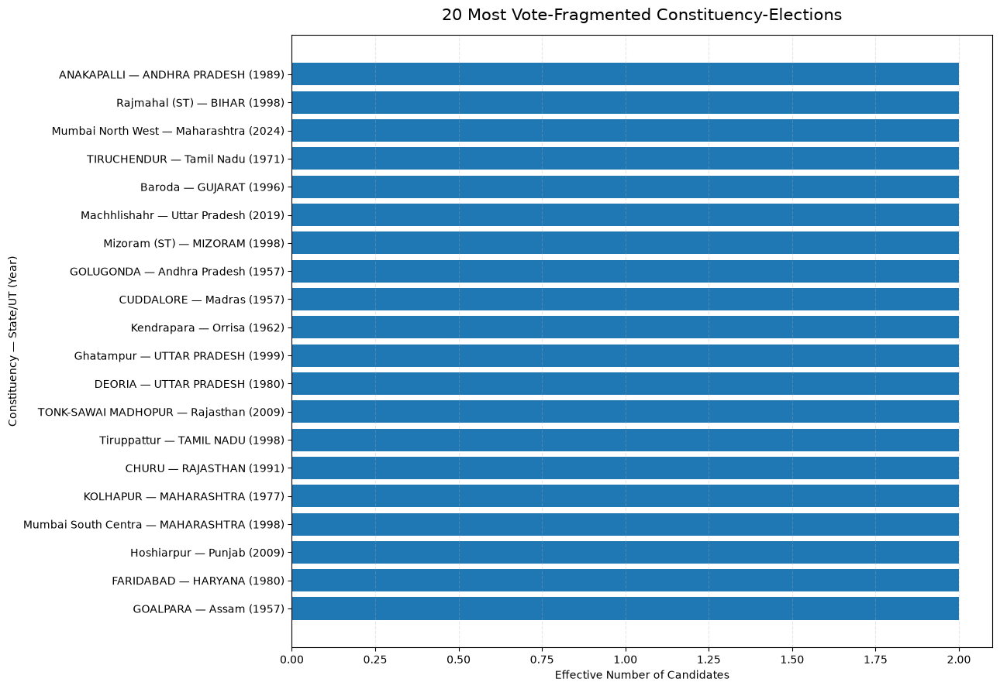

Analysis 31 completed.
Constituency-election records: 9,289
Election years covered: 18
Year range: 1951–2024

Overall mean effective number of candidates: 1.90
Overall median effective number of candidates: 1.96

Charts saved:
outputs/candidate_electoral_competition/31_vote_fragmentation\31_1_vote_concentration_over_time.png
outputs/candidate_electoral_competition/31_vote_fragmentation\31_2_effective_number_of_candidates_over_time.png
outputs/candidate_electoral_competition/31_vote_fragmentation\31_3_most_fragmented_constituencies.png

Top 10 most fragmented constituency-elections:
 YEAR       STATE UT   CONSTITUENCY NAME  CANDIDATE_COUNT  WINNER_VOTE_SHARE  EFFECTIVE_NUMBER_CANDIDATES
 1957          Assam            GOALPARA              2.0          50.027193                     1.999999
 1980        HARYANA           FARIDABAD              2.0          50.026058                     1.999999
 2009         Punjab          Hoshiarpur              2.0          50.025514                 

In [72]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# ANALYSIS 31: VOTE FRAGMENTATION WITHIN CONSTITUENCIES
# ============================================================

OUTPUT_DIR = (
    "outputs/candidate_electoral_competition/"
    "31_vote_fragmentation"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

work = df.copy()

# ------------------------------------------------------------
# 1. Prepare data
# ------------------------------------------------------------

constituency_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

required_columns = constituency_keys + ["CANDIDATE", "VOTES"]
missing_columns = [
    col for col in required_columns if col not in work.columns
]

if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

work["YEAR"] = pd.to_numeric(work["YEAR"], errors="coerce")
work["VOTES"] = pd.to_numeric(work["VOTES"], errors="coerce")

work = work.dropna(
    subset=constituency_keys + ["CANDIDATE", "VOTES"]
).copy()

# Remove duplicate candidate records within a constituency-election.
# Candidate name is used because no unique candidate ID is available.
work = work.drop_duplicates(
    subset=constituency_keys + ["CANDIDATE"]
)

# Exclude invalid negative vote counts
work = work[work["VOTES"] >= 0].copy()

# Calculate total candidate votes for each constituency-election
grouped = work.groupby(constituency_keys, dropna=False)

work["TOTAL_CANDIDATE_VOTES"] = grouped["VOTES"].transform("sum")

# Candidate vote share among all candidate votes
work["CANDIDATE_VOTE_SHARE"] = np.where(
    work["TOTAL_CANDIDATE_VOTES"] > 0,
    work["VOTES"] / work["TOTAL_CANDIDATE_VOTES"],
    np.nan
)

# ------------------------------------------------------------
# 2. Calculate constituency-level fragmentation measures
# ------------------------------------------------------------

def calculate_fragmentation(group):
    group = group.sort_values("VOTES", ascending=False)

    total_votes = group["VOTES"].sum()

    if total_votes <= 0:
        return pd.Series({
            "CANDIDATE_COUNT": group["CANDIDATE"].nunique(),
            "WINNER_VOTE_SHARE": np.nan,
            "TOP_TWO_VOTE_SHARE": np.nan,
            "EFFECTIVE_NUMBER_CANDIDATES": np.nan,
            "HHI": np.nan
        })

    shares = group["VOTES"].to_numpy(dtype=float) / total_votes

    # Winner's share of all candidate votes
    winner_share = shares[0] * 100

    # Combined share of the two highest-vote candidates
    top_two_share = shares[:2].sum() * 100

    # Herfindahl-Hirschman Index: sum of squared vote shares
    hhi = np.sum(shares ** 2)

    # Effective number of candidates
    effective_candidates = 1 / hhi if hhi > 0 else np.nan

    return pd.Series({
        "CANDIDATE_COUNT": group["CANDIDATE"].nunique(),
        "WINNER_VOTE_SHARE": winner_share,
        "TOP_TWO_VOTE_SHARE": top_two_share,
        "EFFECTIVE_NUMBER_CANDIDATES": effective_candidates,
        "HHI": hhi
    })

fragmentation = (
    work.groupby(constituency_keys, dropna=False)
    .apply(calculate_fragmentation)
    .reset_index()
)

fragmentation["YEAR"] = pd.to_numeric(
    fragmentation["YEAR"], errors="coerce"
)

fragmentation = fragmentation.dropna(subset=["YEAR"])

if fragmentation.empty:
    raise ValueError("No valid constituency-election data to analyze.")

# ============================================================
# CHART 1: VOTE CONCENTRATION OVER TIME
# ============================================================

yearly_concentration = (
    fragmentation.groupby("YEAR")
    .agg(
        MEAN_WINNER_SHARE=("WINNER_VOTE_SHARE", "mean"),
        MEAN_TOP_TWO_SHARE=("TOP_TWO_VOTE_SHARE", "mean")
    )
    .reset_index()
    .sort_values("YEAR")
)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    yearly_concentration["YEAR"],
    yearly_concentration["MEAN_WINNER_SHARE"],
    marker="o",
    linewidth=2,
    label="Average winner vote share"
)

ax.plot(
    yearly_concentration["YEAR"],
    yearly_concentration["MEAN_TOP_TWO_SHARE"],
    marker="s",
    linewidth=2,
    label="Average combined top-two vote share"
)

ax.set_title(
    "Vote Concentration Within Constituencies Over Time",
    fontsize=15,
    pad=14
)
ax.set_xlabel("Lok Sabha Election Year")
ax.set_ylabel("Average Share of Candidate Votes (%)")
ax.set_ylim(0, 100)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend()

fig.tight_layout()

path1 = os.path.join(
    OUTPUT_DIR,
    "31_1_vote_concentration_over_time.png"
)
fig.savefig(path1, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ============================================================
# CHART 2: EFFECTIVE NUMBER OF CANDIDATES OVER TIME
# ============================================================

yearly_effective = (
    fragmentation.groupby("YEAR")
    .agg(
        MEAN_EFFECTIVE_CANDIDATES=(
            "EFFECTIVE_NUMBER_CANDIDATES", "mean"
        ),
        MEDIAN_EFFECTIVE_CANDIDATES=(
            "EFFECTIVE_NUMBER_CANDIDATES", "median"
        )
    )
    .reset_index()
    .sort_values("YEAR")
)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    yearly_effective["YEAR"],
    yearly_effective["MEAN_EFFECTIVE_CANDIDATES"],
    marker="o",
    linewidth=2,
    label="Mean"
)

ax.plot(
    yearly_effective["YEAR"],
    yearly_effective["MEDIAN_EFFECTIVE_CANDIDATES"],
    marker="s",
    linewidth=2,
    linestyle="--",
    label="Median"
)

ax.set_title(
    "Effective Number of Candidates Over Time",
    fontsize=15,
    pad=14
)
ax.set_xlabel("Lok Sabha Election Year")
ax.set_ylabel("Effective Number of Candidates")
ax.set_ylim(bottom=0)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend()

fig.tight_layout()

path2 = os.path.join(
    OUTPUT_DIR,
    "31_2_effective_number_of_candidates_over_time.png"
)
fig.savefig(path2, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ============================================================
# CHART 3: MOST FRAGMENTED CONSTITUENCY-ELECTIONS
# ============================================================

most_fragmented = (
    fragmentation.dropna(
        subset=["EFFECTIVE_NUMBER_CANDIDATES"]
    )
    .sort_values(
        "EFFECTIVE_NUMBER_CANDIDATES",
        ascending=False
    )
    .head(20)
    .copy()
)

most_fragmented["LABEL"] = (
    most_fragmented["CONSTITUENCY NAME"].astype(str)
    + " — "
    + most_fragmented["STATE UT"].astype(str)
    + " ("
    + most_fragmented["YEAR"].astype(int).astype(str)
    + ")"
)

most_fragmented = most_fragmented.sort_values(
    "EFFECTIVE_NUMBER_CANDIDATES"
)

fig, ax = plt.subplots(figsize=(13, 9))

ax.barh(
    most_fragmented["LABEL"],
    most_fragmented["EFFECTIVE_NUMBER_CANDIDATES"]
)

ax.set_title(
    "20 Most Vote-Fragmented Constituency-Elections",
    fontsize=15,
    pad=14
)
ax.set_xlabel("Effective Number of Candidates")
ax.set_ylabel("Constituency — State/UT (Year)")
ax.grid(axis="x", linestyle="--", alpha=0.3)

fig.tight_layout()

path3 = os.path.join(
    OUTPUT_DIR,
    "31_3_most_fragmented_constituencies.png"
)
fig.savefig(path3, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ============================================================
# SUMMARY
# ============================================================

print("Analysis 31 completed.")
print(f"Constituency-election records: {len(fragmentation):,}")
print(f"Election years covered: {fragmentation['YEAR'].nunique()}")
print(
    f"Year range: {fragmentation['YEAR'].min():.0f}–"
    f"{fragmentation['YEAR'].max():.0f}"
)

print(
    "\nOverall mean effective number of candidates: "
    f"{fragmentation['EFFECTIVE_NUMBER_CANDIDATES'].mean():.2f}"
)

print(
    "Overall median effective number of candidates: "
    f"{fragmentation['EFFECTIVE_NUMBER_CANDIDATES'].median():.2f}"
)

print("\nCharts saved:")
print(path1)
print(path2)
print(path3)

print("\nTop 10 most fragmented constituency-elections:")
print(
    most_fragmented[
        [
            "YEAR",
            "STATE UT",
            "CONSTITUENCY NAME",
            "CANDIDATE_COUNT",
            "WINNER_VOTE_SHARE",
            "EFFECTIVE_NUMBER_CANDIDATES"
        ]
    ].to_string(index=False)
)


## 8. Data validation and quality checks



### Analysis 32 — Winner count versus official seat count



In [73]:
# ============================================================
# ANALYSIS 32: WINNER COUNT VS OFFICIAL SEAT COUNT
# Display diagnostic tables; no CSV export.
# ============================================================

import pandas as pd
import numpy as np

required = [
    "YEAR", "STATE UT", "NUMBER OF SEATS", "RESULT POSITION",
    "CONSTITUENCY NO", "CONSTITUENCY NAME"
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Missing required columns for Analysis 32: {missing}")

a32 = df[required].copy()
a32["YEAR"] = pd.to_numeric(a32["YEAR"], errors="coerce")
a32["NUMBER OF SEATS"] = pd.to_numeric(a32["NUMBER OF SEATS"], errors="coerce")
a32["RESULT POSITION"] = a32["RESULT POSITION"].astype("string").str.strip().str.lower()
a32["STATE UT"] = a32["STATE UT"].astype("string").str.strip()

winner_mask = a32["RESULT POSITION"].str.fullmatch(r"winner(?:\s+\d+)?", na=False)
winners32 = a32.loc[winner_mask].copy()

# Count winner candidate records (important for historical multi-member seats)
# and distinct constituencies separately; do not conflate the two measures.
keys32 = ["YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"]
winner_counts32 = (
    winners32.groupby(["YEAR", "STATE UT"], dropna=False)
    .agg(RECORDED_WINNER_CANDIDATES=("RESULT POSITION", "size"),
         WINNING_CONSTITUENCIES=("CONSTITUENCY NO", "nunique"))
    .reset_index()
)
official_seats32 = (
    a32.groupby(["YEAR", "STATE UT"], dropna=False)["NUMBER OF SEATS"]
    .max().rename("OFFICIAL_SEATS_RECORDED").reset_index()
)
seat_check32 = official_seats32.merge(
    winner_counts32, on=["YEAR", "STATE UT"], how="outer"
)
seat_check32["SEAT_DIFFERENCE"] = (
    seat_check32["RECORDED_WINNER_CANDIDATES"] - seat_check32["OFFICIAL_SEATS_RECORDED"]
)
seat_check32["CHECK_STATUS"] = np.select(
    [seat_check32["OFFICIAL_SEATS_RECORDED"].isna(),
     seat_check32["RECORDED_WINNER_CANDIDATES"].isna(),
     seat_check32["SEAT_DIFFERENCE"].eq(0)],
    ["Missing official seat count", "No winner records", "Matches"],
    default="Mismatch — investigate"
)

display(seat_check32.sort_values(["YEAR", "STATE UT"]))
print("State-election rows checked:", len(seat_check32))
print("Rows requiring investigation:", int((seat_check32["CHECK_STATUS"] != "Matches").sum()))
print("Note: winner candidate records and distinct constituencies are shown separately because historical multi-member constituencies may have multiple winners.")


,YEAR,STATE UT,OFFICIAL_SEATS_RECORDED,RECORDED_WINNER_CANDIDATES,WINNING_CONSTITUENCIES,SEAT_DIFFERENCE,CHECK_STATUS
0,1951,Ajmer,1,2,2,1,Mismatch — investigate
1,1951,Assam,2,12,10,10,Mismatch — investigate
2,1951,Bhopal,1,2,2,1,Mismatch — investigate
3,1951,Bihar,2,55,44,53,Mismatch — investigate
4,1951,Bombay,2,45,37,43,Mismatch — investigate
...,...,...,...,...,...,...,...
530,2024,Telangana,1,17,17,16,Mismatch — investigate
531,2024,Tripura,1,2,2,1,Mismatch — investigate
532,2024,Uttar Pradesh,1,80,80,79,Mismatch — investigate
533,2024,Uttarakhand,1,5,5,4,Mismatch — investigate


State-election rows checked: 535
Rows requiring investigation: 410
Note: winner candidate records and distinct constituencies are shown separately because historical multi-member constituencies may have multiple winners.


ANALYSIS 33: TURNOUT DISCREPANCIES
Original candidate records: 18,577
Constituency-election records checked: 9,289
Tolerance: ±0.10 percentage points

Validation status:
TURNOUT_VALIDATION_STATUS
Within tolerance    9116
Discrepancy          173

Difference summary (percentage points):
count    9289.0000
mean        0.8036
std         6.0421
min         0.0000
25%         0.0010
50%         0.0024
75%         0.0037
max        75.0825

Largest discrepancies:
 YEAR              STATE UT  CONSTITUENCY NO  CONSTITUENCY NAME  TURNOUT PERCENT  RECALCULATED_TURNOUT  TURNOUT_DIFFERENCE_PP  ABS_TURNOUT_DIFFERENCE_PP
 1957                Kerala                3             QUILON            75.09            150.172472             -75.082472                  75.082472
 1951     Travancore Cochin                4   Quilon Cum Mavel            72.87            145.747437             -72.877437                  72.877437
 1951                Madras                8              Eluru            72.

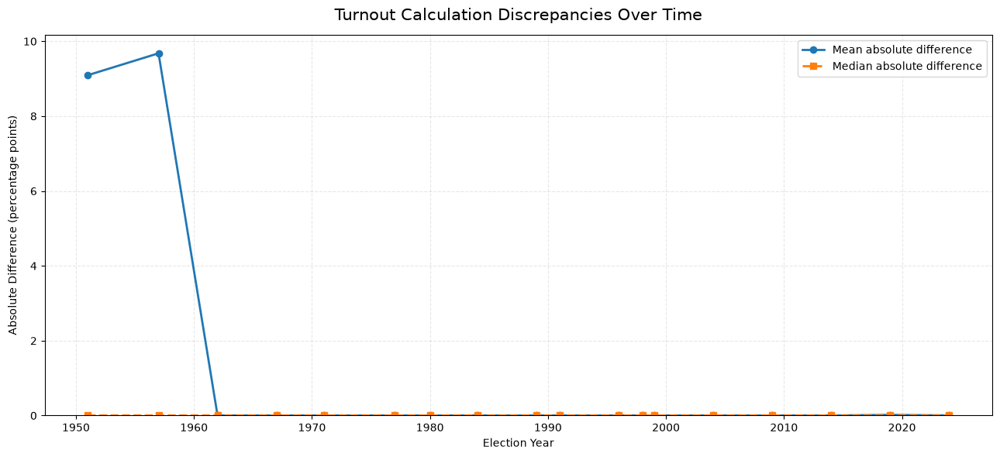


Chart 1 saved: outputs/data_quality_validation/33_turnout_discrepancies\33_1_turnout_discrepancy_over_time.png


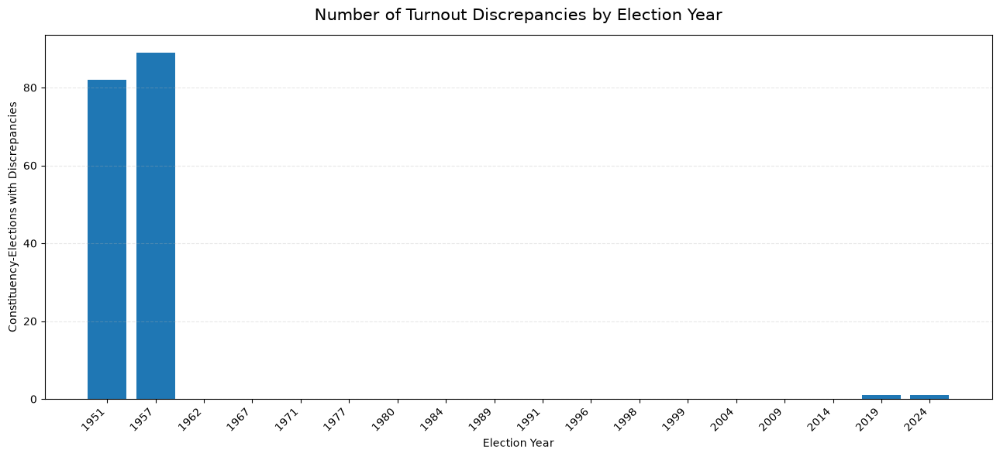

Chart 2 saved: outputs/data_quality_validation/33_turnout_discrepancies\33_2_discrepancy_count_by_year.png

Analysis 33 completed.
Discrepancy records saved: 173
Output folder: outputs/data_quality_validation/33_turnout_discrepancies


In [74]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# ANALYSIS 33: TURNOUT DISCREPANCIES
# ============================================================

OUTPUT_DIR = "outputs/data_quality_validation/33_turnout_discrepancies"
os.makedirs(OUTPUT_DIR, exist_ok=True)

work = df.copy()

# ------------------------------------------------------------
# 1. Validate required columns
# ------------------------------------------------------------

required_columns = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME",
    "TOTAL ELECTORS",
    "TOTAL VOTED",
    "TURNOUT PERCENT"
]

missing_columns = [
    col for col in required_columns if col not in work.columns
]

if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

# Convert numeric columns
numeric_columns = [
    "YEAR",
    "TOTAL ELECTORS",
    "TOTAL VOTED",
    "TURNOUT PERCENT"
]

for col in numeric_columns:
    work[col] = pd.to_numeric(work[col], errors="coerce")

# ------------------------------------------------------------
# 2. Calculate turnout independently
# ------------------------------------------------------------

valid_denominator = (
    work["TOTAL ELECTORS"].notna()
    & (work["TOTAL ELECTORS"] > 0)
    & work["TOTAL VOTED"].notna()
)

work["RECALCULATED_TURNOUT"] = np.nan

work.loc[valid_denominator, "RECALCULATED_TURNOUT"] = (
    work.loc[valid_denominator, "TOTAL VOTED"]
    / work.loc[valid_denominator, "TOTAL ELECTORS"]
    * 100
)

# Signed difference: recorded minus recalculated
work["TURNOUT_DIFFERENCE_PP"] = (
    work["TURNOUT PERCENT"] - work["RECALCULATED_TURNOUT"]
)

# Absolute difference in percentage points
work["ABS_TURNOUT_DIFFERENCE_PP"] = (
    work["TURNOUT_DIFFERENCE_PP"].abs()
)

# Threshold for identifying a discrepancy
# Small differences can arise from rounding.
TOLERANCE_PP = 0.10

work["TURNOUT_VALIDATION_STATUS"] = np.select(
    [
        work["TOTAL ELECTORS"].isna(),
        work["TOTAL VOTED"].isna(),
        work["TOTAL ELECTORS"].le(0),
        work["TURNOUT PERCENT"].isna(),
        work["ABS_TURNOUT_DIFFERENCE_PP"].le(TOLERANCE_PP),
    ],
    [
        "Missing electorate",
        "Missing votes cast",
        "Invalid electorate",
        "Missing recorded turnout",
        "Within tolerance",
    ],
    default="Discrepancy"
)

# Flag impossible values separately
impossible_mask = (
    work["TOTAL VOTED"].lt(0)
    | work["TOTAL ELECTORS"].lt(0)
    | work["TURNOUT PERCENT"].lt(0)
    | work["TURNOUT PERCENT"].gt(100)
)

work.loc[
    impossible_mask, "TURNOUT_VALIDATION_STATUS"
] = "Impossible value - investigate"

# ------------------------------------------------------------
# 3. Create constituency-election-level data
# ------------------------------------------------------------

# The source is candidate-level, so the same constituency turnout
# may appear on many candidate rows. Deduplicate to avoid counting
# one constituency-election repeatedly in yearly summaries.

constituency_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

available_keys = [
    col for col in constituency_keys if col in work.columns
]

constituency_data = work.drop_duplicates(
    subset=available_keys
).copy()

# Diagnostic file at constituency-election level
diagnostic_columns = available_keys + [
    "TOTAL ELECTORS",
    "TOTAL VOTED",
    "TURNOUT PERCENT",
    "RECALCULATED_TURNOUT",
    "TURNOUT_DIFFERENCE_PP",
    "ABS_TURNOUT_DIFFERENCE_PP",
    "TURNOUT_VALIDATION_STATUS"
]

# CSV export removed (chart/on-screen output only).

# Save discrepancy-only report
discrepancies = constituency_data[
    constituency_data["TURNOUT_VALIDATION_STATUS"].isin([
        "Discrepancy",
        "Impossible value - investigate"
    ])
].copy()

# CSV export removed (chart/on-screen output only).

# ------------------------------------------------------------
# 4. Summary statistics
# ------------------------------------------------------------

print("=" * 65)
print("ANALYSIS 33: TURNOUT DISCREPANCIES")
print("=" * 65)

print(f"Original candidate records: {len(work):,}")
print(f"Constituency-election records checked: {len(constituency_data):,}")
print(f"Tolerance: ±{TOLERANCE_PP:.2f} percentage points")

print("\nValidation status:")
print(
    constituency_data["TURNOUT_VALIDATION_STATUS"]
    .value_counts(dropna=False)
    .to_string()
)

valid_diffs = constituency_data[
    constituency_data["ABS_TURNOUT_DIFFERENCE_PP"].notna()
]

if not valid_diffs.empty:
    print("\nDifference summary (percentage points):")
    print(
        valid_diffs["ABS_TURNOUT_DIFFERENCE_PP"]
        .describe()
        .round(4)
        .to_string()
    )

print("\nLargest discrepancies:")
display_cols = available_keys + [
    "TURNOUT PERCENT",
    "RECALCULATED_TURNOUT",
    "TURNOUT_DIFFERENCE_PP",
    "ABS_TURNOUT_DIFFERENCE_PP"
]

print(
    constituency_data.nlargest(
        20, "ABS_TURNOUT_DIFFERENCE_PP"
    )[display_cols].to_string(index=False)
)

# ------------------------------------------------------------
# 5. Chart 1: turnout difference over time
# ------------------------------------------------------------

valid_for_yearly = constituency_data[
    constituency_data["YEAR"].notna()
    & constituency_data["ABS_TURNOUT_DIFFERENCE_PP"].notna()
].copy()

yearly_summary = (
    valid_for_yearly.groupby("YEAR")
    .agg(
        MEAN_ABSOLUTE_DIFFERENCE=(
            "ABS_TURNOUT_DIFFERENCE_PP", "mean"
        ),
        MEDIAN_ABSOLUTE_DIFFERENCE=(
            "ABS_TURNOUT_DIFFERENCE_PP", "median"
        ),
        RECORDS_CHECKED=(
            "ABS_TURNOUT_DIFFERENCE_PP", "count"
        ),
        DISCREPANCIES=(
            "TURNOUT_VALIDATION_STATUS",
            lambda s: s.isin([
                "Discrepancy",
                "Impossible value - investigate"
            ]).sum()
        )
    )
    .reset_index()
    .sort_values("YEAR")
)

if not yearly_summary.empty:
    fig, ax = plt.subplots(figsize=(13, 6))

    ax.plot(
        yearly_summary["YEAR"],
        yearly_summary["MEAN_ABSOLUTE_DIFFERENCE"],
        marker="o",
        linewidth=2,
        label="Mean absolute difference"
    )

    ax.plot(
        yearly_summary["YEAR"],
        yearly_summary["MEDIAN_ABSOLUTE_DIFFERENCE"],
        marker="s",
        linestyle="--",
        linewidth=2,
        label="Median absolute difference"
    )

    ax.set_title(
        "Turnout Calculation Discrepancies Over Time",
        fontsize=15,
        pad=14
    )
    ax.set_xlabel("Election Year")
    ax.set_ylabel("Absolute Difference (percentage points)")
    ax.set_ylim(bottom=0)
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.legend()

    fig.tight_layout()

    chart1_path = os.path.join(
        OUTPUT_DIR,
        "33_1_turnout_discrepancy_over_time.png"
    )
    fig.savefig(chart1_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"\nChart 1 saved: {chart1_path}")

# ------------------------------------------------------------
# 6. Chart 2: number of discrepancies by election year
# ------------------------------------------------------------

if not yearly_summary.empty:
    fig, ax = plt.subplots(figsize=(13, 6))

    ax.bar(
        yearly_summary["YEAR"].astype(int).astype(str),
        yearly_summary["DISCREPANCIES"]
    )

    ax.set_title(
        "Number of Turnout Discrepancies by Election Year",
        fontsize=15,
        pad=14
    )
    ax.set_xlabel("Election Year")
    ax.set_ylabel("Constituency-Elections with Discrepancies")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    plt.xticks(rotation=45, ha="right")

    fig.tight_layout()

    chart2_path = os.path.join(
        OUTPUT_DIR,
        "33_2_discrepancy_count_by_year.png"
    )
    fig.savefig(chart2_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Chart 2 saved: {chart2_path}")

# ------------------------------------------------------------
# 7. Final summary
# ------------------------------------------------------------

print("\nAnalysis 33 completed.")
print(f"Discrepancy records saved: {len(discrepancies):,}")
print(f"Output folder: {OUTPUT_DIR}")


ANALYSIS 34: VOTES CAST VS ELECTORATE
Constituency-election records checked: 9,289

Validation status:
VALIDATION_STATUS
Valid counts                    9246
Votes cast exceed electorate      43

Records where votes cast exceed electorate: 43

Largest excesses:
 YEAR              STATE UT  CONSTITUENCY NAME  TOTAL ELECTORS  TOTAL VOTED  EXCESS_VOTES  RECALCULATED_TURNOUT
 1957                Kerala             QUILON          801581      1203754        402173            150.172472
 1951     Travancore Cochin   Quilon Cum Mavel          705598      1028391        322793            145.747437
 1951                Madras              Eluru          694382      1000456        306074            144.078620
 1957                Bombay BOMBAY CITY CENTRA          783116      1055732        272616            134.811701
 1957                Bombay          AHMEDABAD          699036       942069        243033            134.766879
 1957                Bombay              AKOLA          779310    

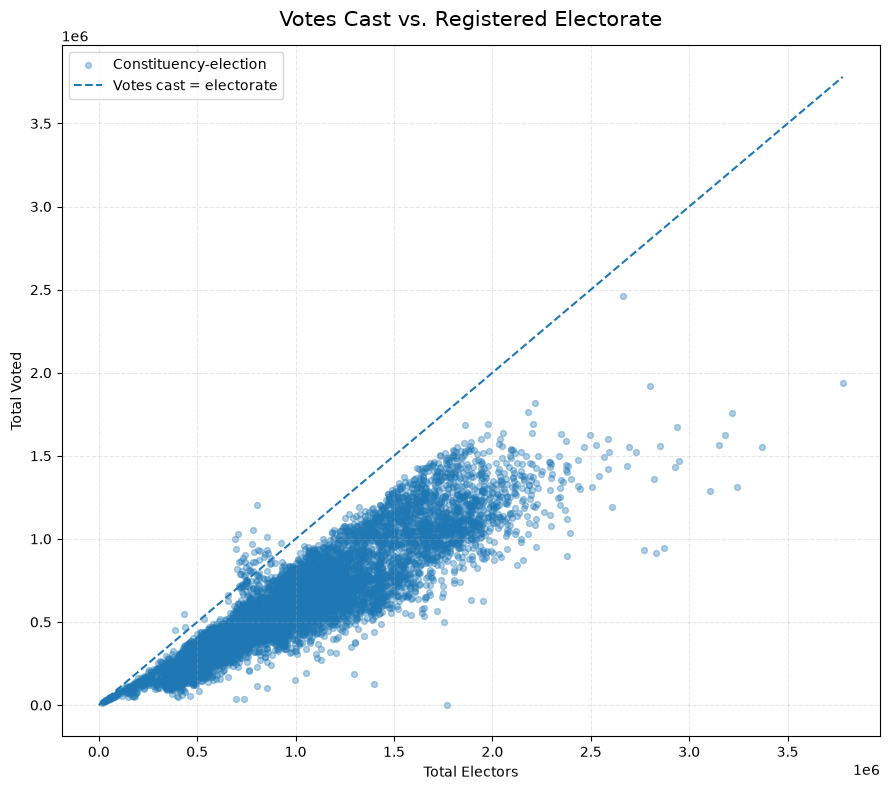


Chart 1 saved: outputs/data_quality_validation/34_votes_vs_electorate\34_1_votes_cast_vs_electorate.png


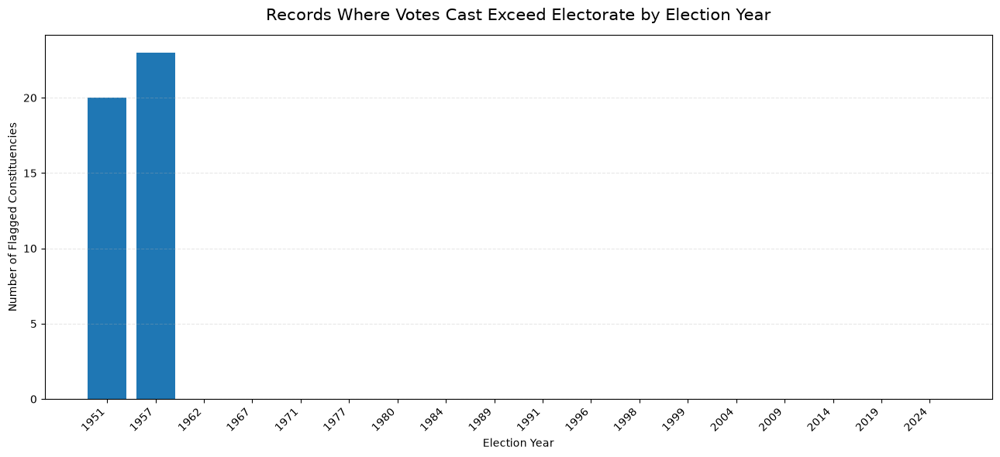

Chart 2 saved: outputs/data_quality_validation/34_votes_vs_electorate\34_2_votes_exceed_electorate_by_year.png

Analysis 34 completed.
Records needing investigation: 43
Output folder: outputs/data_quality_validation/34_votes_vs_electorate


In [75]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# ANALYSIS 34: VOTES CAST VS ELECTORATE CHECKS
# ============================================================

OUTPUT_DIR = "outputs/data_quality_validation/34_votes_vs_electorate"
os.makedirs(OUTPUT_DIR, exist_ok=True)

work = df.copy()

# ------------------------------------------------------------
# 1. Validate required columns
# ------------------------------------------------------------

required_columns = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME",
    "TOTAL ELECTORS",
    "TOTAL VOTED"
]

missing_columns = [c for c in required_columns if c not in work.columns]

if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

# Convert numeric columns
for col in ["YEAR", "TOTAL ELECTORS", "TOTAL VOTED"]:
    work[col] = pd.to_numeric(work[col], errors="coerce")

# ------------------------------------------------------------
# 2. Deduplicate to one record per constituency-election
# ------------------------------------------------------------

constituency_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

# The dataset is candidate-level, so avoid counting each candidate
# as a separate turnout/electorate observation.
constituency_data = work.drop_duplicates(
    subset=constituency_keys
).copy()

# ------------------------------------------------------------
# 3. Create validation flags
# ------------------------------------------------------------

electors = constituency_data["TOTAL ELECTORS"]
votes_cast = constituency_data["TOTAL VOTED"]

constituency_data["EXCESS_VOTES"] = votes_cast - electors

constituency_data["VALIDATION_STATUS"] = np.select(
    [
        electors.isna(),
        votes_cast.isna(),
        electors.lt(0),
        votes_cast.lt(0),
        electors.eq(0),
        votes_cast.gt(electors)
    ],
    [
        "Missing electorate",
        "Missing votes cast",
        "Negative electorate",
        "Negative votes cast",
        "Zero electorate",
        "Votes cast exceed electorate"
    ],
    default="Valid counts"
)

# Flag rows where votes exceed the electorate
constituency_data["VOTES_EXCEED_ELECTORATE"] = (
    votes_cast.notna()
    & electors.notna()
    & votes_cast.gt(electors)
)

# Percentage of electorate recorded as voting
constituency_data["RECALCULATED_TURNOUT"] = np.where(
    electors.gt(0) & votes_cast.notna(),
    votes_cast / electors * 100,
    np.nan
)

# ------------------------------------------------------------
# 4. Save diagnostic reports
# ------------------------------------------------------------

diagnostic_columns = constituency_keys + [
    "TOTAL ELECTORS",
    "TOTAL VOTED",
    "EXCESS_VOTES",
    "RECALCULATED_TURNOUT",
    "VOTES_EXCEED_ELECTORATE",
    "VALIDATION_STATUS"
]

# CSV export removed (chart/on-screen output only).

issues = constituency_data[
    constituency_data["VALIDATION_STATUS"] != "Valid counts"
].copy()

# CSV export removed (chart/on-screen output only).

# ------------------------------------------------------------
# 5. Print validation summary
# ------------------------------------------------------------

print("=" * 65)
print("ANALYSIS 34: VOTES CAST VS ELECTORATE")
print("=" * 65)

print(f"Constituency-election records checked: {len(constituency_data):,}")

print("\nValidation status:")
print(
    constituency_data["VALIDATION_STATUS"]
    .value_counts(dropna=False)
    .to_string()
)

excess_data = constituency_data[
    constituency_data["VOTES_EXCEED_ELECTORATE"]
].copy()

print(f"\nRecords where votes cast exceed electorate: {len(excess_data):,}")

if not excess_data.empty:
    print("\nLargest excesses:")
    print(
        excess_data.nlargest(20, "EXCESS_VOTES")[
            [
                "YEAR",
                "STATE UT",
                "CONSTITUENCY NAME",
                "TOTAL ELECTORS",
                "TOTAL VOTED",
                "EXCESS_VOTES",
                "RECALCULATED_TURNOUT"
            ]
        ].to_string(index=False)
    )

# ------------------------------------------------------------
# 6. Chart 1: votes cast vs electorate
# ------------------------------------------------------------

plot_data = constituency_data[
    electors.gt(0)
    & votes_cast.notna()
    & electors.notna()
    & votes_cast.ge(0)
    & electors.ge(0)
].copy()

if not plot_data.empty:
    fig, ax = plt.subplots(figsize=(9, 8))

    ax.scatter(
        plot_data["TOTAL ELECTORS"],
        plot_data["TOTAL VOTED"],
        alpha=0.35,
        s=18,
        rasterized=True,
        label="Constituency-election"
    )

    max_value = max(
        plot_data["TOTAL ELECTORS"].max(),
        plot_data["TOTAL VOTED"].max()
    )

    # Values above this line mean votes cast exceed electorate.
    ax.plot(
        [0, max_value],
        [0, max_value],
        linestyle="--",
        linewidth=1.5,
        label="Votes cast = electorate"
    )

    ax.set_title(
        "Votes Cast vs. Registered Electorate",
        fontsize=15,
        pad=14
    )
    ax.set_xlabel("Total Electors")
    ax.set_ylabel("Total Voted")
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.legend()

    fig.tight_layout()

    chart1_path = os.path.join(
        OUTPUT_DIR,
        "34_1_votes_cast_vs_electorate.png"
    )
    fig.savefig(chart1_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"\nChart 1 saved: {chart1_path}")

# ------------------------------------------------------------
# 7. Chart 2: invalid records by election year
# ------------------------------------------------------------

yearly_summary = (
    constituency_data.dropna(subset=["YEAR"])
    .groupby("YEAR")
    .agg(
        TOTAL_RECORDS=("VALIDATION_STATUS", "size"),
        VOTES_EXCEED_ELECTORATE=(
            "VOTES_EXCEED_ELECTORATE", "sum"
        ),
        ALL_FLAGGED_RECORDS=(
            "VALIDATION_STATUS",
            lambda s: (s != "Valid counts").sum()
        )
    )
    .reset_index()
    .sort_values("YEAR")
)

if not yearly_summary.empty:
    fig, ax = plt.subplots(figsize=(13, 6))

    ax.bar(
        yearly_summary["YEAR"].astype(int).astype(str),
        yearly_summary["VOTES_EXCEED_ELECTORATE"],
        label="Votes exceed electorate"
    )

    ax.set_title(
        "Records Where Votes Cast Exceed Electorate by Election Year",
        fontsize=15,
        pad=14
    )
    ax.set_xlabel("Election Year")
    ax.set_ylabel("Number of Flagged Constituencies")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    plt.xticks(rotation=45, ha="right")

    fig.tight_layout()

    chart2_path = os.path.join(
        OUTPUT_DIR,
        "34_2_votes_exceed_electorate_by_year.png"
    )
    fig.savefig(chart2_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Chart 2 saved: {chart2_path}")

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\nAnalysis 34 completed.")
print(f"Records needing investigation: {len(issues):,}")
print(f"Output folder: {OUTPUT_DIR}")


Duplicate candidate records found: 6

ANALYSIS 35: VALIDATION SUMMARY
Constituency-election records checked: 9289
Exact matches: 149
Records flagged for review: 9140

Validation status counts:
VALIDATION_STATUS
Candidate vote sum below TOTAL VOTED    9140
Match                                    149

Missing candidate vote values: 0
Negative candidate vote values: 0

Full report saved to: outputs/data_quality_validation/35_candidate_vote_totals\candidate_votes_vs_total_voted_full_report.csv
Issues-only report saved to: outputs/data_quality_validation/35_candidate_vote_totals\candidate_votes_vs_total_voted_issues_only.csv


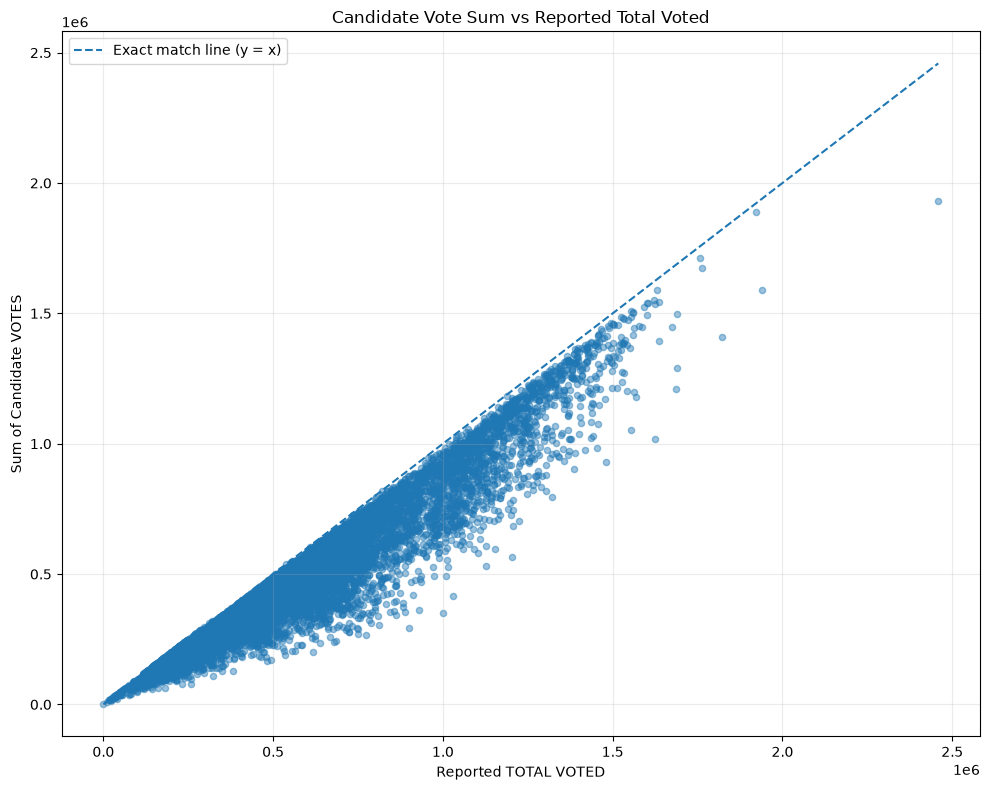

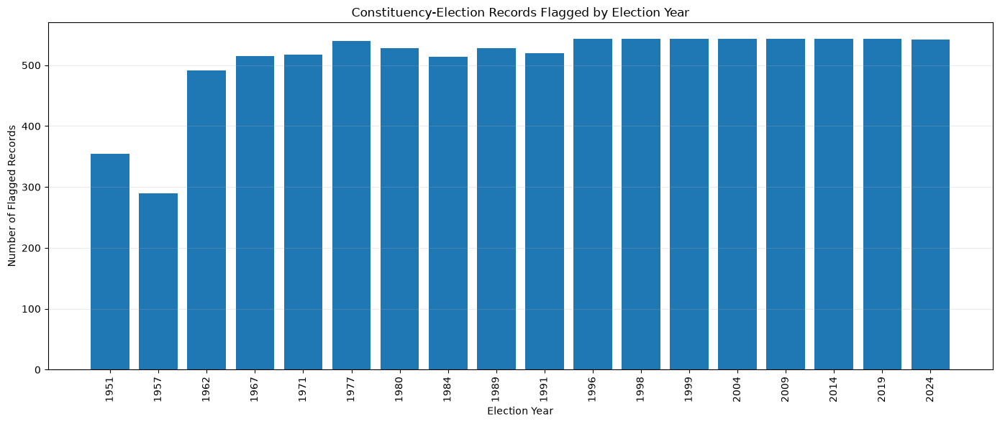


20 LARGEST ABSOLUTE VOTE DIFFERENCES
 YEAR          STATE UT  CONSTITUENCY NO CONSTITUENCY NAME  CANDIDATE_COUNT  CANDIDATE_VOTE_SUM  TOTAL_VOTED  VOTE_TOTAL_DIFFERENCE  DIFFERENCE_PERCENT                    VALIDATION_STATUS
 1951            Madras                8             Eluru                2              352493      1000456                -647963          -64.766766 Candidate vote sum below TOTAL VOTED
 1957            Kerala                3            QUILON                2              567347      1203754                -636407          -52.868526 Candidate vote sum below TOTAL VOTED
 1951 Travancore Cochin                4  Quilon Cum Mavel                2              414401      1028391                -613990          -59.703945 Candidate vote sum below TOTAL VOTED
 2014    Andhra Pradesh                7        Malkajgiri                2             1018546      1624859                -606313          -37.314807 Candidate vote sum below TOTAL VOTED
 1951            

In [76]:

# ============================================================
# ANALYSIS 35: CANDIDATE VOTE TOTALS VS CONSTITUENCY TOTALS
# Dataset: LOKSABHA 1951-2024.xlsx
# Requires the cleaned DataFrame: df
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = "outputs/data_quality_validation/35_candidate_vote_totals"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. REQUIRED COLUMNS
# ------------------------------------------------------------

constituency_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

required_columns = constituency_keys + [
    "CANDIDATE",
    "VOTES",
    "TOTAL VOTED"
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

# Work on a copy so the original df remains unchanged.
data = df[required_columns].copy()

# Convert numeric columns safely.
data["YEAR"] = pd.to_numeric(data["YEAR"], errors="coerce")
data["VOTES"] = pd.to_numeric(data["VOTES"], errors="coerce")
data["TOTAL VOTED"] = pd.to_numeric(
    data["TOTAL VOTED"], errors="coerce"
)

# ------------------------------------------------------------
# 3. CHECK FOR DUPLICATE CANDIDATE RECORDS
# ------------------------------------------------------------

candidate_keys = constituency_keys + ["CANDIDATE"]

duplicate_mask = data.duplicated(
    subset=candidate_keys,
    keep=False
)

duplicate_candidate_records = data.loc[duplicate_mask].copy()

# CSV export removed (chart/on-screen output only).

print("Duplicate candidate records found:", len(duplicate_candidate_records))

# Remove repeated candidate rows for the constituency-level
# vote-sum calculation, keeping the first occurrence.
# Review the duplicate CSV before treating these as confirmed errors.
data = data.drop_duplicates(
    subset=candidate_keys,
    keep="first"
).copy()

# ------------------------------------------------------------
# 4. SUM CANDIDATE VOTES BY CONSTITUENCY-ELECTION
# ------------------------------------------------------------

def sum_with_missing(series):
    """Return NaN if every candidate vote value is missing."""
    return series.sum(min_count=1)

summary = (
    data.groupby(constituency_keys, dropna=False)
    .agg(
        CANDIDATE_COUNT=("CANDIDATE", "nunique"),
        CANDIDATE_VOTE_SUM=("VOTES", sum_with_missing),
        TOTAL_VOTED=("TOTAL VOTED", "first"),
        TOTAL_VOTED_DISTINCT_VALUES=("TOTAL VOTED", "nunique"),
        MISSING_CANDIDATE_VOTE_RECORDS=(
            "VOTES", lambda s: int(s.isna().sum())
        ),
        NEGATIVE_CANDIDATE_VOTE_RECORDS=(
            "VOTES", lambda s: int((s < 0).sum())
        )
    )
    .reset_index()
)

# Difference: positive = candidate vote sum exceeds TOTAL VOTED;
# negative = candidate vote sum is below TOTAL VOTED.
summary["VOTE_TOTAL_DIFFERENCE"] = (
    summary["CANDIDATE_VOTE_SUM"] - summary["TOTAL_VOTED"]
)

summary["ABSOLUTE_VOTE_DIFFERENCE"] = (
    summary["VOTE_TOTAL_DIFFERENCE"].abs()
)

# Percentage difference relative to TOTAL VOTED.
summary["DIFFERENCE_PERCENT"] = np.where(
    summary["TOTAL_VOTED"].notna()
    & (summary["TOTAL_VOTED"] != 0),
    summary["VOTE_TOTAL_DIFFERENCE"]
    / summary["TOTAL_VOTED"] * 100,
    np.nan
)

# ------------------------------------------------------------
# 5. CLASSIFY EACH CONSTITUENCY-ELECTION
# ------------------------------------------------------------

conditions = [
    summary["TOTAL_VOTED"].isna(),
    summary["CANDIDATE_VOTE_SUM"].isna(),
    summary["TOTAL_VOTED_DISTINCT_VALUES"] > 1,
    summary["NEGATIVE_CANDIDATE_VOTE_RECORDS"] > 0,
    summary["CANDIDATE_VOTE_SUM"] > summary["TOTAL_VOTED"],
    summary["CANDIDATE_VOTE_SUM"] < summary["TOTAL_VOTED"]
]

labels = [
    "Missing TOTAL VOTED",
    "Missing candidate vote sum",
    "Inconsistent TOTAL VOTED values",
    "Negative candidate votes",
    "Candidate vote sum exceeds TOTAL VOTED",
    "Candidate vote sum below TOTAL VOTED"
]

summary["VALIDATION_STATUS"] = np.select(
    conditions,
    labels,
    default="Match"
)

# Keep a separate flag when individual candidate vote values are missing.
summary["HAS_MISSING_CANDIDATE_VOTES"] = (
    summary["MISSING_CANDIDATE_VOTE_RECORDS"] > 0
)

# ------------------------------------------------------------
# 6. SAVE FULL REPORT AND ISSUES-ONLY REPORT
# ------------------------------------------------------------

full_report_path = os.path.join(
    OUTPUT_DIR,
    "candidate_votes_vs_total_voted_full_report.csv"
)

issues_path = os.path.join(
    OUTPUT_DIR,
    "candidate_votes_vs_total_voted_issues_only.csv"
)

# CSV export removed (chart/on-screen output only).

issues = summary[
    (summary["VALIDATION_STATUS"] != "Match")
    | summary["HAS_MISSING_CANDIDATE_VOTES"]
].copy()

# CSV export removed (chart/on-screen output only).

# ------------------------------------------------------------
# 7. SUMMARY STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ANALYSIS 35: VALIDATION SUMMARY")
print("=" * 65)

print("Constituency-election records checked:", len(summary))
print("Exact matches:", (summary["VALIDATION_STATUS"] == "Match").sum())
print("Records flagged for review:", len(issues))

print("\nValidation status counts:")
print(
    summary["VALIDATION_STATUS"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nMissing candidate vote values:",
      int(summary["MISSING_CANDIDATE_VOTE_RECORDS"].sum()))

print("Negative candidate vote values:",
      int(summary["NEGATIVE_CANDIDATE_VOTE_RECORDS"].sum()))

print("\nFull report saved to:", full_report_path)
print("Issues-only report saved to:", issues_path)

# ------------------------------------------------------------
# 8. CHART 1: CANDIDATE VOTE SUM VS TOTAL VOTED
# ------------------------------------------------------------

plot_data = summary.dropna(
    subset=["CANDIDATE_VOTE_SUM", "TOTAL_VOTED"]
).copy()

# Exclude negative and zero totals from this comparison chart
# only when choosing axis limits; retain them in the CSV reports.
plot_data = plot_data[
    (plot_data["CANDIDATE_VOTE_SUM"] >= 0)
    & (plot_data["TOTAL_VOTED"] >= 0)
]

fig, ax = plt.subplots(figsize=(10, 8))

if not plot_data.empty:
    ax.scatter(
        plot_data["TOTAL_VOTED"],
        plot_data["CANDIDATE_VOTE_SUM"],
        alpha=0.45,
        s=20
    )

    max_value = max(
        plot_data["TOTAL_VOTED"].max(),
        plot_data["CANDIDATE_VOTE_SUM"].max()
    )

    ax.plot(
        [0, max_value],
        [0, max_value],
        linestyle="--",
        linewidth=1.5,
        label="Exact match line (y = x)"
    )

    ax.legend()

ax.set_title(
    "Candidate Vote Sum vs Reported Total Voted"
)
ax.set_xlabel("Reported TOTAL VOTED")
ax.set_ylabel("Sum of Candidate VOTES")
ax.grid(True, alpha=0.25)
fig.tight_layout()

chart1_path = os.path.join(
    OUTPUT_DIR,
    "35_1_candidate_vote_sum_vs_total_voted.png"
)

fig.savefig(chart1_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. CHART 2: NON-MATCHING RECORDS BY ELECTION YEAR
# ------------------------------------------------------------

yearly = summary.dropna(subset=["YEAR"]).copy()

yearly["IS_FLAGGED"] = (
    (yearly["VALIDATION_STATUS"] != "Match")
    | yearly["HAS_MISSING_CANDIDATE_VOTES"]
)

yearly_counts = (
    yearly.groupby("YEAR")
    .agg(
        CONSTITUENCIES_CHECKED=("YEAR", "size"),
        FLAGGED_RECORDS=("IS_FLAGGED", "sum")
    )
    .reset_index()
    .sort_values("YEAR")
)

fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(
    yearly_counts["YEAR"].astype(int).astype(str),
    yearly_counts["FLAGGED_RECORDS"]
)

ax.set_title(
    "Constituency-Election Records Flagged by Election Year"
)
ax.set_xlabel("Election Year")
ax.set_ylabel("Number of Flagged Records")
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

chart2_path = os.path.join(
    OUTPUT_DIR,
    "35_2_flagged_records_by_year.png"
)

fig.savefig(chart2_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Save the year-level summary as an additional diagnostic.
# CSV export removed (chart/on-screen output only).

# ------------------------------------------------------------
# 10. LARGEST DISCREPANCIES
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("20 LARGEST ABSOLUTE VOTE DIFFERENCES")
print("=" * 65)

largest_differences = (
    summary.dropna(subset=["ABSOLUTE_VOTE_DIFFERENCE"])
    .sort_values("ABSOLUTE_VOTE_DIFFERENCE", ascending=False)
    .head(20)
)

display_columns = constituency_keys + [
    "CANDIDATE_COUNT",
    "CANDIDATE_VOTE_SUM",
    "TOTAL_VOTED",
    "VOTE_TOTAL_DIFFERENCE",
    "DIFFERENCE_PERCENT",
    "VALIDATION_STATUS"
]

print(largest_differences[display_columns].to_string(index=False))

print("\nCharts saved:")
print(chart1_path)
print(chart2_path)

print("\nAnalysis 35 completed.")


### Analysis 36 — Missing and inconsistent election records



In [77]:
# ============================================================
# ANALYSIS 36: MISSING AND INCONSISTENT ELECTION RECORDS
# Diagnostic summary and issue samples; no CSV export.
# ============================================================

import pandas as pd
import numpy as np

required36 = [
    "YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME",
    "CANDIDATE", "PARTY", "TOTAL ELECTORS", "TOTAL VOTED", "VOTES",
    "RESULT POSITION"
]
missing36 = [c for c in required36 if c not in df.columns]
if missing36:
    raise KeyError(f"Missing required columns for Analysis 36: {missing36}")

a36 = df[required36].copy()
for col in ["YEAR", "CONSTITUENCY NO", "TOTAL ELECTORS", "TOTAL VOTED", "VOTES"]:
    a36[col] = pd.to_numeric(a36[col], errors="coerce")
for col in ["STATE UT", "CONSTITUENCY NAME", "CANDIDATE", "PARTY", "RESULT POSITION"]:
    a36[col] = a36[col].astype("string").str.strip()

key36 = ["YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"]
checks36 = {
    "Missing YEAR": a36["YEAR"].isna(),
    "Missing STATE UT": a36["STATE UT"].isna() | a36["STATE UT"].eq(""),
    "Missing constituency number": a36["CONSTITUENCY NO"].isna(),
    "Missing constituency name": a36["CONSTITUENCY NAME"].isna() | a36["CONSTITUENCY NAME"].eq(""),
    "Missing candidate": a36["CANDIDATE"].isna() | a36["CANDIDATE"].eq(""),
    "Missing party": a36["PARTY"].isna() | a36["PARTY"].eq(""),
    "Missing electorate": a36["TOTAL ELECTORS"].isna(),
    "Missing total voted": a36["TOTAL VOTED"].isna(),
    "Missing candidate votes": a36["VOTES"].isna(),
    "Negative electorate": a36["TOTAL ELECTORS"].lt(0),
    "Negative total voted": a36["TOTAL VOTED"].lt(0),
    "Negative candidate votes": a36["VOTES"].lt(0),
    "Total voted exceeds electorate": a36["TOTAL VOTED"].gt(a36["TOTAL ELECTORS"]),
    "Candidate votes exceed total voted": a36["VOTES"].gt(a36["TOTAL VOTED"]),
}

summary36 = pd.DataFrame([
    {"CHECK": name, "FLAGGED_ROWS": int(mask.fillna(False).sum())}
    for name, mask in checks36.items()
])
# Exact duplicate candidate records are checked with election/constituency/candidate identity.
duplicate_candidate_mask36 = a36.duplicated(subset=key36 + ["CANDIDATE"], keep=False)
summary36.loc[len(summary36)] = ["Duplicate candidate records (all copies flagged)", int(duplicate_candidate_mask36.sum())]
# Missing or unrecognized result labels are surfaced separately.
valid_result36 = a36["RESULT POSITION"].str.fullmatch(r"winner(?:\s+\d+)?|runner", case=False, na=False)
summary36.loc[len(summary36)] = ["Missing/unrecognized result position", int((~valid_result36).sum())]

print("ANALYSIS 36 — DATA QUALITY SUMMARY")
display(summary36.sort_values("FLAGGED_ROWS", ascending=False))

# Show a manageable sample of records with at least one flagged condition.
any_issue36 = pd.Series(False, index=a36.index)
for mask in checks36.values():
    any_issue36 |= mask.fillna(False)
any_issue36 |= duplicate_candidate_mask36
any_issue36 |= ~valid_result36
issues_sample36 = a36.loc[any_issue36].copy()
print("Flagged rows:", len(issues_sample36), "of", len(a36))
display(issues_sample36.head(100))
print("This is a diagnostic screen, not an automatic correction. Review historical exceptions before changing source records.")


ANALYSIS 36 — DATA QUALITY SUMMARY


,CHECK,FLAGGED_ROWS
12,Total voted exceeds electorate,86
14,Duplicate candidate records (all copies flagged),6
0,Missing YEAR,0
1,Missing STATE UT,0
4,Missing candidate,0
5,Missing party,0
2,Missing constituency number,0
3,Missing constituency name,0
7,Missing total voted,0
6,Missing electorate,0


Flagged rows: 92 of 18577


,YEAR,STATE UT,CONSTITUENCY NO,CONSTITUENCY NAME,CANDIDATE,PARTY,TOTAL ELECTORS,TOTAL VOTED,VOTES,RESULT POSITION
128,1951,Bombay,11,Surat,DESAI KANHAIYALAL NANABHAI,INDIAN NATIONAL CONGRESS,745093,861336,244016,winner
129,1951,Bombay,11,Surat,PATEL BAHADURBHAI KUTHABHAI,INDIAN NATIONAL CONGRESS,745093,861336,229295,winner
130,1951,Bombay,12,Thana,NANDKAR ANANT SAVALARAM,INDIAN NATIONAL CONGRESS,712902,718242,151952,winner
131,1951,Bombay,12,Thana,VARTAK GOVIND DHARMAJI,INDIAN NATIONAL CONGRESS,712902,718242,140604,winner
140,1951,Bombay,17,West Khandesh,BHARATIYA SHALIGRAM RAMCHANDRA,INDIAN NATIONAL CONGRESS,753372,754356,171242,winner
...,...,...,...,...,...,...,...,...,...,...
2751,1967,Bihar,40,AURANGABAD,M. SINGH,SAMYUKTA SOCIALIST PARTY,557937,257360,38656,runner
3206,1967,Punjab,10,RUPAR (SC),B. SINGH,INDIAN NATIONAL CONGRESS,475396,348741,127986,winner
3207,1967,Punjab,10,RUPAR (SC),B. SINGH,AKALI DAL - SANT FATEH SINGH GROUP,475396,348741,123914,runner
3238,1967,Rajasthan,13,KOTA (SC),ONKARLAL,ALL INDIA BHARTIYA JAN SANGH,513800,285321,151258,winner


This is a diagnostic screen, not an automatic correction. Review historical exceptions before changing source records.


## 9. Party-performance deep dives (Analyses 8–12)



Winner records: 9467
Winner records with valid nonnegative margins: 9467
Negative margin values flagged: 0

Top parties by number of valid winning-margin records:
                                          WINS  MEAN_MARGIN_VOTES  MEDIAN_MARGIN_VOTES  MEAN_MARGIN_PERCENT  MEDIAN_MARGIN_PERCENT  CLOSE_WINS_LE_1PCT  CLOSE_WINS_LE_2PCT  CLOSE_WINS_LE_5PCT
PARTY                                                                                                                                                                                         
INDIAN NATIONAL CONGRESS                  3637           64145.07              47278.0                16.55                  12.64                5.17               10.34               23.73
BHARATIYA JANTA PARTY                     1811          129219.71              87047.0                14.97                  12.14                4.31                9.00               22.20
CUMMUNIST PARTY OF INDIA (MARXIST)         358           87552.59        

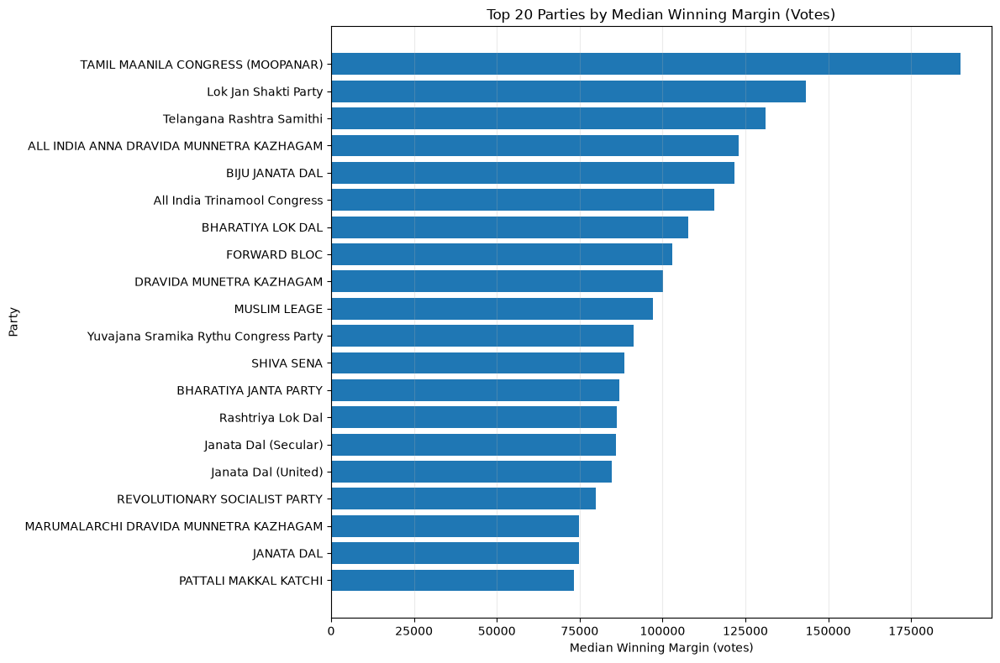

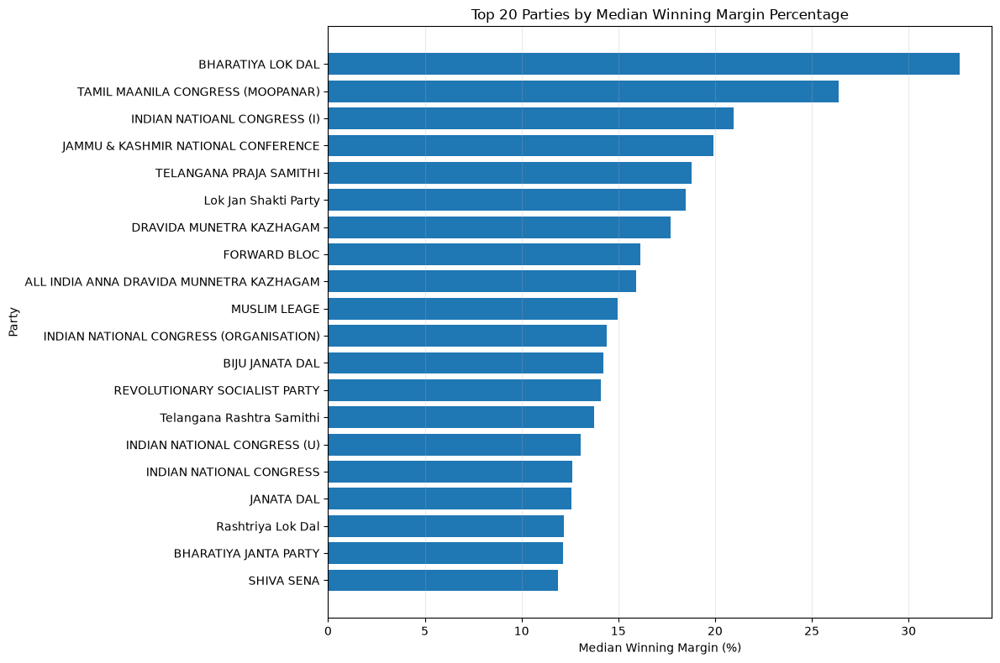

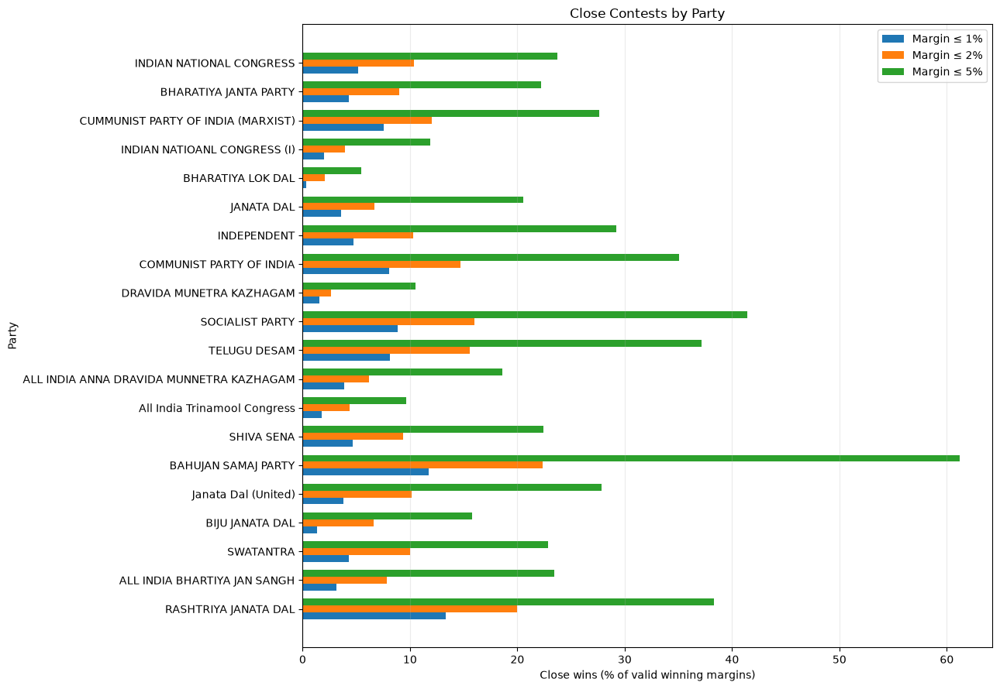

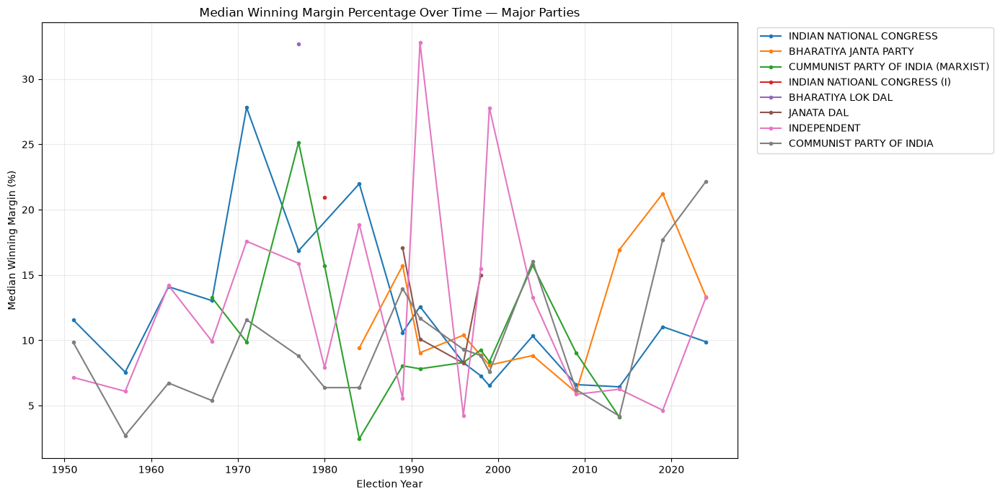


PARTIES WITH THE HIGHEST MEDIAN WINNING MARGIN
                                          WINS  MEDIAN_MARGIN_VOTES  MEDIAN_MARGIN_PERCENT  CLOSE_WINS_LE_1PCT  CLOSE_WINS_LE_2PCT  CLOSE_WINS_LE_5PCT
PARTY                                                                                                                                                 
BHARATIYA LOK DAL                          295             107685.0                  32.66                0.34                2.03                5.42
TAMIL MAANILA CONGRESS (MOOPANAR)           23             189806.0                  26.40                0.00                0.00                8.70
INDIAN NATIOANL CONGRESS (I)               353              70350.0                  20.95                1.98                3.97               11.90
JAMMU & KASHMIR NATIONAL CONFERENCE         27              36859.0                  19.91                0.00                7.41               11.11
TELANGANA PRAJA SAMITHI                     10

In [78]:

# ============================================================
# ANALYSIS 8: PARTY-WISE WINNING MARGIN
# PNG charts only — no CSV output
# Requires your cleaned DataFrame: df
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = "outputs/party_winning_margin"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "YEAR",
    "PARTY",
    "RESULT POSITION",
    "MARGIN VOTES",
    "MARGIN PERCENT"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

data = df[required_columns].copy()

data["YEAR"] = pd.to_numeric(data["YEAR"], errors="coerce")
data["MARGIN VOTES"] = pd.to_numeric(
    data["MARGIN VOTES"], errors="coerce"
)
data["MARGIN PERCENT"] = pd.to_numeric(
    data["MARGIN PERCENT"], errors="coerce"
)

# Normalize labels without changing df.
result_labels = (
    data["RESULT POSITION"]
    .astype("string")
    .str.strip()
    .str.lower()
)

winner_mask = result_labels.str.fullmatch(
    r"winner(?:\s+\d+)?",
    na=False
)

winners = data.loc[winner_mask].copy()

# Exclude missing party labels from party comparisons.
winners["PARTY"] = (
    winners["PARTY"]
    .astype("string")
    .str.strip()
)

winners = winners[
    winners["PARTY"].notna()
    & winners["PARTY"].ne("")
].copy()

# Margins should be nonnegative for winners.
# Negative margins are excluded from margin summaries and counted
# separately as a data-quality warning.
negative_margin_count = (
    (winners["MARGIN VOTES"] < 0).sum()
    + (winners["MARGIN PERCENT"] < 0).sum()
)

valid_margin = winners[
    (winners["MARGIN VOTES"] >= 0)
    & (winners["MARGIN PERCENT"] >= 0)
].copy()

print("Winner records:", len(winners))
print("Winner records with valid nonnegative margins:", len(valid_margin))
print("Negative margin values flagged:", int(negative_margin_count))

if valid_margin.empty:
    raise ValueError(
        "No valid winning-margin records found. "
        "Check the winner labels and margin columns."
    )

# ------------------------------------------------------------
# 2. PARTY-LEVEL WINNING MARGIN STATISTICS
# ------------------------------------------------------------

party_stats = (
    valid_margin.groupby("PARTY")
    .agg(
        WINS=("PARTY", "size"),
        MEAN_MARGIN_VOTES=("MARGIN VOTES", "mean"),
        MEDIAN_MARGIN_VOTES=("MARGIN VOTES", "median"),
        MEAN_MARGIN_PERCENT=("MARGIN PERCENT", "mean"),
        MEDIAN_MARGIN_PERCENT=("MARGIN PERCENT", "median")
    )
)

# Calculate close-win percentages using MARGIN PERCENT.
for threshold in [1, 2, 5]:
    close_wins = (
        valid_margin["MARGIN PERCENT"] <= threshold
    ).groupby(valid_margin["PARTY"]).mean() * 100

    party_stats[f"CLOSE_WINS_LE_{threshold}PCT"] = close_wins

party_stats = party_stats.sort_values(
    "WINS", ascending=False
)

print("\nTop parties by number of valid winning-margin records:")
print(party_stats.head(20).round(2).to_string())

# ------------------------------------------------------------
# 3. CHART 1: PARTIES WITH THE LARGEST MEDIAN VOTE MARGIN
# ------------------------------------------------------------

# Focus on parties with at least 10 wins for a more meaningful
# comparison. Change MIN_WINS if you want to include smaller parties.
MIN_WINS = 10

established_parties = party_stats[
    party_stats["WINS"] >= MIN_WINS
].copy()

if established_parties.empty:
    # If fewer parties meet the threshold, use all parties.
    established_parties = party_stats.copy()

top_margin_parties = (
    established_parties
    .sort_values("MEDIAN_MARGIN_VOTES", ascending=False)
    .head(20)
    .sort_values("MEDIAN_MARGIN_VOTES")
)

fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(
    top_margin_parties.index.astype(str),
    top_margin_parties["MEDIAN_MARGIN_VOTES"]
)

ax.set_title(
    "Top 20 Parties by Median Winning Margin (Votes)"
)
ax.set_xlabel("Median Winning Margin (votes)")
ax.set_ylabel("Party")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR, "08_1_median_winning_margin_votes.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 4. CHART 2: PARTIES WITH THE LARGEST MEDIAN MARGIN PERCENTAGE
# ------------------------------------------------------------

top_percent_margin = (
    established_parties
    .sort_values("MEDIAN_MARGIN_PERCENT", ascending=False)
    .head(20)
    .sort_values("MEDIAN_MARGIN_PERCENT")
)

fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(
    top_percent_margin.index.astype(str),
    top_percent_margin["MEDIAN_MARGIN_PERCENT"]
)

ax.set_title(
    "Top 20 Parties by Median Winning Margin Percentage"
)
ax.set_xlabel("Median Winning Margin (%)")
ax.set_ylabel("Party")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR, "08_2_median_winning_margin_percent.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. CHART 3: CLOSE WINS BY PARTY
# ------------------------------------------------------------

# Rank parties by number of wins and select the 20 most frequent.
# Percentages show the proportion of valid margin records that
# fall within each close-contest threshold.
close_plot = party_stats.head(20).copy()

close_plot = close_plot.sort_values("WINS", ascending=True)

fig, ax = plt.subplots(figsize=(13, 9))

y = np.arange(len(close_plot))
bar_height = 0.24

ax.barh(
    y - bar_height,
    close_plot["CLOSE_WINS_LE_1PCT"],
    height=bar_height,
    label="Margin ≤ 1%"
)

ax.barh(
    y,
    close_plot["CLOSE_WINS_LE_2PCT"],
    height=bar_height,
    label="Margin ≤ 2%"
)

ax.barh(
    y + bar_height,
    close_plot["CLOSE_WINS_LE_5PCT"],
    height=bar_height,
    label="Margin ≤ 5%"
)

ax.set_yticks(y)
ax.set_yticklabels(close_plot.index.astype(str))
ax.set_xlabel("Close wins (% of valid winning margins)")
ax.set_ylabel("Party")
ax.set_title("Close Contests by Party")
ax.legend()
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR, "08_3_close_wins_by_party.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. CHART 4: WINNING MARGIN OVER TIME FOR MAJOR PARTIES
# ------------------------------------------------------------

# Choose the 8 parties with the most valid winning records.
major_parties = party_stats.head(8).index.tolist()

trend_data = valid_margin[
    valid_margin["PARTY"].isin(major_parties)
].copy()

yearly_margins = (
    trend_data.groupby(["YEAR", "PARTY"])
    .agg(
        MEDIAN_MARGIN_PERCENT=("MARGIN PERCENT", "median"),
        WINS=("PARTY", "size")
    )
    .reset_index()
    .sort_values("YEAR")
)

fig, ax = plt.subplots(figsize=(14, 7))

for party in major_parties:
    party_years = yearly_margins[
        yearly_margins["PARTY"] == party
    ]

    ax.plot(
        party_years["YEAR"],
        party_years["MEDIAN_MARGIN_PERCENT"],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=party
    )

ax.set_title(
    "Median Winning Margin Percentage Over Time — Major Parties"
)
ax.set_xlabel("Election Year")
ax.set_ylabel("Median Winning Margin (%)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(True, alpha=0.25)

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR, "08_4_winning_margin_over_time.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. DISPLAY KEY FINDINGS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PARTIES WITH THE HIGHEST MEDIAN WINNING MARGIN")
print("=" * 70)

print(
    established_parties
    .sort_values("MEDIAN_MARGIN_PERCENT", ascending=False)
    [[
        "WINS",
        "MEDIAN_MARGIN_VOTES",
        "MEDIAN_MARGIN_PERCENT",
        "CLOSE_WINS_LE_1PCT",
        "CLOSE_WINS_LE_2PCT",
        "CLOSE_WINS_LE_5PCT"
    ]]
    .head(15)
    .round(2)
    .to_string()
)

print("\nCharts saved to:", OUTPUT_DIR)
print("Analysis 8 completed. No CSV files were created.")


Repeated candidate rows excluded: 3

PARTY DOMINANCE BY ELECTION
 YEAR          SEAT_DOMINANT_PARTY  DOMINANT_PARTY_SEATS  DOMINANT_PARTY_SEAT_SHARE          VOTE_DOMINANT_PARTY  DOMINANT_PARTY_VOTES  DOMINANT_PARTY_VOTE_SHARE  SEAT_VOTE_SHARE_GAP  SAME_PARTY_DOMINATES_SEATS_AND_VOTES
 1951     INDIAN NATIONAL CONGRESS                 295.0                      74.49     INDIAN NATIONAL CONGRESS              42136264                      62.32                12.18                                  True
 1957     INDIAN NATIONAL CONGRESS                 291.0                      73.48     INDIAN NATIONAL CONGRESS              52055518                      62.87                10.62                                  True
 1962     INDIAN NATIONAL CONGRESS                 358.0                      72.91     INDIAN NATIONAL CONGRESS              51107700                      54.17                18.74                                  True
 1967     INDIAN NATIONAL CONGRESS                 

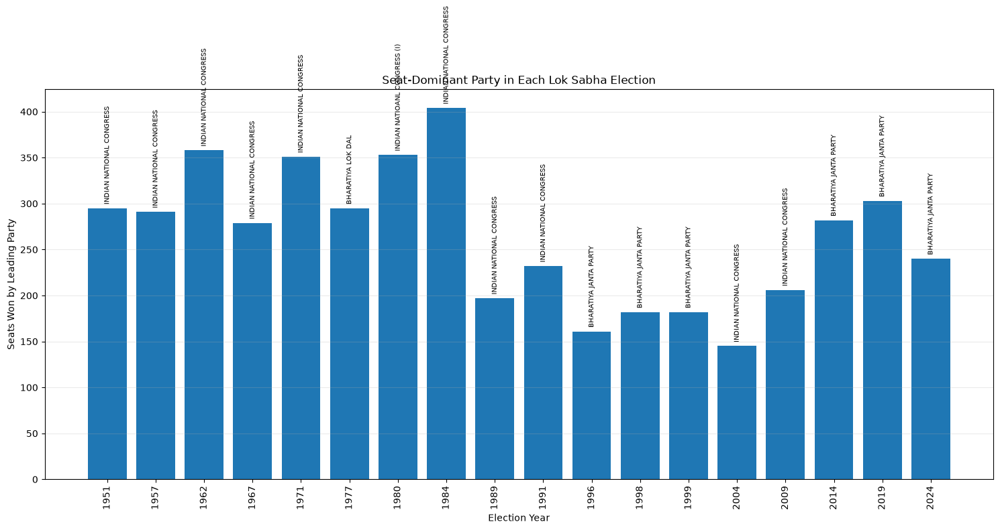

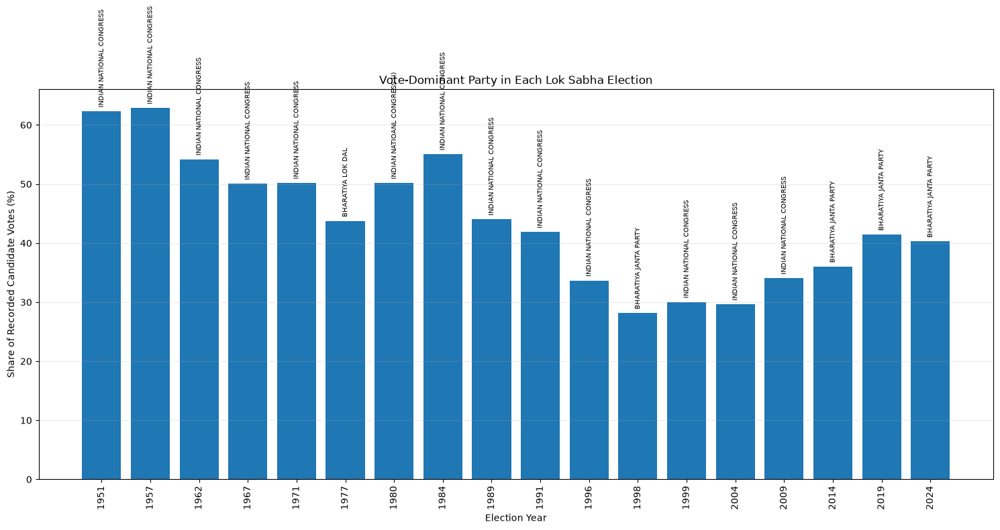

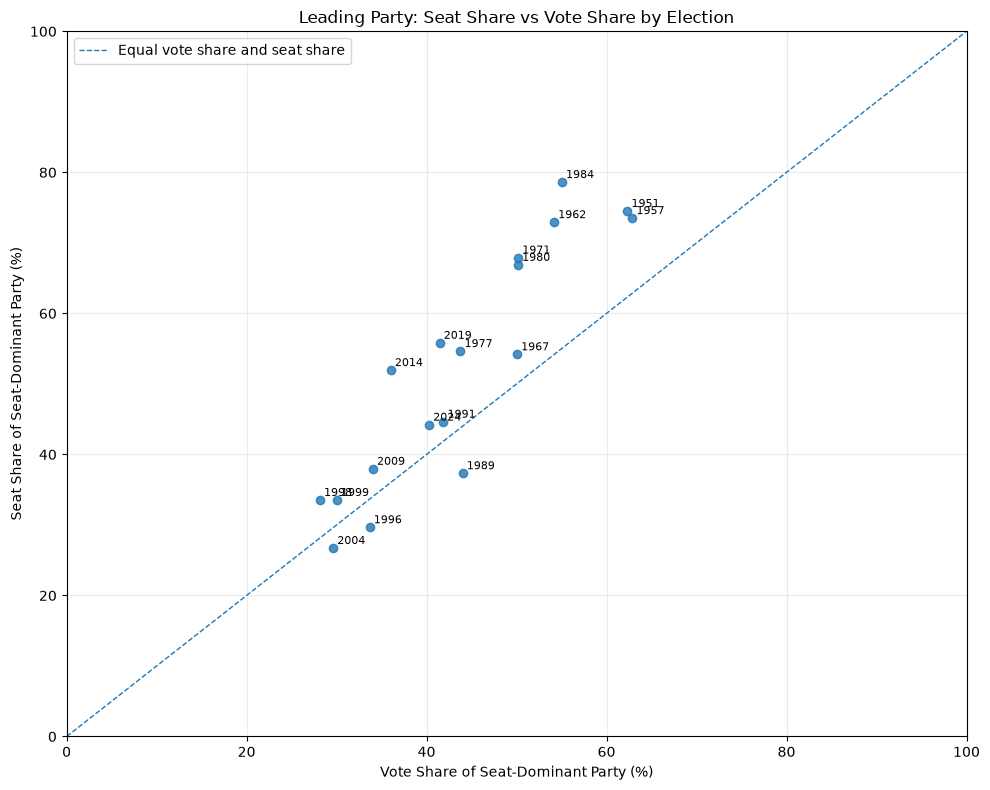

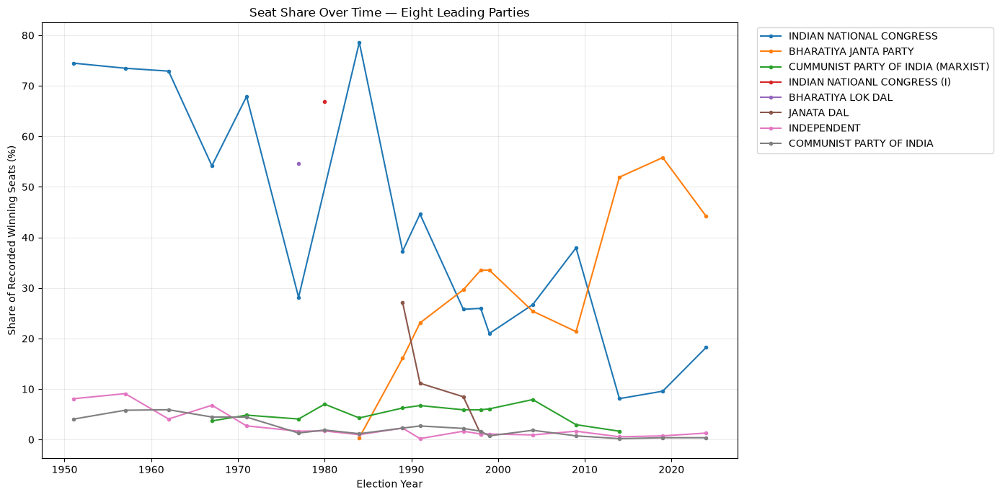


ELECTIONS WHERE SEAT AND VOTE LEADERS DIFFER
 YEAR   SEAT_DOMINANT_PARTY      VOTE_DOMINANT_PARTY  DOMINANT_PARTY_SEAT_SHARE  DOMINANT_PARTY_VOTE_SHARE
 1996 BHARATIYA JANTA PARTY INDIAN NATIONAL CONGRESS                      29.65                      33.68
 1999 BHARATIYA JANTA PARTY INDIAN NATIONAL CONGRESS                      33.52                      30.03

LARGEST POSITIVE SEAT-VOTE SHARE GAPS
 YEAR          SEAT_DOMINANT_PARTY  DOMINANT_PARTY_SEAT_SHARE  DOMINANT_PARTY_VOTE_SHARE  SEAT_VOTE_SHARE_GAP
 1984     INDIAN NATIONAL CONGRESS                      78.60                      55.04                23.56
 1962     INDIAN NATIONAL CONGRESS                      72.91                      54.17                18.74
 1971     INDIAN NATIONAL CONGRESS                      67.89                      50.18                17.71
 1980 INDIAN NATIOANL CONGRESS (I)                      66.86                      50.17                16.69
 2014        BHARATIYA JANTA PARTY          

In [79]:

# ============================================================
# ANALYSIS 9: PARTY DOMINANCE BY ELECTION
# Corrected full version — PNG charts only, no CSV files
# Requires the cleaned DataFrame: df
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = "outputs/party_dominance_by_election"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. VALIDATE COLUMNS
# ------------------------------------------------------------

required_columns = [
    "YEAR",
    "PARTY",
    "CANDIDATE",          # Required for candidate deduplication
    "RESULT POSITION",
    "VOTES",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

data = df[required_columns].copy()

data["YEAR"] = pd.to_numeric(data["YEAR"], errors="coerce")
data["VOTES"] = pd.to_numeric(data["VOTES"], errors="coerce")

data["PARTY"] = data["PARTY"].astype("string").str.strip()
data["RESULT POSITION"] = (
    data["RESULT POSITION"].astype("string").str.strip().str.lower()
)

# Remove rows without a usable election year or party.
data = data[
    data["YEAR"].notna()
    & data["PARTY"].notna()
    & data["PARTY"].ne("")
].copy()

# Recognize winner, Winner 1, Winner 2, regardless of capitalization.
data["IS_WINNER"] = data["RESULT POSITION"].str.fullmatch(
    r"winner(?:\s+\d+)?",
    na=False
)

constituency_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

candidate_keys = constituency_keys + ["CANDIDATE"]

# ------------------------------------------------------------
# 2. DEDUPLICATE CANDIDATE RECORDS
# ------------------------------------------------------------

duplicate_count = int(
    data.duplicated(subset=candidate_keys, keep="first").sum()
)

print("Repeated candidate rows excluded:", duplicate_count)

data = data.drop_duplicates(
    subset=candidate_keys,
    keep="first"
).copy()

# ------------------------------------------------------------
# 3. PARTY VOTE TOTALS AND VOTE SHARE BY ELECTION
# ------------------------------------------------------------

party_votes = (
    data.groupby(["YEAR", "PARTY"], dropna=False)
    .agg(
        PARTY_VOTES=("VOTES", lambda s: s.sum(min_count=1))
    )
    .reset_index()
)

# Denominator: total candidate votes recorded across all parties
# in the dataset for each election year.
election_vote_totals = (
    party_votes.groupby("YEAR")["PARTY_VOTES"]
    .sum(min_count=1)
    .rename("TOTAL_RECORDED_CANDIDATE_VOTES")
    .reset_index()
)

party_votes = party_votes.merge(
    election_vote_totals,
    on="YEAR",
    how="left"
)

party_votes["VOTE_SHARE_PERCENT"] = np.where(
    party_votes["TOTAL_RECORDED_CANDIDATE_VOTES"] > 0,
    party_votes["PARTY_VOTES"]
    / party_votes["TOTAL_RECORDED_CANDIDATE_VOTES"] * 100,
    np.nan
)

# ------------------------------------------------------------
# 4. PARTY SEATS WON
# ------------------------------------------------------------

winners = data[data["IS_WINNER"]].copy()

# Count one recorded winning seat per constituency-election-party.
# If multiple winner records exist in one constituency, flag them
# for review rather than silently counting duplicate rows as seats.
winner_constituencies = winners.drop_duplicates(
    subset=constituency_keys
).copy()

party_seats = (
    winner_constituencies.groupby(["YEAR", "PARTY"])
    .size()
    .reset_index(name="SEATS_WON")
)

recorded_seats = (
    winner_constituencies.groupby("YEAR")
    .size()
    .rename("RECORDED_SEATS")
    .reset_index()
)

party_seats = party_seats.merge(
    recorded_seats,
    on="YEAR",
    how="left"
)

party_seats["SEAT_SHARE_PERCENT"] = np.where(
    party_seats["RECORDED_SEATS"] > 0,
    party_seats["SEATS_WON"]
    / party_seats["RECORDED_SEATS"] * 100,
    np.nan
)

# ------------------------------------------------------------
# 5. COMBINE VOTE AND SEAT DATA
# ------------------------------------------------------------

party_performance = party_votes.merge(
    party_seats[
        ["YEAR", "PARTY", "SEATS_WON", "SEAT_SHARE_PERCENT"]
    ],
    on=["YEAR", "PARTY"],
    how="outer"
)

party_performance["SEATS_WON"] = (
    party_performance["SEATS_WON"].fillna(0)
)

# ------------------------------------------------------------
# 6. FIND THE DOMINANT PARTY BY SEATS
# ------------------------------------------------------------

seat_leaders = (
    party_performance.sort_values(
        ["YEAR", "SEATS_WON", "VOTE_SHARE_PERCENT", "PARTY"],
        ascending=[True, False, False, True],
        na_position="last"
    )
    .groupby("YEAR", as_index=False)
    .first()
)

seat_leaders = seat_leaders.rename(columns={
    "PARTY": "SEAT_DOMINANT_PARTY",
    "SEATS_WON": "DOMINANT_PARTY_SEATS",
    "SEAT_SHARE_PERCENT": "DOMINANT_PARTY_SEAT_SHARE"
})

# ------------------------------------------------------------
# 7. FIND THE DOMINANT PARTY BY VOTE SHARE
# ------------------------------------------------------------

vote_leaders = (
    party_performance.dropna(subset=["VOTE_SHARE_PERCENT"])
    .sort_values(
        ["YEAR", "VOTE_SHARE_PERCENT", "PARTY_VOTES", "PARTY"],
        ascending=[True, False, False, True]
    )
    .groupby("YEAR", as_index=False)
    .first()
)

vote_leaders = vote_leaders.rename(columns={
    "PARTY": "VOTE_DOMINANT_PARTY",
    "PARTY_VOTES": "DOMINANT_PARTY_VOTES",
    "VOTE_SHARE_PERCENT": "DOMINANT_PARTY_VOTE_SHARE"
})

dominance = seat_leaders[[
    "YEAR",
    "SEAT_DOMINANT_PARTY",
    "DOMINANT_PARTY_SEATS",
    "DOMINANT_PARTY_SEAT_SHARE"
]].merge(
    vote_leaders[[
        "YEAR",
        "VOTE_DOMINANT_PARTY",
        "DOMINANT_PARTY_VOTES",
        "DOMINANT_PARTY_VOTE_SHARE"
    ]],
    on="YEAR",
    how="outer"
).sort_values("YEAR")

dominance["SEAT_VOTE_SHARE_GAP"] = (
    dominance["DOMINANT_PARTY_SEAT_SHARE"]
    - dominance["DOMINANT_PARTY_VOTE_SHARE"]
)

dominance["SAME_PARTY_DOMINATES_SEATS_AND_VOTES"] = (
    dominance["SEAT_DOMINANT_PARTY"]
    == dominance["VOTE_DOMINANT_PARTY"]
)

print("\n" + "=" * 75)
print("PARTY DOMINANCE BY ELECTION")
print("=" * 75)

print(dominance.round(2).to_string(index=False))

# ------------------------------------------------------------
# 8. CHART 1: DOMINANT PARTY BY SEATS
# ------------------------------------------------------------

plot_seats = dominance.dropna(
    subset=["YEAR", "DOMINANT_PARTY_SEATS"]
).copy()

fig, ax = plt.subplots(figsize=(15, 8))

x = np.arange(len(plot_seats))

ax.bar(x, plot_seats["DOMINANT_PARTY_SEATS"])

ax.set_xticks(x)
ax.set_xticklabels(
    plot_seats["YEAR"].astype(int).astype(str),
    rotation=90
)

# Party names above the bars.
for i, (_, row) in enumerate(plot_seats.iterrows()):
    ax.annotate(
        str(row["SEAT_DOMINANT_PARTY"]),
        (i, row["DOMINANT_PARTY_SEATS"]),
        xytext=(0, 4),
        textcoords="offset points",
        rotation=90,
        ha="center",
        va="bottom",
        fontsize=7
    )

ax.set_title("Seat-Dominant Party in Each Lok Sabha Election")
ax.set_xlabel("Election Year")
ax.set_ylabel("Seats Won by Leading Party")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR, "09_1_dominant_party_by_seats.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. CHART 2: DOMINANT PARTY BY VOTE SHARE
# ------------------------------------------------------------

plot_votes = dominance.dropna(
    subset=["YEAR", "DOMINANT_PARTY_VOTE_SHARE"]
).copy()

fig, ax = plt.subplots(figsize=(15, 8))

x = np.arange(len(plot_votes))

ax.bar(x, plot_votes["DOMINANT_PARTY_VOTE_SHARE"])

ax.set_xticks(x)
ax.set_xticklabels(
    plot_votes["YEAR"].astype(int).astype(str),
    rotation=90
)

for i, (_, row) in enumerate(plot_votes.iterrows()):
    ax.annotate(
        str(row["VOTE_DOMINANT_PARTY"]),
        (i, row["DOMINANT_PARTY_VOTE_SHARE"]),
        xytext=(0, 4),
        textcoords="offset points",
        rotation=90,
        ha="center",
        va="bottom",
        fontsize=7
    )

ax.set_title("Vote-Dominant Party in Each Lok Sabha Election")
ax.set_xlabel("Election Year")
ax.set_ylabel("Share of Recorded Candidate Votes (%)")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR, "09_2_dominant_party_by_vote_share.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 10. CHART 3: SEAT SHARE VS VOTE SHARE
# ------------------------------------------------------------

valid_gap = dominance.dropna(
    subset=[
        "DOMINANT_PARTY_SEAT_SHARE",
        "DOMINANT_PARTY_VOTE_SHARE"
    ]
).copy()

fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(
    valid_gap["DOMINANT_PARTY_VOTE_SHARE"],
    valid_gap["DOMINANT_PARTY_SEAT_SHARE"],
    alpha=0.8
)

for _, row in valid_gap.iterrows():
    ax.annotate(
        str(int(row["YEAR"])),
        (
            row["DOMINANT_PARTY_VOTE_SHARE"],
            row["DOMINANT_PARTY_SEAT_SHARE"]
        ),
        fontsize=8,
        xytext=(3, 3),
        textcoords="offset points"
    )

ax.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    linewidth=1,
    label="Equal vote share and seat share"
)

ax.set_title("Leading Party: Seat Share vs Vote Share by Election")
ax.set_xlabel("Vote Share of Seat-Dominant Party (%)")
ax.set_ylabel("Seat Share of Seat-Dominant Party (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.25)
ax.legend()

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR, "09_3_leading_party_seat_vs_vote_share.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 11. CHART 4: SEAT DOMINANCE OVER TIME
# ------------------------------------------------------------

top_parties = (
    party_seats.groupby("PARTY")["SEATS_WON"]
    .sum()
    .sort_values(ascending=False)
    .head(8)
    .index.tolist()
)

dominance_trend = party_performance[
    party_performance["PARTY"].isin(top_parties)
].copy()

fig, ax = plt.subplots(figsize=(14, 7))

for party in top_parties:
    temp = dominance_trend[
        dominance_trend["PARTY"] == party
    ].sort_values("YEAR")

    ax.plot(
        temp["YEAR"],
        temp["SEAT_SHARE_PERCENT"],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=party
    )

ax.set_title("Seat Share Over Time — Eight Leading Parties")
ax.set_xlabel("Election Year")
ax.set_ylabel("Share of Recorded Winning Seats (%)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(True, alpha=0.25)

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR, "09_4_party_dominance_over_time.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 12. PRINT KEY FINDINGS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ELECTIONS WHERE SEAT AND VOTE LEADERS DIFFER")
print("=" * 75)

different_leaders = dominance[
    dominance["SEAT_DOMINANT_PARTY"]
    != dominance["VOTE_DOMINANT_PARTY"]
]

if different_leaders.empty:
    print("No differences found in the available records.")
else:
    print(
        different_leaders[[
            "YEAR",
            "SEAT_DOMINANT_PARTY",
            "VOTE_DOMINANT_PARTY",
            "DOMINANT_PARTY_SEAT_SHARE",
            "DOMINANT_PARTY_VOTE_SHARE"
        ]].round(2).to_string(index=False)
    )

print("\n" + "=" * 75)
print("LARGEST POSITIVE SEAT-VOTE SHARE GAPS")
print("=" * 75)

print(
    dominance.sort_values(
        "SEAT_VOTE_SHARE_GAP",
        ascending=False
    )[[
        "YEAR",
        "SEAT_DOMINANT_PARTY",
        "DOMINANT_PARTY_SEAT_SHARE",
        "DOMINANT_PARTY_VOTE_SHARE",
        "SEAT_VOTE_SHARE_GAP"
    ]].head(10).round(2).to_string(index=False)
)

print("\nCharts saved to:", OUTPUT_DIR)
print("Analysis 9 completed. No CSV files were created.")


Repeated candidate records excluded: 3


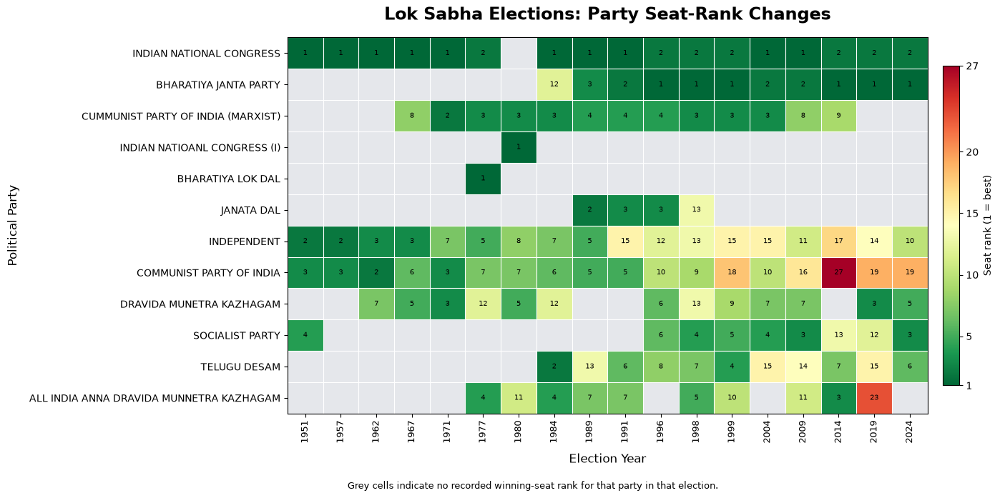

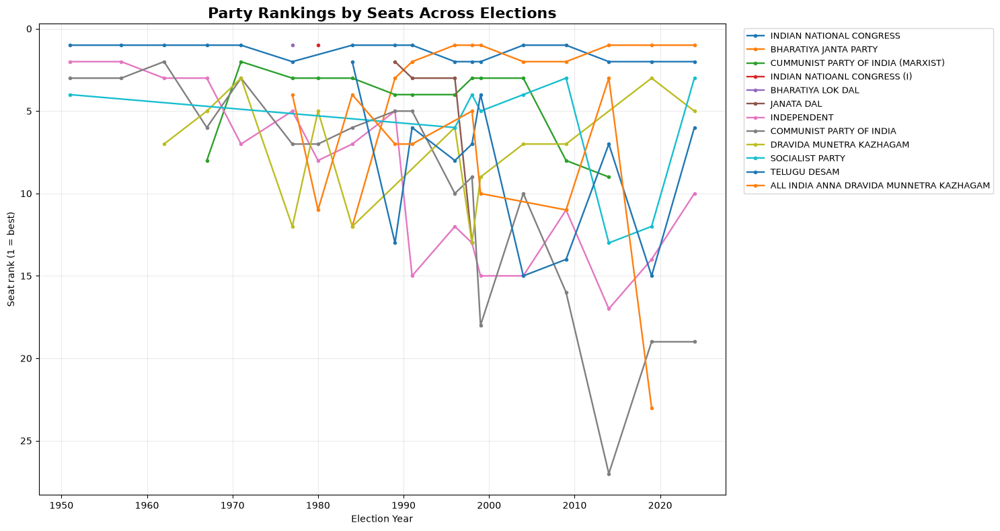

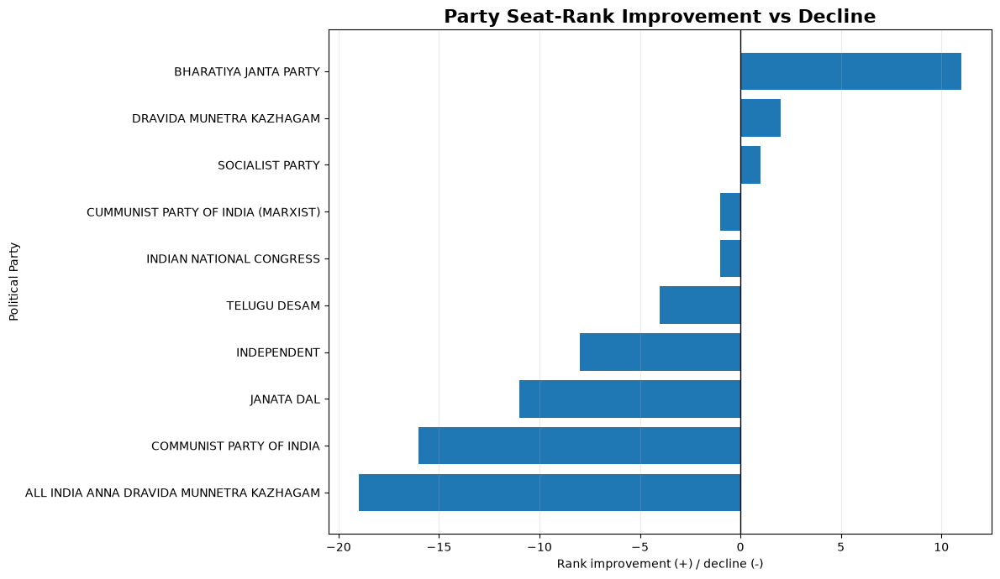


Rank change summary:
                                   PARTY  FIRST_YEAR  FIRST_RANK  LAST_YEAR  LAST_RANK  RANK_IMPROVEMENT
ALL INDIA ANNA DRAVIDA MUNNETRA KAZHAGAM        1977         4.0       2019       23.0             -19.0
                COMMUNIST PARTY OF INDIA        1951         3.0       2024       19.0             -16.0
                              JANATA DAL        1989         2.0       1998       13.0             -11.0
                             INDEPENDENT        1951         2.0       2024       10.0              -8.0
                            TELUGU DESAM        1984         2.0       2024        6.0              -4.0
                INDIAN NATIONAL CONGRESS        1951         1.0       2024        2.0              -1.0
      CUMMUNIST PARTY OF INDIA (MARXIST)        1967         8.0       2014        9.0              -1.0
                         SOCIALIST PARTY        1951         4.0       2024        3.0               1.0
                DRAVIDA MUNETRA K

In [80]:

# ============================================================
# ANALYSIS 10: PARTY RANK CHANGES ACROSS LOK SABHA ELECTIONS
# Improved visualization — heatmap as the main chart
# Output: PNG files only; no CSV files
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

OUTPUT_DIR = "outputs/party_rank_changes"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. VALIDATE AND PREPARE DATA
# ------------------------------------------------------------

required_columns = [
    "YEAR",
    "PARTY",
    "CANDIDATE",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME",
    "RESULT POSITION",
    "VOTES"
]

missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

data = df[required_columns].copy()

data["YEAR"] = pd.to_numeric(data["YEAR"], errors="coerce")
data["VOTES"] = pd.to_numeric(data["VOTES"], errors="coerce")
data["PARTY"] = data["PARTY"].astype("string").str.strip()
data["RESULT POSITION"] = (
    data["RESULT POSITION"].astype("string").str.strip().str.lower()
)

data = data[
    data["YEAR"].notna()
    & data["PARTY"].notna()
    & data["PARTY"].ne("")
].copy()

constituency_keys = [
    "YEAR",
    "STATE UT",
    "CONSTITUENCY NO",
    "CONSTITUENCY NAME"
]

# Deduplicate repeated candidate records.
candidate_keys = constituency_keys + ["CANDIDATE"]
duplicate_count = int(
    data.duplicated(subset=candidate_keys, keep="first").sum()
)

data = data.drop_duplicates(
    subset=candidate_keys,
    keep="first"
).copy()

data["IS_WINNER"] = data["RESULT POSITION"].str.fullmatch(
    r"winner(?:\s+\d+)?",
    na=False
)

print("Repeated candidate records excluded:", duplicate_count)

# ------------------------------------------------------------
# 2. CALCULATE PARTY VOTE RANKS
# ------------------------------------------------------------

party_votes = (
    data.groupby(["YEAR", "PARTY"], as_index=False)
    .agg(PARTY_VOTES=("VOTES", lambda s: s.sum(min_count=1)))
)

party_votes["VOTE_RANK"] = (
    party_votes.groupby("YEAR")["PARTY_VOTES"]
    .rank(method="min", ascending=False)
)

# ------------------------------------------------------------
# 3. CALCULATE PARTY SEAT RANKS
# ------------------------------------------------------------

winners = data[data["IS_WINNER"]].copy()

# Count each winning constituency-party combination once.
winner_records = winners.drop_duplicates(
    subset=constituency_keys + ["PARTY"]
).copy()

party_seats = (
    winner_records.groupby(["YEAR", "PARTY"], as_index=False)
    .size()
    .rename(columns={"size": "SEATS_WON"})
)

party_seats["SEAT_RANK"] = (
    party_seats.groupby("YEAR")["SEATS_WON"]
    .rank(method="min", ascending=False)
)

if party_seats.empty:
    raise ValueError(
        "No winner records found. Check RESULT POSITION values "
        "and confirm winner labels are correctly cleaned."
    )

# ------------------------------------------------------------
# 4. SELECT LEADING PARTIES
# ------------------------------------------------------------

TOP_N = 12

top_seat_parties = (
    party_seats.groupby("PARTY")["SEATS_WON"]
    .sum()
    .sort_values(ascending=False)
    .head(TOP_N)
    .index.tolist()
)

seat_trend = party_seats[
    party_seats["PARTY"].isin(top_seat_parties)
].copy()

# ------------------------------------------------------------
# 5. MAIN CHART: IMPROVED SEAT-RANK HEATMAP
# ------------------------------------------------------------

seat_matrix = seat_trend.pivot(
    index="PARTY",
    columns="YEAR",
    values="SEAT_RANK"
)

# Preserve ordering by cumulative seats won.
seat_matrix = seat_matrix.reindex(top_seat_parties)
seat_matrix = seat_matrix.reindex(
    sorted(seat_matrix.columns),
    axis=1
)

rank_values = seat_matrix.to_numpy(dtype=float)
masked_ranks = np.ma.masked_invalid(rank_values)

max_rank = max(2, int(np.nanmax(rank_values)))

fig_width = max(15, len(seat_matrix.columns) * 0.48)
fig_height = max(7, len(seat_matrix.index) * 0.55)

fig, ax = plt.subplots(figsize=(fig_width, fig_height))

# Reverse the scale so rank 1 is visually strongest.
cmap = plt.get_cmap("RdYlGn_r").copy()

# Missing observations appear neutral grey.
cmap.set_bad("#E5E7EB")

image = ax.imshow(
    masked_ranks,
    aspect="auto",
    interpolation="nearest",
    cmap=cmap,
    norm=Normalize(vmin=1, vmax=max_rank)
)

ax.set_title(
    "Lok Sabha Elections: Party Seat-Rank Changes",
    fontsize=17,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Election Year", fontsize=12, labelpad=10)
ax.set_ylabel("Political Party", fontsize=12, labelpad=10)

ax.set_xticks(np.arange(len(seat_matrix.columns)))
ax.set_xticklabels(
    [str(int(year)) for year in seat_matrix.columns],
    rotation=90,
    fontsize=9
)

ax.set_yticks(np.arange(len(seat_matrix.index)))
ax.set_yticklabels(seat_matrix.index, fontsize=10)

# Light cell boundaries improve readability.
ax.set_xticks(
    np.arange(-0.5, len(seat_matrix.columns), 1),
    minor=True
)
ax.set_yticks(
    np.arange(-0.5, len(seat_matrix.index), 1),
    minor=True
)
ax.grid(which="minor", color="white", linewidth=0.8)
ax.tick_params(which="minor", bottom=False, left=False)

# Add rank numbers to cells where ranks exist.
for row_idx in range(rank_values.shape[0]):
    for col_idx in range(rank_values.shape[1]):
        value = rank_values[row_idx, col_idx]

        if np.isfinite(value):
            ax.text(
                col_idx,
                row_idx,
                str(int(value)),
                ha="center",
                va="center",
                fontsize=7,
                color="black"
            )

colorbar = fig.colorbar(
    image,
    ax=ax,
    pad=0.02,
    shrink=0.85
)
colorbar.set_label(
    "Seat rank (1 = best)",
    fontsize=10
)
colorbar.set_ticks(
    list(range(1, max_rank + 1))
    if max_rank <= 15
    else [1, 5, 10, 15, 20, max_rank]
)

fig.text(
    0.5,
    0.015,
    "Grey cells indicate no recorded winning-seat rank for that party in that election.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    os.path.join(OUTPUT_DIR, "10_1_party_seat_rank_heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. SUPPORTING CHART: SEAT-RANK BUMP CHART
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(15, 8))

for party in top_seat_parties:
    temp = seat_trend[
        seat_trend["PARTY"] == party
    ].sort_values("YEAR")

    ax.plot(
        temp["YEAR"],
        temp["SEAT_RANK"],
        marker="o",
        markersize=3,
        linewidth=1.7,
        label=party
    )

ax.set_title(
    "Party Rankings by Seats Across Elections",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Election Year")
ax.set_ylabel("Seat rank (1 = best)")
ax.invert_yaxis()
ax.grid(True, alpha=0.25)
ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR, "10_2_party_seat_rank_bump_chart.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. SUPPORTING CHART: RANK IMPROVEMENT OR DECLINE
# ------------------------------------------------------------

rank_changes = []

for party, group in seat_trend.groupby("PARTY"):
    group = group.sort_values("YEAR")

    if len(group) < 2:
        continue

    first = group.iloc[0]
    last = group.iloc[-1]

    rank_changes.append({
        "PARTY": party,
        "FIRST_YEAR": int(first["YEAR"]),
        "FIRST_RANK": float(first["SEAT_RANK"]),
        "LAST_YEAR": int(last["YEAR"]),
        "LAST_RANK": float(last["SEAT_RANK"]),
        "RANK_IMPROVEMENT": (
            float(first["SEAT_RANK"]) - float(last["SEAT_RANK"])
        )
    })

rank_changes = pd.DataFrame(rank_changes)

if not rank_changes.empty:
    rank_changes = rank_changes.sort_values(
        "RANK_IMPROVEMENT",
        ascending=True
    )

    fig, ax = plt.subplots(figsize=(12, 7))

    ax.barh(
        rank_changes["PARTY"],
        rank_changes["RANK_IMPROVEMENT"]
    )

    ax.axvline(0, color="black", linewidth=1)

    ax.set_title(
        "Party Seat-Rank Improvement vs Decline",
        fontsize=16,
        fontweight="bold"
    )
    ax.set_xlabel(
        "Rank improvement (+) / decline (-)"
    )
    ax.set_ylabel("Political Party")
    ax.grid(axis="x", alpha=0.25)

    fig.tight_layout()
    fig.savefig(
        os.path.join(OUTPUT_DIR, "10_3_party_rank_change_summary.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    print("\nRank change summary:")
    print(rank_changes.round(2).to_string(index=False))

# ------------------------------------------------------------
# 8. LATEST ELECTION RANKING TABLES
# ------------------------------------------------------------

latest_year = int(data["YEAR"].max())

print(f"\nLatest election year in the dataset: {latest_year}")

print("\nTop parties by seats:")
print(
    party_seats[party_seats["YEAR"] == latest_year]
    .sort_values(["SEAT_RANK", "PARTY"])
    [["PARTY", "SEATS_WON", "SEAT_RANK"]]
    .head(15)
    .to_string(index=False)
)

print("\nTop parties by recorded votes:")
print(
    party_votes[party_votes["YEAR"] == latest_year]
    .sort_values(["VOTE_RANK", "PARTY"])
    [["PARTY", "PARTY_VOTES", "VOTE_RANK"]]
    .head(15)
    .to_string(index=False)
)

print("\nCharts saved in:", OUTPUT_DIR)
print("Analysis 10 completed. No CSV files were created.")


ANALYSIS 11: LOW VOTE-SHARE PARTIES THAT WON SEATS
Vote-share threshold: below 10.0%
Minimum recorded seats: 1
Number of party-election cases: 470

Top cases by seats won:
 YEAR                                    PARTY  PARTY_VOTES  VOTE_SHARE_PERCENT  SEATS_WON  SEAT_SHARE_PERCENT
 1996                               JANATA DAL     22481340                8.59       46.0                8.47
 1967                                SWATANTRA     10411118                8.87       44.0                8.54
 2004       CUMMUNIST PARTY OF INDIA (MARXIST)     21547096                6.64       43.0                7.92
 1980                    JANTA PARTY (SECULAR)     13007221                7.92       41.0                7.77
 2014 ALL INDIA ANNA DRAVIDA MUNNETRA KAZHAGAM     17802683                4.07       37.0                6.81
 2024                          SOCIALIST PARTY     29432528                5.21       37.0                6.81
 1980       CUMMUNIST PARTY OF INDIA (MARXIST)     

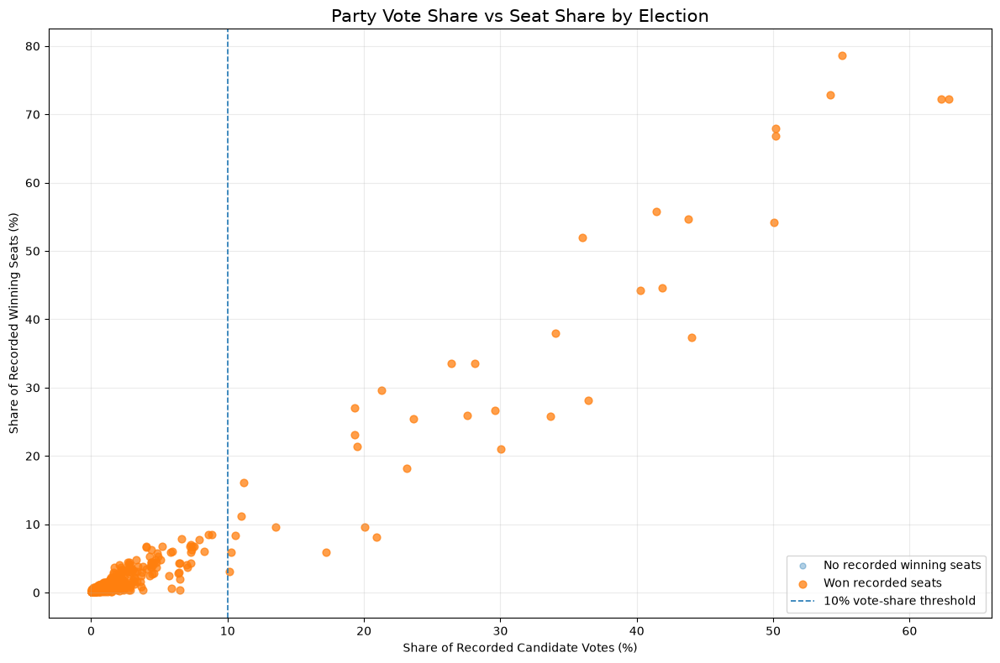

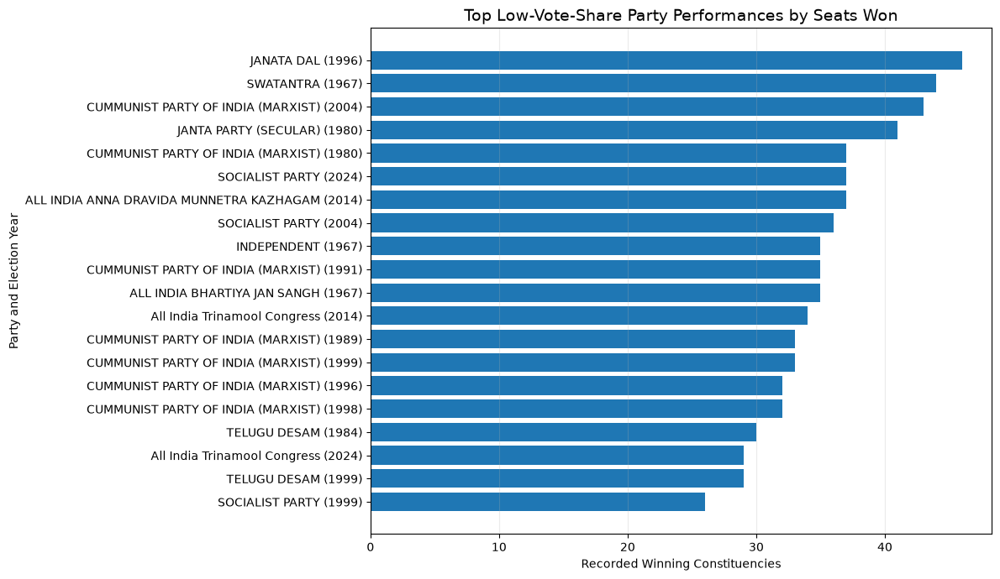

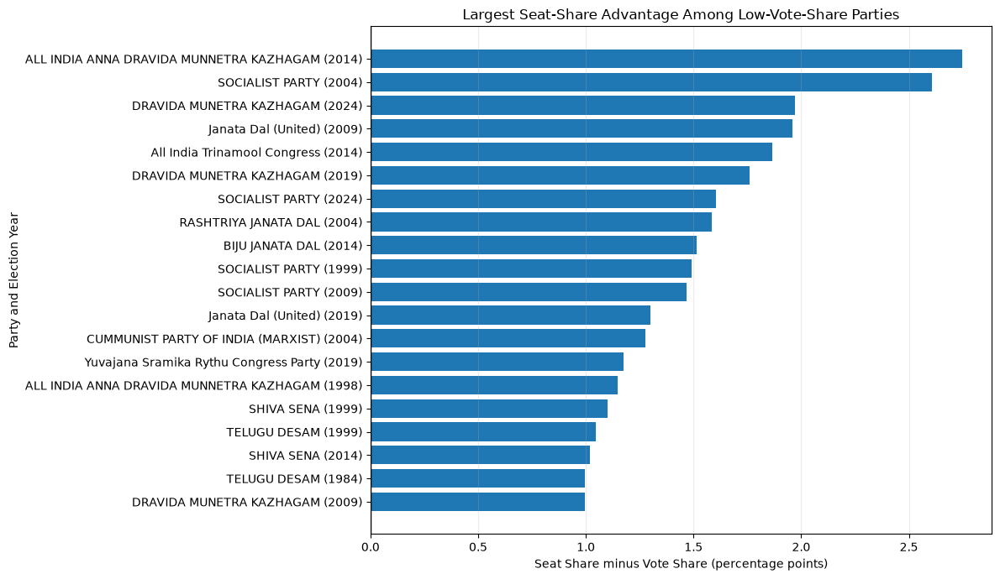


Cases with less than 10% vote share but at least one seat: 470
Cases also holding at least 1% of recorded seats: 147

Charts saved to: outputs/analysis_11_low_vote_share_winners
Analysis 11 completed. No CSV files were created.


In [81]:

# ============================================================
# ANALYSIS 11: PARTIES WINNING SEATS DESPITE LOW VOTE SHARE
# PNG files only — no CSV files
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR_11 = "outputs/analysis_11_low_vote_share_winners"
os.makedirs(OUTPUT_DIR_11, exist_ok=True)

# ------------------------------------------------------------
# 1. VALIDATE AND PREPARE DATA
# ------------------------------------------------------------

required_columns = [
    "YEAR", "PARTY", "CANDIDATE", "RESULT POSITION", "VOTES",
    "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"
]

missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise KeyError(f"Missing required columns: {missing}")

data11 = df[required_columns].copy()

data11["YEAR"] = pd.to_numeric(data11["YEAR"], errors="coerce")
data11["VOTES"] = pd.to_numeric(data11["VOTES"], errors="coerce")
data11["PARTY"] = data11["PARTY"].astype("string").str.strip()
data11["RESULT POSITION"] = (
    data11["RESULT POSITION"].astype("string").str.strip().str.lower()
)

data11 = data11[
    data11["YEAR"].notna()
    & data11["PARTY"].notna()
    & data11["PARTY"].ne("")
].copy()

constituency_keys = [
    "YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"
]

data11 = data11.drop_duplicates(
    subset=constituency_keys + ["CANDIDATE"],
    keep="first"
).copy()

data11["IS_WINNER"] = data11["RESULT POSITION"].str.fullmatch(
    r"winner(?:\s+\d+)?",
    na=False
)

# ------------------------------------------------------------
# 2. PARTY VOTE SHARE PER ELECTION
# ------------------------------------------------------------

party_votes11 = (
    data11.groupby(["YEAR", "PARTY"], as_index=False)
    .agg(PARTY_VOTES=("VOTES", lambda s: s.sum(min_count=1)))
)

year_votes11 = (
    party_votes11.groupby("YEAR")["PARTY_VOTES"]
    .sum(min_count=1)
    .rename("TOTAL_RECORDED_VOTES")
    .reset_index()
)

party_votes11 = party_votes11.merge(
    year_votes11, on="YEAR", how="left"
)

party_votes11["VOTE_SHARE_PERCENT"] = np.where(
    party_votes11["TOTAL_RECORDED_VOTES"] > 0,
    party_votes11["PARTY_VOTES"]
    / party_votes11["TOTAL_RECORDED_VOTES"] * 100,
    np.nan
)

# ------------------------------------------------------------
# 3. RECORDED SEATS PER PARTY
# ------------------------------------------------------------

winners11 = data11[data11["IS_WINNER"]].copy()

# One winning constituency-party combination is counted once.
winner_records11 = winners11.drop_duplicates(
    subset=constituency_keys + ["PARTY"]
)

party_seats11 = (
    winner_records11.groupby(["YEAR", "PARTY"])
    .size()
    .reset_index(name="SEATS_WON")
)

year_seats11 = (
    party_seats11.groupby("YEAR")["SEATS_WON"]
    .sum()
    .rename("TOTAL_RECORDED_SEATS")
    .reset_index()
)

party_seats11 = party_seats11.merge(
    year_seats11, on="YEAR", how="left"
)

party_seats11["SEAT_SHARE_PERCENT"] = np.where(
    party_seats11["TOTAL_RECORDED_SEATS"] > 0,
    party_seats11["SEATS_WON"]
    / party_seats11["TOTAL_RECORDED_SEATS"] * 100,
    np.nan
)

# ------------------------------------------------------------
# 4. COMBINE RESULTS AND FLAG LOW-VOTE-SHARE WINNERS
# ------------------------------------------------------------

party_analysis11 = party_votes11.merge(
    party_seats11[
        ["YEAR", "PARTY", "SEATS_WON", "SEAT_SHARE_PERCENT"]
    ],
    on=["YEAR", "PARTY"],
    how="left"
)

party_analysis11["SEATS_WON"] = (
    party_analysis11["SEATS_WON"].fillna(0)
)

# Adjustable research thresholds:
LOW_VOTE_SHARE_LIMIT = 10.0
MIN_SEATS = 1
MIN_SEAT_SHARE = 1.0

party_analysis11["LOW_VOTE_SHARE_WINNER"] = (
    (party_analysis11["VOTE_SHARE_PERCENT"] < LOW_VOTE_SHARE_LIMIT)
    & (party_analysis11["SEATS_WON"] >= MIN_SEATS)
)

party_analysis11["MEANINGFUL_LOW_SHARE_WINNER"] = (
    party_analysis11["LOW_VOTE_SHARE_WINNER"]
    & (party_analysis11["SEAT_SHARE_PERCENT"] >= MIN_SEAT_SHARE)
)

low_share_winners11 = party_analysis11[
    party_analysis11["LOW_VOTE_SHARE_WINNER"]
].sort_values(
    ["YEAR", "SEATS_WON", "VOTE_SHARE_PERCENT"],
    ascending=[True, False, True]
)

print("=" * 75)
print("ANALYSIS 11: LOW VOTE-SHARE PARTIES THAT WON SEATS")
print("=" * 75)
print(f"Vote-share threshold: below {LOW_VOTE_SHARE_LIMIT}%")
print(f"Minimum recorded seats: {MIN_SEATS}")
print("Number of party-election cases:", len(low_share_winners11))

print("\nTop cases by seats won:")
print(
    low_share_winners11[
        [
            "YEAR", "PARTY", "PARTY_VOTES", "VOTE_SHARE_PERCENT",
            "SEATS_WON", "SEAT_SHARE_PERCENT"
        ]
    ].sort_values(
        ["SEATS_WON", "VOTE_SHARE_PERCENT"],
        ascending=[False, True]
    ).head(25).round(2).to_string(index=False)
)

# ------------------------------------------------------------
# 5. CHART 1: VOTE SHARE VS SEAT SHARE
# ------------------------------------------------------------

plot11 = party_analysis11.dropna(
    subset=["VOTE_SHARE_PERCENT", "SEAT_SHARE_PERCENT"]
).copy()

fig, ax = plt.subplots(figsize=(12, 8))

non_winners11 = plot11[plot11["SEATS_WON"] == 0]
winners_plot11 = plot11[plot11["SEATS_WON"] > 0]

ax.scatter(
    non_winners11["VOTE_SHARE_PERCENT"],
    non_winners11["SEAT_SHARE_PERCENT"],
    alpha=0.35,
    s=25,
    label="No recorded winning seats"
)

ax.scatter(
    winners_plot11["VOTE_SHARE_PERCENT"],
    winners_plot11["SEAT_SHARE_PERCENT"],
    alpha=0.75,
    s=40,
    label="Won recorded seats"
)

ax.axvline(
    LOW_VOTE_SHARE_LIMIT,
    linestyle="--",
    linewidth=1.2,
    label=f"{LOW_VOTE_SHARE_LIMIT:g}% vote-share threshold"
)

ax.set_title("Party Vote Share vs Seat Share by Election", fontsize=15)
ax.set_xlabel("Share of Recorded Candidate Votes (%)")
ax.set_ylabel("Share of Recorded Winning Seats (%)")
ax.grid(True, alpha=0.25)
ax.legend()

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR_11, "11_1_vote_share_vs_seat_share.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. CHART 2: LOW VOTE SHARE, SEATS WON
# ------------------------------------------------------------

top_low11 = low_share_winners11.sort_values(
    ["SEATS_WON", "SEAT_SHARE_PERCENT"],
    ascending=False
).head(20).copy()

if not top_low11.empty:
    top_low11["LABEL"] = (
        top_low11["PARTY"].astype(str)
        + " ("
        + top_low11["YEAR"].astype(int).astype(str)
        + ")"
    )

    top_low11 = top_low11.sort_values("SEATS_WON")

    fig, ax = plt.subplots(figsize=(12, max(7, len(top_low11) * 0.35)))

    ax.barh(
        top_low11["LABEL"],
        top_low11["SEATS_WON"]
    )

    ax.set_title(
        "Top Low-Vote-Share Party Performances by Seats Won",
        fontsize=14
    )
    ax.set_xlabel("Recorded Winning Constituencies")
    ax.set_ylabel("Party and Election Year")
    ax.grid(axis="x", alpha=0.25)

    fig.tight_layout()
    fig.savefig(
        os.path.join(OUTPUT_DIR_11, "11_2_low_vote_share_seat_winners.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 7. CHART 3: SEAT-VOTE ADVANTAGE
# ------------------------------------------------------------

plot11["SEAT_VOTE_GAP"] = (
    plot11["SEAT_SHARE_PERCENT"] - plot11["VOTE_SHARE_PERCENT"]
)

top_gap11 = plot11[
    (plot11["SEATS_WON"] > 0)
    & (plot11["VOTE_SHARE_PERCENT"] < LOW_VOTE_SHARE_LIMIT)
].nlargest(20, "SEAT_VOTE_GAP").copy()

if not top_gap11.empty:
    top_gap11["LABEL"] = (
        top_gap11["PARTY"].astype(str)
        + " ("
        + top_gap11["YEAR"].astype(int).astype(str)
        + ")"
    )

    top_gap11 = top_gap11.sort_values("SEAT_VOTE_GAP")

    fig, ax = plt.subplots(figsize=(12, max(7, len(top_gap11) * 0.35)))

    ax.barh(
        top_gap11["LABEL"],
        top_gap11["SEAT_VOTE_GAP"]
    )
    ax.axvline(0, linewidth=1, color="black")

    ax.set_title("Largest Seat-Share Advantage Among Low-Vote-Share Parties")
    ax.set_xlabel("Seat Share minus Vote Share (percentage points)")
    ax.set_ylabel("Party and Election Year")
    ax.grid(axis="x", alpha=0.25)

    fig.tight_layout()
    fig.savefig(
        os.path.join(OUTPUT_DIR_11, "11_3_seat_vote_advantage.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 8. SUMMARY
# ------------------------------------------------------------

print("\nCases with less than 10% vote share but at least one seat:",
      len(low_share_winners11))

print(
    "Cases also holding at least "
    f"{MIN_SEAT_SHARE:g}% of recorded seats:",
    int(party_analysis11["MEANINGFUL_LOW_SHARE_WINNER"].sum())
)

print("\nCharts saved to:", OUTPUT_DIR_11)
print("Analysis 11 completed. No CSV files were created.")


Repeated candidate records excluded: 3


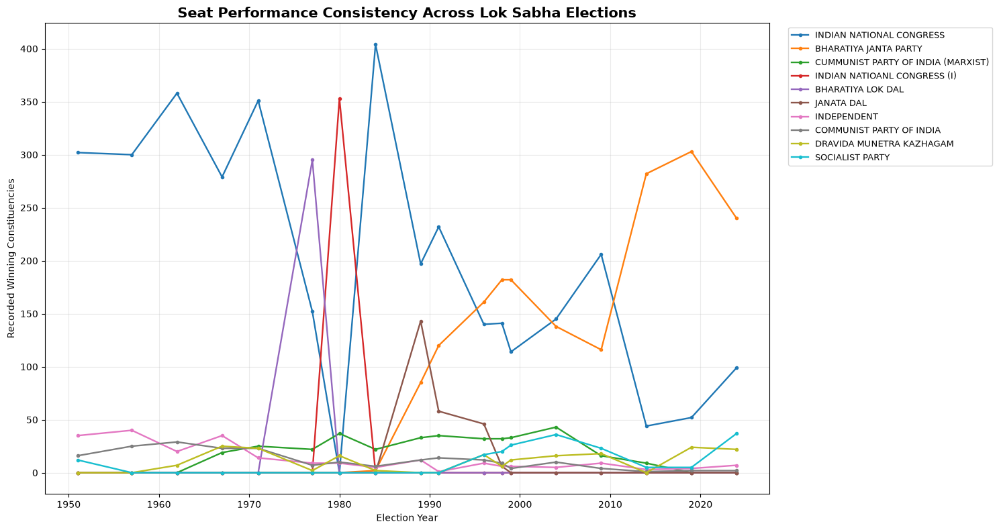

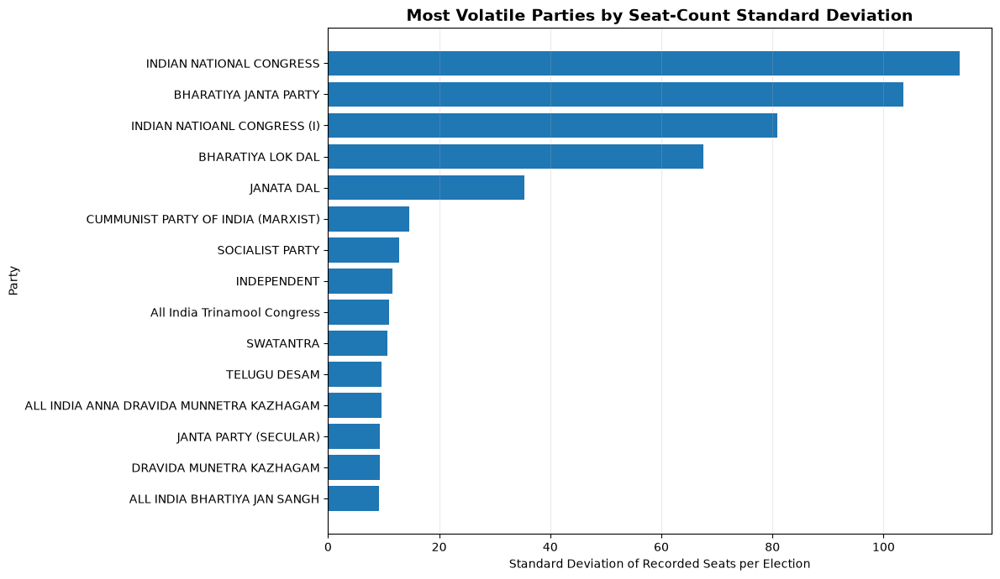

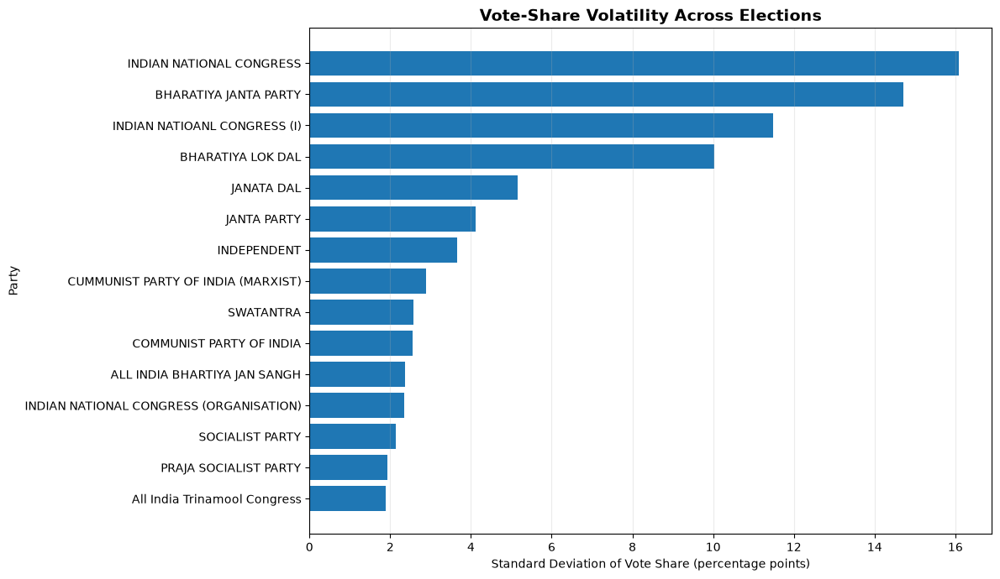

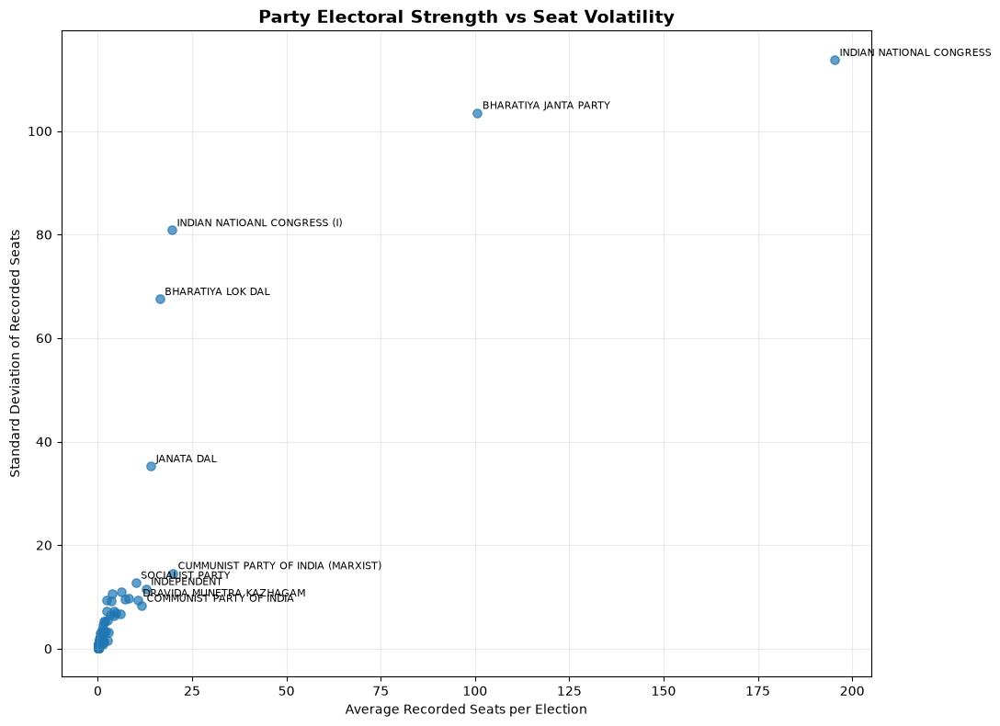


ANALYSIS 12: PARTY PERFORMANCE CONSISTENCY

Top 15 parties by total recorded seats:
                                   PARTY  TOTAL_RECORDED_SEATS  ELECTIONS_WITH_RECORDED_VOTES  ELECTIONS_WITH_SEATS  SEAT_MEAN  SEAT_STD  VOTE_SHARE_MEAN  VOTE_SHARE_STD
                INDIAN NATIONAL CONGRESS                3516.0                           17.0                    17     195.33    113.76            37.55           16.09
                   BHARATIYA JANTA PARTY                1811.0                           11.0                    11     100.61    103.55            15.21           14.72
      CUMMUNIST PARTY OF INDIA (MARXIST)                 358.0                           13.0                    13      19.89     14.61             4.35            2.89
            INDIAN NATIOANL CONGRESS (I)                 353.0                            1.0                     1      19.61     80.86             2.79           11.49
                       BHARATIYA LOK DAL                 295.0   

In [82]:

# ============================================================
# ANALYSIS 12: PARTY PERFORMANCE CONSISTENCY ACROSS ELECTIONS
# PNG files only — no CSV files
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR_12 = "outputs/analysis_12_party_consistency"
os.makedirs(OUTPUT_DIR_12, exist_ok=True)

# ------------------------------------------------------------
# 1. VALIDATE AND PREPARE DATA
# ------------------------------------------------------------

required_columns = [
    "YEAR", "PARTY", "CANDIDATE", "RESULT POSITION", "VOTES",
    "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"
]

missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise KeyError(f"Missing required columns: {missing}")

data12 = df[required_columns].copy()

data12["YEAR"] = pd.to_numeric(data12["YEAR"], errors="coerce")
data12["VOTES"] = pd.to_numeric(data12["VOTES"], errors="coerce")
data12["PARTY"] = data12["PARTY"].astype("string").str.strip()
data12["RESULT POSITION"] = (
    data12["RESULT POSITION"].astype("string").str.strip().str.lower()
)

data12 = data12[
    data12["YEAR"].notna()
    & data12["PARTY"].notna()
    & data12["PARTY"].ne("")
].copy()

constituency_keys = [
    "YEAR", "STATE UT", "CONSTITUENCY NO", "CONSTITUENCY NAME"
]

duplicate_count12 = int(
    data12.duplicated(
        subset=constituency_keys + ["CANDIDATE"],
        keep="first"
    ).sum()
)

data12 = data12.drop_duplicates(
    subset=constituency_keys + ["CANDIDATE"],
    keep="first"
).copy()

data12["IS_WINNER"] = data12["RESULT POSITION"].str.fullmatch(
    r"winner(?:\s+\d+)?",
    na=False
)

print("Repeated candidate records excluded:", duplicate_count12)

# ------------------------------------------------------------
# 2. PARTY VOTE SHARE BY ELECTION
# ------------------------------------------------------------

party_votes12 = (
    data12.groupby(["YEAR", "PARTY"], as_index=False)
    .agg(PARTY_VOTES=("VOTES", lambda s: s.sum(min_count=1)))
)

year_votes12 = (
    party_votes12.groupby("YEAR")["PARTY_VOTES"]
    .sum(min_count=1)
    .rename("TOTAL_RECORDED_VOTES")
    .reset_index()
)

party_votes12 = party_votes12.merge(
    year_votes12, on="YEAR", how="left"
)

party_votes12["VOTE_SHARE_PERCENT"] = np.where(
    party_votes12["TOTAL_RECORDED_VOTES"] > 0,
    party_votes12["PARTY_VOTES"]
    / party_votes12["TOTAL_RECORDED_VOTES"] * 100,
    np.nan
)

# ------------------------------------------------------------
# 3. PARTY SEATS BY ELECTION
# ------------------------------------------------------------

winners12 = data12[data12["IS_WINNER"]].copy()

winner_records12 = winners12.drop_duplicates(
    subset=constituency_keys + ["PARTY"]
)

party_seats12 = (
    winner_records12.groupby(["YEAR", "PARTY"])
    .size()
    .reset_index(name="SEATS_WON")
)

# ------------------------------------------------------------
# 4. CREATE CONSISTENCY METRICS
# ------------------------------------------------------------

all_years12 = sorted(data12["YEAR"].dropna().unique())

# Focus on parties that have at least one recorded winning seat.
# This keeps the summary focused on parties with demonstrated
# electoral representation.
party_list12 = (
    party_seats12.groupby("PARTY")["SEATS_WON"]
    .sum()
    .sort_values(ascending=False)
    .index.tolist()
)

if not party_list12:
    raise ValueError(
        "No winning-party records were found. Check the cleaned "
        "RESULT POSITION column before running this analysis."
    )

# Complete party-by-election panel.
# Missing seat records are treated as zero recorded seats.
seat_panel12 = (
    party_seats12.pivot(
        index="PARTY",
        columns="YEAR",
        values="SEATS_WON"
    )
    .reindex(index=party_list12, columns=all_years12)
    .fillna(0)
)

# Complete vote-share panel.
# Missing party-year entries are set to zero for the trend display.
# This can mean no recorded party result, not necessarily verified
# zero votes; see the interpretation note below.
vote_panel12 = (
    party_votes12.pivot(
        index="PARTY",
        columns="YEAR",
        values="VOTE_SHARE_PERCENT"
    )
    .reindex(index=party_list12, columns=all_years12)
    .fillna(0)
)

presence_panel12 = (
    party_votes12.assign(RECORDED=1)
    .pivot(
        index="PARTY",
        columns="YEAR",
        values="RECORDED"
    )
    .reindex(index=party_list12, columns=all_years12)
    .fillna(0)
)

summary12 = pd.DataFrame(index=party_list12)

summary12["TOTAL_RECORDED_SEATS"] = seat_panel12.sum(axis=1)
summary12["ELECTIONS_WITH_RECORDED_VOTES"] = presence_panel12.sum(axis=1)
summary12["ELECTIONS_WITH_SEATS"] = (seat_panel12 > 0).sum(axis=1)

summary12["SEAT_MEAN"] = seat_panel12.mean(axis=1)
summary12["SEAT_STD"] = seat_panel12.std(axis=1, ddof=0)
summary12["SEAT_MAX"] = seat_panel12.max(axis=1)

summary12["VOTE_SHARE_MEAN"] = vote_panel12.mean(axis=1)
summary12["VOTE_SHARE_STD"] = vote_panel12.std(axis=1, ddof=0)

# Standard deviation is the main measure of variability.
# Lower standard deviation means more stable values, but may also
# describe a party that consistently wins very few seats.
summary12["SEAT_CV_PERCENT"] = np.where(
    summary12["SEAT_MEAN"] > 0,
    summary12["SEAT_STD"] / summary12["SEAT_MEAN"] * 100,
    np.nan
)

summary12["VOTE_SHARE_CV_PERCENT"] = np.where(
    summary12["VOTE_SHARE_MEAN"] > 0,
    summary12["VOTE_SHARE_STD"]
    / summary12["VOTE_SHARE_MEAN"] * 100,
    np.nan
)

summary12 = summary12.reset_index(names="PARTY")

# ------------------------------------------------------------
# 5. CHART 1: SEAT PERFORMANCE OVER TIME
# ------------------------------------------------------------

TOP_N = 10

top_consistent_parties12 = (
    summary12.sort_values(
        "TOTAL_RECORDED_SEATS",
        ascending=False
    )
    .head(TOP_N)["PARTY"]
    .tolist()
)

seat_trend12 = seat_panel12.loc[
    top_consistent_parties12
]

fig, ax = plt.subplots(figsize=(15, 8))

for party in top_consistent_parties12:
    ax.plot(
        seat_trend12.columns,
        seat_trend12.loc[party].values,
        marker="o",
        markersize=3,
        linewidth=1.7,
        label=party
    )

ax.set_title(
    "Seat Performance Consistency Across Lok Sabha Elections",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Election Year")
ax.set_ylabel("Recorded Winning Constituencies")
ax.grid(True, alpha=0.25)
ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR_12, "12_1_party_seat_trends.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. CHART 2: SEAT VOLATILITY
# ------------------------------------------------------------

volatility12 = summary12.sort_values(
    "SEAT_STD",
    ascending=True
).tail(15).copy()

volatility12 = volatility12.sort_values("SEAT_STD")

fig, ax = plt.subplots(
    figsize=(12, max(7, len(volatility12) * 0.4))
)

ax.barh(
    volatility12["PARTY"],
    volatility12["SEAT_STD"]
)

ax.set_title(
    "Most Volatile Parties by Seat-Count Standard Deviation",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Standard Deviation of Recorded Seats per Election")
ax.set_ylabel("Party")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR_12, "12_2_party_seat_volatility.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. CHART 3: VOTE-SHARE CONSISTENCY
# ------------------------------------------------------------

vote_volatility12 = summary12.sort_values(
    "VOTE_SHARE_STD",
    ascending=True
).tail(15).copy()

vote_volatility12 = vote_volatility12.sort_values(
    "VOTE_SHARE_STD"
)

fig, ax = plt.subplots(
    figsize=(12, max(7, len(vote_volatility12) * 0.4))
)

ax.barh(
    vote_volatility12["PARTY"],
    vote_volatility12["VOTE_SHARE_STD"]
)

ax.set_title(
    "Vote-Share Volatility Across Elections",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Standard Deviation of Vote Share (percentage points)")
ax.set_ylabel("Party")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR_12, "12_3_party_vote_share_volatility.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 8. CHART 4: CONSISTENCY VS ELECTORAL STRENGTH
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 8))

valid_summary12 = summary12.dropna(
    subset=["SEAT_MEAN", "SEAT_STD"]
)

ax.scatter(
    valid_summary12["SEAT_MEAN"],
    valid_summary12["SEAT_STD"],
    alpha=0.7,
    s=45
)

# Label the ten parties with the most recorded seats.
for _, row in summary12[
    summary12["PARTY"].isin(top_consistent_parties12)
].iterrows():
    ax.annotate(
        row["PARTY"],
        (row["SEAT_MEAN"], row["SEAT_STD"]),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title(
    "Party Electoral Strength vs Seat Volatility",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Average Recorded Seats per Election")
ax.set_ylabel("Standard Deviation of Recorded Seats")
ax.grid(True, alpha=0.25)

fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT_DIR_12, "12_4_strength_vs_volatility.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. PRINT SUMMARY TABLES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("ANALYSIS 12: PARTY PERFORMANCE CONSISTENCY")
print("=" * 80)

print("\nTop 15 parties by total recorded seats:")
print(
    summary12.sort_values(
        "TOTAL_RECORDED_SEATS",
        ascending=False
    )[
        [
            "PARTY",
            "TOTAL_RECORDED_SEATS",
            "ELECTIONS_WITH_RECORDED_VOTES",
            "ELECTIONS_WITH_SEATS",
            "SEAT_MEAN",
            "SEAT_STD",
            "VOTE_SHARE_MEAN",
            "VOTE_SHARE_STD"
        ]
    ].head(15).round(2).to_string(index=False)
)

print("\nLowest seat volatility among parties with recorded wins:")
print(
    summary12.sort_values(
        "SEAT_STD",
        ascending=True
    )[
        [
            "PARTY",
            "TOTAL_RECORDED_SEATS",
            "ELECTIONS_WITH_SEATS",
            "SEAT_MEAN",
            "SEAT_STD"
        ]
    ].head(15).round(2).to_string(index=False)
)

print("\nHighest seat volatility:")
print(
    summary12.sort_values(
        "SEAT_STD",
        ascending=False
    )[
        [
            "PARTY",
            "TOTAL_RECORDED_SEATS",
            "ELECTIONS_WITH_SEATS",
            "SEAT_MEAN",
            "SEAT_STD"
        ]
    ].head(15).round(2).to_string(index=False)
)

print("\nCharts saved to:", OUTPUT_DIR_12)
print("Analysis 12 completed. No CSV files were created.")
